In [2]:
# STEP 1 — Connect Google Drive and locate the dataset
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import zipfile
import os

MY_DRIVE = Path('/content/drive/MyDrive')
DATASET_NAME = 'capstone-sensor-anomaly-detection-master'

# If your dataset is inside a different Drive folder, paste its full path here.
# Otherwise leave this as None for automatic discovery.
CUSTOM_DATA_PATH = None

if CUSTOM_DATA_PATH:
    source_path = Path(CUSTOM_DATA_PATH)
else:
    folders = [p for p in MY_DRIVE.rglob(DATASET_NAME) if p.is_dir() and (p / 'gauge_data').is_dir()]
    if folders:
        source_path = folders[0]
    else:
        archives = [p for p in MY_DRIVE.rglob('*.zip') if DATASET_NAME in p.name]
        if not archives:
            raise FileNotFoundError('Dataset folder or ZIP not found in MyDrive. Set CUSTOM_DATA_PATH to its full Drive path.')
        source_path = archives[0]

# Read an extracted folder directly from Drive. If a ZIP is found, extract to Colab's temporary workspace.
if source_path.is_file() and source_path.suffix.lower() == '.zip':
    extract_root = Path('/content/capstone_dataset')
    extract_root.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(source_path) as archive:
        archive.extractall(extract_root)
    matches = [p for p in extract_root.rglob('gauge_data') if p.is_dir()]
    if not matches:
        raise FileNotFoundError('ZIP does not contain a gauge_data folder')
    DATA_PATH = matches[0].parent
    DRIVE_PROJECT_PATH = source_path.parent / 'Capstone_Project'
else:
    DATA_PATH = source_path
    DRIVE_PROJECT_PATH = DATA_PATH

project_path = str(DATA_PATH)
gauge_path = str(DATA_PATH / 'gauge_data')
OUTPUT_PATH = DRIVE_PROJECT_PATH / 'capstone_outputs'
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
clean_path = str(OUTPUT_PATH / 'cleaned_sensor_data')
Path(clean_path).mkdir(parents=True, exist_ok=True)

print('Dataset found at:', DATA_PATH)
print('Results will save to:', OUTPUT_PATH)
print('Gauge folder found:', Path(gauge_path).is_dir())

Mounted at /content/drive
Dataset found at: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master
Results will save to: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/capstone_outputs
Gauge folder found: True


In [3]:
# STEP 2 — Inspect the dataset folder
print('Dataset contents:', os.listdir(project_path)[:20])

Dataset contents: ['.gitignore', 'README.md', 'station_inventory.csv', 'gauge_data', 'capstone_outputs']


In [4]:
# STEP 3 — Confirm the sensor folders exist
print('Sensor folders:', os.listdir(gauge_path))

Sensor folders: ['rainfall', 'river_discharge', 'river_water_level']


In [5]:
# STEP 4 — Count the sensor CSV files
from pathlib import Path
for sensor in ['rainfall', 'river_discharge', 'river_water_level']:
    print(sensor, len(list((Path(gauge_path) / sensor).glob('*.csv'))))

rainfall 113
river_discharge 53
river_water_level 55


In [6]:
# STEP 5 — Locate station inventory
inventory_file = DATA_PATH / 'station_inventory.csv'
print('Station inventory:', inventory_file, 'Exists:', inventory_file.exists())

Station inventory: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/station_inventory.csv Exists: True


In [7]:
# STEP 6 — Preview a folder
print('First rainfall CSVs:', [p.name for p in sorted((Path(gauge_path) / 'rainfall').glob('*.csv'))[:5]])

First rainfall CSVs: ['64068001.csv', '642615.csv', '642701.csv', '643510.csv', '643514.csv']


In [8]:
# STEP 7 — Count all station files
import glob
file_counts = {sensor: len(glob.glob(str(Path(gauge_path) / sensor / '*.csv'))) for sensor in ['rainfall','river_discharge','river_water_level']}
print(file_counts)
print('Total:', sum(file_counts.values()))

{'rainfall': 113, 'river_discharge': 53, 'river_water_level': 55}
Total: 221


In [9]:
import pandas as pd
import os
import glob

for folder in ["rainfall", "river_discharge", "river_water_level"]:

    folder_path = os.path.join(gauge_path, folder)
    csv_files = glob.glob(folder_path + "/*.csv")

    print("\n" + "="*80)
    print("DATASET:", folder)
    print("="*80)

    for file in csv_files[:3]:  # first 3 files only

        print("\nFILE:", os.path.basename(file))

        df = pd.read_csv(file)

        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())

        display(df.head(5))


DATASET: rainfall

FILE: 64068001.csv
Shape: (64817, 1)
Columns: ['# Auckland | station: 64068001 (Tomarata at Briens Farm) | dataset: Rainfall.Continuous@64068001 | calc: Aggregate | units: mm | source: https://environmentauckland.org.nz']


,,# Auckland | station: 64068001 (Tomarata at Briens Farm) | dataset: Rainfall.Continuous@64068001 | calc: Aggregate | units: mm | source: https://environmentauckland.org.nz
interval_start,interval_end,value
2018-08-10 16:00:00,NaN,0.0
2018-08-10 17:00:00,NaN,0.0
2018-08-10 18:00:00,NaN,0.0
2018-08-10 19:00:00,NaN,0.0



FILE: 642615.csv
Shape: (18947, 1)
Columns: ['# Auckland | station: 642615 (Pakiri Block Road) | dataset: Rainfall.Continuous@642615 | calc: Aggregate | units: mm | source: https://environmentauckland.org.nz']


,,# Auckland | station: 642615 (Pakiri Block Road) | dataset: Rainfall.Continuous@642615 | calc: Aggregate | units: mm | source: https://environmentauckland.org.nz
interval_start,interval_end,value
2015-01-01 01:00:00,NaN,0.042083333333333334
2015-01-01 02:00:00,NaN,0.042083333333333334
2015-01-01 03:00:00,NaN,0.042083333333333334
2015-01-01 04:00:00,NaN,0.042083333333333334



FILE: 642701.csv
Shape: (94913, 1)
Columns: ['# Auckland | station: 642701 (Leigh Rainfall) | dataset: Rainfall.Continuous@642701 | calc: Aggregate | units: mm | source: https://environmentauckland.org.nz']


...

,#Data Set Export - River Water Level.Continuous@108122,Unnamed: 1,Unnamed: 2
0,Start of Interval (UTC+12:00),End of Interval (UTC+12:00),Value (m)
1,2015-01-01 00:00:00,2015-01-01 01:00:00,0.043
2,2015-01-01 01:00:00,2015-01-01 02:00:00,0.028
3,2015-01-01 02:00:00,2015-01-01 03:00:00,0.021
4,2015-01-01 03:00:00,2015-01-01 04:00:00,0.009



FILE: 43602.csv
Shape: (101041, 3)
Columns: ['#Data Set Export - River Water Level.Continuous@43602', 'Unnamed: 1', 'Unnamed: 2']


,#Data Set Export - River Water Level.Continuous@43602,Unnamed: 1,Unnamed: 2
0,Start of Interval (UTC+12:00),End of Interval (UTC+12:00),Value (m)
1,2015-01-01 00:00:00,2015-01-01 01:00:00,NaN
2,2015-01-01 01:00:00,2015-01-01 02:00:00,NaN
3,2015-01-01 02:00:00,2015-01-01 03:00:00,NaN
4,2015-01-01 03:00:00,2015-01-01 04:00:00,NaN



FILE: 43803.csv
Shape: (101041, 3)
Columns: ['#Data Set Export - River Water Level.Continuous@43803', 'Unnamed: 1', 'Unnamed: 2']


,#Data Set Export - River Water Level.Continuous@43803,Unnamed: 1,Unnamed: 2
0,Start of Interval (UTC+12:00),End of Interval (UTC+12:00),Value (m)
1,2015-01-01 00:00:00,2015-01-01 01:00:00,NaN
2,2015-01-01 01:00:00,2015-01-01 02:00:00,NaN
3,2015-01-01 02:00:00,2015-01-01 03:00:00,NaN
4,2015-01-01 03:00:00,2015-01-01 04:00:00,NaN


In [10]:
# STEP 9 — Set the shared output folder on Google Drive
from pathlib import Path
Path(clean_path).mkdir(parents=True, exist_ok=True)
print('Processed files will be saved under:', OUTPUT_PATH)

Processed files will be saved under: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/capstone_outputs


In [11]:
rainfall_file = (
    f"{gauge_path}/rainfall/647737.csv"
)

discharge_file = (
    f"{gauge_path}/river_discharge/7811.csv"
)

water_file = (
    f"{gauge_path}/river_water_level/7811.csv"
)

for name, file in [
    ("RAINFALL", rainfall_file),
    ("DISCHARGE", discharge_file),
    ("WATER LEVEL", water_file)
]:
    print("\n" + "="*80)
    print(name)
    print("="*80)

    with open(file, "r", encoding="utf-8") as f:
        for i in range(8):
            print(repr(f.readline()))


RAINFALL
'# Auckland | station: 647737 (School @ Mairangi Bay NSCC02) | dataset: Rainfall.Continuous@647737 | calc: Aggregate | units: mm | source: https://environmentauckland.org.nz\n'
'interval_start,interval_end,value\n'
'2015-01-01 01:00:00,,0.910948905109489\n'
'2015-01-01 02:00:00,,3.4344460278264273\n'
'2015-01-01 03:00:00,,1.4146050670640835\n'
'2015-01-01 04:00:00,,0.0\n'
'2015-01-01 05:00:00,,0.0\n'
'2015-01-01 06:00:00,,0.0\n'

DISCHARGE
'#Data Set Export - River Discharge.Continuous@7811,,\n'
'Start of Interval (UTC+12:00),End of Interval (UTC+12:00),Value (m^3/s)\n'
'2015-01-01 00:00:00,2015-01-01 01:00:00,0.042\n'
'2015-01-01 01:00:00,2015-01-01 02:00:00,0.342\n'
'2015-01-01 02:00:00,2015-01-01 03:00:00,1.147\n'
'2015-01-01 03:00:00,2015-01-01 04:00:00,1.291\n'
'2015-01-01 04:00:00,2015-01-01 05:00:00,1.198\n'
'2015-01-01 05:00:00,2015-01-01 06:00:00,0.892\n'

WATER LEVEL
'#Data Set Export - River Water Level.Continuous@7811,,\n'
'Start of Interval (UTC+12:00),End of Int

In [12]:
import pandas as pd
import os
import glob
import re

# project_path, gauge_path and clean_path were set in Step 1.
os.makedirs(clean_path, exist_ok=True)


def extract_station_id(filename):
    """Extract station ID from filename."""
    return os.path.splitext(os.path.basename(filename))[0]


def clean_rainfall(file):
    """Clean one rainfall CSV."""

    station_id = extract_station_id(file)

    # Skip metadata row and use the actual CSV header
    df = pd.read_csv(file, skiprows=1)

    # Standardise column names
    df.columns = ["timestamp", "interval_end", "value"]

    # Convert timestamp
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        errors="coerce"
    )

    # Convert sensor value to numeric
    df["value"] = pd.to_numeric(
        df["value"],
        errors="coerce"
    )

    # Add metadata
    df["station_id"] = station_id
    df["sensor_type"] = "rainfall"
    df["unit"] = "mm"

    # Keep useful columns
    df = df[
        ["station_id", "timestamp", "sensor_type", "value", "unit"]
    ]

    return df


def clean_discharge(file):
    """Clean one river discharge CSV."""

    station_id = extract_station_id(file)

    # Skip metadata row
    df = pd.read_csv(file, skiprows=1)

    # Standardise columns
    df.columns = ["timestamp_start", "timestamp_end", "value"]

    # Convert timestamps
    df["timestamp_start"] = pd.to_datetime(
        df["timestamp_start"],
        errors="coerce"
    )

    df["timestamp_end"] = pd.to_datetime(
        df["timestamp_end"],
        errors="coerce"
    )

    # Convert value
    df["value"] = pd.to_numeric(
        df["value"],
        errors="coerce"
    )

    # Add metadata
    df["station_id"] = station_id
    df["sensor_type"] = "river_discharge"
    df["unit"] = "m3/s"

    # Use start of interval as main timestamp
    df = df.rename(
        columns={"timestamp_start": "timestamp"}
    )

    df = df[
        ["station_id", "timestamp", "sensor_type", "value", "unit"]
    ]

    return df


def clean_water_level(file):
    """Clean one river water-level CSV."""

    station_id = extract_station_id(file)

    # Skip metadata row
    df = pd.read_csv(file, skiprows=1)

    # Standardise columns
    df.columns = ["timestamp_start", "timestamp_end", "value"]

    # Convert timestamps
    df["timestamp_start"] = pd.to_datetime(
        df["timestamp_start"],
        errors="coerce"
    )

    df["timestamp_end"] = pd.to_datetime(
        df["timestamp_end"],
        errors="coerce"
    )

    # Convert value
    df["value"] = pd.to_numeric(
        df["value"],
        errors="coerce"
    )

    # Add metadata
    df["station_id"] = station_id
    df["sensor_type"] = "river_water_level"
    df["unit"] = "m"

    # Use start of interval
    df = df.rename(
        columns={"timestamp_start": "timestamp"}
    )

    df = df[
        ["station_id", "timestamp", "sensor_type", "value", "unit"]
    ]

    return df

In [13]:
rainfall_test = clean_rainfall(
    f"{gauge_path}/rainfall/647737.csv"
)

discharge_test = clean_discharge(
    f"{gauge_path}/river_discharge/7811.csv"
)

water_test = clean_water_level(
    f"{gauge_path}/river_water_level/7811.csv"
)

In [14]:
print("RAINFALL")
display(rainfall_test.head())

print("\nDISCHARGE")
display(discharge_test.head())

print("\nWATER LEVEL")
display(water_test.head())

RAINFALL


,station_id,timestamp,sensor_type,value,unit
0,647737,2015-01-01 01:00:00,rainfall,0.910949,mm
1,647737,2015-01-01 02:00:00,rainfall,3.434446,mm
2,647737,2015-01-01 03:00:00,rainfall,1.414605,mm
3,647737,2015-01-01 04:00:00,rainfall,0.000000,mm
4,647737,2015-01-01 05:00:00,rainfall,0.000000,mm



DISCHARGE


,station_id,timestamp,sensor_type,value,unit
0,7811,2015-01-01 00:00:00,river_discharge,0.042,m3/s
1,7811,2015-01-01 01:00:00,river_discharge,0.342,m3/s
2,7811,2015-01-01 02:00:00,river_discharge,1.147,m3/s
3,7811,2015-01-01 03:00:00,river_discharge,1.291,m3/s
4,7811,2015-01-01 04:00:00,river_discharge,1.198,m3/s



WATER LEVEL


,station_id,timestamp,sensor_type,value,unit
0,7811,2015-01-01 00:00:00,river_water_level,0.196,m
1,7811,2015-01-01 01:00:00,river_water_level,0.456,m
2,7811,2015-01-01 02:00:00,river_water_level,0.666,m
3,7811,2015-01-01 03:00:00,river_water_level,0.688,m
4,7811,2015-01-01 04:00:00,river_water_level,0.674,m


## Step 13 — Combine every station file

Apply the three cleaning functions already created in Step 10. The `master_df` contains the same standardized columns for all 221 CSV files. This needs Colab RAM, so save an intermediate CSV immediately afterward. We record any failed files instead of silently skipping them.


In [15]:
import gc
from pathlib import Path

all_data = []
failed_files = []

for sensor_type in ["rainfall", "river_discharge", "river_water_level"]:
    folder = Path(gauge_path) / sensor_type
    csv_files = sorted(folder.glob("*.csv"))
    print(f"Processing {sensor_type}: {len(csv_files)} files")

    for file in csv_files:
        try:
            if sensor_type == "rainfall":
                df = clean_rainfall(str(file))
            elif sensor_type == "river_discharge":
                df = clean_discharge(str(file))
            else:
                df = clean_water_level(str(file))
            all_data.append(df)
        except Exception as error:
            failed_files.append({"file": str(file), "error": str(error)})

master_df = pd.concat(all_data, ignore_index=True)
del all_data
gc.collect()

print("Combined rows:", len(master_df))
print("Files failed:", len(failed_files))
display(master_df.head())
display(pd.DataFrame(failed_files))


Processing rainfall: 113 files
Processing river_discharge: 53 files
Processing river_water_level: 55 files
Combined rows: 18915131
Files failed: 0


,station_id,timestamp,sensor_type,value,unit
0,64068001,2018-08-10 16:00:00,rainfall,0.0,mm
1,64068001,2018-08-10 17:00:00,rainfall,0.0,mm
2,64068001,2018-08-10 18:00:00,rainfall,0.0,mm
3,64068001,2018-08-10 19:00:00,rainfall,0.0,mm
4,64068001,2018-08-10 20:00:00,rainfall,0.0,mm


""


## Step 14 — Check the combined dataset

Count observations, station/parameter combinations, date coverage, and data types before any cleaning. A station can appear in both river datasets.


In [16]:
print("Rows:", len(master_df))
print("Unique station IDs:", master_df["station_id"].nunique())
print("Station/parameter combinations:", master_df[["station_id", "sensor_type"]].drop_duplicates().shape[0])
print("Earliest:", master_df["timestamp"].min())
print("Latest:", master_df["timestamp"].max())
print("\nData types:")
print(master_df.dtypes)
display(master_df.groupby("sensor_type").agg(
    records=("value", "size"),
    stations=("station_id", "nunique"),
    first_date=("timestamp", "min"),
    last_date=("timestamp", "max")
).reset_index())


Rows: 18915131
Unique station IDs: 168
Station/parameter combinations: 221
Earliest: 2015-01-01 00:00:00
Latest: 2026-07-31 23:00:00

Data types:
station_id             object
timestamp      datetime64[ns]
sensor_type            object
value                 float64
unit                   object
dtype: object


,sensor_type,records,stations,first_date,last_date
0,rainfall,8002331,113,2015-01-01 01:00:00,2026-01-01 00:00:00
1,river_discharge,5355120,53,2015-01-01 00:00:00,2026-07-11 23:00:00
2,river_water_level,5557680,55,2015-01-01 00:00:00,2026-07-31 23:00:00


## Step 15 — Investigate missing and zero readings

A zero is a recorded measurement, not a missing reading. Rainfall can legitimately be zero during dry hours. Negative water levels may be valid relative to a gauge datum.


In [17]:
master_df["is_missing"] = master_df["value"].isna()
master_df["is_zero"] = master_df["value"].eq(0)
master_df["is_negative"] = master_df["value"].lt(0)

quality_summary = master_df.groupby("sensor_type").agg(
    total_rows=("value", "size"),
    missing=("is_missing", "sum"),
    zeros=("is_zero", "sum"),
    negative=("is_negative", "sum")
).reset_index()
quality_summary["missing_pct"] = (100 * quality_summary["missing"] / quality_summary["total_rows"]).round(2)
quality_summary["zero_pct_of_valid"] = (100 * quality_summary["zeros"] / (quality_summary["total_rows"] - quality_summary["missing"])).round(2)
display(quality_summary)


,sensor_type,total_rows,missing,zeros,negative,missing_pct,zero_pct_of_valid
0,rainfall,8002331,291808,6797987,2,3.65,88.17
1,river_discharge,5355120,1410900,40911,0,26.35,1.04
2,river_water_level,5557680,1538974,1479,26783,27.69,0.04


## Step 16 — Check duplicate timestamps and conflicting measurements

Group by station, sensor type, and timestamp. Mark duplicates before deleting anything. A duplicate with one blank and one numeric value is different from two identical records.


In [18]:
keys = ["station_id", "sensor_type", "timestamp"]
master_df["duplicate_timestamp"] = master_df.duplicated(keys, keep=False)
master_df["exact_duplicate"] = master_df.duplicated(
    ["station_id", "sensor_type", "timestamp", "value"], keep=False
)

duplicate_rows = master_df.loc[master_df["duplicate_timestamp"]].copy()
print("Rows with repeated timestamps:", len(duplicate_rows))
print("Rows in exact duplicate groups:", int(master_df["exact_duplicate"].sum()))

if not duplicate_rows.empty:
    duplicate_groups = duplicate_rows.groupby(keys, dropna=False)["value"].agg(
        rows="size", distinct_nonmissing="nunique", missing=lambda x: x.isna().sum()
    ).reset_index()
    duplicate_groups["needs_review"] = (
        (duplicate_groups["distinct_nonmissing"] > 1) |
        ((duplicate_groups["missing"] > 0) & (duplicate_groups["missing"] < duplicate_groups["rows"]))
    )
    display(duplicate_groups.head(10))
else:
    duplicate_groups = pd.DataFrame(columns=keys + ["rows", "distinct_nonmissing", "missing", "needs_review"])


Rows with repeated timestamps: 1648
Rows in exact duplicate groups: 206


,station_id,sensor_type,timestamp,rows,distinct_nonmissing,missing,needs_review
0,64068001,rainfall,2019-01-01,2,1,1,True
1,64068001,rainfall,2020-01-01,2,1,1,True
2,64068001,rainfall,2021-01-01,2,1,1,True
3,64068001,rainfall,2022-01-01,2,1,1,True
4,64068001,rainfall,2023-01-01,2,1,1,True
5,64068001,rainfall,2024-01-01,2,1,1,True
6,64068001,rainfall,2025-01-01,2,1,1,True
7,642615,rainfall,2016-01-01,2,1,1,True
8,642615,rainfall,2017-01-01,2,1,1,True
9,642701,rainfall,2016-01-01,2,1,1,True


## Step 17 — Create charts

Visualise missing percentages and zeros separately; they tell different stories.


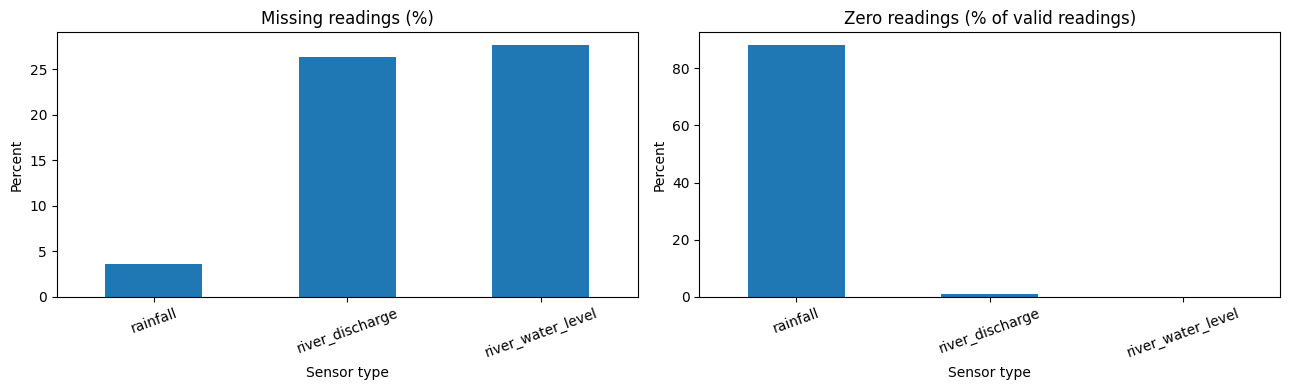

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
quality_summary.plot.bar(x="sensor_type", y="missing_pct", ax=axes[0], legend=False,
                         title="Missing readings (%)")
quality_summary.plot.bar(x="sensor_type", y="zero_pct_of_valid", ax=axes[1], legend=False,
                         title="Zero readings (% of valid readings)")
for ax in axes:
    ax.set_xlabel("Sensor type")
    ax.set_ylabel("Percent")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


## Step 18 — Save outputs to Google Drive

The Google Drive location was configured in **Step 1**. The summary and duplicate-audit CSVs below are saved inside `capstone_outputs` next to your extracted dataset folder. If your source is a ZIP, results are saved under `Capstone_Project/capstone_outputs` beside the ZIP. The raw sensor files are unchanged. Exporting the full master dataset is optional because it is very large.

In [20]:
# STEP 18 — Save analysis outputs to the same Google Drive project folder
# The path was configured in Step 1; do not mount Drive again.
output_path = OUTPUT_PATH
output_path.mkdir(parents=True, exist_ok=True)

quality_summary.to_csv(output_path / 'quality_summary.csv', index=False)
duplicate_rows.to_csv(output_path / 'duplicate_timestamp_rows.csv', index=False)
duplicate_groups.to_csv(output_path / 'duplicate_timestamp_groups.csv', index=False)
pd.DataFrame(failed_files, columns=['file', 'error']).to_csv(output_path / 'failed_files.csv', index=False)

# Optional: exports all ~19 million observations; this is a very large CSV.
# master_df.to_csv(output_path / 'master_sensor_data.csv', index=False)

print('Files saved to:', output_path)
print('Next: long missing/zero periods and station-specific anomaly thresholds.')

Files saved to: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/capstone_outputs
Next: long missing/zero periods and station-specific anomaly thresholds.


In [21]:
# STEP 19: Consecutive missing and zero readings

import pandas as pd
import numpy as np

episodes = []

for (station, sensor), group in master_df.groupby(
    ["station_id", "sensor_type"], sort=False
):

    group = group.sort_values("timestamp").copy()

    # Analyse missing and zero values separately
    for issue, condition in [
        ("Missing", group["value"].isna()),
        ("Zero", group["value"].eq(0))
    ]:

        # A new episode starts when the condition changes
        # or the timestamp is not exactly one hour later
        time_gap = group["timestamp"].diff().ne(
            pd.Timedelta(hours=1)
        )

        episode_id = (
            condition.ne(condition.shift()) | time_gap
        ).cumsum()

        selected = group.loc[condition, ["timestamp"]].copy()
        selected["episode_id"] = episode_id[condition].to_numpy()

        if selected.empty:
            continue

        result = selected.groupby("episode_id").agg(
            start_date=("timestamp", "min"),
            end_date=("timestamp", "max"),
            duration_hours=("timestamp", "size")
        ).reset_index(drop=True)

        result["station_id"] = station
        result["sensor_type"] = sensor
        result["issue_type"] = issue

        episodes.append(result)

episode_df = pd.concat(episodes, ignore_index=True)

episode_df = episode_df[
    [
        "station_id", "sensor_type", "issue_type",
        "start_date", "end_date", "duration_hours"
    ]
]

display(
    episode_df.sort_values(
        "duration_hours", ascending=False
    ).head(20)
)

,station_id,sensor_type,issue_type,start_date,end_date,duration_hours
350028,7502,river_water_level,Missing,2015-01-01 00:00:00,2026-07-11 23:00:00,101040
346828,7502,river_discharge,Missing,2015-01-01 00:00:00,2026-07-11 23:00:00,101040
348900,43811,river_water_level,Missing,2015-02-27 11:00:00,2026-07-11 23:00:00,99661
345607,43811,river_discharge,Missing,2015-02-27 11:00:00,2026-07-11 23:00:00,99661
345653,45315,river_discharge,Missing,2015-04-08 15:00:00,2026-07-11 23:00:00,98697
348794,108122,river_water_level,Missing,2015-11-06 10:00:00,2026-07-11 23:00:00,93614
345472,108122,river_discharge,Missing,2015-11-06 10:00:00,2026-07-11 23:00:00,93614
347858,7609,river_discharge,Missing,2015-11-24 12:00:00,2026-07-11 23:00:00,93180
351055,7609,river_water_level,Missing,2015-11-24 12:00:00,2026-07-11 23:00:00,93180
349025,45702,river_water_level,Missing,2016-01-12 15:00:00,2026-07-11 23:00:00,92001


In [22]:
# Longest missing and zero periods per station

episode_summary = (
    episode_df.groupby(
        ["station_id", "sensor_type", "issue_type"]
    )
    .agg(
        total_episodes=("duration_hours", "size"),
        longest_hours=("duration_hours", "max"),
        average_hours=("duration_hours", "mean")
    )
    .reset_index()
)

episode_summary["longest_days"] = (
    episode_summary["longest_hours"] / 24
).round(1)

display(
    episode_summary.sort_values(
        "longest_hours", ascending=False
    ).head(20)
)

# Save to Google Drive
episode_df.to_csv(
    OUTPUT_PATH / "missing_zero_episodes.csv",
    index=False
)

episode_summary.to_csv(
    OUTPUT_PATH / "episode_summary.csv",
    index=False
)

print("Missing and zero investigation files saved.")

,station_id,sensor_type,issue_type,total_episodes,longest_hours,average_hours,longest_days
275,7502,river_discharge,Missing,1,101040,101040.000000,4210.0
276,7502,river_water_level,Missing,1,101040,101040.000000,4210.0
12,43811,river_discharge,Missing,1,99661,99661.000000,4152.5
13,43811,river_water_level,Missing,1,99661,99661.000000,4152.5
19,45315,river_discharge,Missing,1,98697,98697.000000,4112.4
0,108122,river_discharge,Missing,23,93614,4074.478261,3900.6
2,108122,river_water_level,Missing,23,93614,4074.478261,3900.6
307,7609,river_discharge,Missing,1,93180,93180.000000,3882.5
308,7609,river_water_level,Missing,1,93180,93180.000000,3882.5
30,45702,river_discharge,Missing,3,92001,30710.000000,3833.4


Missing and zero investigation files saved.


Step 20 — Calculate station-specific anomaly thresholds
Next, we'll find unusually high readings.
For rainfall, we will use positive rainfall observations to calculate the 99.9th percentile. For discharge and water level, we will calculate the percentile for each individual station, using its available valid readings.

In [23]:
# STEP 20: Station-specific thresholds

thresholds = []

for (station, sensor), group in master_df.groupby(
    ["station_id", "sensor_type"], sort=False
):

    values = group["value"].dropna()

    if sensor == "rainfall":
        values = values[values > 0]

    # Require enough readings to estimate a threshold
    if len(values) < 1000:
        limit = np.nan
        status = "Insufficient data"
    else:
        limit = values.quantile(0.999)
        status = "Threshold calculated"

    thresholds.append({
        "station_id": station,
        "sensor_type": sensor,
        "valid_for_threshold": len(values),
        "threshold_999": limit,
        "status": status
    })

threshold_df = pd.DataFrame(thresholds)

display(threshold_df.head(20))

,station_id,sensor_type,valid_for_threshold,threshold_999,status
0,64068001,rainfall,6247,27.598987,Threshold calculated
1,642615,rainfall,7033,4.208333,Threshold calculated
2,642701,rainfall,9920,25.602708,Threshold calculated
3,643510,rainfall,10112,26.581405,Threshold calculated
4,643514,rainfall,11342,24.882220,Threshold calculated
5,643713,rainfall,9582,26.397595,Threshold calculated
6,643713C,rainfall,2257,23.448330,Threshold calculated
7,643715,rainfall,7309,31.275335,Threshold calculated
8,644211,rainfall,8048,20.182711,Threshold calculated
9,644410,rainfall,16832,4.895833,Threshold calculated


In [24]:
threshold_df.to_csv(
    OUTPUT_PATH / "station_thresholds.csv",
    index=False
)

print("Station thresholds saved.")

Station thresholds saved.


In [25]:
# STEP 21: Apply station-specific thresholds

# Add threshold to each observation
master_df = master_df.merge(
    threshold_df[
        ["station_id", "sensor_type", "threshold_999"]
    ],
    on=["station_id", "sensor_type"],
    how="left"
)

# Identify readings above the threshold
master_df["high_value_flag"] = (
    master_df["value"] > master_df["threshold_999"]
)

# Count high-value candidates by station
high_value_summary = (
    master_df.groupby(["station_id", "sensor_type"])
    ["high_value_flag"]
    .sum()
    .reset_index(name="high_value_count")
)

display(
    high_value_summary.sort_values(
        "high_value_count", ascending=False
    ).head(20)
)

,station_id,sensor_type,high_value_count
212,8208,river_water_level,102
4,43803,river_discharge,101
12,45311,river_discharge,101
27,45705,river_water_level,101
2,43602,river_discharge,101
26,45705,river_discharge,101
162,7514,river_discharge,101
170,7604,river_discharge,101
204,8104,river_water_level,101
193,7911,river_discharge,101


In [26]:
#saving the file
high_value_summary.to_csv(
    OUTPUT_PATH / "high_value_anomaly_summary.csv",
    index=False
)

print("High-value summary saved.")

High-value summary saved.


In [27]:
# STEP 22A: Extract high-value anomaly candidates

high_value_readings = master_df.loc[
    master_df["high_value_flag"],
    [
        "station_id",
        "sensor_type",
        "timestamp",
        "value",
        "unit",
        "threshold_999"
    ]
].copy()

# Calculate how far above the threshold each reading is
high_value_readings["excess_above_threshold"] = (
    high_value_readings["value"]
    - high_value_readings["threshold_999"]
)

# Add a preliminary classification
high_value_readings["status"] = "Suspicious - Review"

print("Total flagged readings:", len(high_value_readings))

display(
    high_value_readings.sort_values(
        "excess_above_threshold",
        ascending=False
    ).head(20)
)

Total flagged readings: 8913


,station_id,sensor_type,timestamp,value,unit,threshold_999,excess_above_threshold,status
16442539,7607,river_water_level,2021-02-23 08:00:00,7400.975,m,1.027488,7399.947512,Suspicious - Review
14054376,45311,river_water_level,2025-05-06 13:00:00,3098.000,m,7.852108,3090.147892,Suspicious - Review
14054375,45311,river_water_level,2025-05-06 12:00:00,3098.000,m,7.852108,3090.147892,Suspicious - Review
14054377,45311,river_water_level,2025-05-06 14:00:00,3092.000,m,7.852108,3084.147892,Suspicious - Review
14054378,45311,river_water_level,2025-05-06 15:00:00,3087.000,m,7.852108,3079.147892,Suspicious - Review
14054379,45311,river_water_level,2025-05-06 16:00:00,3082.000,m,7.852108,3074.147892,Suspicious - Review
14054380,45311,river_water_level,2025-05-06 17:00:00,3077.000,m,7.852108,3069.147892,Suspicious - Review
14054412,45311,river_water_level,2025-05-08 01:00:00,3072.000,m,7.852108,3064.147892,Suspicious - Review
14054405,45311,river_water_level,2025-05-07 18:00:00,3072.000,m,7.852108,3064.147892,Suspicious - Review
14054416,45311,river_water_level,2025-05-08 05:00:00,3072.000,m,7.852108,3064.147892,Suspicious - Review


In [28]:
# Save actual flagged readings

high_value_readings.to_csv(
    OUTPUT_PATH / "high_value_anomaly_details.csv",
    index=False
)

print("High-value details saved successfully!")

High-value details saved successfully!


In [29]:
# STEP 22: Save individual high-value anomaly readings

high_value_details = master_df[
    master_df["high_value_flag"] == True
][[
    "station_id",
    "sensor_type",
    "timestamp",
    "value",
    "unit",
    "threshold_999"
]].copy()

high_value_details["excess_above_threshold"] = (
    high_value_details["value"] -
    high_value_details["threshold_999"]
)

high_value_details = high_value_details.sort_values(
    "excess_above_threshold",
    ascending=False
)

display(high_value_details.head(20))

high_value_details.to_csv(
    OUTPUT_PATH / "high_value_anomaly_details.csv",
    index=False
)

print("Total detailed anomaly readings:", len(high_value_details))
print("Saved to:", OUTPUT_PATH / "high_value_anomaly_details.csv")

,station_id,sensor_type,timestamp,value,unit,threshold_999,excess_above_threshold
16442539,7607,river_water_level,2021-02-23 08:00:00,7400.975,m,1.027488,7399.947512
14054376,45311,river_water_level,2025-05-06 13:00:00,3098.000,m,7.852108,3090.147892
14054375,45311,river_water_level,2025-05-06 12:00:00,3098.000,m,7.852108,3090.147892
14054377,45311,river_water_level,2025-05-06 14:00:00,3092.000,m,7.852108,3084.147892
14054378,45311,river_water_level,2025-05-06 15:00:00,3087.000,m,7.852108,3079.147892
14054379,45311,river_water_level,2025-05-06 16:00:00,3082.000,m,7.852108,3074.147892
14054380,45311,river_water_level,2025-05-06 17:00:00,3077.000,m,7.852108,3069.147892
14054412,45311,river_water_level,2025-05-08 01:00:00,3072.000,m,7.852108,3064.147892
14054405,45311,river_water_level,2025-05-07 18:00:00,3072.000,m,7.852108,3064.147892
14054416,45311,river_water_level,2025-05-08 05:00:00,3072.000,m,7.852108,3064.147892


Total detailed anomaly readings: 8913
Saved to: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/capstone_outputs/high_value_anomaly_details.csv


In [30]:
# STEP 22: Generate detailed anomaly readings

details = master_df.loc[
    master_df["high_value_flag"] == True,
    ["station_id", "sensor_type", "timestamp",
     "value", "unit", "threshold_999"]
].copy()

details["excess"] = (
    details["value"] - details["threshold_999"]
)

print("Detailed readings:", len(details))
display(details.head(10))

# Save to Google Drive
details.to_csv(
    OUTPUT_PATH / "high_value_anomaly_details.csv",
    index=False
)

print("Saved successfully!")
print(OUTPUT_PATH / "high_value_anomaly_details.csv")

Detailed readings: 8913


,station_id,sensor_type,timestamp,value,unit,threshold_999,excess
31651,64068001,rainfall,2022-03-21 07:00:00,60.935069,mm,27.598987,33.336082
34545,64068001,rainfall,2022-07-19 21:00:00,35.685076,mm,27.598987,8.086089
39201,64068001,rainfall,2023-01-29 20:00:00,28.000000,mm,27.598987,0.401013
39819,64068001,rainfall,2023-02-24 14:00:00,31.364464,mm,27.598987,3.765477
39820,64068001,rainfall,2023-02-24 15:00:00,50.069350,mm,27.598987,22.470363
41593,64068001,rainfall,2023-05-09 12:00:00,31.640828,mm,27.598987,4.041841
47623,64068001,rainfall,2024-01-15 17:00:00,36.586826,mm,27.598987,8.987839
90619,642701,rainfall,2015-12-16 12:00:00,53.800000,mm,25.602708,28.197293
90622,642701,rainfall,2015-12-16 15:00:00,25.718519,mm,25.602708,0.115811
93578,642701,rainfall,2016-04-17 18:00:00,27.991247,mm,25.602708,2.388540


Saved successfully!
/content/drive/MyDrive/capstone-sensor-anomaly-detection-master/capstone_outputs/high_value_anomaly_details.csv


,timestamp,value,unit
4377212,2016-08-23 13:00:00,0.000000,mm
4377213,2016-08-23 14:00:00,0.000000,mm
4377214,2016-08-23 15:00:00,0.000000,mm
4377215,2016-08-23 16:00:00,0.500000,mm
4377216,2016-08-23 17:00:00,0.000000,mm
4377217,2016-08-23 18:00:00,0.000000,mm
4377218,2016-08-23 19:00:00,0.000000,mm
4377219,2016-08-23 20:00:00,0.000000,mm
4377220,2016-08-23 21:00:00,0.000000,mm
4377221,2016-08-23 22:00:00,0.000000,mm


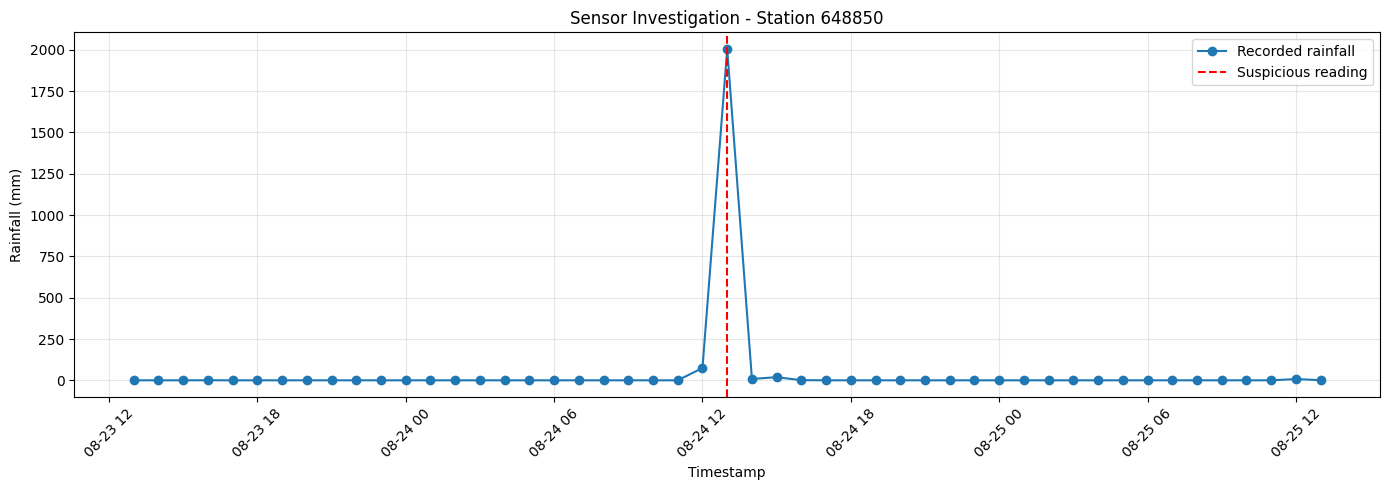

In [31]:
# STEP 23: Investigate a suspicious sensor reading

import pandas as pd
import matplotlib.pyplot as plt

station = "648850"
sensor = "rainfall"
event_time = pd.Timestamp("2016-08-24 13:00:00")

# Select the station's readings
station_data = master_df[
    (master_df["station_id"].astype(str) == station) &
    (master_df["sensor_type"] == sensor)
].copy()

# Select 24 hours before and after the event
event_data = station_data[
    (station_data["timestamp"] >= event_time - pd.Timedelta(hours=24)) &
    (station_data["timestamp"] <= event_time + pd.Timedelta(hours=24))
].sort_values("timestamp")

# Display the actual measurements
display(event_data[["timestamp", "value", "unit"]])

# Plot the event
plt.figure(figsize=(14, 5))

plt.plot(
    event_data["timestamp"],
    event_data["value"],
    marker="o",
    label="Recorded rainfall"
)

plt.axvline(
    event_time,
    color="red",
    linestyle="--",
    label="Suspicious reading"
)

plt.title(f"Sensor Investigation - Station {station}")
plt.xlabel("Timestamp")
plt.ylabel("Rainfall (mm)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save the investigated readings
event_data.to_csv(
    OUTPUT_PATH / "station_648850_event_investigation.csv",
    index=False
)

In [32]:
# STEP 24: Compare rainfall readings across stations

import pandas as pd

event_time = pd.Timestamp("2016-08-24 13:00:00")

# Select rainfall readings around the event
rainfall_comparison = master_df[
    (master_df["sensor_type"] == "rainfall") &
    (master_df["timestamp"] >= event_time - pd.Timedelta(hours=3)) &
    (master_df["timestamp"] <= event_time + pd.Timedelta(hours=3))
].copy()

# Calculate maximum recorded rainfall for each station
station_comparison = (
    rainfall_comparison.groupby("station_id")
    .agg(
        maximum_rainfall=("value", "max"),
        total_rainfall=("value", "sum"),
        valid_hours=("value", "count")
    )
    .reset_index()
    .sort_values("maximum_rainfall", ascending=False)
)

display(station_comparison.head(20))

station_comparison.to_csv(
    OUTPUT_PATH / "rainfall_event_station_comparison.csv",
    index=False
)

,station_id,maximum_rainfall,total_rainfall,valid_hours
50,648850,2005.321452,2108.000000,7
72,740601,2.500000,4.500000,7
58,649637,2.467631,3.907631,7
82,742739,2.460000,2.950000,7
37,648614,2.430000,3.880000,7
54,649514,2.400000,4.800000,7
46,648733,2.362009,3.912009,7
61,649713,2.238253,3.788253,7
57,649636,2.185226,4.332881,7
76,741611,2.130000,3.730000,7


In [33]:
# STEP 25: Explore station locations

import pandas as pd

inventory = pd.read_csv(
    DATA_PATH / "station_inventory.csv"
)

print("Inventory columns:")
print(inventory.columns.tolist())

print("\nStation 648850:")
display(
    inventory[
        inventory.astype(str).apply(
            lambda col: col.str.contains(
                "648850", regex=False, na=False
            )
        ).any(axis=1)
    ]
)

Inventory columns:
['station_id', 'parameter', 'unit', 'local_path', 'station_name', 'river_catchment', 'latitude', 'longitude', 'span_or_coverage', 'gap_notes_or_coverage', 'source']

Station 648850:


,station_id,parameter,unit,local_path,station_name,river_catchment,latitude,longitude,span_or_coverage,gap_notes_or_coverage,source
91,648850,Rainfall,mm,rainfall\648850.csv,Tamaki rainfall,NaN,-36.88031,174.8487,2015-01-01 01:00:00 ->,rows 16574 | 0.0% hours missing within span,https://environmentauckland.org.nz


In [34]:
# STEP 26: Find nearest rainfall stations

import pandas as pd
import numpy as np

# Select rainfall stations
rain_stations = inventory[
    inventory["parameter"].str.lower() == "rainfall"
].copy()

# Ensure coordinates are numeric
rain_stations["latitude"] = pd.to_numeric(
    rain_stations["latitude"], errors="coerce"
)

rain_stations["longitude"] = pd.to_numeric(
    rain_stations["longitude"], errors="coerce"
)

# Reference station: Tamaki rainfall
target_lat = -36.88031
target_lon = 174.84870

# Haversine distance calculation
lat1 = np.radians(target_lat)
lon1 = np.radians(target_lon)

lat2 = np.radians(rain_stations["latitude"])
lon2 = np.radians(rain_stations["longitude"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

rain_stations["distance_km"] = (
    6371 * 2 * np.arcsin(np.sqrt(a))
)

# Exclude target station
nearest_stations = rain_stations[
    rain_stations["station_id"].astype(str) != "648850"
].sort_values("distance_km").head(10)

display(
    nearest_stations[
        ["station_id", "station_name",
         "latitude", "longitude", "distance_km"]
    ]
)

nearest_stations.to_csv(
    OUTPUT_PATH / "nearest_rainfall_stations.csv",
    index=False
)

,station_id,station_name,latitude,longitude,distance_km
92,648851,Tamaki rainfall @ Colin Maiden park,-36.880310,174.848700,0.000000
93,648851C,Tamaki rainfall @ Composite,-36.880310,174.848700,0.000000
89,648825,Waiatarua Rainfall,-36.879280,174.827820,1.860688
90,648826,Mission Bay @ Aotea Reserve,-36.854105,174.827490,3.471411
87,648816,Churchill Park Rainfall,-36.854910,174.874550,3.642118
88,648817,Okahu Bay Bowling Club Rainfall,-36.855290,174.820580,3.741339
111,649837,Hope @ Mount Wellington,-36.911194,174.824009,4.076064
110,649836,Bassant Reserve Rainfall,-36.908430,174.808210,4.768828
112,649841,Pakuranga @ Park Village 2011-2017,-36.899126,174.897790,4.841171
114,649844,Otahuhu @ Seaside Park,-36.931185,174.864243,5.823403


In [35]:
# STEP 27: Compare nearby rainfall measurements

event_time = pd.Timestamp("2016-08-24 13:00:00")

# Target station + 10 nearest stations
station_ids = (
    ["648850"] +
    nearest_stations["station_id"].astype(str).tolist()
)

# Select their readings during the event
nearby_rainfall = master_df[
    (master_df["sensor_type"] == "rainfall") &
    (master_df["station_id"].astype(str).isin(station_ids)) &
    (
        master_df["timestamp"].between(
            event_time - pd.Timedelta(hours=3),
            event_time + pd.Timedelta(hours=3)
        )
    )
].copy()

# Add station names and distance information
station_info = rain_stations[
    ["station_id", "station_name", "distance_km"]
].copy()

station_info["station_id"] = (
    station_info["station_id"].astype(str)
)

nearby_rainfall["station_id"] = (
    nearby_rainfall["station_id"].astype(str)
)

nearby_rainfall = nearby_rainfall.merge(
    station_info,
    on="station_id",
    how="left"
)

# Summarise rainfall
nearby_comparison = (
    nearby_rainfall.groupby(
        ["station_id", "station_name", "distance_km"]
    )
    .agg(
        maximum_rainfall=("value", "max"),
        total_rainfall=("value", "sum"),
        valid_readings=("value", "count")
    )
    .reset_index()
    .sort_values("distance_km")
)

display(nearby_comparison)

nearby_comparison.to_csv(
    OUTPUT_PATH / "nearby_rainfall_event_comparison.csv",
    index=False
)

,station_id,station_name,distance_km,maximum_rainfall,total_rainfall,valid_readings
3,648850,Tamaki rainfall,0.000000,2005.321452,2108.000000,7
4,648851,Tamaki rainfall @ Colin Maiden park,0.000000,0.803333,3.963111,7
5,648851C,Tamaki rainfall @ Composite,0.000000,0.768333,3.790444,7
2,648825,Waiatarua Rainfall,1.860688,1.480000,2.950000,7
0,648816,Churchill Park Rainfall,3.642118,1.692755,2.732755,7
1,648817,Okahu Bay Bowling Club Rainfall,3.741339,1.600000,2.670000,7
6,649836,Bassant Reserve Rainfall,4.768828,1.979362,2.989362,7
7,649841,Pakuranga @ Park Village 2011-2017,4.841171,1.470000,2.460000,7


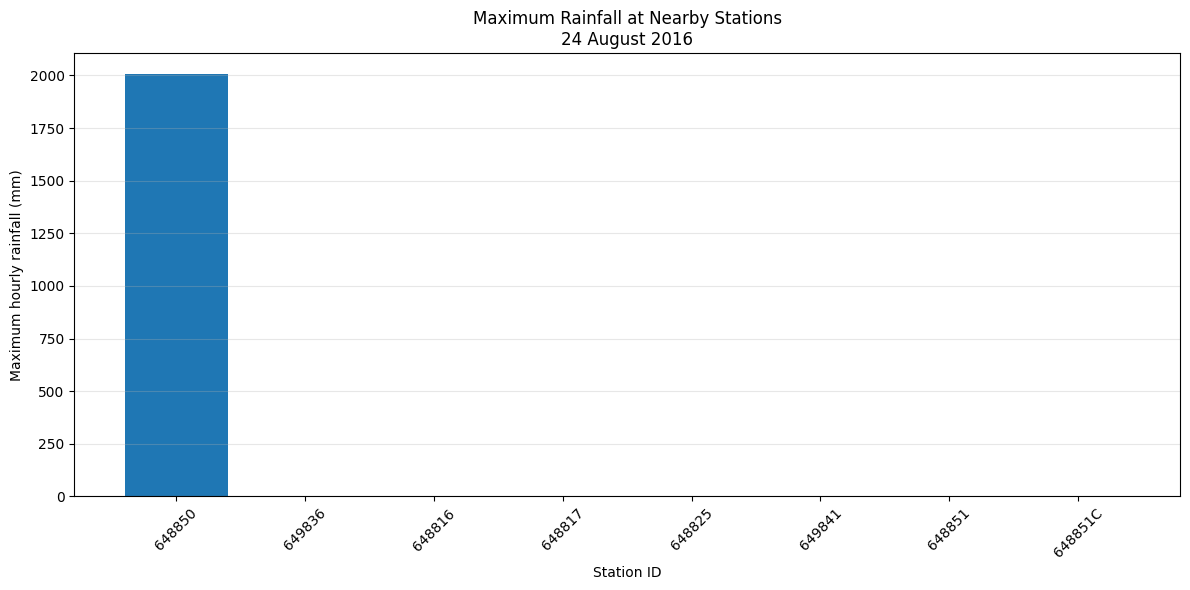

In [36]:
# STEP 28: Visualise nearby rainfall comparison

import matplotlib.pyplot as plt

plot_data = nearby_comparison.sort_values(
    "maximum_rainfall", ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data["station_id"],
    plot_data["maximum_rainfall"]
)

plt.title(
    "Maximum Rainfall at Nearby Stations\n"
    "24 August 2016"
)

plt.xlabel("Station ID")
plt.ylabel("Maximum hourly rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "nearby_rainfall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# STEP 29: Compare measurements at the exact same hour

event_time = pd.Timestamp("2016-08-24 13:00:00")

station_ids = ["648850", "648851", "648851C",
               "648825", "648816", "648817",
               "649836", "649841"]

same_hour = master_df[
    (master_df["sensor_type"] == "rainfall") &
    (master_df["station_id"].astype(str).isin(station_ids)) &
    (master_df["timestamp"] == event_time)
].copy()

same_hour = same_hour.merge(
    inventory[["station_id", "station_name"]].assign(
        station_id=lambda x: x["station_id"].astype(str)
    ),
    on="station_id",
    how="left"
)

display(
    same_hour[
        ["station_id", "station_name", "timestamp", "value"]
    ].sort_values("value", ascending=False)
)

same_hour.to_csv(
    OUTPUT_PATH / "exact_hour_rainfall_comparison.csv",
    index=False
)

,station_id,station_name,timestamp,value
3,648850,Tamaki rainfall,2016-08-24 13:00:00,2005.321452
4,648851,Tamaki rainfall @ Colin Maiden park,2016-08-24 13:00:00,0.803333
5,648851C,Tamaki rainfall @ Composite,2016-08-24 13:00:00,0.768333
6,649836,Bassant Reserve Rainfall,2016-08-24 13:00:00,0.500000
2,648825,Waiatarua Rainfall,2016-08-24 13:00:00,0.490000
7,649841,Pakuranga @ Park Village 2011-2017,2016-08-24 13:00:00,0.490000
0,648816,Churchill Park Rainfall,2016-08-24 13:00:00,0.000289
1,648817,Okahu Bay Bowling Club Rainfall,2016-08-24 13:00:00,0.000000


In [38]:
# STEP 30A: Sudden spike detection

import pandas as pd
import numpy as np

spike_results = []
spike_summary = []

for (station, sensor), group in master_df.groupby(
    ["station_id", "sensor_type"], sort=False
):

    # Sort readings by timestamp
    data = group[
        ["timestamp", "value"]
    ].copy().sort_values("timestamp")

    # For repeated timestamps, prefer a numeric reading
    data = data.sort_values(
        "value", na_position="last", kind="stable"
    ).drop_duplicates("timestamp")

    data = data.sort_values("timestamp").reset_index(drop=True)

    # Previous and next readings
    data["previous"] = data["value"].shift(1)
    data["next"] = data["value"].shift(-1)

    # Hourly changes
    data["change_before"] = data["value"] - data["previous"]
    data["change_after"] = data["next"] - data["value"]

    # Only compare consecutive hourly readings
    prev_hour = data["timestamp"].diff().eq(
        pd.Timedelta(hours=1)
    )

    next_hour = (
        data["timestamp"].shift(-1) - data["timestamp"]
    ).eq(pd.Timedelta(hours=1))

    # Historical absolute hourly changes
    hourly_changes = data.loc[
        prev_hour, "change_before"
    ].abs().dropna()

    if len(hourly_changes) < 100:
        continue

    # Station-specific 99th percentile of hourly changes
    change_limit = hourly_changes.quantile(0.99)

    if change_limit <= 0:
        continue

    # Large change followed by an opposite large change
    sharp_reversal = (
        (data["change_before"].abs() > change_limit) &
        (data["change_after"].abs() > change_limit) &
        (data["change_before"] * data["change_after"] < 0)
    )

    # Before and after readings should be relatively close
    returns_to_baseline = (
        (data["next"] - data["previous"]).abs()
        <= change_limit
    )

    data["spike_flag"] = (
        sharp_reversal &
        returns_to_baseline &
        prev_hour &
        next_hour
    )

    flagged = data.loc[data["spike_flag"]].copy()

    flagged["station_id"] = station
    flagged["sensor_type"] = sensor
    flagged["change_threshold"] = change_limit

    if not flagged.empty:
        spike_results.append(
            flagged[
                ["station_id", "sensor_type", "timestamp",
                 "value", "previous", "next",
                 "change_threshold"]
            ]
        )

    spike_summary.append({
        "station_id": station,
        "sensor_type": sensor,
        "spike_count": len(flagged),
        "change_threshold": change_limit
    })

spike_details = (
    pd.concat(spike_results, ignore_index=True)
    if spike_results else
    pd.DataFrame(columns=[
        "station_id", "sensor_type", "timestamp",
        "value", "previous", "next", "change_threshold"
    ])
)

spike_summary_df = pd.DataFrame(spike_summary)

print("Total sudden spike candidates:", len(spike_details))

display(spike_details.head(20))

Total sudden spike candidates: 24255


,station_id,sensor_type,timestamp,value,previous,next,change_threshold
0,64068001,rainfall,2018-08-17 09:00:00,9.681077,0.318923,0.000000,3.5
1,64068001,rainfall,2018-09-10 19:00:00,4.664577,0.000000,0.335423,3.5
2,64068001,rainfall,2018-09-17 14:00:00,5.000000,0.000000,0.000000,3.5
3,64068001,rainfall,2018-09-18 19:00:00,8.228754,2.688513,4.466126,3.5
4,64068001,rainfall,2018-10-11 16:00:00,10.000000,1.638211,1.500000,3.5
5,64068001,rainfall,2018-10-11 17:00:00,1.500000,10.000000,7.000000,3.5
6,64068001,rainfall,2018-10-11 18:00:00,7.000000,1.500000,0.000000,3.5
7,64068001,rainfall,2018-10-12 00:00:00,5.000000,0.000000,0.000000,3.5
8,64068001,rainfall,2018-10-27 20:00:00,7.000000,1.000000,2.500000,3.5
9,64068001,rainfall,2018-10-30 02:00:00,4.676698,0.000000,0.323302,3.5


Dataset import and integration

Complete

Exploratory Data Analysis (EDA)

Complete

Missing, zero and duplicate analysis

Complete

Missing and zero-period analysis

Complete

Station-specific statistical thresholds

Complete

High-value anomaly detection

Complete

Detailed rainfall anomaly investigation


In [39]:
# STEP 30B: Save spike detection results

spike_details.to_csv(
    OUTPUT_PATH / "sudden_spike_details.csv",
    index=False
)

spike_summary_df.to_csv(
    OUTPUT_PATH / "sudden_spike_summary.csv",
    index=False
)

print("Spike detection results saved successfully.")

Spike detection results saved successfully.


In [40]:
# STEP 30C: Calculate spike severity

spike_details["spike_amplitude"] = (
    spike_details["value"] -
    (
        spike_details["previous"] +
        spike_details["next"]
    ) / 2
).abs()

spike_details["spike_severity"] = (
    spike_details["spike_amplitude"] /
    spike_details["change_threshold"]
)

# Use a provisional severity threshold
spike_details["priority"] = np.select(
    [
        spike_details["spike_severity"] >= 10,
        spike_details["spike_severity"] >= 3
    ],
    [
        "High Priority",
        "Medium Priority"
    ],
    default="Low Priority"
)

display(
    spike_details.sort_values(
        "spike_severity", ascending=False
    ).head(20)
)

# Save the results
spike_details.to_csv(
    OUTPUT_PATH / "spike_severity_results.csv",
    index=False
)

print("Spike severity results saved!")

,station_id,sensor_type,timestamp,value,previous,next,change_threshold,spike_amplitude,spike_severity,priority
23041,7202,river_water_level,2022-11-09 03:00:00,1330.000,1.388,1.303,0.091,1328.6545,14600.598901,High Priority
23056,7202,river_water_level,2023-01-07 19:00:00,1328.000,1.337,1.324,0.091,1326.6695,14578.785714,High Priority
23060,7202,river_water_level,2023-01-12 00:00:00,1.327,1326.000,1326.000,0.091,1324.6730,14556.846154,High Priority
23059,7202,river_water_level,2023-01-11 23:00:00,1326.000,1.332,1.327,0.091,1324.6705,14556.818681,High Priority
23039,7202,river_water_level,2022-10-31 06:00:00,1323.000,1.333,1.319,0.091,1321.6740,14523.890110,High Priority
23071,7202,river_water_level,2023-02-15 07:00:00,1323.000,1.331,1.322,0.091,1321.6735,14523.884615,High Priority
23061,7202,river_water_level,2023-01-12 04:00:00,1322.000,1.327,1.319,0.091,1320.6770,14512.934066,High Priority
23046,7202,river_water_level,2022-11-21 15:00:00,1322.000,1.333,1.316,0.091,1320.6755,14512.917582,High Priority
23072,7202,river_water_level,2023-02-15 09:00:00,1315.000,1.322,1.313,0.091,1313.6825,14436.071429,High Priority
23030,7202,river_water_level,2022-09-12 16:00:00,1314.000,1.342,1.304,0.091,1312.6770,14425.021978,High Priority


Spike severity results saved!


In [41]:
# STEP 31: Flatline detection

flatline_results = []

for (station, sensor), group in master_df.groupby(
    ["station_id", "sensor_type"], sort=False
):

    if sensor == "rainfall":
        continue

    data = group[
        ["timestamp", "value"]
    ].copy()

    # Prefer numeric values for duplicate timestamps
    data = data.sort_values(
        "value", na_position="last", kind="stable"
    ).drop_duplicates("timestamp")

    data = data.sort_values("timestamp").reset_index(drop=True)

    # Detect whether readings remain unchanged
    same_value = (
        data["value"].eq(data["value"].shift()) &
        data["value"].notna()
    )

    # Check hourly continuity
    continuous = data["timestamp"].diff().eq(
        pd.Timedelta(hours=1)
    )

    # Create a new group when value changes or time breaks
    run_id = (~(same_value & continuous)).cumsum()

    data["run_id"] = run_id

    runs = (
        data.dropna(subset=["value"])
        .groupby("run_id")
        .agg(
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            reading=("value", "first"),
            duration_hours=("value", "size")
        )
        .reset_index(drop=True)
    )

    # Starting threshold: 24 consecutive hours
    flagged = runs[
        runs["duration_hours"] >= 24
    ].copy()

    if not flagged.empty:
        flagged["station_id"] = station
        flagged["sensor_type"] = sensor

        flatline_results.append(flagged)

flatline_df = (
    pd.concat(flatline_results, ignore_index=True)
    if flatline_results else
    pd.DataFrame(columns=[
        "station_id", "sensor_type", "start_time",
        "end_time", "reading", "duration_hours"
    ])
)

print("Flatline episodes identified:", len(flatline_df))

display(
    flatline_df.sort_values(
        "duration_hours", ascending=False
    ).head(20)
)

flatline_df.to_csv(
    OUTPUT_PATH / "flatline_episodes.csv",
    index=False
)

print("Flatline results saved successfully.")

Flatline episodes identified: 8720


,start_time,end_time,reading,duration_hours,station_id,sensor_type
1444,2020-01-08 10:00:00,2020-05-05 13:00:00,0.0000,2836,7202,river_discharge
1523,2025-01-29 17:00:00,2025-04-04 05:00:00,0.0000,1549,7202,river_discharge
0,2015-01-01 12:00:00,2015-02-27 11:00:00,0.0000,1368,108122,river_discharge
7188,2017-04-13 05:00:00,2017-05-16 12:00:00,1.1920,800,6437131,river_water_level
1385,2017-01-22 15:00:00,2017-02-16 07:00:00,0.0000,593,7202,river_discharge
8473,2021-12-17 00:00:00,2022-01-10 08:00:00,0.1400,585,8006,river_water_level
1005,2020-03-20 15:00:00,2020-04-13 01:00:00,0.0000,563,6995,river_discharge
8000,2025-07-03 02:00:00,2025-07-26 04:00:00,0.0820,555,7607,river_water_level
4620,2025-07-03 02:00:00,2025-07-26 04:00:00,0.0637,555,7607,river_discharge
7003,2022-02-24 14:00:00,2022-03-16 03:00:00,0.0010,470,8304,river_discharge


Flatline results saved successfully.


In [42]:
# STEP 31B: Prioritise flatline episodes

import numpy as np
import pandas as pd

flatline_review = flatline_df.copy()

# Separate zero and non-zero flatlines
flatline_review["reading_type"] = np.where(
    flatline_review["reading"] == 0,
    "Zero",
    "Non-zero"
)

# Set provisional investigation priorities
flatline_review["priority"] = np.select(
    [
        flatline_review["duration_hours"] >= 168,
        flatline_review["duration_hours"] >= 72
    ],
    [
        "High Priority",
        "Medium Priority"
    ],
    default="Low Priority"
)

# Display highest priority episodes
display(
    flatline_review.sort_values(
        "duration_hours",
        ascending=False
    ).head(20)
)

# Summarise classifications
display(
    pd.crosstab(
        flatline_review["sensor_type"],
        flatline_review["priority"]
    )
)

# Save results for Power BI
flatline_review.to_csv(
    OUTPUT_PATH / "flatline_review_priority.csv",
    index=False
)

print("Saved flatline investigation results!")

,start_time,end_time,reading,duration_hours,station_id,sensor_type,reading_type,priority
1444,2020-01-08 10:00:00,2020-05-05 13:00:00,0.0000,2836,7202,river_discharge,Zero,High Priority
1523,2025-01-29 17:00:00,2025-04-04 05:00:00,0.0000,1549,7202,river_discharge,Zero,High Priority
0,2015-01-01 12:00:00,2015-02-27 11:00:00,0.0000,1368,108122,river_discharge,Zero,High Priority
7188,2017-04-13 05:00:00,2017-05-16 12:00:00,1.1920,800,6437131,river_water_level,Non-zero,High Priority
1385,2017-01-22 15:00:00,2017-02-16 07:00:00,0.0000,593,7202,river_discharge,Zero,High Priority
8473,2021-12-17 00:00:00,2022-01-10 08:00:00,0.1400,585,8006,river_water_level,Non-zero,High Priority
1005,2020-03-20 15:00:00,2020-04-13 01:00:00,0.0000,563,6995,river_discharge,Zero,High Priority
8000,2025-07-03 02:00:00,2025-07-26 04:00:00,0.0820,555,7607,river_water_level,Non-zero,High Priority
4620,2025-07-03 02:00:00,2025-07-26 04:00:00,0.0637,555,7607,river_discharge,Non-zero,High Priority
7003,2022-02-24 14:00:00,2022-03-16 03:00:00,0.0010,470,8304,river_discharge,Non-zero,High Priority


priority,High Priority,Low Priority,Medium Priority
sensor_type,,,
river_discharge,187,6036,881
river_water_level,11,1558,47


Saved flatline investigation results!


In [43]:
# STEP 32A: Zero-Reading Investigation Engine

import pandas as pd
import numpy as np

# Load our earlier results from Google Drive
episodes = pd.read_csv(
    OUTPUT_PATH / "missing_zero_episodes.csv"
)

# Select zero-reading episodes only
zero_df = episodes[
    episodes["issue_type"] == "Zero"
].copy()

# Calculate each station's historical 95th percentile
zero_df["station_zero_threshold"] = (
    zero_df.groupby(["station_id", "sensor_type"])
    ["duration_hours"]
    .transform(lambda x: x.quantile(0.95))
)

# Count zero episodes per station
zero_df["episode_count"] = (
    zero_df.groupby(["station_id", "sensor_type"])
    ["duration_hours"].transform("size")
)

# Flag long zero episodes
zero_df["zero_review_flag"] = (
    (zero_df["episode_count"] >= 20) &
    (zero_df["duration_hours"] >
     zero_df["station_zero_threshold"])
)

# Insufficient history needs separate review
zero_df["status"] = np.select(
    [
        zero_df["episode_count"] < 20,
        zero_df["zero_review_flag"]
    ],
    [
        "Insufficient Zero History",
        "Unusually Long Zero - Review"
    ],
    default="Within Historical Pattern"
)

display(
    zero_df.sort_values(
        "duration_hours", ascending=False
    ).head(20)
)

zero_df.to_csv(
    OUTPUT_PATH / "zero_investigation_results.csv",
    index=False
)

print("Zero investigation results saved.")

,station_id,sensor_type,issue_type,start_date,end_date,duration_hours,station_zero_threshold,episode_count,zero_review_flag,status
319336,742826,rainfall,Zero,2023-01-27 22:00:00,2024-01-01 00:00:00,8115,104.35,1974,True,Unusually Long Zero - Review
317673,742826,rainfall,Zero,2016-01-01 01:00:00,2016-11-16 14:00:00,7694,104.35,1974,True,Unusually Long Zero - Review
317735,742826,rainfall,Zero,2018-01-01 01:00:00,2018-10-30 09:00:00,7257,104.35,1974,True,Unusually Long Zero - Review
319337,742826,rainfall,Zero,2024-01-01 01:00:00,2024-10-26 16:00:00,7192,104.35,1974,True,Unusually Long Zero - Review
317734,742826,rainfall,Zero,2017-03-08 19:00:00,2018-01-01 00:00:00,7158,104.35,1974,True,Unusually Long Zero - Review
300033,741815,rainfall,Zero,2017-04-05 07:00:00,2018-01-01 00:00:00,6498,102.00,3230,True,Unusually Long Zero - Review
317672,742826,rainfall,Zero,2015-07-17 12:00:00,2016-01-01 00:00:00,4021,104.35,1974,True,Unusually Long Zero - Review
300034,741815,rainfall,Zero,2018-01-01 01:00:00,2018-05-06 07:00:00,3007,102.00,3230,True,Unusually Long Zero - Review
95126,647727,rainfall,Zero,2025-09-01 11:00:00,2026-01-01 00:00:00,2918,103.00,3828,True,Unusually Long Zero - Review
319595,742826,rainfall,Zero,2025-07-16 07:00:00,2025-11-12 12:00:00,2862,104.35,1974,True,Unusually Long Zero - Review


Zero investigation results saved.


In [44]:
import pandas as pd
import numpy as np
from pathlib import Path

OUTPUT_PATH = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "capstone_outputs"
)

episodes = pd.read_csv(
    OUTPUT_PATH / "missing_zero_episodes.csv"
)

print("Columns:")
print(episodes.columns.tolist())

print("\nFirst five records:")
display(episodes.head())

print("\nIssue types:")
if "issue_type" in episodes.columns:
    print(episodes["issue_type"].value_counts(dropna=False))

Columns:
['station_id', 'sensor_type', 'issue_type', 'start_date', 'end_date', 'duration_hours']

First five records:


,station_id,sensor_type,issue_type,start_date,end_date,duration_hours
0,64068001,rainfall,Missing,2019-01-01 00:00:00,2019-01-01 00:00:00,1
1,64068001,rainfall,Missing,2020-01-01 00:00:00,2020-01-01 00:00:00,1
2,64068001,rainfall,Missing,2021-01-01 00:00:00,2021-01-01 00:00:00,1
3,64068001,rainfall,Missing,2022-01-01 00:00:00,2022-01-01 00:00:00,1
4,64068001,rainfall,Missing,2023-01-01 00:00:00,2023-01-01 00:00:00,1



Issue types:
issue_type
Zero       345090
Missing      6786
Name: count, dtype: int64


In [45]:
# STEP 32B: Historical zero-reading analysis

zero_df = episodes[
    episodes["issue_type"].astype(str).str.lower() == "zero"
].copy()

zero_df["duration_hours"] = pd.to_numeric(
    zero_df["duration_hours"],
    errors="coerce"
)

zero_df = zero_df.dropna(subset=["duration_hours"])

# Group by station and sensor type
groups = zero_df.groupby(
    ["station_id", "sensor_type"]
)["duration_hours"]

# Historical 95th-percentile zero duration
zero_df["zero_duration_threshold"] = (
    groups.transform(lambda x: x.quantile(0.95))
)

# Number of recorded zero episodes
zero_df["zero_episode_count"] = groups.transform("size")

# Classify episodes for investigation
zero_df["review_status"] = np.select(
    [
        zero_df["zero_episode_count"] < 20,
        (
            zero_df["duration_hours"] >
            zero_df["zero_duration_threshold"]
        )
    ],
    [
        "Insufficient History",
        "Unusually Long - Review"
    ],
    default="Within Historical Pattern"
)

print("ZERO-READING INVESTIGATION RESULTS")
print("=" * 45)

print("\nTotal zero episodes:", len(zero_df))

print("\nClassification:")
display(zero_df["review_status"].value_counts())

print("\nClassification by sensor type:")
display(
    pd.crosstab(
        zero_df["sensor_type"],
        zero_df["review_status"]
    )
)

print("\nLongest zero episodes:")
display(
    zero_df.sort_values(
        "duration_hours",
        ascending=False
    ).head(20)
)

# Save results
zero_df.to_csv(
    OUTPUT_PATH / "zero_investigation_results.csv",
    index=False
)

print("\nSaved: zero_investigation_results.csv")

ZERO-READING INVESTIGATION RESULTS

Total zero episodes: 345090

Classification:


,count
review_status,
Within Historical Pattern,327852
Unusually Long - Review,17131
Insufficient History,107



Classification by sensor type:


review_status,Insufficient History,Unusually Long - Review,Within Historical Pattern
sensor_type,,,
rainfall,12,17063,326636
river_discharge,57,54,940
river_water_level,38,14,276



Longest zero episodes:


,station_id,sensor_type,issue_type,start_date,end_date,duration_hours,zero_duration_threshold,zero_episode_count,review_status
319336,742826,rainfall,Zero,2023-01-27 22:00:00,2024-01-01 00:00:00,8115,104.35,1974,Unusually Long - Review
317673,742826,rainfall,Zero,2016-01-01 01:00:00,2016-11-16 14:00:00,7694,104.35,1974,Unusually Long - Review
317735,742826,rainfall,Zero,2018-01-01 01:00:00,2018-10-30 09:00:00,7257,104.35,1974,Unusually Long - Review
319337,742826,rainfall,Zero,2024-01-01 01:00:00,2024-10-26 16:00:00,7192,104.35,1974,Unusually Long - Review
317734,742826,rainfall,Zero,2017-03-08 19:00:00,2018-01-01 00:00:00,7158,104.35,1974,Unusually Long - Review
300033,741815,rainfall,Zero,2017-04-05 07:00:00,2018-01-01 00:00:00,6498,102.00,3230,Unusually Long - Review
317672,742826,rainfall,Zero,2015-07-17 12:00:00,2016-01-01 00:00:00,4021,104.35,1974,Unusually Long - Review
300034,741815,rainfall,Zero,2018-01-01 01:00:00,2018-05-06 07:00:00,3007,102.00,3230,Unusually Long - Review
95126,647727,rainfall,Zero,2025-09-01 11:00:00,2026-01-01 00:00:00,2918,103.00,3828,Unusually Long - Review
319595,742826,rainfall,Zero,2025-07-16 07:00:00,2025-11-12 12:00:00,2862,104.35,1974,Unusually Long - Review



Saved: zero_investigation_results.csv


In [46]:
# STEP 33A: Nearby-station validation of a zero-rainfall episode

import pandas as pd
import numpy as np

target_id = "742826"

start = pd.Timestamp("2023-01-28 00:00:00")
end = pd.Timestamp("2023-02-04 00:00:00")  # exclusive

# Prepare station inventory
stations = inventory.copy()
stations["station_id"] = stations["station_id"].astype(str)
stations["latitude"] = pd.to_numeric(
    stations["latitude"], errors="coerce"
)
stations["longitude"] = pd.to_numeric(
    stations["longitude"], errors="coerce"
)

stations = stations[
    stations["parameter"].astype(str).str.lower().eq("rainfall")
].dropna(subset=["latitude", "longitude"])

stations = stations.drop_duplicates("station_id")

target = stations[stations["station_id"] == target_id]

if target.empty:
    raise ValueError("Target station not found in rainfall inventory.")

lat1 = np.radians(target["latitude"].iloc[0])
lon1 = np.radians(target["longitude"].iloc[0])

lat2 = np.radians(stations["latitude"])
lon2 = np.radians(stations["longitude"])

# Haversine distance in kilometres
a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

stations["distance_km"] = 6371 * 2 * np.arcsin(
    np.sqrt(np.clip(a, 0, 1))
)

nearby = (
    stations[stations["station_id"] != target_id]
    .nsmallest(5, "distance_km")
)

ids = [target_id] + nearby["station_id"].tolist()

# Compare actual hourly rainfall
comparison = master_df.loc[
    master_df["sensor_type"].eq("rainfall")
    & master_df["station_id"].astype(str).isin(ids)
    & master_df["timestamp"].ge(start)
    & master_df["timestamp"].lt(end),
    ["station_id", "timestamp", "value"]
].copy()

comparison["station_id"] = comparison["station_id"].astype(str)

# Resolve duplicate timestamps for this comparison
comparison = comparison.sort_values(
    "value", na_position="last"
).drop_duplicates(
    ["station_id", "timestamp"],
    keep="first"
)

summary = comparison.groupby("station_id").agg(
    valid_hours=("value", "count"),
    zero_hours=("value", lambda s: s.eq(0).sum()),
    rainy_hours=("value", lambda s: s.gt(0).sum()),
    total_rainfall=("value", "sum"),
    max_hourly_rainfall=("value", "max")
).reset_index()

summary = stations[
    stations["station_id"].isin(ids)
][["station_id", "station_name", "distance_km"]].merge(
    summary, on="station_id", how="left"
)

summary["expected_hours"] = 168

display(summary.sort_values("distance_km"))

summary.to_csv(
    OUTPUT_PATH / "zero_nearby_validation_742826.csv",
    index=False
)

,station_id,station_name,distance_km,valid_hours,zero_hours,rainy_hours,total_rainfall,max_hourly_rainfall,expected_hours
4,742826,Puni Hill Reserve,0.000000,168.0,168.0,0.0,0.000000,0.000000,168
0,741813,Whangamaire @ Culvert,5.425770,168.0,114.0,54.0,106.000000,12.000000,168
3,742824,Mauku RAWS @ Mauku,6.495598,168.0,122.0,46.0,112.000000,16.500000,168
5,742914,Ngakoroa @ Donovans,9.622952,168.0,125.0,43.0,62.110000,8.391029,168
2,742736C,Waitangi @ Divers Road Composite Record,9.842596,NaN,NaN,NaN,NaN,NaN,168
1,742736,Waitangi @ Diver Road,9.842596,168.0,114.0,54.0,114.584737,16.177183,168


In [47]:
# STEP 33B: Same-hour neighbouring rainfall validation

target_id = "742826"
start = pd.Timestamp("2023-01-28")
end = pd.Timestamp("2023-02-04")

neighbor_ids = ["741813", "742824", "742914", "742736"]
all_ids = [target_id] + neighbor_ids

hourly = master_df.loc[
    master_df["sensor_type"].eq("rainfall")
    & master_df["station_id"].astype(str).isin(all_ids)
    & master_df["timestamp"].ge(start)
    & master_df["timestamp"].lt(end),
    ["station_id", "timestamp", "value"]
].copy()

hourly["station_id"] = hourly["station_id"].astype(str)

# Prefer valid measurements for duplicate timestamps
hourly = (
    hourly.sort_values("value", na_position="last")
    .drop_duplicates(["station_id", "timestamp"])
)

# One row per hour, one column per station
hourly_table = hourly.pivot(
    index="timestamp",
    columns="station_id",
    values="value"
)

# Count neighbouring stations reporting rainfall each hour
neighbor_values = hourly_table.reindex(columns=neighbor_ids)

hourly_table["neighbors_reporting_rain"] = (
    neighbor_values.gt(0).sum(axis=1)
)

hourly_table["neighbors_with_data"] = (
    neighbor_values.notna().sum(axis=1)
)

# Target records zero while at least two neighbours record rain
hourly_table["suspicious_zero"] = (
    hourly_table[target_id].eq(0)
    & hourly_table["neighbors_reporting_rain"].ge(2)
)

print(
    "Hours where target was zero and at least "
    "two neighbours recorded rainfall:",
    int(hourly_table["suspicious_zero"].sum())
)

print("\nExample hours:")
display(
    hourly_table[
        hourly_table["suspicious_zero"]
    ].head(20)
)

hourly_table.to_csv(
    OUTPUT_PATH / "zero_same_hour_validation_742826.csv"
)

print("Saved same-hour validation results.")

Hours where target was zero and at least two neighbours recorded rainfall: 56

Example hours:


station_id,741813,742736,742824,742826,742914,neighbors_reporting_rain,neighbors_with_data,suspicious_zero
timestamp,,,,,,,,
2023-01-28 00:00:00,3.500000,5.944737,4.0,0.0,1.01,4,4,True
2023-01-28 01:00:00,0.500000,0.500000,0.0,0.0,0.00,2,4,True
2023-01-28 05:00:00,0.500000,0.000000,0.0,0.0,0.51,2,4,True
2023-01-28 06:00:00,0.500000,0.510000,0.5,0.0,0.00,3,4,True
2023-01-28 07:00:00,0.500000,0.000000,0.0,0.0,5.55,2,4,True
2023-01-28 08:00:00,0.500000,0.500000,0.0,0.0,0.51,3,4,True
2023-01-28 09:00:00,9.000000,8.082817,16.5,0.0,2.02,4,4,True
2023-01-28 10:00:00,1.500000,16.177183,1.5,0.0,0.50,4,4,True
2023-01-28 11:00:00,0.000000,1.010000,0.5,0.0,0.00,2,4,True


Saved same-hour validation results.


In [1]:
# STEP 33C: Reusable neighbouring rainfall validation

import pandas as pd
import numpy as np

def validate_zero_rainfall(
    target_id,
    start_time,
    end_time,
    max_neighbors=5,
    min_rain_neighbors=2
):
    target_id = str(target_id)
    start_time = pd.Timestamp(start_time)
    end_time = pd.Timestamp(end_time)

    # Prepare rainfall station inventory
    stations = inventory.copy()

    stations["station_id"] = stations["station_id"].astype(str)
    stations["latitude"] = pd.to_numeric(
        stations["latitude"], errors="coerce"
    )
    stations["longitude"] = pd.to_numeric(
        stations["longitude"], errors="coerce"
    )

    stations = stations[
        stations["parameter"].astype(str).str.lower().eq("rainfall")
    ].dropna(subset=["latitude", "longitude"])

    stations = stations.drop_duplicates("station_id")

    target = stations[stations["station_id"] == target_id]

    if target.empty:
        raise ValueError("Target rainfall station not found.")

    # Calculate geographical distances
    lat1 = np.radians(target["latitude"].iloc[0])
    lon1 = np.radians(target["longitude"].iloc[0])

    lat2 = np.radians(stations["latitude"])
    lon2 = np.radians(stations["longitude"])

    a = (
        np.sin((lat2 - lat1) / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin((lon2 - lon1) / 2) ** 2
    )

    stations["distance_km"] = (
        6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    )

    nearby = (
        stations[stations["station_id"] != target_id]
        .nsmallest(max_neighbors, "distance_km")
    )

    neighbor_ids = nearby["station_id"].tolist()
    all_ids = [target_id] + neighbor_ids

    # Extract same-hour rainfall measurements
    hourly = master_df.loc[
        master_df["sensor_type"].eq("rainfall")
        & master_df["station_id"].astype(str).isin(all_ids)
        & master_df["timestamp"].ge(start_time)
        & master_df["timestamp"].lt(end_time),
        ["station_id", "timestamp", "value"]
    ].copy()

    hourly["station_id"] = hourly["station_id"].astype(str)

    hourly = (
        hourly.sort_values("value", na_position="last")
        .drop_duplicates(["station_id", "timestamp"])
    )

    hourly_table = hourly.pivot(
        index="timestamp",
        columns="station_id",
        values="value"
    )

    # Ensure target and all selected neighbours appear
    hourly_table = hourly_table.reindex(
        columns=all_ids
    )

    neighbor_values = hourly_table[neighbor_ids]

    hourly_table["neighbors_with_data"] = (
        neighbor_values.notna().sum(axis=1)
    )

    hourly_table["neighbors_reporting_rain"] = (
        neighbor_values.gt(0).sum(axis=1)
    )

    hourly_table["suspicious_zero"] = (
        hourly_table[target_id].eq(0)
        & hourly_table["neighbors_reporting_rain"].ge(
            min_rain_neighbors
        )
    )

    target_zero_hours = int(
        hourly_table[target_id].eq(0).sum()
    )

    flagged_hours = int(
        hourly_table["suspicious_zero"].sum()
    )

    result = {
        "station_id": target_id,
        "start_time": start_time,
        "end_time": end_time,
        "target_zero_hours": target_zero_hours,
        "suspicious_zero_hours": flagged_hours,
        "disagreement_rate_pct": (
            round(flagged_hours / target_zero_hours * 100, 2)
            if target_zero_hours > 0 else np.nan
        ),
        "neighbors_selected": len(neighbor_ids)
    }

    return result, hourly_table, nearby

In [48]:
# STEP 33D: Test neighbouring rainfall validation

result, hourly_details, nearest = validate_zero_rainfall(
    target_id="742826",
    start_time="2023-01-28",
    end_time="2023-02-04",
    max_neighbors=5
)

print("NEIGHBOURING STATION VALIDATION RESULTS")
print("=" * 45)

# Display the summary
display(pd.DataFrame([result]))

# Display nearest stations
print("\nNearest rainfall stations:")
display(
    nearest[
        ["station_id", "station_name", "distance_km"]
    ]
)

# Display suspicious hours
print("\nExample suspicious zero hours:")
display(
    hourly_details[
        hourly_details["suspicious_zero"]
    ].head(10)
)

# Save the results
pd.DataFrame([result]).to_csv(
    OUTPUT_PATH / "zero_validation_summary_742826.csv",
    index=False
)

print("\nResults saved successfully!")

NEIGHBOURING STATION VALIDATION RESULTS


,station_id,start_time,end_time,target_zero_hours,suspicious_zero_hours,disagreement_rate_pct,neighbors_selected
0,742826,2023-01-28,2023-02-04,168,56,33.33,5



Nearest rainfall stations:


,station_id,station_name,distance_km
141,741813,Whangamaire @ Culvert,5.425770
148,742824,Mauku RAWS @ Mauku,6.495598
150,742914,Ngakoroa @ Donovans,9.622952
144,742736,Waitangi @ Diver Road,9.842596
145,742736C,Waitangi @ Divers Road Composite Record,9.842596



Example suspicious zero hours:


station_id,742826,741813,742824,742914,742736,742736C,neighbors_with_data,neighbors_reporting_rain,suspicious_zero
timestamp,,,,,,,,,
2023-01-28 00:00:00,0.0,3.5,4.0,1.01,5.944737,NaN,4,4,True
2023-01-28 01:00:00,0.0,0.5,0.0,0.00,0.500000,NaN,4,2,True
2023-01-28 05:00:00,0.0,0.5,0.0,0.51,0.000000,NaN,4,2,True
2023-01-28 06:00:00,0.0,0.5,0.5,0.00,0.510000,NaN,4,3,True
2023-01-28 07:00:00,0.0,0.5,0.0,5.55,0.000000,NaN,4,2,True
2023-01-28 08:00:00,0.0,0.5,0.0,0.51,0.500000,NaN,4,3,True
2023-01-28 09:00:00,0.0,9.0,16.5,2.02,8.082817,NaN,4,4,True
2023-01-28 10:00:00,0.0,1.5,1.5,0.50,16.177183,NaN,4,4,True
2023-01-28 11:00:00,0.0,0.0,0.5,0.00,1.010000,NaN,4,2,True



Results saved successfully!


In [49]:
# STEP 34A: Select stations for multi-station validation

# Use zero_df from Step 32
rainfall_zeros = zero_df[
    (zero_df["sensor_type"] == "rainfall") &
    (zero_df["review_status"] == "Unusually Long - Review")
].copy()

# Select the longest zero episode for each station
top_stations = (
    rainfall_zeros
    .sort_values("duration_hours", ascending=False)
    .drop_duplicates("station_id")
    .head(10)
)

print("Top 10 rainfall stations for investigation:")
display(top_stations)

print("\nAvailable columns:")
print(top_stations.columns.tolist())

Top 10 rainfall stations for investigation:


,station_id,sensor_type,issue_type,start_date,end_date,duration_hours,zero_duration_threshold,zero_episode_count,review_status
319336,742826,rainfall,Zero,2023-01-27 22:00:00,2024-01-01 00:00:00,8115,104.35,1974,Unusually Long - Review
300033,741815,rainfall,Zero,2017-04-05 07:00:00,2018-01-01 00:00:00,6498,102.00,3230,Unusually Long - Review
95126,647727,rainfall,Zero,2025-09-01 11:00:00,2026-01-01 00:00:00,2918,103.00,3828,Unusually Long - Review
3063,642615,rainfall,Zero,2016-09-29 09:00:00,2016-12-05 08:00:00,1608,384.00,101,Unusually Long - Review
109292,647781,rainfall,Zero,2023-11-03 14:00:00,2024-01-01 00:00:00,1403,139.80,1825,Unusually Long - Review
271337,740601,rainfall,Zero,2017-09-04 23:00:00,2017-11-02 07:00:00,1401,91.00,4622,Unusually Long - Review
156167,648709,rainfall,Zero,2015-06-02 13:00:00,2015-07-22 10:00:00,1198,112.95,158,Unusually Long - Review
178362,648816,rainfall,Zero,2020-01-03 15:00:00,2020-02-22 10:00:00,1196,119.00,3709,Unusually Long - Review
134586,648613,rainfall,Zero,2015-10-30 09:00:00,2015-12-11 15:00:00,1015,95.70,4367,Unusually Long - Review
268332,659401,rainfall,Zero,2020-01-15 00:00:00,2020-02-22 11:00:00,924,122.05,3440,Unusually Long - Review



Available columns:
['station_id', 'sensor_type', 'issue_type', 'start_date', 'end_date', 'duration_hours', 'zero_duration_threshold', 'zero_episode_count', 'review_status']


In [50]:
# STEP 34B: Automated validation of 10 rainfall stations

import pandas as pd

validation_results = []

for _, row in top_stations.iterrows():

    station_id = str(row["station_id"])
    start_time = pd.Timestamp(row["start_date"])
    episode_end = pd.Timestamp(row["end_date"])

    # Check up to the first 168 hourly readings
    # The episode end timestamp is inclusive
    end_time = min(
        start_time + pd.Timedelta(hours=168),
        episode_end + pd.Timedelta(hours=1)
    )

    print(f"Checking station {station_id}...")

    try:
        result, hourly_details, nearest = validate_zero_rainfall(
            target_id=station_id,
            start_time=start_time,
            end_time=end_time,
            max_neighbors=5,
            min_rain_neighbors=2
        )

        # Store the original episode duration
        result["full_episode_hours"] = row["duration_hours"]

        # Add coverage information
        result["hours_with_2_neighbors"] = int(
            hourly_details["neighbors_with_data"].ge(2).sum()
        )

        result["hours_checked"] = len(
            pd.date_range(
                start=start_time,
                end=end_time,
                freq="h",
                inclusive="left"
            )
        )

        result["status"] = "Completed"
        validation_results.append(result)

    except Exception as e:
        print(f"Error for {station_id}: {e}")

        validation_results.append({
            "station_id": station_id,
            "status": f"Error: {e}"
        })

# Combine all results
multi_validation_df = pd.DataFrame(validation_results)

print("\nMULTI-STATION VALIDATION RESULTS")
display(multi_validation_df)

# Save CSV
multi_validation_df.to_csv(
    OUTPUT_PATH / "multi_station_zero_validation.csv",
    index=False
)

print("\nSaved: multi_station_zero_validation.csv")

Checking station 742826...
Checking station 741815...
Checking station 647727...
Checking station 642615...
Checking station 647781...
Checking station 740601...
Checking station 648709...
Checking station 648816...
Checking station 648613...
Checking station 659401...

MULTI-STATION VALIDATION RESULTS


,station_id,start_time,end_time,target_zero_hours,suspicious_zero_hours,disagreement_rate_pct,neighbors_selected,full_episode_hours,hours_with_2_neighbors,hours_checked,status
0,742826,2023-01-27 22:00:00,2023-02-03 22:00:00,168,58,34.52,5,8115,168,168,Completed
1,741815,2017-04-05 07:00:00,2017-04-12 07:00:00,168,12,7.14,5,6498,168,168,Completed
2,647727,2025-09-01 11:00:00,2025-09-08 11:00:00,168,8,4.76,5,2918,168,168,Completed
3,642615,2016-09-29 09:00:00,2016-10-06 09:00:00,168,32,19.05,5,1608,168,168,Completed
4,647781,2023-11-03 14:00:00,2023-11-10 14:00:00,168,3,1.79,5,1403,168,168,Completed
5,740601,2017-09-04 23:00:00,2017-09-11 23:00:00,168,59,35.12,5,1401,168,168,Completed
6,648709,2015-06-02 13:00:00,2015-06-09 13:00:00,168,38,22.62,5,1198,168,168,Completed
7,648816,2020-01-03 15:00:00,2020-01-10 15:00:00,168,3,1.79,5,1196,64,168,Completed
8,648613,2015-10-30 09:00:00,2015-11-06 09:00:00,168,10,5.95,5,1015,168,168,Completed
9,659401,2020-01-15 00:00:00,2020-01-22 00:00:00,168,0,0.00,5,924,168,168,Completed



Saved: multi_station_zero_validation.csv


In [51]:
# STEP 34C: Stronger evidence for the top 4 stations

import pandas as pd

priority_ids = ["740601", "742826", "648709", "642615"]
enhanced_results = []

for station_id in priority_ids:

    row = top_stations[
        top_stations["station_id"].astype(str) == station_id
    ].iloc[0]

    start = pd.Timestamp(row["start_date"])
    end = min(
        start + pd.Timedelta(hours=168),
        pd.Timestamp(row["end_date"]) + pd.Timedelta(hours=1)
    )

    result, hourly, nearby = validate_zero_rainfall(
        target_id=station_id,
        start_time=start,
        end_time=end,
        max_neighbors=5
    )

    neighbor_ids = nearby["station_id"].astype(str).tolist()
    neighbor_data = hourly.reindex(columns=neighbor_ids)

    # Hours with at least two available neighbours
    sufficient_coverage = (
        neighbor_data.notna().sum(axis=1) >= 2
    )

    target_zero = hourly[station_id].eq(0)
    valid_comparison = target_zero & sufficient_coverage

    # At least two neighbours each recorded 1 mm or more
    substantial_rain = (
        neighbor_data.ge(1).sum(axis=1) >= 2
    )

    strong_disagreement = valid_comparison & substantial_rain

    eligible_hours = int(valid_comparison.sum())
    strong_hours = int(strong_disagreement.sum())

    enhanced_results.append({
        "station_id": station_id,
        "eligible_zero_hours": eligible_hours,
        "strong_disagreement_hours": strong_hours,
        "strong_disagreement_pct": round(
            100 * strong_hours / eligible_hours, 2
        ) if eligible_hours else None,
        "status": (
            "Evaluated" if eligible_hours else "Insufficient Coverage"
        )
    })

enhanced_df = pd.DataFrame(enhanced_results)

display(enhanced_df)

enhanced_df.to_csv(
    OUTPUT_PATH / "enhanced_zero_validation.csv",
    index=False
)

print("Enhanced validation saved.")


,station_id,eligible_zero_hours,strong_disagreement_hours,strong_disagreement_pct,status
0,740601,168,25,14.88,Evaluated
1,742826,168,28,16.67,Evaluated
2,648709,168,13,7.74,Evaluated
3,642615,168,15,8.93,Evaluated


Enhanced validation saved.


In [52]:
# STEP 35A: Rainfall feature engineering

import pandas as pd
import numpy as np

selected_stations = ["740601", "742826", "648709", "642615"]

# Extract only the selected rainfall stations
ml_df = master_df.loc[
    (master_df["sensor_type"] == "rainfall") &
    (master_df["station_id"].astype(str).isin(selected_stations)),
    ["station_id", "timestamp", "value"]
].copy()

ml_df["station_id"] = ml_df["station_id"].astype(str)
ml_df["timestamp"] = pd.to_datetime(ml_df["timestamp"])

# Keep one measurement per station and hour.
# Prefer non-missing values when duplicates exist.
ml_df = (
    ml_df.sort_values("value", na_position="last", kind="stable")
    .drop_duplicates(["station_id", "timestamp"])
    .sort_values(["station_id", "timestamp"])
)

feature_parts = []

for station, group in ml_df.groupby("station_id"):

    data = group.copy().set_index("timestamp")
    data = data.sort_index()

    # Work on a continuous hourly timeline
    data = data.asfreq("h")
    data["station_id"] = station

    # Previous-hour measurement
    data["previous_value"] = data["value"].shift(1)

    # Difference between consecutive hours
    data["hourly_change"] = (
        data["value"] - data["previous_value"]
    )

    # Historical context: previous 24 hours, excluding current reading
    previous_24h = data["value"].shift(1)

    data["rolling_mean_24h"] = (
        previous_24h.rolling(24, min_periods=12).mean()
    )

    data["rolling_std_24h"] = (
        previous_24h.rolling(24, min_periods=12).std()
    )

    data["hour"] = data.index.hour
    data["month"] = data.index.month

    feature_parts.append(data.reset_index())

ml_features = pd.concat(feature_parts, ignore_index=True)

print("Total feature rows:", len(ml_features))
print("\nColumns:")
print(ml_features.columns.tolist())

print("\nPreview:")
display(ml_features.head(10))

print("\nMissing feature values:")
display(ml_features.isna().sum())

# Save for future modelling
ml_features.to_csv(
    OUTPUT_PATH / "rainfall_ml_features_initial.csv",
    index=False
)

print("\nFeature engineering dataset saved.")

Total feature rows: 212313

Columns:
['timestamp', 'station_id', 'value', 'previous_value', 'hourly_change', 'rolling_mean_24h', 'rolling_std_24h', 'hour', 'month']

Preview:


,timestamp,station_id,value,previous_value,hourly_change,rolling_mean_24h,rolling_std_24h,hour,month
0,2015-01-01 01:00:00,642615,0.042083,NaN,NaN,NaN,NaN,1,1
1,2015-01-01 02:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,2,1
2,2015-01-01 03:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,3,1
3,2015-01-01 04:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,4,1
4,2015-01-01 05:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,5,1
5,2015-01-01 06:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,6,1
6,2015-01-01 07:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,7,1
7,2015-01-01 08:00:00,642615,0.042083,0.042083,0.000000,NaN,NaN,8,1
8,2015-01-01 09:00:00,642615,0.000000,0.042083,-0.042083,NaN,NaN,9,1
9,2015-01-01 10:00:00,642615,0.000000,0.000000,0.000000,NaN,NaN,10,1



Missing feature values:


,0
timestamp,0
station_id,0
value,2614
previous_value,2618
hourly_change,2629
rolling_mean_24h,2651
rolling_std_24h,2651
hour,0
month,0



Feature engineering dataset saved.


In [53]:
# STEP 35B: Prepare chronological train/test datasets

import pandas as pd
import numpy as np

ml_data = pd.read_csv(
    OUTPUT_PATH / "rainfall_ml_features_initial.csv",
    dtype={"station_id": "string"},
    parse_dates=["timestamp"]
)

# Keep only rows with an actual rainfall measurement.
# Do NOT convert missing rainfall to zero.
ml_data = ml_data.dropna(subset=["value"]).copy()

ml_data = ml_data.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

# Features that will be used by the ML model
feature_cols = [
    "value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "hour",
    "month"
]

train_parts = []
test_parts = []
split_summary = []

for station, group in ml_data.groupby("station_id"):

    group = group.sort_values("timestamp").copy()

    split_index = int(len(group) * 0.70)

    train = group.iloc[:split_index].copy()
    test = group.iloc[split_index:].copy()

    train_parts.append(train)
    test_parts.append(test)

    split_summary.append({
        "station_id": station,
        "training_rows": len(train),
        "testing_rows": len(test),
        "train_end": train["timestamp"].max(),
        "test_start": test["timestamp"].min()
    })

train_df = pd.concat(train_parts, ignore_index=True)
test_df = pd.concat(test_parts, ignore_index=True)

split_summary_df = pd.DataFrame(split_summary)

print("Training records:", len(train_df))
print("Testing records:", len(test_df))

print("\nTraining/testing split by station:")
display(split_summary_df)

print("\nMissing feature values in training:")
display(train_df[feature_cols].isna().sum())

# Save the split datasets
train_df.to_csv(
    OUTPUT_PATH / "rainfall_ml_train.csv",
    index=False
)

test_df.to_csv(
    OUTPUT_PATH / "rainfall_ml_test.csv",
    index=False
)

print("\nTraining and testing datasets saved.")

Training records: 146787
Testing records: 62912

Training/testing split by station:


,station_id,training_rows,testing_rows,train_end,test_start
0,642615,13260,5684,2016-07-06 12:00:00,2016-07-06 13:00:00
1,648709,3670,1574,2015-06-02 22:00:00,2015-06-02 23:00:00
2,740601,65672,28146,2022-10-16 06:00:00,2022-10-16 07:00:00
3,742826,64185,27508,2022-11-11 20:00:00,2022-11-11 21:00:00



Missing feature values in training:


,0
value,0
previous_value,15
hourly_change,15
rolling_mean_24h,180
rolling_std_24h,180
hour,0
month,0



Training and testing datasets saved.


In [55]:
# STEP 36A: Isolation Forest anomaly detection

import pandas as pd
import numpy as np

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

# Load our saved training and testing data
train_df = pd.read_csv(
    OUTPUT_PATH / "rainfall_ml_train.csv",
    dtype={"station_id": "string"},
    parse_dates=["timestamp"]
)

test_df = pd.read_csv(
    OUTPUT_PATH / "rainfall_ml_test.csv",
    dtype={"station_id": "string"},
    parse_dates=["timestamp"]
)

feature_cols = [
    "value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "hour",
    "month"
]

model_results = []
model_summary = []

for station_id in train_df["station_id"].unique():

    print(f"Training Isolation Forest: {station_id}")

    station_train = train_df[
        train_df["station_id"] == station_id
    ].copy()

    station_test = test_df[
        test_df["station_id"] == station_id
    ].copy()

    # Fit preprocessing using training data only
    imputer = SimpleImputer(strategy="median")

    X_train = imputer.fit_transform(
        station_train[feature_cols]
    )

    X_test = imputer.transform(
        station_test[feature_cols]
    )

    scaler = RobustScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Train the machine-learning model
    model = IsolationForest(
        n_estimators=200,
        contamination=0.01,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train)

    # Predict on unseen test observations
    predictions = model.predict(X_test)

    # Lower scores indicate more unusual observations
    anomaly_scores = model.decision_function(X_test)

    station_test["if_prediction"] = predictions

    station_test["if_anomaly_flag"] = (
        predictions == -1
    )

    station_test["if_anomaly_score"] = anomaly_scores

    model_results.append(station_test)

    model_summary.append({
        "station_id": station_id,
        "training_rows": len(station_train),
        "testing_rows": len(station_test),
        "anomalies_detected": int(
            station_test["if_anomaly_flag"].sum()
        ),
        "anomaly_pct": round(
            station_test["if_anomaly_flag"].mean() * 100,
            2
        )
    })

# Combine results
isolation_results = pd.concat(
    model_results, ignore_index=True
)

isolation_summary = pd.DataFrame(model_summary)

print("\nISOLATION FOREST MODEL RESULTS")
display(isolation_summary)

print("\nTotal test anomalies:",
      int(isolation_results["if_anomaly_flag"].sum()))

# Show the most unusual readings
print("\nTop 20 most unusual observations:")
display(
    isolation_results.sort_values(
        "if_anomaly_score"
    ).head(20)[
        [
            "station_id",
            "timestamp",
            "value",
            "if_anomaly_score",
            "if_anomaly_flag"
        ]
    ]
)

# Export for later analysis and Power BI
isolation_results.to_csv(
    OUTPUT_PATH / "isolation_forest_results.csv",
    index=False
)

isolation_summary.to_csv(
    OUTPUT_PATH / "isolation_forest_summary.csv",
    index=False
)

print("\nIsolation Forest results saved.")

Training Isolation Forest: 642615
Training Isolation Forest: 648709
Training Isolation Forest: 740601
Training Isolation Forest: 742826

ISOLATION FOREST MODEL RESULTS


,station_id,training_rows,testing_rows,anomalies_detected,anomaly_pct
0,642615,13260,5684,56,0.99
1,648709,3670,1574,9,0.57
2,740601,65672,28146,308,1.09
3,742826,64185,27508,276,1.00



Total test anomalies: 649

Top 20 most unusual observations:


,station_id,timestamp,value,if_anomaly_score,if_anomaly_flag
37250,742826,2023-01-27 19:00:00,40.418270,-0.123263,True
37252,742826,2023-01-27 21:00:00,24.894737,-0.121867,True
37251,742826,2023-01-27 20:00:00,30.044657,-0.121867,True
56748,742826,2025-04-19 05:00:00,8.770345,-0.118247,True
9739,740601,2023-01-27 16:00:00,5.500000,-0.118163,True
9738,740601,2023-01-27 15:00:00,49.000000,-0.117762,True
9741,740601,2023-01-27 18:00:00,26.000000,-0.116393,True
9742,740601,2023-01-27 19:00:00,4.500000,-0.115653,True
61878,742826,2025-11-18 23:00:00,7.880882,-0.102330,True
37249,742826,2023-01-27 18:00:00,23.962648,-0.102177,True



Isolation Forest results saved.


In [56]:
# STEP 36B: Evaluate Isolation Forest during the Puni Hill zero period

import pandas as pd

puni = isolation_results[
    isolation_results["station_id"].astype(str) == "742826"
].copy()

start = pd.Timestamp("2023-01-27 22:00:00")
end = pd.Timestamp("2023-02-04 00:00:00")

event_data = puni[
    (puni["timestamp"] >= start) &
    (puni["timestamp"] < end)
].copy()

zero_hours = event_data[
    event_data["value"] == 0
]

print("PUNI HILL — ZERO EPISODE INVESTIGATION")
print("=" * 45)

print("Hours with available test readings:", len(event_data))
print("Zero rainfall hours:", len(zero_hours))
print(
    "Zero hours flagged by Isolation Forest:",
    int(zero_hours["if_anomaly_flag"].sum())
)

if len(zero_hours) > 0:
    print(
        "Percentage of zero hours flagged:",
        round(
            100 * zero_hours["if_anomaly_flag"].mean(), 2
        ),
        "%"
    )

print("\nFirst 20 zero-hour predictions:")
display(
    zero_hours[
        ["timestamp", "value",
         "rolling_mean_24h",
         "if_anomaly_score",
         "if_anomaly_flag"]
    ].head(20)
)

# Save evidence for model comparison
event_data.to_csv(
    OUTPUT_PATH / "isolation_forest_puni_flood_case.csv",
    index=False
)

PUNI HILL — ZERO EPISODE INVESTIGATION
Hours with available test readings: 170
Zero rainfall hours: 170
Zero hours flagged by Isolation Forest: 18
Percentage of zero hours flagged: 10.59 %

First 20 zero-hour predictions:


,timestamp,value,rolling_mean_24h,if_anomaly_score,if_anomaly_flag
37253,2023-01-27 22:00:00,0.0,7.375000,-0.099570,True
37254,2023-01-27 23:00:00,0.0,7.354167,-0.017216,True
37255,2023-01-28 00:00:00,0.0,7.354167,-0.025854,True
37256,2023-01-28 01:00:00,0.0,7.354167,-0.018488,True
37257,2023-01-28 02:00:00,0.0,7.354167,-0.009809,True
37258,2023-01-28 03:00:00,0.0,7.354167,-0.007472,True
37259,2023-01-28 04:00:00,0.0,7.354167,-0.003001,True
37260,2023-01-28 05:00:00,0.0,7.354167,-0.003918,True
37261,2023-01-28 06:00:00,0.0,7.312500,-0.004140,True
37262,2023-01-28 07:00:00,0.0,7.073327,-0.004379,True


In [57]:
# STEP 37A: Local Outlier Factor (LOF)

import pandas as pd
import numpy as np

from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline

feature_cols = [
    "value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "hour",
    "month"
]

lof_results = []
lof_summary = []

for station_id in train_df["station_id"].astype(str).unique():

    print(f"Training LOF: {station_id}")

    station_train = train_df[
        train_df["station_id"].astype(str) == station_id
    ].copy()

    station_test = test_df[
        test_df["station_id"].astype(str) == station_id
    ].copy()

    # Use a reproducible training sample
    train_sample = station_train.sample(
        n=min(3000, len(station_train)),
        random_state=42
    )

    # Initial test sample
    test_sample = station_test.sample(
        n=min(5000, len(station_test)),
        random_state=42
    ).sort_values("timestamp").copy()

    # Preprocessing fitted on training observations only
    preprocessing = make_pipeline(
        SimpleImputer(strategy="median"),
        RobustScaler()
    )

    X_train = preprocessing.fit_transform(
        train_sample[feature_cols]
    )

    X_test = preprocessing.transform(
        test_sample[feature_cols]
    )

    # Train LOF for prediction on unseen data
    model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=0.01,
        novelty=True,
        n_jobs=-1
    )

    model.fit(X_train)

    predictions = model.predict(X_test)
    scores = model.decision_function(X_test)

    test_sample["lof_anomaly_flag"] = predictions == -1
    test_sample["lof_anomaly_score"] = scores

    lof_results.append(test_sample)

    lof_summary.append({
        "station_id": station_id,
        "training_sample": len(train_sample),
        "testing_sample": len(test_sample),
        "lof_anomalies": int(
            test_sample["lof_anomaly_flag"].sum()
        ),
        "lof_anomaly_pct": round(
            test_sample["lof_anomaly_flag"].mean() * 100, 2
        )
    })

lof_results_df = pd.concat(
    lof_results, ignore_index=True
)

lof_summary_df = pd.DataFrame(lof_summary)

print("\nLOF RESULTS")
display(lof_summary_df)

print("\nTotal LOF anomalies:",
      int(lof_results_df["lof_anomaly_flag"].sum()))

print("\nTop 20 unusual readings:")
display(
    lof_results_df.sort_values(
        "lof_anomaly_score"
    ).head(20)[
        [
            "station_id",
            "timestamp",
            "value",
            "lof_anomaly_score",
            "lof_anomaly_flag"
        ]
    ]
)

lof_results_df.to_csv(
    OUTPUT_PATH / "lof_results_initial.csv",
    index=False
)

lof_summary_df.to_csv(
    OUTPUT_PATH / "lof_summary_initial.csv",
    index=False
)

print("\nLOF results saved.")

Training LOF: 642615
Training LOF: 648709
Training LOF: 740601
Training LOF: 742826

LOF RESULTS


,station_id,training_sample,testing_sample,lof_anomalies,lof_anomaly_pct
0,642615,3000,5000,69,1.38
1,648709,3000,1574,640,40.66
2,740601,3000,5000,77,1.54
3,742826,3000,5000,21,0.42



Total LOF anomalies: 807

Top 20 unusual readings:


,station_id,timestamp,value,lof_anomaly_score,lof_anomaly_flag
6499,648709,2015-08-04 10:00:00,0.0,-11.540713,True
6451,648709,2015-08-02 10:00:00,0.0,-11.540713,True
6500,648709,2015-08-04 11:00:00,0.0,-11.540713,True
6452,648709,2015-08-02 11:00:00,0.0,-11.540713,True
6507,648709,2015-08-04 18:00:00,0.0,-11.539432,True
6505,648709,2015-08-04 16:00:00,0.0,-11.539432,True
6497,648709,2015-08-04 08:00:00,0.0,-11.539432,True
6506,648709,2015-08-04 17:00:00,0.0,-11.539432,True
6498,648709,2015-08-04 09:00:00,0.0,-11.538151,True
6502,648709,2015-08-04 13:00:00,0.0,-11.538151,True



LOF results saved.


In [58]:
# STEP 37B: Investigate unusual LOF results

station_id = "648709"

train_station = train_df[
    train_df["station_id"].astype(str) == station_id
].copy()

test_station = test_df[
    test_df["station_id"].astype(str) == station_id
].copy()

lof_station = lof_results_df[
    lof_results_df["station_id"].astype(str) == station_id
].copy()

print("STATION 648709 — LOF DIAGNOSTICS")
print("=" * 45)

summary = pd.DataFrame({
    "Dataset": ["Training", "Testing", "LOF flagged"],
    "Records": [
        len(train_station),
        len(test_station),
        int(lof_station["lof_anomaly_flag"].sum())
    ],
    "Zero readings": [
        int(train_station["value"].eq(0).sum()),
        int(test_station["value"].eq(0).sum()),
        int(lof_station.loc[
            lof_station["lof_anomaly_flag"], "value"
        ].eq(0).sum())
    ],
    "Rainfall > 0": [
        int(train_station["value"].gt(0).sum()),
        int(test_station["value"].gt(0).sum()),
        int(lof_station.loc[
            lof_station["lof_anomaly_flag"], "value"
        ].gt(0).sum())
    ]
})

display(summary)

print("\nTraining and test periods:")
print("Training:",
      train_station["timestamp"].min(),
      "to", train_station["timestamp"].max())
print("Testing:",
      test_station["timestamp"].min(),
      "to", test_station["timestamp"].max())

print("\nFeature distributions:")
display(
    pd.DataFrame({
        "Training median": train_station[feature_cols].median(),
        "Testing median": test_station[feature_cols].median(),
        "Training 95th percentile":
            train_station[feature_cols].quantile(0.95),
        "Testing 95th percentile":
            test_station[feature_cols].quantile(0.95)
    })
)

print("\nLOF flags by month:")
lof_station["year_month"] = (
    lof_station["timestamp"].dt.to_period("M")
)

display(
    lof_station.groupby("year_month").agg(
        test_records=("lof_anomaly_flag", "size"),
        flagged=("lof_anomaly_flag", "sum")
    )
)

STATION 648709 — LOF DIAGNOSTICS


,Dataset,Records,Zero readings,Rainfall > 0
0,Training,3670,3380,290
1,Testing,1574,1511,63
2,LOF flagged,640,638,2



Training and test periods:
Training: 2015-01-01 01:00:00 to 2015-06-02 22:00:00
Testing: 2015-06-02 23:00:00 to 2015-08-07 12:00:00

Feature distributions:


,Training median,Testing median,Training 95th percentile,Testing 95th percentile
value,0.0,0.0,0.500000,0.000000
previous_value,0.0,0.0,0.500000,0.000000
hourly_change,0.0,0.0,0.402419,0.000000
rolling_mean_24h,0.0,0.0,0.649837,0.437500
rolling_std_24h,0.0,0.0,1.415591,0.892805
hour,11.5,11.0,22.000000,22.000000
month,3.0,7.0,5.000000,8.000000



LOF flags by month:


,test_records,flagged
year_month,,
2015-06,673,0
2015-07,744,609
2015-08,157,31


In [59]:
# STEP 37C: LOF experiment without calendar features

from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline

# Focus on sensor behaviour rather than calendar values
lof_features_v2 = [
    "value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h"
]

lof_v2_results = []
lof_v2_summary = []

for station_id in train_df["station_id"].astype(str).unique():

    station_train = train_df[
        train_df["station_id"].astype(str) == station_id
    ].copy()

    station_test = test_df[
        test_df["station_id"].astype(str) == station_id
    ].copy()

    # Same sampling settings as our original LOF experiment
    train_sample = station_train.sample(
        n=min(3000, len(station_train)),
        random_state=42
    )

    test_sample = station_test.sample(
        n=min(5000, len(station_test)),
        random_state=42
    ).sort_values("timestamp").copy()

    preprocessing = make_pipeline(
        SimpleImputer(strategy="median"),
        RobustScaler()
    )

    X_train = preprocessing.fit_transform(
        train_sample[lof_features_v2]
    )

    X_test = preprocessing.transform(
        test_sample[lof_features_v2]
    )

    model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=0.01,
        novelty=True,
        n_jobs=-1
    )

    model.fit(X_train)

    test_sample["lof_v2_flag"] = (
        model.predict(X_test) == -1
    )

    test_sample["lof_v2_score"] = (
        model.decision_function(X_test)
    )

    lof_v2_results.append(test_sample)

    lof_v2_summary.append({
        "station_id": station_id,
        "test_rows": len(test_sample),
        "lof_v2_anomalies": int(
            test_sample["lof_v2_flag"].sum()
        ),
        "lof_v2_pct": round(
            100 * test_sample["lof_v2_flag"].mean(), 2
        )
    })

lof_v2_results_df = pd.concat(
    lof_v2_results, ignore_index=True
)

lof_v2_summary_df = pd.DataFrame(lof_v2_summary)

print("LOF V2 — WITHOUT CALENDAR FEATURES")
display(lof_v2_summary_df)

# Compare original LOF and revised LOF
comparison = lof_summary_df.merge(
    lof_v2_summary_df,
    on="station_id"
)

display(
    comparison[
        [
            "station_id",
            "lof_anomalies",
            "lof_anomaly_pct",
            "lof_v2_anomalies",
            "lof_v2_pct"
        ]
    ]
)

lof_v2_results_df.to_csv(
    OUTPUT_PATH / "lof_results_v2.csv",
    index=False
)

comparison.to_csv(
    OUTPUT_PATH / "lof_v1_v2_comparison.csv",
    index=False
)

print("LOF V2 results saved.")

LOF V2 — WITHOUT CALENDAR FEATURES


,station_id,test_rows,lof_v2_anomalies,lof_v2_pct
0,642615,5000,48,0.96
1,648709,1574,18,1.14
2,740601,5000,142,2.84
3,742826,5000,15,0.30


,station_id,lof_anomalies,lof_anomaly_pct,lof_v2_anomalies,lof_v2_pct
0,642615,69,1.38,48,0.96
1,648709,640,40.66,18,1.14
2,740601,77,1.54,142,2.84
3,742826,21,0.42,15,0.30


LOF V2 results saved.


In [60]:
# STEP 37D: Compare Isolation Forest and LOF V2

import pandas as pd

# Use existing model results
if_df = isolation_results[
    ["station_id", "timestamp", "value",
     "if_anomaly_flag", "if_anomaly_score"]
].copy()

lof_df = lof_v2_results_df[
    ["station_id", "timestamp",
     "lof_v2_flag", "lof_v2_score"]
].copy()

# Standardise station IDs and timestamps
for df in [if_df, lof_df]:
    df["station_id"] = df["station_id"].astype(str)
    df["timestamp"] = pd.to_datetime(df["timestamp"])

# Compare only matching observations
model_comparison = if_df.merge(
    lof_df,
    on=["station_id", "timestamp"],
    how="inner",
    validate="one_to_one"
)

# Identify model agreement
model_comparison["both_flagged"] = (
    model_comparison["if_anomaly_flag"] &
    model_comparison["lof_v2_flag"]
)

model_comparison["if_only"] = (
    model_comparison["if_anomaly_flag"] &
    ~model_comparison["lof_v2_flag"]
)

model_comparison["lof_only"] = (
    ~model_comparison["if_anomaly_flag"] &
    model_comparison["lof_v2_flag"]
)

model_comparison["neither_flagged"] = (
    ~model_comparison["if_anomaly_flag"] &
    ~model_comparison["lof_v2_flag"]
)

summary = model_comparison.groupby("station_id").agg(
    observations=("timestamp", "size"),
    isolation_forest=("if_anomaly_flag", "sum"),
    lof_v2=("lof_v2_flag", "sum"),
    both_models=("both_flagged", "sum"),
    isolation_only=("if_only", "sum"),
    lof_only=("lof_only", "sum")
).reset_index()

print("MODEL COMPARISON — SAME TEST OBSERVATIONS")
display(summary)

print("\nOverall agreement:")
print("Both flagged:", model_comparison["both_flagged"].sum())
print("Isolation Forest only:", model_comparison["if_only"].sum())
print("LOF V2 only:", model_comparison["lof_only"].sum())
print("Neither flagged:", model_comparison["neither_flagged"].sum())

# Save comparison for Power BI
model_comparison.to_csv(
    OUTPUT_PATH / "isolation_forest_vs_lof_v2.csv",
    index=False
)

summary.to_csv(
    OUTPUT_PATH / "model_comparison_summary.csv",
    index=False
)

print("\nModel comparison saved.")

MODEL COMPARISON — SAME TEST OBSERVATIONS


,station_id,observations,isolation_forest,lof_v2,both_models,isolation_only,lof_only
0,642615,5000,50,48,20,30,28
1,648709,1574,9,18,0,9,18
2,740601,5000,53,142,11,42,131
3,742826,5000,40,15,0,40,15



Overall agreement:
Both flagged: 31
Isolation Forest only: 121
LOF V2 only: 192
Neither flagged: 16230

Model comparison saved.


In [61]:
# STEP 37E: Evaluate both models during January 2023 events

import pandas as pd

events = [
    {
        "event": "Auckland Flood - 27 Jan 2023",
        "start": "2023-01-27 00:00:00",
        "end": "2023-01-28 00:00:00"
    },
    {
        "event": "Puni Hill Zero Episode - First 7 Days",
        "start": "2023-01-27 22:00:00",
        "end": "2023-02-04 00:00:00"
    }
]

event_results = []

for event in events:

    selected = model_comparison[
        (model_comparison["timestamp"] >= pd.Timestamp(event["start"])) &
        (model_comparison["timestamp"] < pd.Timestamp(event["end"]))
    ].copy()

    for station_id, group in selected.groupby("station_id"):

        event_results.append({
            "event": event["event"],
            "station_id": station_id,
            "observations_compared": len(group),
            "zero_readings": int(group["value"].eq(0).sum()),
            "if_flags": int(group["if_anomaly_flag"].sum()),
            "lof_flags": int(group["lof_v2_flag"].sum()),
            "both_flagged": int(group["both_flagged"].sum())
        })

event_summary = pd.DataFrame(event_results)

print("EVENT-BASED MODEL COMPARISON")
display(event_summary)

event_summary.to_csv(
    OUTPUT_PATH / "flood_event_model_comparison.csv",
    index=False
)

print("Saved: flood_event_model_comparison.csv")

EVENT-BASED MODEL COMPARISON


,event,station_id,observations_compared,zero_readings,if_flags,lof_flags,both_flagged
0,Auckland Flood - 27 Jan 2023,740601,1,0,1,0,0
1,Auckland Flood - 27 Jan 2023,742826,2,0,2,0,0
2,Puni Hill Zero Episode - First 7 Days,740601,37,20,11,7,6
3,Puni Hill Zero Episode - First 7 Days,742826,24,24,1,0,0


Saved: flood_event_model_comparison.csv


In [62]:
# STEP 37F: Full event-window comparison
# Isolation Forest vs LOF V2

import pandas as pd
from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline

lof_features_v2 = [
    "value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h"
]

event_windows = [
    (
        "Auckland Flood",
        pd.Timestamp("2023-01-27 00:00:00"),
        pd.Timestamp("2023-01-28 00:00:00")
    ),
    (
        "Puni Hill Zero Episode",
        pd.Timestamp("2023-01-27 22:00:00"),
        pd.Timestamp("2023-02-04 00:00:00")
    )
]

event_details = []

for station_id in ["740601", "742826"]:

    station_train = train_df[
        train_df["station_id"].astype(str) == station_id
    ].copy()

    # Recreate the original LOF V2 training sample
    train_sample = station_train.sample(
        n=min(3000, len(station_train)),
        random_state=42
    )

    preprocessing = make_pipeline(
        SimpleImputer(strategy="median"),
        RobustScaler()
    )

    X_train = preprocessing.fit_transform(
        train_sample[lof_features_v2]
    )

    lof_model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=0.01,
        novelty=True,
        n_jobs=-1
    )

    lof_model.fit(X_train)

    # Isolation Forest previously predicted on the full test set
    station_test = isolation_results[
        isolation_results["station_id"].astype(str) == station_id
    ].copy()

    for event_name, start, end in event_windows:

        event = station_test[
            station_test["timestamp"].ge(start) &
            station_test["timestamp"].lt(end)
        ].copy()

        if event.empty:
            continue

        X_event = preprocessing.transform(
            event[lof_features_v2]
        )

        event["lof_v2_flag"] = (
            lof_model.predict(X_event) == -1
        )

        event["lof_v2_score"] = (
            lof_model.decision_function(X_event)
        )

        event["event"] = event_name
        event_details.append(event)

full_event_df = pd.concat(
    event_details,
    ignore_index=True
)

full_event_df["both_flagged"] = (
    full_event_df["if_anomaly_flag"] &
    full_event_df["lof_v2_flag"]
)

full_event_summary = (
    full_event_df.groupby(["event", "station_id"])
    .agg(
        observations=("value", "size"),
        zero_readings=("value", lambda s: s.eq(0).sum()),
        isolation_flags=("if_anomaly_flag", "sum"),
        lof_flags=("lof_v2_flag", "sum"),
        both_flagged=("both_flagged", "sum")
    )
    .reset_index()
)

print("FULL EVENT-WINDOW MODEL COMPARISON")
display(full_event_summary)

full_event_df.to_csv(
    OUTPUT_PATH / "full_event_model_predictions.csv",
    index=False
)

full_event_summary.to_csv(
    OUTPUT_PATH / "full_event_model_comparison.csv",
    index=False
)

print("Full event comparison saved.")

FULL EVENT-WINDOW MODEL COMPARISON


,event,station_id,observations,zero_readings,isolation_flags,lof_flags,both_flagged
0,Auckland Flood,740601,24,4,18,10,10
1,Auckland Flood,742826,24,7,18,1,0
2,Puni Hill Zero Episode,740601,170,109,41,24,22
3,Puni Hill Zero Episode,742826,170,170,18,0,0


Full event comparison saved.


In [63]:
# STEP 38A: Create synthetic spike faults
# Keep original readings unchanged

import pandas as pd
import numpy as np

rng = np.random.default_rng(42)

def inject_synthetic_spikes(df, fraction=0.005):
    data = df.copy()

    data["station_id"] = data["station_id"].astype(str)
    data["timestamp"] = pd.to_datetime(data["timestamp"])

    data = data.sort_values(
        ["station_id", "timestamp"]
    ).reset_index(drop=True)

    # Preserve the actual observation
    data["original_value"] = data["value"].copy()

    # Create simulated sensor measurement
    data["simulated_value"] = data["value"].copy()

    # Label 0 = not injected
    data["synthetic_label"] = 0
    data["fault_type"] = "None"

    # Exclude the January-February 2023 event period
    flood_period = data["timestamp"].between(
        "2023-01-27",
        "2023-02-15 23:59:59"
    )

    for station, group in data.groupby("station_id"):

        # Start with valid, non-flood observations
        eligible = group.index[
            group["value"].notna()
            & ~flood_period.loc[group.index]
        ]

        if len(eligible) == 0:
            continue

        # Inject spikes into approximately 0.5% of readings
        count = max(1, int(len(eligible) * fraction))

        selected = rng.choice(
            eligible.to_numpy(),
            size=min(count, len(eligible)),
            replace=False
        )

        # Artificially increase the reading
        # to an unusually high rainfall amount
        original = data.loc[selected, "value"].to_numpy()

        simulated = (
            original +
            rng.uniform(50, 150, size=len(selected))
        )

        data.loc[selected, "simulated_value"] = simulated
        data.loc[selected, "synthetic_label"] = 1
        data.loc[selected, "fault_type"] = "Synthetic Spike"

    return data


# Inject faults independently into training and test data
synthetic_train = inject_synthetic_spikes(train_df)
synthetic_test = inject_synthetic_spikes(test_df)

print("SYNTHETIC FAULT GENERATION")
print("=" * 45)

print("Training records:", len(synthetic_train))
print("Testing records:", len(synthetic_test))

print(
    "Synthetic spikes in training:",
    int(synthetic_train["synthetic_label"].sum())
)

print(
    "Synthetic spikes in testing:",
    int(synthetic_test["synthetic_label"].sum())
)

print("\nExample simulated faults:")

display(
    synthetic_train[
        synthetic_train["synthetic_label"] == 1
    ][
        [
            "station_id",
            "timestamp",
            "original_value",
            "simulated_value",
            "fault_type",
            "synthetic_label"
        ]
    ].head(15)
)

# Save results
synthetic_train.to_csv(
    OUTPUT_PATH / "synthetic_train_spikes.csv",
    index=False
)

synthetic_test.to_csv(
    OUTPUT_PATH / "synthetic_test_spikes.csv",
    index=False
)

print("\nSynthetic spike datasets saved.")

SYNTHETIC FAULT GENERATION
Training records: 146787
Testing records: 62912
Synthetic spikes in training: 732
Synthetic spikes in testing: 308

Example simulated faults:


,station_id,timestamp,original_value,simulated_value,fault_type,synthetic_label
580,642615,2015-01-25 05:00:00,0.000000,77.224156,Synthetic Spike,1
844,642615,2015-02-05 05:00:00,1.734247,94.943551,Synthetic Spike,1
899,642615,2015-02-07 12:00:00,0.000000,93.671739,Synthetic Spike,1
1134,642615,2015-02-17 07:00:00,0.029577,86.210839,Synthetic Spike,1
1177,642615,2015-02-19 02:00:00,0.000000,80.151209,Synthetic Spike,1
1218,642615,2015-02-20 19:00:00,0.041522,80.637185,Synthetic Spike,1
1243,642615,2015-02-21 20:00:00,0.065306,66.762598,Synthetic Spike,1
1692,642615,2015-03-12 13:00:00,0.248980,131.651018,Synthetic Spike,1
2044,642615,2015-03-27 05:00:00,0.275728,94.891356,Synthetic Spike,1
2186,642615,2015-04-02 03:00:00,0.000000,67.677278,Synthetic Spike,1



Synthetic spike datasets saved.


In [64]:
# STEP 38B: Add synthetic zero and flatline faults

import pandas as pd
import numpy as np

rng = np.random.default_rng(123)

def add_sequence_faults(df, episodes_per_type=3):
    data = df.copy().sort_values(
        ["station_id", "timestamp"]
    ).reset_index(drop=True)

    data["timestamp"] = pd.to_datetime(data["timestamp"])
    data["station_id"] = data["station_id"].astype(str)

    for station, group in data.groupby("station_id", sort=False):

        indices = group.index.to_numpy()
        used = np.zeros(len(indices), dtype=bool)

        timestamps = group["timestamp"].to_numpy()
        originals = group["original_value"].to_numpy(dtype=float)

        flood = group["timestamp"].between(
            "2023-01-27",
            "2023-02-15 23:59:59"
        ).to_numpy()

        existing_fault = (
            group["synthetic_label"].to_numpy() == 1
        )

        # Only use consecutive, valid, previously unchanged readings
        eligible = (
            np.isfinite(originals)
            & ~flood
            & ~existing_fault
        )

        for fault_type in ["Stuck at Zero", "Flatline"]:

            created = 0
            attempts = 0

            while created < episodes_per_type and attempts < 3000:
                attempts += 1

                duration = int(rng.integers(12, 25))

                if len(indices) <= duration:
                    break

                start = int(
                    rng.integers(0, len(indices) - duration + 1)
                )

                end = start + duration
                positions = np.arange(start, end)

                if not eligible[positions].all():
                    continue

                if used[positions].any():
                    continue

                # Must represent actual consecutive hours
                times = timestamps[positions]

                if not np.all(
                    np.diff(times) == np.timedelta64(1, "h")
                ):
                    continue

                original_segment = originals[positions]

                if fault_type == "Stuck at Zero":

                    # Require multiple originally rainy hours
                    if np.sum(original_segment > 0) < 6:
                        continue

                    simulated = np.zeros(duration)

                else:
                    # Require variable original measurements
                    if np.unique(original_segment).size < 4:
                        continue

                    # Simulate a frozen non-zero sensor reading
                    constant = float(np.max(original_segment))
                    simulated = np.full(duration, constant)

                # Only label readings actually changed
                changed = ~np.isclose(
                    original_segment,
                    simulated,
                    rtol=0,
                    atol=1e-10
                )

                if changed.sum() < 6:
                    continue

                selected_indices = indices[positions]

                data.loc[
                    selected_indices, "simulated_value"
                ] = simulated

                changed_indices = selected_indices[changed]

                data.loc[
                    changed_indices, "synthetic_label"
                ] = 1

                data.loc[
                    changed_indices, "fault_type"
                ] = fault_type

                used[positions] = True
                created += 1

            print(
                f"{station}: {fault_type} "
                f"episodes generated = {created}"
            )

    return data


synthetic_train_v2 = add_sequence_faults(synthetic_train)
synthetic_test_v2 = add_sequence_faults(synthetic_test)

print("\nTRAINING FAULT COUNTS")
display(synthetic_train_v2["fault_type"].value_counts())

print("\nTESTING FAULT COUNTS")
display(synthetic_test_v2["fault_type"].value_counts())

print("\nEXAMPLE SYNTHETIC FAULTS")
display(
    synthetic_train_v2[
        synthetic_train_v2["synthetic_label"] == 1
    ][
        ["station_id", "timestamp",
         "original_value", "simulated_value",
         "fault_type", "synthetic_label"]
    ].sample(
        n=min(
            15,
            int(synthetic_train_v2["synthetic_label"].sum())
        ),
        random_state=42
    )
)

synthetic_train_v2.to_csv(
    OUTPUT_PATH / "synthetic_train_all_faults.csv",
    index=False
)

synthetic_test_v2.to_csv(
    OUTPUT_PATH / "synthetic_test_all_faults.csv",
    index=False
)

print("\nCombined synthetic datasets saved.")

642615: Stuck at Zero episodes generated = 3
642615: Flatline episodes generated = 1
648709: Stuck at Zero episodes generated = 3
648709: Flatline episodes generated = 3
740601: Stuck at Zero episodes generated = 3
740601: Flatline episodes generated = 3
742826: Stuck at Zero episodes generated = 3
742826: Flatline episodes generated = 3
642615: Stuck at Zero episodes generated = 3
642615: Flatline episodes generated = 0
648709: Stuck at Zero episodes generated = 3
648709: Flatline episodes generated = 3
740601: Stuck at Zero episodes generated = 3
740601: Flatline episodes generated = 3
742826: Stuck at Zero episodes generated = 3
742826: Flatline episodes generated = 3

TRAINING FAULT COUNTS


,count
fault_type,
None,145777
Synthetic Spike,732
Flatline,165
Stuck at Zero,113



TESTING FAULT COUNTS


,count
fault_type,
None,62307
Synthetic Spike,308
Flatline,168
Stuck at Zero,129



EXAMPLE SYNTHETIC FAULTS


,station_id,timestamp,original_value,simulated_value,fault_type,synthetic_label
85494,742826,2015-11-15 00:00:00,0.000000,125.791032,Synthetic Spike,1
114764,742826,2019-03-18 14:00:00,0.000000,63.962365,Synthetic Spike,1
94937,742826,2016-12-12 11:00:00,0.088394,0.000000,Stuck at Zero,1
65420,740601,2020-10-20 17:00:00,0.000000,134.358838,Synthetic Spike,1
68041,740601,2021-02-16 14:00:00,0.000000,65.544156,Synthetic Spike,1
91053,742826,2016-07-03 15:00:00,0.000000,67.613830,Synthetic Spike,1
71638,740601,2021-07-16 11:00:00,0.000000,104.085664,Synthetic Spike,1
68321,740601,2021-02-28 06:00:00,0.000000,61.062947,Synthetic Spike,1
29350,740601,2016-06-01 13:00:00,0.000000,1.500000,Flatline,1
3005,642615,2015-05-06 06:00:00,0.000000,78.138389,Synthetic Spike,1



Combined synthetic datasets saved.


In [65]:
# STEP 38C: Recalculate features after injecting faults

import pandas as pd
import numpy as np

def build_synthetic_features(df):

    data = df.copy()

    data["station_id"] = data["station_id"].astype(str)
    data["timestamp"] = pd.to_datetime(data["timestamp"])

    data = data.sort_values(
        ["station_id", "timestamp"]
    ).reset_index(drop=True)

    results = []

    for station_id, group in data.groupby("station_id"):

        group = group.copy().sort_values("timestamp")

        # Store original observation timestamps
        original_times = group["timestamp"].copy()

        # Create continuous hourly timeline
        group = group.set_index("timestamp").asfreq("h")

        # Use only simulated values to calculate features
        v = group["simulated_value"]

        group["previous_value"] = v.shift(1)

        group["hourly_change"] = (
            v - group["previous_value"]
        )

        # Previous 24 hours, excluding current reading
        previous_24h = v.shift(1)

        group["rolling_mean_24h"] = (
            previous_24h.rolling(
                24, min_periods=12
            ).mean()
        )

        group["rolling_std_24h"] = (
            previous_24h.rolling(
                24, min_periods=12
            ).std()
        )

        # Track consecutive observed zeros
        is_zero = v.eq(0) & v.notna()

        run_groups = (~is_zero).cumsum()

        group["consecutive_zero_hours"] = (
            is_zero.astype(int)
            .groupby(run_groups)
            .cumsum()
        )

        # Keep time as metadata, not a model feature
        group["hour"] = group.index.hour
        group["month"] = group.index.month

        group = group.reset_index()

        # Remove inserted timeline rows.
        # Keep only actual original observations.
        group = group[
            group["timestamp"].isin(original_times)
        ].copy()

        results.append(group)

    return pd.concat(results, ignore_index=True)


# Recalculate independently for training and testing
rf_train = build_synthetic_features(synthetic_train_v2)
rf_test = build_synthetic_features(synthetic_test_v2)

# Features available to the model
rf_features = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

print("FEATURE ENGINEERING COMPLETE")
print("=" * 45)

print("Training rows:", len(rf_train))
print("Testing rows:", len(rf_test))

print("\nSynthetic fault labels:")
print("Training:", int(rf_train["synthetic_label"].sum()))
print("Testing:", int(rf_test["synthetic_label"].sum()))

print("\nMissing training features:")
display(rf_train[rf_features].isna().sum())

print("\nExample feature records:")
display(
    rf_train[
        ["station_id", "timestamp"] +
        rf_features +
        ["fault_type", "synthetic_label"]
    ].head(10)
)

# Save model-ready datasets
rf_train.to_csv(
    OUTPUT_PATH / "random_forest_train_features.csv",
    index=False
)

rf_test.to_csv(
    OUTPUT_PATH / "random_forest_test_features.csv",
    index=False
)

print("\nRandom Forest feature datasets saved.")

FEATURE ENGINEERING COMPLETE
Training rows: 146787
Testing rows: 62912

Synthetic fault labels:
Training: 1010
Testing: 605

Missing training features:


,0
simulated_value,0
previous_value,15
hourly_change,15
rolling_mean_24h,180
rolling_std_24h,180
consecutive_zero_hours,0



Example feature records:


,station_id,timestamp,simulated_value,previous_value,hourly_change,rolling_mean_24h,rolling_std_24h,consecutive_zero_hours,fault_type,synthetic_label
0,642615,2015-01-01 01:00:00,0.042083,NaN,NaN,NaN,NaN,0,None,0.0
1,642615,2015-01-01 02:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
2,642615,2015-01-01 03:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
3,642615,2015-01-01 04:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
4,642615,2015-01-01 05:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
5,642615,2015-01-01 06:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
6,642615,2015-01-01 07:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
7,642615,2015-01-01 08:00:00,0.042083,0.042083,0.000000,NaN,NaN,0,None,0.0
8,642615,2015-01-01 09:00:00,0.000000,0.042083,-0.042083,NaN,NaN,1,None,0.0
9,642615,2015-01-01 10:00:00,0.000000,0.000000,0.000000,NaN,NaN,2,None,0.0



Random Forest feature datasets saved.


In [66]:
# STEP 39A: Train and evaluate Random Forest

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Features the model is allowed to see
rf_features = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

X_train = rf_train[rf_features]
X_test = rf_test[rf_features]

y_train = rf_train["synthetic_label"].astype(int)
y_test = rf_test["synthetic_label"].astype(int)

# Build preprocessing + model pipeline
rf_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

print("Training Random Forest...")
rf_pipeline.fit(X_train, y_train)

# Predict unseen test readings
rf_predictions = rf_pipeline.predict(X_test)

# Estimated probability of a synthetic fault
rf_probabilities = rf_pipeline.predict_proba(X_test)[:, 1]

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print("=" * 45)

print(
    classification_report(
        y_test,
        rf_predictions,
        target_names=[
            "Not Injected",
            "Synthetic Fault"
        ],
        zero_division=0
    )
)

print("\nCONFUSION MATRIX")
cm = confusion_matrix(
    y_test, rf_predictions, labels=[0, 1]
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Not Injected", "Actual Fault"],
        columns=["Predicted Not Injected", "Predicted Fault"]
    )
)

# Save detailed predictions
rf_results = rf_test[
    [
        "station_id",
        "timestamp",
        "original_value",
        "simulated_value",
        "fault_type",
        "synthetic_label"
    ]
].copy()

rf_results["rf_prediction"] = rf_predictions
rf_results["rf_fault_probability"] = rf_probabilities

# Performance for each injected fault type
fault_performance = (
    rf_results[
        rf_results["synthetic_label"] == 1
    ]
    .groupby("fault_type")
    .agg(
        actual_faults=("synthetic_label", "size"),
        detected=("rf_prediction", "sum")
    )
    .reset_index()
)

fault_performance["detection_pct"] = (
    100 * fault_performance["detected"]
    / fault_performance["actual_faults"]
).round(2)

print("\nDETECTION BY SYNTHETIC FAULT TYPE")
display(fault_performance)

# Overall metrics
rf_metrics = pd.DataFrame([{
    "model": "Random Forest",
    "precision": precision_score(
        y_test, rf_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, rf_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, rf_predictions, zero_division=0
    ),
    "actual_synthetic_faults": int(y_test.sum()),
    "predicted_faults": int(rf_predictions.sum())
}])

print("\nOVERALL MODEL METRICS")
display(rf_metrics)

# Save all results to Google Drive
rf_results.to_csv(
    OUTPUT_PATH / "random_forest_predictions.csv",
    index=False
)

rf_metrics.to_csv(
    OUTPUT_PATH / "random_forest_metrics.csv",
    index=False
)

fault_performance.to_csv(
    OUTPUT_PATH / "random_forest_fault_type_performance.csv",
    index=False
)

print("\nRandom Forest results saved successfully!")

Training Random Forest...

RANDOM FOREST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

   Not Injected       1.00      1.00      1.00     62307
Synthetic Fault       0.77      0.58      0.66       605

       accuracy                           0.99     62912
      macro avg       0.88      0.79      0.83     62912
   weighted avg       0.99      0.99      0.99     62912


CONFUSION MATRIX


,Predicted Not Injected,Predicted Fault
Actual Not Injected,62200,107
Actual Fault,255,350



DETECTION BY SYNTHETIC FAULT TYPE


,fault_type,actual_faults,detected,detection_pct
0,Flatline,168,34,20.24
1,Stuck at Zero,129,8,6.20
2,Synthetic Spike,308,308,100.00



OVERALL MODEL METRICS


,model,precision,recall,f1_score,actual_synthetic_faults,predicted_faults
0,Random Forest,0.765864,0.578512,0.659134,605,457



Random Forest results saved successfully!


In [67]:
# STEP 40A: Train and evaluate XGBoost

%pip -q install xgboost

import pandas as pd
import numpy as np

from xgboost import XGBClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

xgb_features = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

X_train = rf_train[xgb_features]
X_test = rf_test[xgb_features]

y_train = rf_train["synthetic_label"].astype(int)
y_test = rf_test["synthetic_label"].astype(int)

# Handle the class imbalance
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

scale_weight = negative_count / positive_count

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training XGBoost...")
xgb_pipeline.fit(X_train, y_train)

xgb_predictions = xgb_pipeline.predict(X_test)
xgb_probabilities = xgb_pipeline.predict_proba(X_test)[:, 1]

print("\nXGBOOST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    xgb_predictions,
    target_names=["Not Injected", "Synthetic Fault"],
    zero_division=0
))

print("\nCONFUSION MATRIX")
display(pd.DataFrame(
    confusion_matrix(y_test, xgb_predictions, labels=[0, 1]),
    index=["Actual Not Injected", "Actual Fault"],
    columns=["Predicted Not Injected", "Predicted Fault"]
))

# Results by fault type
xgb_results = rf_test[
    ["station_id", "timestamp", "original_value",
     "simulated_value", "fault_type", "synthetic_label"]
].copy()

xgb_results["xgb_prediction"] = xgb_predictions
xgb_results["xgb_fault_probability"] = xgb_probabilities

xgb_fault_performance = (
    xgb_results[xgb_results["synthetic_label"] == 1]
    .groupby("fault_type")
    .agg(
        actual_faults=("synthetic_label", "size"),
        detected=("xgb_prediction", "sum")
    )
    .reset_index()
)

xgb_fault_performance["detection_pct"] = (
    100 * xgb_fault_performance["detected"]
    / xgb_fault_performance["actual_faults"]
).round(2)

print("\nDETECTION BY SYNTHETIC FAULT TYPE")
display(xgb_fault_performance)

# Compare Random Forest and XGBoost
xgb_metrics = pd.DataFrame([{
    "model": "XGBoost",
    "precision": precision_score(
        y_test, xgb_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, xgb_predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, xgb_predictions, zero_division=0
    ),
    "actual_synthetic_faults": int(y_test.sum()),
    "predicted_faults": int(xgb_predictions.sum())
}])

supervised_comparison = pd.concat(
    [rf_metrics, xgb_metrics],
    ignore_index=True
)

print("\nRANDOM FOREST VS XGBOOST")
display(supervised_comparison)

# Save the outputs
xgb_results.to_csv(
    OUTPUT_PATH / "xgboost_predictions.csv",
    index=False
)

xgb_fault_performance.to_csv(
    OUTPUT_PATH / "xgboost_fault_type_performance.csv",
    index=False
)

supervised_comparison.to_csv(
    OUTPUT_PATH / "rf_vs_xgboost_comparison.csv",
    index=False
)

print("\nXGBoost results saved successfully!")

Training XGBoost...

XGBOOST CLASSIFICATION REPORT
                 precision    recall  f1-score   support

   Not Injected       1.00      0.98      0.99     62307
Synthetic Fault       0.29      0.80      0.42       605

       accuracy                           0.98     62912
      macro avg       0.64      0.89      0.71     62912
   weighted avg       0.99      0.98      0.98     62912


CONFUSION MATRIX


,Predicted Not Injected,Predicted Fault
Actual Not Injected,61119,1188
Actual Fault,122,483



DETECTION BY SYNTHETIC FAULT TYPE


,fault_type,actual_faults,detected,detection_pct
0,Flatline,168,162,96.43
1,Stuck at Zero,129,13,10.08
2,Synthetic Spike,308,308,100.00



RANDOM FOREST VS XGBOOST


,model,precision,recall,f1_score,actual_synthetic_faults,predicted_faults
0,Random Forest,0.765864,0.578512,0.659134,605,457
1,XGBoost,0.289048,0.798347,0.424429,605,1671



XGBoost results saved successfully!


In [68]:
# STEP 40B: Investigate XGBoost false positives

false_positives = xgb_results[
    (xgb_results["synthetic_label"] == 0) &
    (xgb_results["xgb_prediction"] == 1)
].copy()

print("Total false positives:", len(false_positives))

print("\nFalse positives by station:")
display(
    false_positives["station_id"]
    .value_counts()
    .rename_axis("station_id")
    .reset_index(name="false_positives")
)

print("\nFalse positives with zero rainfall:")
print(
    false_positives["simulated_value"].eq(0).sum()
)

print("\nExample false positives:")
display(
    false_positives[
        ["station_id", "timestamp",
         "simulated_value", "xgb_fault_probability"]
    ].sort_values(
        "xgb_fault_probability", ascending=False
    ).head(15)
)

# Feature importance
importance = pd.DataFrame({
    "feature": xgb_features,
    "importance": xgb_pipeline.named_steps[
        "classifier"
    ].feature_importances_
}).sort_values("importance", ascending=False)

print("\nXGBoost feature importance:")
display(importance)

# Save results
importance.to_csv(
    OUTPUT_PATH / "xgboost_feature_importance.csv",
    index=False
)

Total false positives: 1188

False positives by station:


,station_id,false_positives
0,742826,517
1,740601,349
2,642615,298
3,648709,24



False positives with zero rainfall:
820

Example false positives:


,station_id,timestamp,simulated_value,xgb_fault_probability
33397,740601,2025-10-09 10:00:00,119.500000,0.999556
8158,740601,2022-11-22 19:00:00,24.000000,0.996468
27647,740601,2025-02-11 20:00:00,9.130000,0.996468
23700,740601,2024-08-31 09:00:00,7.820000,0.996468
55223,742826,2025-02-14 16:00:00,16.783043,0.996468
53882,742826,2024-12-20 19:00:00,10.560000,0.996468
34285,740601,2025-11-15 10:00:00,7.500000,0.996468
34696,740601,2025-12-02 13:00:00,14.000000,0.994007
1809,642615,2016-09-19 22:00:00,4.208333,0.992305
24483,740601,2024-10-03 00:00:00,4.000000,0.991475



XGBoost feature importance:


,feature,importance
0,simulated_value,0.419220
2,hourly_change,0.225725
5,consecutive_zero_hours,0.144217
3,rolling_mean_24h,0.074144
4,rolling_std_24h,0.073566
1,previous_value,0.063128


In [69]:
# STEP 41A: Check Puni Hill data for LSTM

station_id = "742826"

lstm_train = rf_train[
    rf_train["station_id"].astype(str) == station_id
].copy().sort_values("timestamp")

lstm_test = rf_test[
    rf_test["station_id"].astype(str) == station_id
].copy().sort_values("timestamp")

print("LSTM DATA PREPARATION")
print("=" * 40)

print("Training rows:", len(lstm_train))
print("Testing rows:", len(lstm_test))

print("\nTraining fault types:")
display(lstm_train["fault_type"].value_counts())

print("\nTesting fault types:")
display(lstm_test["fault_type"].value_counts())

print("\nMissing simulated measurements:")
print("Training:", lstm_train["simulated_value"].isna().sum())
print("Testing:", lstm_test["simulated_value"].isna().sum())

print("\nDate ranges:")
print("Training:", lstm_train["timestamp"].min(),
      "to", lstm_train["timestamp"].max())
print("Testing:", lstm_test["timestamp"].min(),
      "to", lstm_test["timestamp"].max())

LSTM DATA PREPARATION
Training rows: 64185
Testing rows: 27508

Training fault types:


,count
fault_type,
None,63790
Synthetic Spike,320
Flatline,56
Stuck at Zero,19



Testing fault types:


,count
fault_type,
None,27289
Synthetic Spike,135
Flatline,54
Stuck at Zero,30



Missing simulated measurements:
Training: 0
Testing: 0

Date ranges:
Training: 2015-07-17 12:00:00 to 2022-11-11 20:00:00
Testing: 2022-11-11 21:00:00 to 2026-01-01 00:00:00


In [70]:
# STEP 41B: Build continuous 24-hour LSTM sequences

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

WINDOW = 24

def make_lstm_sequences(df, value_column, window=24):
    data = df.copy().sort_values("timestamp")
    data["timestamp"] = pd.to_datetime(data["timestamp"])

    # Each training/test period gets its own hourly timeline
    data = data.set_index("timestamp").asfreq("h")

    values = data[value_column].to_numpy(dtype=float)

    # Missing timestamps are not converted to zero
    valid = np.isfinite(values)

    sequences = []
    labels = []
    end_times = []

    fault_labels = data["synthetic_label"].fillna(0).to_numpy()

    for end in range(window - 1, len(data)):
        start = end - window + 1

        if not valid[start:end + 1].all():
            continue

        sequences.append(values[start:end + 1])
        labels.append(
            int(np.any(fault_labels[start:end + 1] == 1))
        )
        end_times.append(data.index[end])

    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(labels, dtype=int),
        pd.to_datetime(end_times)
    )


# Training uses original observations
X_train_raw, y_train_seq, train_times = make_lstm_sequences(
    lstm_train, "original_value", WINDOW
)

# Testing uses the deliberately modified observations
X_test_raw, y_test_seq, test_times = make_lstm_sequences(
    lstm_test, "simulated_value", WINDOW
)

# Exclude injected-fault windows from training
X_train_raw = X_train_raw[y_train_seq == 0]

print("Training sequences:", len(X_train_raw))
print("Testing sequences:", len(X_test_raw))
print("Testing windows containing injected faults:",
      int(y_test_seq.sum()))

# Fit scaling only on training data
scaler = RobustScaler()

X_train_scaled = scaler.fit_transform(
    X_train_raw.reshape(-1, 1)
).reshape(-1, WINDOW, 1)

X_test_scaled = scaler.transform(
    X_test_raw.reshape(-1, 1)
).reshape(-1, WINDOW, 1)

print("\nLSTM input shape:")
print("Training:", X_train_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("\nFirst five sequence ending times:")
print(test_times[:5])

Training sequences: 56655
Testing sequences: 27485
Testing windows containing injected faults: 3317

LSTM input shape:
Training: (56655, 24, 1)
Testing: (27485, 24, 1)

First five sequence ending times:
DatetimeIndex(['2022-11-12 20:00:00', '2022-11-12 21:00:00',
               '2022-11-12 22:00:00', '2022-11-12 23:00:00',
               '2022-11-13 00:00:00'],
              dtype='datetime64[ns]', freq=None)


In [72]:
# STEP 41C: Build and train LSTM Autoencoder

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, LSTM, RepeatVector, TimeDistributed, Dense
)
from tensorflow.keras.callbacks import EarlyStopping

# Reproducible experiment
tf.keras.utils.set_random_seed(42)

# Use the sequences created in Step 41B
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

# Reserve the last 15% of training sequences for validation
split_idx = int(len(X_train_scaled) * 0.85)

X_fit = X_train_scaled[:split_idx]
X_val = X_train_scaled[split_idx:]

# Build the LSTM Autoencoder
lstm_autoencoder = Sequential([
    Input(shape=(24, 1)),

    LSTM(32, activation="tanh"),
    RepeatVector(24),

    LSTM(32, activation="tanh",
         return_sequences=True),

    TimeDistributed(Dense(1))
])

lstm_autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

print("\nMODEL STRUCTURE")
lstm_autoencoder.summary()

# Stop early if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("\nTraining LSTM Autoencoder...")

history = lstm_autoencoder.fit(
    X_fit,
    X_fit,
    validation_data=(X_val, X_val),
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("\nTraining completed!")

# Save the trained model
lstm_autoencoder.save(
    str(OUTPUT_PATH / "lstm_autoencoder.keras")
)

# Calculate validation reconstruction errors
val_reconstructed = lstm_autoencoder.predict(
    X_val,
    batch_size=256,
    verbose=0
)

val_errors = np.mean(
    np.square(X_val - val_reconstructed),
    axis=(1, 2)
)

# Provisional threshold from validation data only
lstm_threshold = float(
    np.quantile(val_errors, 0.99)
)

print("\nValidation reconstruction threshold:",
      lstm_threshold)

# Save training history
history_df = pd.DataFrame(history.history)

display(history_df)

history_df.to_csv(
    OUTPUT_PATH / "lstm_training_history.csv",
    index=False
)

pd.DataFrame([{
    "model": "LSTM Autoencoder",
    "window_hours": 24,
    "threshold_percentile": 99,
    "reconstruction_threshold": lstm_threshold
}]).to_csv(
    OUTPUT_PATH / "lstm_threshold.csv",
    index=False
)

print("\nModel, threshold and training history saved!")

Training shape: (56655, 24, 1)
Testing shape: (27485, 24, 1)

MODEL STRUCTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 1)          │            33 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,705 (49.63 KB)

 Trainable params: 12,705 (49.63 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM Autoencoder...
Epoch 1/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 27s 48ms/step - loss: 0.2530 - val_loss: 0.6266
Epoch 2/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 17s 38ms/step - loss: 0.2199 - val_loss: 0.5584
Epoch 3/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - loss: 0.2070 - val_loss: 0.5369
Epoch 4/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - loss: 0.1950 - val_loss: 0.5435
Epoch 5/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 16s 42ms/step - loss: 0.2110 - val_loss: 0.5140
Epoch 6/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - loss: 0.1737 - val_loss: 0.5029
Epoch 7/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - loss: 0.1781 - val_loss: 0.4942
Epoch 8/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 21s 38ms/step - loss: 0.1833 - val_loss: 0.5709
Epoch 9/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 21s 39ms/step - loss: 0.1764 - val_loss: 0.4502
Epoch 10/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - loss: 0.1662 - val_loss: 0.4634
Epoch 11/15
377/377 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - loss: 0.2015 - val_loss: 0.4789


,loss,val_loss
0,0.253023,0.626647
1,0.219927,0.558393
2,0.206976,0.536856
3,0.195013,0.543468
4,0.210978,0.513996
5,0.173732,0.502931
6,0.178137,0.494187
7,0.183315,0.570946
8,0.176398,0.450220
9,0.166176,0.463419



Model, threshold and training history saved!


In [73]:
# STEP 41D: Evaluate LSTM Autoencoder

import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Reconstruct all test sequences
test_reconstructed = lstm_autoencoder.predict(
    X_test_scaled,
    batch_size=256,
    verbose=1
)

# Calculate reconstruction error for every 24-hour window
test_errors = np.mean(
    np.square(X_test_scaled - test_reconstructed),
    axis=(1, 2)
)

# Flag unusual sequences
lstm_flags = test_errors > lstm_threshold

# Create results table
lstm_results = pd.DataFrame({
    "station_id": "742826",
    "timestamp": test_times,
    "reconstruction_error": test_errors,
    "lstm_anomaly_flag": lstm_flags,
    "synthetic_fault_window": y_test_seq.astype(bool)
})

print("LSTM MODEL RESULTS")
print("=" * 45)

print("Total test sequences:", len(lstm_results))
print("Flagged sequences:", int(lstm_flags.sum()))
print(
    "Flagged percentage:",
    round(100 * lstm_flags.mean(), 2), "%"
)

print("\nCLASSIFICATION REPORT — SYNTHETIC FAULT WINDOWS")

print(classification_report(
    y_test_seq,
    lstm_flags.astype(int),
    target_names=[
        "No Injected Fault in Window",
        "Injected Fault in Window"
    ],
    zero_division=0
))

print("\nCONFUSION MATRIX")

display(pd.DataFrame(
    confusion_matrix(
        y_test_seq,
        lstm_flags.astype(int),
        labels=[0, 1]
    ),
    index=["Actual No Injection", "Actual Fault Window"],
    columns=["Predicted Normal", "Predicted Anomaly"]
))

# Save overall performance
lstm_metrics = pd.DataFrame([{
    "model": "LSTM Autoencoder",
    "evaluation_unit": "24-hour window",
    "test_windows": len(lstm_results),
    "fault_windows": int(y_test_seq.sum()),
    "flagged_windows": int(lstm_flags.sum()),
    "precision": precision_score(
        y_test_seq, lstm_flags, zero_division=0
    ),
    "recall": recall_score(
        y_test_seq, lstm_flags, zero_division=0
    ),
    "f1_score": f1_score(
        y_test_seq, lstm_flags, zero_division=0
    )
}])

print("\nOVERALL MODEL METRICS")
display(lstm_metrics)

print("\nTOP 15 UNUSUAL SEQUENCES")
display(
    lstm_results.sort_values(
        "reconstruction_error",
        ascending=False
    ).head(15)
)

# Save to Google Drive
lstm_results.to_csv(
    OUTPUT_PATH / "lstm_test_predictions.csv",
    index=False
)

lstm_metrics.to_csv(
    OUTPUT_PATH / "lstm_model_metrics.csv",
    index=False
)

print("\nLSTM evaluation results saved!")

108/108 ━━━━━━━━━━━━━━━━━━━━ 4s 41ms/step
LSTM MODEL RESULTS
Total test sequences: 27485
Flagged sequences: 3252
Flagged percentage: 11.83 %

CLASSIFICATION REPORT — SYNTHETIC FAULT WINDOWS
                             precision    recall  f1-score   support

No Injected Fault in Window       0.99      0.99      0.99     24168
   Injected Fault in Window       0.96      0.94      0.95      3317

                   accuracy                           0.99     27485
                  macro avg       0.97      0.97      0.97     27485
               weighted avg       0.99      0.99      0.99     27485


CONFUSION MATRIX


,Predicted Normal,Predicted Anomaly
Actual No Injection,24032,136
Actual Fault Window,201,3116



OVERALL MODEL METRICS


,model,evaluation_unit,test_windows,fault_windows,flagged_windows,precision,recall,f1_score
0,LSTM Autoencoder,24-hour window,27485,3317,3252,0.95818,0.939403,0.948698



TOP 15 UNUSUAL SEQUENCES


,station_id,timestamp,reconstruction_error,lstm_anomaly_flag,synthetic_fault_window
12343,742826,2024-04-10 03:00:00,1572.018188,True,True
12342,742826,2024-04-10 02:00:00,1569.572388,True,True
21205,742826,2025-04-14 09:00:00,1360.940186,True,True
21206,742826,2025-04-14 10:00:00,1359.596069,True,True
21207,742826,2025-04-14 11:00:00,1357.859985,True,True
21210,742826,2025-04-14 14:00:00,1357.406860,True,True
21209,742826,2025-04-14 13:00:00,1357.145874,True,True
21211,742826,2025-04-14 15:00:00,1357.118774,True,True
21208,742826,2025-04-14 12:00:00,1357.100708,True,True
21204,742826,2025-04-14 08:00:00,1357.049561,True,True



LSTM evaluation results saved!


In [74]:
# STEP 41E: LSTM results during the Puni Hill flood case

import pandas as pd

# Use the results created in Step 41D
lstm_results["timestamp"] = pd.to_datetime(
    lstm_results["timestamp"]
)

events = [
    {
        "event": "Auckland Flood",
        "start": "2023-01-27 00:00:00",
        "end": "2023-01-28 00:00:00"
    },
    {
        "event": "Puni Hill Zero Episode",
        "start": "2023-01-27 22:00:00",
        "end": "2023-02-04 00:00:00"
    }
]

event_summaries = []

for event in events:

    selected = lstm_results[
        (lstm_results["timestamp"] >= event["start"]) &
        (lstm_results["timestamp"] < event["end"])
    ].copy()

    event_summaries.append({
        "event": event["event"],
        "windows_evaluated": len(selected),
        "windows_flagged": int(
            selected["lstm_anomaly_flag"].sum()
        ),
        "flagged_pct": round(
            100 * selected["lstm_anomaly_flag"].mean(), 2
        ) if len(selected) else None,
        "mean_reconstruction_error": (
            selected["reconstruction_error"].mean()
            if len(selected) else None
        )
    })

lstm_event_summary = pd.DataFrame(event_summaries)

print("LSTM — FLOOD EVENT INVESTIGATION")
display(lstm_event_summary)

lstm_event_summary.to_csv(
    OUTPUT_PATH / "lstm_flood_event_summary.csv",
    index=False
)

print("LSTM event investigation saved.")

LSTM — FLOOD EVENT INVESTIGATION


,event,windows_evaluated,windows_flagged,flagged_pct,mean_reconstruction_error
0,Auckland Flood,24,6,25.00,18.430004
1,Puni Hill Zero Episode,170,23,13.53,11.670109


LSTM event investigation saved.


In [75]:
# STEP 42A: One-Class SVM for four rainfall stations

import numpy as np
import pandas as pd

from sklearn.svm import OneClassSVM
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

svm_features = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

stations = ["642615", "648709", "740601", "742826"]

svm_results_list = []
svm_summaries = []

for station in stations:

    print(f"\nTraining One-Class SVM: {station}")

    train_station = rf_train[
        (rf_train["station_id"].astype(str) == station) &
        (rf_train["synthetic_label"] == 0)
    ].copy()

    test_station = rf_test[
        rf_test["station_id"].astype(str) == station
    ].copy()

    # Fixed samples for reproducibility
    train_sample = train_station.sample(
        n=min(3000, len(train_station)),
        random_state=42
    )

    test_sample = test_station.sample(
        n=min(5000, len(test_station)),
        random_state=42
    ).sort_values("timestamp")

    # Fit preprocessing on training data only
    imputer = SimpleImputer(strategy="median")

    X_train = imputer.fit_transform(
        train_sample[svm_features]
    )

    X_test = imputer.transform(
        test_sample[svm_features]
    )

    scaler = RobustScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Train unsupervised anomaly detector
    model = OneClassSVM(
        kernel="rbf",
        gamma="scale",
        nu=0.01
    )

    model.fit(X_train)

    # -1 = anomaly; +1 = typical observation
    predictions = (model.predict(X_test) == -1).astype(int)

    actual = test_sample["synthetic_label"].astype(int).to_numpy()

    results = test_sample[
        [
            "station_id",
            "timestamp",
            "original_value",
            "simulated_value",
            "fault_type",
            "synthetic_label"
        ]
    ].copy()

    results["svm_prediction"] = predictions
    results["svm_anomaly_score"] = (
        -model.decision_function(X_test).ravel()
    )

    svm_results_list.append(results)

    svm_summaries.append({
        "station_id": station,
        "test_records": len(test_sample),
        "synthetic_faults": int(actual.sum()),
        "predicted_anomalies": int(predictions.sum()),
        "precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            actual, predictions, zero_division=0
        )
    })

svm_results = pd.concat(
    svm_results_list, ignore_index=True
)

svm_summary = pd.DataFrame(svm_summaries)

print("\nONE-CLASS SVM — RESULTS BY STATION")
display(svm_summary)

print("\nOVERALL RESULTS")

y_true = svm_results["synthetic_label"].astype(int)
y_pred = svm_results["svm_prediction"].astype(int)

svm_overall = pd.DataFrame([{
    "model": "One-Class SVM",
    "test_records": len(svm_results),
    "synthetic_faults": int(y_true.sum()),
    "predicted_anomalies": int(y_pred.sum()),
    "precision": precision_score(
        y_true, y_pred, zero_division=0
    ),
    "recall": recall_score(
        y_true, y_pred, zero_division=0
    ),
    "f1_score": f1_score(
        y_true, y_pred, zero_division=0
    )
}])

display(svm_overall)

print("\nCONFUSION MATRIX")

display(pd.DataFrame(
    confusion_matrix(y_true, y_pred, labels=[0, 1]),
    index=["Actual Not Injected", "Actual Fault"],
    columns=["Predicted Normal", "Predicted Anomaly"]
))

# Performance by synthetic fault type
svm_fault_types = (
    svm_results[svm_results["synthetic_label"] == 1]
    .groupby("fault_type")
    .agg(
        actual_faults=("synthetic_label", "size"),
        detected=("svm_prediction", "sum")
    )
    .reset_index()
)

svm_fault_types["detection_pct"] = (
    100 * svm_fault_types["detected"]
    / svm_fault_types["actual_faults"]
).round(2)

print("\nDETECTION BY SYNTHETIC FAULT TYPE")
display(svm_fault_types)

# Save outputs
svm_results.to_csv(
    OUTPUT_PATH / "one_class_svm_predictions.csv",
    index=False
)

svm_summary.to_csv(
    OUTPUT_PATH / "one_class_svm_station_summary.csv",
    index=False
)

svm_overall.to_csv(
    OUTPUT_PATH / "one_class_svm_overall_metrics.csv",
    index=False
)

svm_fault_types.to_csv(
    OUTPUT_PATH / "one_class_svm_fault_type_performance.csv",
    index=False
)

print("\nOne-Class SVM results saved successfully!")


Training One-Class SVM: 642615

Training One-Class SVM: 648709

Training One-Class SVM: 740601

Training One-Class SVM: 742826

ONE-CLASS SVM — RESULTS BY STATION


,station_id,test_records,synthetic_faults,predicted_anomalies,precision,recall,f1_score
0,642615,5000,57,130,0.192308,0.438596,0.267380
1,648709,1574,84,378,0.039683,0.178571,0.064935
2,740601,5000,40,136,0.198529,0.675000,0.306818
3,742826,5000,49,167,0.179641,0.612245,0.277778



OVERALL RESULTS


,model,test_records,synthetic_faults,predicted_anomalies,precision,recall,f1_score
0,One-Class SVM,16574,230,811,0.119605,0.421739,0.186359



CONFUSION MATRIX


,Predicted Normal,Predicted Anomaly
Actual Not Injected,15630,714
Actual Fault,133,97



DETECTION BY SYNTHETIC FAULT TYPE


,fault_type,actual_faults,detected,detection_pct
0,Flatline,76,9,11.84
1,Stuck at Zero,66,0,0.00
2,Synthetic Spike,88,88,100.00



One-Class SVM results saved successfully!


In [76]:
# STEP 43A: Fair comparison on identical sampled readings

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

keys = ["station_id", "timestamp"]

# Standardise matching columns
rf_compare = rf_results[
    keys + ["synthetic_label", "rf_prediction"]
].copy()

xgb_compare = xgb_results[
    keys + ["synthetic_label", "xgb_prediction"]
].copy()

svm_compare = svm_results[
    keys + ["synthetic_label", "fault_type", "svm_prediction"]
].copy()

for df in [rf_compare, xgb_compare, svm_compare]:
    df["station_id"] = df["station_id"].astype(str)
    df["timestamp"] = pd.to_datetime(df["timestamp"])

# Confirm unique observation keys
for name, df in [
    ("RF", rf_compare),
    ("XGBoost", xgb_compare),
    ("SVM", svm_compare)
]:
    assert not df.duplicated(keys).any(), \
        f"Duplicate station/timestamp in {name}"

# One-Class SVM defines the common sample
common = svm_compare.merge(
    rf_compare,
    on=keys,
    suffixes=("", "_rf"),
    validate="one_to_one"
).merge(
    xgb_compare,
    on=keys,
    suffixes=("", "_xgb"),
    validate="one_to_one"
)

# Verify all models use identical fault labels
assert len(common) == len(svm_compare), \
    "Some sampled observations did not match"

assert (
    common["synthetic_label"] ==
    common["synthetic_label_rf"]
).all()

assert (
    common["synthetic_label"] ==
    common["synthetic_label_xgb"]
).all()

y = common["synthetic_label"].astype(int)

models = {
    "Random Forest": "rf_prediction",
    "XGBoost": "xgb_prediction",
    "One-Class SVM": "svm_prediction"
}

comparison_rows = []

for name, prediction_column in models.items():

    predictions = common[prediction_column].astype(int)

    comparison_rows.append({
        "model": name,
        "test_records": len(common),
        "synthetic_faults": int(y.sum()),
        "predicted_anomalies": int(predictions.sum()),
        "precision": precision_score(
            y, predictions, zero_division=0
        ),
        "recall": recall_score(
            y, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            y, predictions, zero_division=0
        )
    })

fair_comparison = pd.DataFrame(comparison_rows)

print("FAIR COMPARISON — IDENTICAL TEST OBSERVATIONS")
display(fair_comparison)

print("\nDETECTION BY SYNTHETIC FAULT TYPE")

fault_rows = []

for name, prediction_column in models.items():

    for fault_type, group in common[
        common["synthetic_label"] == 1
    ].groupby("fault_type"):

        fault_rows.append({
            "model": name,
            "fault_type": fault_type,
            "actual": len(group),
            "detected": int(
                group[prediction_column].sum()
            ),
            "detection_pct": round(
                100 * group[prediction_column].mean(), 2
            )
        })

fair_fault_comparison = pd.DataFrame(fault_rows)
display(fair_fault_comparison)

fair_comparison.to_csv(
    OUTPUT_PATH / "fair_three_model_comparison.csv",
    index=False
)

fair_fault_comparison.to_csv(
    OUTPUT_PATH / "fair_three_model_fault_comparison.csv",
    index=False
)

print("\nFair comparison results saved.")

FAIR COMPARISON — IDENTICAL TEST OBSERVATIONS


,model,test_records,synthetic_faults,predicted_anomalies,precision,recall,f1_score
0,Random Forest,16574,230,136,0.727941,0.430435,0.540984
1,XGBoost,16574,230,614,0.281759,0.752174,0.409953
2,One-Class SVM,16574,230,811,0.119605,0.421739,0.186359



DETECTION BY SYNTHETIC FAULT TYPE


,model,fault_type,actual,detected,detection_pct
0,Random Forest,Flatline,76,4,5.26
1,Random Forest,Stuck at Zero,66,7,10.61
2,Random Forest,Synthetic Spike,88,88,100.00
3,XGBoost,Flatline,76,73,96.05
4,XGBoost,Stuck at Zero,66,12,18.18
5,XGBoost,Synthetic Spike,88,88,100.00
6,One-Class SVM,Flatline,76,9,11.84
7,One-Class SVM,Stuck at Zero,66,0,0.00
8,One-Class SVM,Synthetic Spike,88,88,100.00



Fair comparison results saved.


In [77]:
# STEP 43B: Station-level model comparison

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

station_comparison_rows = []

models = {
    "Random Forest": "rf_prediction",
    "XGBoost": "xgb_prediction",
    "One-Class SVM": "svm_prediction"
}

for station, station_data in common.groupby("station_id"):

    actual = station_data["synthetic_label"].astype(int)

    for model_name, prediction_col in models.items():

        predicted = station_data[prediction_col].astype(int)

        tn, fp, fn, tp = confusion_matrix(
            actual, predicted, labels=[0, 1]
        ).ravel()

        station_comparison_rows.append({
            "station_id": station,
            "model": model_name,
            "test_records": len(station_data),
            "synthetic_faults": int(actual.sum()),
            "true_positives": int(tp),
            "false_positives": int(fp),
            "false_negatives": int(fn),
            "precision": round(
                precision_score(
                    actual, predicted, zero_division=0
                ), 4
            ),
            "recall": round(
                recall_score(
                    actual, predicted, zero_division=0
                ), 4
            ),
            "f1_score": round(
                f1_score(
                    actual, predicted, zero_division=0
                ), 4
            )
        })

station_model_comparison = pd.DataFrame(
    station_comparison_rows
)

print("MODEL COMPARISON BY STATION")
display(station_model_comparison)

print("\nF1-SCORE BY STATION")
display(
    station_model_comparison.pivot(
        index="station_id",
        columns="model",
        values="f1_score"
    )
)

print("\nFALSE POSITIVES BY STATION")
display(
    station_model_comparison.pivot(
        index="station_id",
        columns="model",
        values="false_positives"
    )
)

station_model_comparison.to_csv(
    OUTPUT_PATH / "station_level_model_comparison.csv",
    index=False
)

print("\nStation-level comparison saved!")

MODEL COMPARISON BY STATION


,station_id,model,test_records,synthetic_faults,true_positives,false_positives,false_negatives,precision,recall,f1_score
0,642615,Random Forest,5000,57,32,23,25,0.5818,0.5614,0.5714
1,642615,XGBoost,5000,57,37,263,20,0.1233,0.6491,0.2073
2,642615,One-Class SVM,5000,57,25,105,32,0.1923,0.4386,0.2674
3,648709,Random Forest,1574,84,7,3,77,0.7000,0.0833,0.1489
4,648709,XGBoost,1574,84,60,24,24,0.7143,0.7143,0.7143
5,648709,One-Class SVM,1574,84,15,363,69,0.0397,0.1786,0.0649
6,740601,Random Forest,5000,40,30,4,10,0.8824,0.7500,0.8108
7,740601,XGBoost,5000,40,34,61,6,0.3579,0.8500,0.5037
8,740601,One-Class SVM,5000,40,27,109,13,0.1985,0.6750,0.3068
9,742826,Random Forest,5000,49,30,7,19,0.8108,0.6122,0.6977



F1-SCORE BY STATION


model,One-Class SVM,Random Forest,XGBoost
station_id,,,
642615,0.2674,0.5714,0.2073
648709,0.0649,0.1489,0.7143
740601,0.3068,0.8108,0.5037
742826,0.2778,0.6977,0.4565



FALSE POSITIVES BY STATION


model,One-Class SVM,Random Forest,XGBoost
station_id,,,
642615,105,23,263
648709,363,3,24
740601,109,4,61
742826,137,7,93



Station-level comparison saved!


In [78]:
# STEP 43C: Isolation Forest on the common test sample

import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import precision_score, recall_score, f1_score

if_features = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

if_parts = []

for station in common["station_id"].unique():

    train_station = rf_train[
        (rf_train["station_id"].astype(str) == str(station)) &
        (rf_train["synthetic_label"] == 0)
    ].copy()

    test_station = rf_test[
        rf_test["station_id"].astype(str) == str(station)
    ].copy()

    sample_keys = common[
        common["station_id"].astype(str) == str(station)
    ][["station_id", "timestamp"]].copy()

    sample_keys["timestamp"] = pd.to_datetime(
        sample_keys["timestamp"]
    )

    test_station["timestamp"] = pd.to_datetime(
        test_station["timestamp"]
    )

    test_sample = sample_keys.merge(
        test_station,
        on=["station_id", "timestamp"],
        how="left",
        validate="one_to_one"
    )

    assert test_sample["simulated_value"].notna().all()

    imputer = SimpleImputer(strategy="median")
    scaler = RobustScaler()

    X_train = scaler.fit_transform(
        imputer.fit_transform(train_station[if_features])
    )

    X_test = scaler.transform(
        imputer.transform(test_sample[if_features])
    )

    model = IsolationForest(
        n_estimators=200,
        contamination=0.01,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train)

    test_sample["if_prediction"] = (
        model.predict(X_test) == -1
    ).astype(int)

    if_parts.append(
        test_sample[
            ["station_id", "timestamp", "if_prediction"]
        ]
    )

if_predictions_df = pd.concat(
    if_parts, ignore_index=True
)

common_if = common.merge(
    if_predictions_df,
    on=["station_id", "timestamp"],
    validate="one_to_one"
)

assert len(common_if) == len(common)

actual = common_if["synthetic_label"].astype(int)
predicted = common_if["if_prediction"].astype(int)

print("ISOLATION FOREST — COMMON TEST SAMPLE")
print("Test readings:", len(common_if))
print("Injected faults:", int(actual.sum()))
print("Flagged anomalies:", int(predicted.sum()))

if_metrics = pd.DataFrame([{
    "model": "Isolation Forest",
    "precision": precision_score(
        actual, predicted, zero_division=0
    ),
    "recall": recall_score(
        actual, predicted, zero_division=0
    ),
    "f1_score": f1_score(
        actual, predicted, zero_division=0
    )
}])

display(if_metrics)

if_fault_types = (
    common_if[common_if["synthetic_label"] == 1]
    .groupby("fault_type")
    .agg(
        actual=("synthetic_label", "size"),
        detected=("if_prediction", "sum")
    )
    .reset_index()
)

if_fault_types["detection_pct"] = (
    100 * if_fault_types["detected"]
    / if_fault_types["actual"]
).round(2)

print("\nDETECTION BY SYNTHETIC FAULT TYPE")
display(if_fault_types)

common_if.to_csv(
    OUTPUT_PATH / "common_test_with_isolation_forest.csv",
    index=False
)

if_metrics.to_csv(
    OUTPUT_PATH / "isolation_forest_synthetic_metrics.csv",
    index=False
)

print("\nIsolation Forest comparison saved!")

ISOLATION FOREST — COMMON TEST SAMPLE
Test readings: 16574
Injected faults: 230
Flagged anomalies: 223


,model,precision,recall,f1_score
0,Isolation Forest,0.251121,0.243478,0.247241



DETECTION BY SYNTHETIC FAULT TYPE


,fault_type,actual,detected,detection_pct
0,Flatline,76,19,25.00
1,Stuck at Zero,66,0,0.00
2,Synthetic Spike,88,37,42.05



Isolation Forest comparison saved!


In [79]:
# STEP 43D: LOF on the common synthetic test sample

import numpy as np
import pandas as pd

from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score
)

lof_features = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

lof_parts = []

for station in sorted(common_if["station_id"].astype(str).unique()):

    print("Training LOF:", station)

    train_station = rf_train[
        (rf_train["station_id"].astype(str) == station) &
        (rf_train["synthetic_label"] == 0)
    ].copy()

    test_station = rf_test[
        rf_test["station_id"].astype(str) == station
    ].copy()

    # Same exact test observations as the other four models
    sample_keys = common_if[
        common_if["station_id"].astype(str) == station
    ][["station_id", "timestamp"]].copy()

    test_station["station_id"] = test_station[
        "station_id"
    ].astype(str)

    test_station["timestamp"] = pd.to_datetime(
        test_station["timestamp"]
    )

    sample_keys["timestamp"] = pd.to_datetime(
        sample_keys["timestamp"]
    )

    test_sample = sample_keys.merge(
        test_station,
        on=["station_id", "timestamp"],
        validate="one_to_one"
    )

    assert len(test_sample) == len(sample_keys)
    assert test_sample["simulated_value"].notna().all()

    # Limit training size for computational efficiency
    train_sample = train_station.sample(
        n=min(3000, len(train_station)),
        random_state=42
    )

    # Preprocessing fitted only on training observations
    imputer = SimpleImputer(strategy="median")

    X_train = imputer.fit_transform(
        train_sample[lof_features]
    )

    X_test = imputer.transform(
        test_sample[lof_features]
    )

    scaler = RobustScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # LOF novelty detection
    model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=0.01,
        novelty=True,
        n_jobs=-1
    )

    model.fit(X_train)

    test_sample["lof_prediction"] = (
        model.predict(X_test) == -1
    ).astype(int)

    lof_parts.append(
        test_sample[
            ["station_id", "timestamp", "lof_prediction"]
        ]
    )

lof_predictions_df = pd.concat(
    lof_parts, ignore_index=True
)

common_five = common_if.merge(
    lof_predictions_df,
    on=["station_id", "timestamp"],
    validate="one_to_one"
)

assert len(common_five) == 16574

# Evaluate LOF against synthetic labels
actual = common_five["synthetic_label"].astype(int)
predicted = common_five["lof_prediction"].astype(int)

lof_metrics = pd.DataFrame([{
    "model": "Local Outlier Factor",
    "test_records": len(common_five),
    "synthetic_faults": int(actual.sum()),
    "predicted_anomalies": int(predicted.sum()),
    "precision": precision_score(
        actual, predicted, zero_division=0
    ),
    "recall": recall_score(
        actual, predicted, zero_division=0
    ),
    "f1_score": f1_score(
        actual, predicted, zero_division=0
    )
}])

print("\nLOF — COMMON TEST SAMPLE")
display(lof_metrics)

# Detection by injected fault type
lof_fault_types = (
    common_five[common_five["synthetic_label"] == 1]
    .groupby("fault_type")
    .agg(
        actual=("synthetic_label", "size"),
        detected=("lof_prediction", "sum")
    )
    .reset_index()
)

lof_fault_types["detection_pct"] = (
    100 * lof_fault_types["detected"]
    / lof_fault_types["actual"]
).round(2)

print("\nLOF DETECTION BY FAULT TYPE")
display(lof_fault_types)

# Compare all five hourly models
model_columns = {
    "Random Forest": "rf_prediction",
    "XGBoost": "xgb_prediction",
    "One-Class SVM": "svm_prediction",
    "Isolation Forest": "if_prediction",
    "Local Outlier Factor": "lof_prediction"
}

comparison_rows = []

for model_name, column in model_columns.items():

    p = common_five[column].astype(int)

    comparison_rows.append({
        "model": model_name,
        "test_records": len(common_five),
        "synthetic_faults": int(actual.sum()),
        "predicted_anomalies": int(p.sum()),
        "precision": precision_score(
            actual, p, zero_division=0
        ),
        "recall": recall_score(
            actual, p, zero_division=0
        ),
        "f1_score": f1_score(
            actual, p, zero_division=0
        )
    })

five_model_comparison = pd.DataFrame(
    comparison_rows
).sort_values("f1_score", ascending=False)

print("\nFIVE-MODEL COMPARISON")
display(five_model_comparison)

# Save outputs
common_five.to_csv(
    OUTPUT_PATH / "common_test_five_models.csv",
    index=False
)

lof_metrics.to_csv(
    OUTPUT_PATH / "lof_synthetic_metrics.csv",
    index=False
)

lof_fault_types.to_csv(
    OUTPUT_PATH / "lof_synthetic_fault_performance.csv",
    index=False
)

five_model_comparison.to_csv(
    OUTPUT_PATH / "five_model_comparison.csv",
    index=False
)

print("\nFive-model comparison saved successfully!")

Training LOF: 642615
Training LOF: 648709
Training LOF: 740601
Training LOF: 742826

LOF — COMMON TEST SAMPLE


,model,test_records,synthetic_faults,predicted_anomalies,precision,recall,f1_score
0,Local Outlier Factor,16574,230,114,0.0,0.0,0.0



LOF DETECTION BY FAULT TYPE


,fault_type,actual,detected,detection_pct
0,Flatline,76,0,0.0
1,Stuck at Zero,66,0,0.0
2,Synthetic Spike,88,0,0.0



FIVE-MODEL COMPARISON


,model,test_records,synthetic_faults,predicted_anomalies,precision,recall,f1_score
0,Random Forest,16574,230,136,0.727941,0.430435,0.540984
1,XGBoost,16574,230,614,0.281759,0.752174,0.409953
3,Isolation Forest,16574,230,223,0.251121,0.243478,0.247241
2,One-Class SVM,16574,230,811,0.119605,0.421739,0.186359
4,Local Outlier Factor,16574,230,114,0.000000,0.000000,0.000000



Five-model comparison saved successfully!


In [83]:
test_sample = common_five[
    common_five["station_id"].astype(str) == station
].copy()

In [84]:
# Select the station's existing model comparison records
test_sample = common_five[
    common_five["station_id"].astype(str) == station
].copy()

# Retrieve the feature columns from rf_test
feature_source = rf_test[
    ["station_id", "timestamp"] + lof_features
].copy()

# Ensure matching data types
feature_source["station_id"] = (
    feature_source["station_id"].astype(str)
)

feature_source["timestamp"] = pd.to_datetime(
    feature_source["timestamp"]
)

test_sample["station_id"] = (
    test_sample["station_id"].astype(str)
)

test_sample["timestamp"] = pd.to_datetime(
    test_sample["timestamp"]
)

# Add the missing features
test_sample = test_sample.merge(
    feature_source,
    on=["station_id", "timestamp"],
    how="left",
    validate="one_to_one"
)

print(
    f"Station {station}:",
    len(test_sample),
    "test observations ready"
)

Station 642615: 5000 test observations ready


In [85]:
print("Checking LOF data...")

print("Training sample shape:", train_sample.shape)
print("Testing sample shape:", test_sample.shape)

print("\nMissing test features:")
print(test_sample[lof_features].isna().sum())

print("\nFeature data types:")
print(test_sample[lof_features].dtypes)

print("\nChecking numerical values:")
print(
    test_sample[lof_features]
    .describe()
    .replace([np.inf, -np.inf], np.nan)
)

Checking LOF data...
Training sample shape: (3000, 14)
Testing sample shape: (5000, 17)

Missing test features:
simulated_value            0
previous_value             1
hourly_change              1
rolling_mean_24h          10
rolling_std_24h           10
consecutive_zero_hours     0
dtype: int64

Feature data types:
simulated_value           float64
previous_value            float64
hourly_change             float64
rolling_mean_24h          float64
rolling_std_24h           float64
consecutive_zero_hours      int64
dtype: object

Checking numerical values:
       simulated_value  previous_value  hourly_change  rolling_mean_24h  \
count      5000.000000     4999.000000    4999.000000       4990.000000   
mean          0.602511        0.632227      -0.029596          0.606306   
std           7.609347        7.861219      10.950169          1.579702   
min           0.000000        0.000000    -146.058696          0.000000   
25%           0.000000        0.000000       0.000000      

In [86]:
# STEP 43E - Debug LOF for one station

import time
import numpy as np

from sklearn.neighbors import LocalOutlierFactor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

print("Starting LOF diagnostic...", flush=True)

# Use the training and test samples already prepared
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler()

X_train_debug = scaler.fit_transform(
    imputer.fit_transform(train_sample[lof_features])
)

X_test_debug = scaler.transform(
    imputer.transform(test_sample[lof_features])
)

print("Preprocessing completed", flush=True)
print("Training shape:", X_train_debug.shape)
print("Testing shape:", X_test_debug.shape)

print("Fitting LOF...", flush=True)
start = time.time()

lof_debug = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01,
    novelty=True,
    n_jobs=-1
)

lof_debug.fit(X_train_debug)

print(
    "LOF fitting completed in",
    round(time.time() - start, 2),
    "seconds",
    flush=True
)

print("Calculating anomaly scores...", flush=True)

scores = -lof_debug.decision_function(X_test_debug).ravel()

print("Scoring completed!", flush=True)
print("Number of scores:", len(scores))
print("Minimum score:", np.min(scores))
print("Median score:", np.median(scores))
print("Maximum score:", np.max(scores))

print("Number of predicted anomalies:", int((scores > 0).sum()))

Starting LOF diagnostic...
Preprocessing completed
Training shape: (3000, 6)
Testing shape: (5000, 6)
Fitting LOF...
LOF fitting completed in 0.28 seconds
Calculating anomaly scores...
Scoring completed!
Number of scores: 5000
Minimum score: -20833333.44499998
Median score: -20833333.308389887
Maximum score: 20833333.333333317
Number of predicted anomalies: 23


In [87]:
# STEP 43F: Investigate LOF anomaly scores
# for station 642615

import numpy as np
import pandas as pd

# Use the test observations from the successful diagnostic
lof_check = test_sample.copy()

# Add anomaly scores from the model
lof_check["lof_anomaly_score"] = scores

# Higher than zero = anomaly under current threshold
lof_check["lof_flag"] = (
    lof_check["lof_anomaly_score"] > 0
).astype(int)

print("STATION 642615 — LOF DIAGNOSTICS")
print("=" * 45)

print("Test observations:", len(lof_check))
print(
    "Synthetic fault readings:",
    int(lof_check["synthetic_label"].sum())
)
print(
    "Predicted anomalies:",
    int(lof_check["lof_flag"].sum())
)

print("\nSCORES BY SYNTHETIC LABEL")

display(
    lof_check.groupby("synthetic_label")[
        "lof_anomaly_score"
    ].agg(["count", "median", "mean", "min", "max"])
)

print("\nSCORES BY FAULT TYPE")

display(
    lof_check.assign(
        fault_category=lof_check[
            "fault_type"
        ].fillna("Not Injected")
    ).groupby("fault_category")[
        "lof_anomaly_score"
    ].agg(["count", "median", "mean"])
)

print("\nDETECTION BY FAULT TYPE")

display(
    lof_check[
        lof_check["synthetic_label"] == 1
    ].groupby("fault_type").agg(
        actual=("synthetic_label", "size"),
        detected=("lof_flag", "sum")
    )
)

print("\nTOP 10 HIGHEST ANOMALY SCORES")

display(
    lof_check[
        [
            "timestamp",
            "simulated_value",
            "fault_type",
            "synthetic_label",
            "lof_anomaly_score",
            "lof_flag"
        ]
    ].sort_values(
        "lof_anomaly_score",
        ascending=False
    ).head(10)
)

STATION 642615 — LOF DIAGNOSTICS
Test observations: 5000
Synthetic fault readings: 57
Predicted anomalies: 23

SCORES BY SYNTHETIC LABEL


,count,median,mean,min,max
synthetic_label,,,,,
0,4943,-2.083333e+07,-2.058256e+07,-2.083333e+07,2.083333e+07
1,57,-2.083333e+07,-2.083327e+07,-2.083333e+07,-2.083313e+07



SCORES BY FAULT TYPE


,count,median,mean
fault_category,,,
None,4943,-2.083333e+07,-2.058256e+07
Stuck at Zero,32,-2.083333e+07,-2.083333e+07
Synthetic Spike,25,-2.083320e+07,-2.083320e+07



DETECTION BY FAULT TYPE


,actual,detected
fault_type,,
Stuck at Zero,32,0
Synthetic Spike,25,0



TOP 10 HIGHEST ANOMALY SCORES


,timestamp,simulated_value,fault_type,synthetic_label,lof_anomaly_score,lof_flag
3644,2016-12-25 18:00:00,0.0,None,0,2.083333e+07,1
1179,2016-08-30 22:00:00,0.0,None,0,2.083333e+07,1
1395,2016-09-09 20:00:00,0.0,None,0,2.083333e+07,1
3871,2017-01-05 06:00:00,0.0,None,0,2.083333e+07,1
3750,2016-12-30 17:00:00,0.0,None,0,2.083333e+07,1
2590,2016-11-05 07:00:00,0.0,None,0,2.083333e+07,1
2537,2016-11-02 17:00:00,0.0,None,0,2.083333e+07,1
4863,2017-02-21 18:00:00,0.0,None,0,2.083333e+07,1
3409,2016-12-14 19:00:00,0.0,None,0,2.083333e+07,1
4072,2017-01-14 17:00:00,0.0,None,0,2.083333e+07,1


In [88]:
# STEP 43G: Check duplicate feature patterns for LOF

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors

station = "642615"

train_check = rf_train[
    (rf_train["station_id"].astype(str) == station) &
    (rf_train["synthetic_label"] == 0)
].copy()

train_check = train_check.sample(
    n=min(3000, len(train_check)),
    random_state=42
)

imputer_check = SimpleImputer(strategy="median")
scaler_check = RobustScaler()

X_check = scaler_check.fit_transform(
    imputer_check.fit_transform(
        train_check[lof_features]
    )
)

# Count identical six-feature patterns
patterns = pd.DataFrame(
    X_check, columns=lof_features
)

duplicate_rows = patterns.duplicated(
    keep=False
).sum()

unique_patterns = patterns.drop_duplicates().shape[0]

print("STATION 642615 — DUPLICATE PATTERN CHECK")
print("=" * 45)

print("Training observations:", len(patterns))
print("Unique feature patterns:", unique_patterns)
print("Rows belonging to duplicate patterns:", duplicate_rows)

print(
    "Duplicate-pattern percentage:",
    round(100 * duplicate_rows / len(patterns), 2),
    "%"
)

print("\nMOST FREQUENT FEATURE PATTERNS")

display(
    patterns.value_counts()
    .head(10)
    .reset_index(name="frequency")
)

# Check distance to the nearest OTHER observation
neighbors = NearestNeighbors(
    n_neighbors=2
)

neighbors.fit(X_check)

distances, indices = neighbors.kneighbors(X_check)

nearest_distance = distances[:, 1]

print("\nNEAREST-NEIGHBOUR DISTANCES")

print(
    "Observations with zero nearest-neighbour distance:",
    int(np.sum(np.isclose(nearest_distance, 0)))
)

print(
    "Median nearest-neighbour distance:",
    float(np.median(nearest_distance))
)

print("\nDiagnostic completed.")

STATION 642615 — DUPLICATE PATTERN CHECK
Training observations: 3000
Unique feature patterns: 2143
Rows belonging to duplicate patterns: 1012
Duplicate-pattern percentage: 33.73 %

MOST FREQUENT FEATURE PATTERNS


,simulated_value,previous_value,hourly_change,rolling_mean_24h,rolling_std_24h,consecutive_zero_hours,frequency
0,0.0,0.0,0.0,-0.106892,-0.110092,0.333333,25
1,0.0,0.0,0.0,-0.106892,-0.110092,0.479167,21
2,0.0,0.0,0.0,-0.106892,-0.110092,0.791667,20
3,0.0,0.0,0.0,-0.106892,-0.110092,0.416667,20
4,0.0,0.0,0.0,-0.106892,-0.110092,0.437500,20
5,0.0,0.0,0.0,-0.106892,-0.110092,0.312500,19
6,0.0,0.0,0.0,-0.106892,-0.110092,0.354167,19
7,0.0,0.0,0.0,-0.106892,-0.110092,0.562500,19
8,0.0,0.0,0.0,-0.106892,-0.110092,0.666667,18
9,0.0,0.0,0.0,-0.106892,-0.110092,0.604167,18



NEAREST-NEIGHBOUR DISTANCES
Observations with zero nearest-neighbour distance: 1012
Median nearest-neighbour distance: 0.020833333333333037

Diagnostic completed.


In [89]:
# STEP 43H: Diagnostic LOF with unique training patterns

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_score, recall_score, f1_score

station = "642615"

# Original unmodified training observations
train_station = rf_train[
    (rf_train["station_id"].astype(str) == station) &
    (rf_train["synthetic_label"] == 0)
].copy()

# Fixed training sample
train_sample = train_station.sample(
    n=min(3000, len(train_station)),
    random_state=42
)

# Same 5000 testing observations
test_sample = common_five[
    common_five["station_id"].astype(str) == station
].copy()

# Retrieve original six features
feature_source = rf_test[
    ["station_id", "timestamp"] + lof_features
].copy()

feature_source["station_id"] = (
    feature_source["station_id"].astype(str)
)

feature_source["timestamp"] = pd.to_datetime(
    feature_source["timestamp"]
)

test_sample["timestamp"] = pd.to_datetime(
    test_sample["timestamp"]
)

test_sample = test_sample.merge(
    feature_source,
    on=["station_id", "timestamp"],
    how="left",
    validate="one_to_one"
)

# Fit preprocessing using training data only
imputer = SimpleImputer(strategy="median")
scaler = RobustScaler()

X_train = scaler.fit_transform(
    imputer.fit_transform(train_sample[lof_features])
)

X_test = scaler.transform(
    imputer.transform(test_sample[lof_features])
)

# Remove exact duplicate patterns from TRAINING only
X_train_unique = np.unique(X_train, axis=0)

print("Original training size:", len(X_train))
print("Unique training patterns:", len(X_train_unique))
print("Testing observations:", len(X_test))

# Train revised LOF
lof_unique = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01,
    novelty=True,
    n_jobs=1
)

lof_unique.fit(X_train_unique)

predictions = (
    lof_unique.predict(X_test) == -1
).astype(int)

scores = -lof_unique.decision_function(X_test).ravel()

actual = test_sample["synthetic_label"].astype(int)

print("\nREVISED LOF RESULTS")

print("Predicted anomalies:", int(predictions.sum()))

print("Precision:", round(
    precision_score(actual, predictions, zero_division=0), 4
))

print("Recall:", round(
    recall_score(actual, predictions, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(actual, predictions, zero_division=0), 4
))

print("\nANOMALY SCORE DISTRIBUTION")

print("Minimum:", float(np.min(scores)))
print("Median:", float(np.median(scores)))
print("Maximum:", float(np.max(scores)))

# Fault type evaluation
test_sample["revised_lof_prediction"] = predictions
test_sample["revised_lof_score"] = scores

fault_summary = (
    test_sample[test_sample["synthetic_label"] == 1]
    .groupby("fault_type")
    .agg(
        actual=("synthetic_label", "size"),
        detected=("revised_lof_prediction", "sum")
    )
)

print("\nDETECTION BY FAULT TYPE")
display(fault_summary)

print("\nTOP 10 HIGHEST-SCORING OBSERVATIONS")

display(
    test_sample[
        [
            "timestamp",
            "simulated_value",
            "fault_type",
            "synthetic_label",
            "revised_lof_score",
            "revised_lof_prediction"
        ]
    ].sort_values(
        "revised_lof_score",
        ascending=False
    ).head(10)
)

print("\nDiagnostic completed.")

Original training size: 3000
Unique training patterns: 2143
Testing observations: 5000

REVISED LOF RESULTS
Predicted anomalies: 62
Precision: 0.4194
Recall: 0.4561
F1-score: 0.437

ANOMALY SCORE DISTRIBUTION
Minimum: -3.2780595201324743
Median: -3.211422022489172
Maximum: 195.39515787672556

DETECTION BY FAULT TYPE


,actual,detected
fault_type,,
Stuck at Zero,32,1
Synthetic Spike,25,25



TOP 10 HIGHEST-SCORING OBSERVATIONS


,timestamp,simulated_value,fault_type,synthetic_label,revised_lof_score,revised_lof_prediction
161,2016-07-13 23:00:00,146.198394,Synthetic Spike,1,195.395158,1
4514,2017-02-04 19:00:00,146.058696,Synthetic Spike,1,195.216639,1
2669,2016-11-09 06:00:00,139.468789,Synthetic Spike,1,186.078028,1
2195,2016-10-17 04:00:00,135.622900,Synthetic Spike,1,180.744737,1
3259,2016-12-07 15:00:00,132.577217,Synthetic Spike,1,176.511064,1
3579,2016-12-22 13:00:00,128.384764,Synthetic Spike,1,170.701177,1
3070,2016-11-28 21:00:00,124.726980,Synthetic Spike,1,165.635039,1
919,2016-08-18 15:00:00,123.657309,Synthetic Spike,1,164.151716,1
2615,2016-11-06 13:00:00,117.185419,Synthetic Spike,1,155.177174,1
878,2016-08-16 15:00:00,116.252959,Synthetic Spike,1,153.884151,1



Diagnostic completed.


In [90]:
# STEP 43I: Revised LOF across all four rainfall stations
# Exploratory diagnostic — NOT final unbiased evaluation

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_score, recall_score, f1_score

revised_lof_parts = []
revised_lof_summary_rows = []

for station in ["642615", "648709", "740601", "742826"]:

    train_station = rf_train[
        (rf_train["station_id"].astype(str) == station) &
        (rf_train["synthetic_label"] == 0)
    ].copy()

    train_sample = train_station.sample(
        n=min(3000, len(train_station)),
        random_state=42
    )

    # Match the existing common test sample
    test_keys = common_five[
        common_five["station_id"].astype(str) == station
    ][["station_id", "timestamp"]].copy()

    source = rf_test[
        rf_test["station_id"].astype(str) == station
    ].copy()

    test_keys["station_id"] = test_keys["station_id"].astype(str)
    source["station_id"] = source["station_id"].astype(str)

    test_keys["timestamp"] = pd.to_datetime(test_keys["timestamp"])
    source["timestamp"] = pd.to_datetime(source["timestamp"])

    test_data = test_keys.merge(
        source,
        on=["station_id", "timestamp"],
        validate="one_to_one"
    )

    assert len(test_data) == len(test_keys)

    imputer = SimpleImputer(strategy="median")
    scaler = RobustScaler()

    X_train = scaler.fit_transform(
        imputer.fit_transform(train_sample[lof_features])
    )

    X_test = scaler.transform(
        imputer.transform(test_data[lof_features])
    )

    # Remove exact duplicate training patterns only
    X_unique = np.unique(X_train, axis=0)

    model = LocalOutlierFactor(
        n_neighbors=20,
        contamination=0.01,
        novelty=True,
        n_jobs=1
    )

    model.fit(X_unique)

    predictions = (model.predict(X_test) == -1).astype(int)

    test_data["revised_lof_prediction"] = predictions

    actual = test_data["synthetic_label"].astype(int)

    revised_lof_summary_rows.append({
        "station_id": station,
        "training_rows": len(X_train),
        "unique_training_patterns": len(X_unique),
        "test_rows": len(test_data),
        "synthetic_faults": int(actual.sum()),
        "detected_faults": int(
            ((actual == 1) & (predictions == 1)).sum()
        ),
        "predicted_anomalies": int(predictions.sum()),
        "precision": precision_score(
            actual, predictions, zero_division=0
        ),
        "recall": recall_score(
            actual, predictions, zero_division=0
        ),
        "f1_score": f1_score(
            actual, predictions, zero_division=0
        )
    })

    revised_lof_parts.append(
        test_data[
            ["station_id", "timestamp", "synthetic_label",
             "fault_type", "revised_lof_prediction"]
        ]
    )

    print(f"Completed station {station}", flush=True)


revised_lof_summary = pd.DataFrame(revised_lof_summary_rows)

revised_lof_results = pd.concat(
    revised_lof_parts, ignore_index=True
)

print("\nREVISED LOF RESULTS BY STATION")
display(revised_lof_summary)

print("\nDETECTION BY FAULT TYPE")

revised_fault_summary = (
    revised_lof_results[
        revised_lof_results["synthetic_label"] == 1
    ]
    .groupby("fault_type")
    .agg(
        actual=("synthetic_label", "size"),
        detected=("revised_lof_prediction", "sum")
    )
    .reset_index()
)

revised_fault_summary["detection_pct"] = (
    100 * revised_fault_summary["detected"]
    / revised_fault_summary["actual"]
).round(2)

display(revised_fault_summary)

# Save separately — do not overwrite original LOF results
revised_lof_summary.to_csv(
    OUTPUT_PATH / "revised_lof_station_diagnostic.csv",
    index=False
)

revised_fault_summary.to_csv(
    OUTPUT_PATH / "revised_lof_fault_diagnostic.csv",
    index=False
)

print("\nRevised LOF diagnostic results saved.")

Completed station 642615
Completed station 648709
Completed station 740601
Completed station 742826

REVISED LOF RESULTS BY STATION


,station_id,training_rows,unique_training_patterns,test_rows,synthetic_faults,detected_faults,predicted_anomalies,precision,recall,f1_score
0,642615,3000,2143,5000,57,26,62,0.419355,0.456140,0.436975
1,648709,3000,1511,1574,84,7,210,0.033333,0.083333,0.047619
2,740601,3000,1879,5000,40,27,58,0.465517,0.675000,0.551020
3,742826,3000,1503,5000,49,30,72,0.416667,0.612245,0.495868



DETECTION BY FAULT TYPE


,fault_type,actual,detected,detection_pct
0,Flatline,76,1,1.32
1,Stuck at Zero,66,1,1.52
2,Synthetic Spike,88,88,100.00



Revised LOF diagnostic results saved.


In [91]:
# STEP 43J: Revised LOF detection by station and fault type

fault_breakdown = (
    revised_lof_results[
        revised_lof_results["synthetic_label"] == 1
    ]
    .groupby(["station_id", "fault_type"])
    .agg(
        actual=("synthetic_label", "size"),
        detected=("revised_lof_prediction", "sum")
    )
    .reset_index()
)

fault_breakdown["detection_pct"] = (
    100 * fault_breakdown["detected"]
    / fault_breakdown["actual"]
).round(2)

print("REVISED LOF — FAULT DETECTION BY STATION")
display(fault_breakdown)

print("\nSTATION 648709 ONLY")
display(
    fault_breakdown[
        fault_breakdown["station_id"].astype(str) == "648709"
    ]
)

fault_breakdown.to_csv(
    OUTPUT_PATH / "revised_lof_station_fault_breakdown.csv",
    index=False
)

print("\nDiagnostic saved.")

REVISED LOF — FAULT DETECTION BY STATION


,station_id,fault_type,actual,detected,detection_pct
0,642615,Stuck at Zero,32,1,3.12
1,642615,Synthetic Spike,25,25,100.00
2,648709,Flatline,55,0,0.00
3,648709,Stuck at Zero,22,0,0.00
4,648709,Synthetic Spike,7,7,100.00
5,740601,Flatline,8,1,12.50
6,740601,Stuck at Zero,6,0,0.00
7,740601,Synthetic Spike,26,26,100.00
8,742826,Flatline,13,0,0.00
9,742826,Stuck at Zero,6,0,0.00



STATION 648709 ONLY


,station_id,fault_type,actual,detected,detection_pct
2,648709,Flatline,55,0,0.0
3,648709,Stuck at Zero,22,0,0.0
4,648709,Synthetic Spike,7,7,100.0



Diagnostic saved.


In [92]:
# STEP 44A: Derive hourly LSTM reconstruction errors
# For station 742826 only

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Reconstruct validation sequences
val_predictions = lstm_autoencoder.predict(
    X_val, batch_size=256, verbose=0
)

# Use reconstruction error at the final hour only
val_last_hour_errors = np.square(
    X_val[:, -1, 0] - val_predictions[:, -1, 0]
)

# Provisional threshold from validation data
hourly_threshold = float(
    np.quantile(val_last_hour_errors, 0.99)
)

# Reuse testing reconstructions from Step 41D
test_last_hour_errors = np.square(
    X_test_scaled[:, -1, 0] -
    test_reconstructed[:, -1, 0]
)

# One score per hour with an available 24-hour sequence
lstm_hourly = pd.DataFrame({
    "station_id": "742826",
    "timestamp": pd.to_datetime(test_times),
    "lstm_hourly_error": test_last_hour_errors,
    "lstm_hourly_flag": (
        test_last_hour_errors > hourly_threshold
    ).astype(int)
})

# Retrieve actual hourly synthetic labels
actual_hourly = lstm_test[
    ["timestamp", "synthetic_label", "fault_type"]
].copy()

actual_hourly["timestamp"] = pd.to_datetime(
    actual_hourly["timestamp"]
)

lstm_hourly = lstm_hourly.merge(
    actual_hourly,
    on="timestamp",
    validate="one_to_one"
)

actual = lstm_hourly["synthetic_label"].astype(int)
predicted = lstm_hourly["lstm_hourly_flag"].astype(int)

print("LSTM — HOURLY EVALUATION")
print("=" * 45)

print("Hourly threshold:", hourly_threshold)
print("Hours evaluated:", len(lstm_hourly))
print("Injected fault hours:", int(actual.sum()))
print("Flagged hours:", int(predicted.sum()))

print("\nHOURLY PERFORMANCE")

lstm_hourly_metrics = pd.DataFrame([{
    "model": "LSTM Autoencoder",
    "precision": precision_score(
        actual, predicted, zero_division=0
    ),
    "recall": recall_score(
        actual, predicted, zero_division=0
    ),
    "f1_score": f1_score(
        actual, predicted, zero_division=0
    )
}])

display(lstm_hourly_metrics)

print("\nCONFUSION MATRIX")

display(pd.DataFrame(
    confusion_matrix(actual, predicted, labels=[0, 1]),
    index=["Actual Not Injected", "Actual Fault"],
    columns=["Predicted Normal", "Predicted Anomaly"]
))

print("\nDETECTION BY FAULT TYPE")

lstm_hourly_fault_types = (
    lstm_hourly[lstm_hourly["synthetic_label"] == 1]
    .groupby("fault_type")
    .agg(
        actual=("synthetic_label", "size"),
        detected=("lstm_hourly_flag", "sum")
    )
    .reset_index()
)

lstm_hourly_fault_types["detection_pct"] = (
    100 * lstm_hourly_fault_types["detected"] /
    lstm_hourly_fault_types["actual"]
).round(2)

display(lstm_hourly_fault_types)

# Save separately from the original window-level results
lstm_hourly.to_csv(
    OUTPUT_PATH / "lstm_hourly_predictions.csv",
    index=False
)

lstm_hourly_metrics.to_csv(
    OUTPUT_PATH / "lstm_hourly_metrics.csv",
    index=False
)

lstm_hourly_fault_types.to_csv(
    OUTPUT_PATH / "lstm_hourly_fault_type_performance.csv",
    index=False
)

print("\nHourly LSTM results saved!")

LSTM — HOURLY EVALUATION
Hourly threshold: 6.476159572601318
Hours evaluated: 27485
Injected fault hours: 218
Flagged hours: 535

HOURLY PERFORMANCE


,model,precision,recall,f1_score
0,LSTM Autoencoder,0.252336,0.619266,0.358566



CONFUSION MATRIX


,Predicted Normal,Predicted Anomaly
Actual Not Injected,26867,400
Actual Fault,83,135



DETECTION BY FAULT TYPE


,fault_type,actual,detected,detection_pct
0,Flatline,54,1,1.85
1,Stuck at Zero,30,0,0.00
2,Synthetic Spike,134,134,100.00



Hourly LSTM results saved!


In [93]:
# STEP 44B: Six-model comparison on identical Puni Hill hours

import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

# Five hourly models on the common sample
puni_five = common_five[
    common_five["station_id"].astype(str) == "742826"
].copy()

# LSTM hourly predictions
puni_lstm = lstm_hourly[
    lstm_hourly["station_id"].astype(str) == "742826"
][
    ["station_id", "timestamp", "lstm_hourly_flag"]
].copy()

# Standardise matching keys
for df in [puni_five, puni_lstm]:
    df["station_id"] = df["station_id"].astype(str)
    df["timestamp"] = pd.to_datetime(df["timestamp"])

assert not puni_five.duplicated(
    ["station_id", "timestamp"]
).any()

assert not puni_lstm.duplicated(
    ["station_id", "timestamp"]
).any()

# Keep only hours scored by all six models
six_common = puni_five.merge(
    puni_lstm,
    on=["station_id", "timestamp"],
    how="inner",
    validate="one_to_one"
)

model_columns = {
    "Random Forest": "rf_prediction",
    "XGBoost": "xgb_prediction",
    "Isolation Forest": "if_prediction",
    "One-Class SVM": "svm_prediction",
    "Original LOF": "lof_prediction",
    "LSTM Autoencoder": "lstm_hourly_flag"
}

y_true = six_common["synthetic_label"].astype(int)

comparison_rows = []

for model_name, column in model_columns.items():

    y_pred = six_common[column].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    comparison_rows.append({
        "model": model_name,
        "test_hours": len(six_common),
        "synthetic_faults": int(y_true.sum()),
        "detected_faults": int(tp),
        "false_positives": int(fp),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_true, y_pred, zero_division=0
        )
    })

six_model_comparison = pd.DataFrame(
    comparison_rows
).sort_values("f1_score", ascending=False)

print("SIX-MODEL COMPARISON — PUNI HILL RESERVE")
print("=" * 50)

print("Identical test hours:", len(six_common))
print("Injected fault readings:", int(y_true.sum()))

display(six_model_comparison)

print("\nDETECTION BY FAULT TYPE")

fault_rows = []

fault_data = six_common[
    six_common["synthetic_label"] == 1
]

for model_name, column in model_columns.items():

    for fault_type, group in fault_data.groupby("fault_type"):

        fault_rows.append({
            "model": model_name,
            "fault_type": fault_type,
            "actual": len(group),
            "detected": int(group[column].sum()),
            "detection_pct": round(
                100 * group[column].mean(), 2
            )
        })

six_fault_comparison = pd.DataFrame(fault_rows)

display(six_fault_comparison)

# Save without overwriting previous experiments
six_model_comparison.to_csv(
    OUTPUT_PATH / "six_model_puni_hourly_comparison.csv",
    index=False
)

six_fault_comparison.to_csv(
    OUTPUT_PATH / "six_model_puni_fault_comparison.csv",
    index=False
)

six_common.to_csv(
    OUTPUT_PATH / "six_model_common_puni_predictions.csv",
    index=False
)

print("\nSix-model comparison saved successfully!")

SIX-MODEL COMPARISON — PUNI HILL RESERVE
Identical test hours: 4997
Injected fault readings: 49


,model,test_hours,synthetic_faults,detected_faults,false_positives,precision,recall,f1_score
0,Random Forest,4997,49,30,7,0.810811,0.612245,0.697674
1,XGBoost,4997,49,42,93,0.311111,0.857143,0.456522
5,LSTM Autoencoder,4997,49,30,61,0.329670,0.612245,0.428571
3,One-Class SVM,4997,49,30,135,0.181818,0.612245,0.280374
2,Isolation Forest,4997,49,14,38,0.269231,0.285714,0.277228
4,Original LOF,4997,49,0,27,0.000000,0.000000,0.000000



DETECTION BY FAULT TYPE


,model,fault_type,actual,detected,detection_pct
0,Random Forest,Flatline,13,0,0.00
1,Random Forest,Stuck at Zero,6,0,0.00
2,Random Forest,Synthetic Spike,30,30,100.00
3,XGBoost,Flatline,13,12,92.31
4,XGBoost,Stuck at Zero,6,0,0.00
5,XGBoost,Synthetic Spike,30,30,100.00
6,Isolation Forest,Flatline,13,7,53.85
7,Isolation Forest,Stuck at Zero,6,0,0.00
8,Isolation Forest,Synthetic Spike,30,7,23.33
9,One-Class SVM,Flatline,13,0,0.00



Six-model comparison saved successfully!


In [94]:
# STEP 45A: Prepare for neighbouring-station validation

print("MASTER DATA COLUMNS")
print(master_df.columns.tolist())

print("\nSTATION INVENTORY COLUMNS")
print(inventory.columns.tolist())

print("\nPUNI HILL RAINFALL OBSERVATIONS")

puni_event = master_df[
    (master_df["station_id"].astype(str) == "742826") &
    (pd.to_datetime(master_df["timestamp"]) >= "2023-01-27") &
    (pd.to_datetime(master_df["timestamp"]) < "2023-02-05")
].copy()

print("Observations:", len(puni_event))
print("Zero readings:", int(puni_event["value"].eq(0).sum()))
print("Missing values:", int(puni_event["value"].isna().sum()))

display(puni_event.head(10))

MASTER DATA COLUMNS
['station_id', 'timestamp', 'sensor_type', 'value', 'unit', 'is_missing', 'is_zero', 'is_negative', 'duplicate_timestamp', 'exact_duplicate', 'threshold_999', 'high_value_flag']

STATION INVENTORY COLUMNS
['station_id', 'parameter', 'unit', 'local_path', 'station_name', 'river_catchment', 'latitude', 'longitude', 'span_or_coverage', 'gap_notes_or_coverage', 'source']

PUNI HILL RAINFALL OBSERVATIONS
Observations: 216
Zero readings: 199
Missing values: 0


,station_id,timestamp,sensor_type,value,unit,is_missing,is_zero,is_negative,duplicate_timestamp,exact_duplicate,threshold_999,high_value_flag
7397996,742826,2023-01-27 00:00:00,rainfall,0.000000,mm,False,True,False,False,False,25.093322,False
7397997,742826,2023-01-27 01:00:00,rainfall,0.000000,mm,False,True,False,False,False,25.093322,False
7397998,742826,2023-01-27 02:00:00,rainfall,0.000000,mm,False,True,False,False,False,25.093322,False
7397999,742826,2023-01-27 03:00:00,rainfall,0.000000,mm,False,True,False,False,False,25.093322,False
7398000,742826,2023-01-27 04:00:00,rainfall,0.000000,mm,False,True,False,False,False,25.093322,False
7398001,742826,2023-01-27 05:00:00,rainfall,1.000000,mm,False,False,False,False,False,25.093322,False
7398002,742826,2023-01-27 06:00:00,rainfall,5.740148,mm,False,False,False,False,False,25.093322,False
7398003,742826,2023-01-27 07:00:00,rainfall,6.759852,mm,False,False,False,False,False,25.093322,False
7398004,742826,2023-01-27 08:00:00,rainfall,6.294404,mm,False,False,False,False,False,25.093322,False
7398005,742826,2023-01-27 09:00:00,rainfall,3.705596,mm,False,False,False,False,False,25.093322,False


In [95]:
# STEP 45B: Find nearest rainfall stations to Puni Hill

import pandas as pd
import numpy as np

# Prepare station inventory
stations = inventory.copy()

stations["station_id"] = stations["station_id"].astype(str)

stations["latitude"] = pd.to_numeric(
    stations["latitude"], errors="coerce"
)

stations["longitude"] = pd.to_numeric(
    stations["longitude"], errors="coerce"
)

# Identify rainfall stations based on source parameter
stations["parameter_clean"] = (
    stations["parameter"].astype(str).str.lower().str.strip()
)

rain_stations = stations[
    stations["parameter_clean"].str.contains(
        "rain", na=False
    )
].copy()

# Remove invalid coordinates
rain_stations = rain_stations.dropna(
    subset=["latitude", "longitude"]
)

target = rain_stations[
    rain_stations["station_id"] == "742826"
]

assert len(target) > 0, (
    "Puni Hill not found in rainfall inventory. "
    "Check the parameter field."
)

target_lat = float(target.iloc[0]["latitude"])
target_lon = float(target.iloc[0]["longitude"])

# Haversine distance (kilometres)
def distance_km(lat1, lon1, lat2, lon2):
    R = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))

rain_stations["distance_km"] = distance_km(
    target_lat,
    target_lon,
    rain_stations["latitude"].to_numpy(),
    rain_stations["longitude"].to_numpy()
)

# Exclude target station
neighbours = rain_stations[
    rain_stations["station_id"] != "742826"
].copy()

neighbours = neighbours.sort_values(
    "distance_km"
).drop_duplicates("station_id")

nearest_stations = neighbours[
    [
        "station_id",
        "station_name",
        "latitude",
        "longitude",
        "distance_km"
    ]
].head(10).copy()

nearest_stations["distance_km"] = (
    nearest_stations["distance_km"].round(2)
)

print("PUNI HILL — 10 NEAREST RAINFALL STATIONS")
display(nearest_stations)

nearest_stations.to_csv(
    OUTPUT_PATH / "puni_nearest_rainfall_stations.csv",
    index=False
)

print("\nNearest station list saved.")

PUNI HILL — 10 NEAREST RAINFALL STATIONS


,station_id,station_name,latitude,longitude,distance_km
141,741813,Whangamaire @ Culvert,-37.190760,174.839550,5.43
148,742824,Mauku RAWS @ Mauku,-37.201788,174.810744,6.50
150,742914,Ngakoroa @ Donovans,-37.194980,174.973150,9.62
144,742736,Waitangi @ Diver Road,-37.212350,174.765630,9.84
145,742736C,Waitangi @ Divers Road Composite Record,-37.212350,174.765630,9.84
142,741814,Karaka rainfall,-37.131151,174.844928,11.40
147,742740,Waiuku @ Cosmopolitan Club,-37.251768,174.733429,12.68
146,742739,Waiuku Rain @ Waiuku-Otaua Rd,-37.261610,174.731090,13.13
143,741815,Karaka @ Walters road,-37.101722,174.897667,14.52
161,751021,Drury @ Turner Road,-37.150111,175.032111,16.62



Nearest station list saved.


In [96]:
# STEP 45C: Neighbouring rainfall station availability
# Puni Hill zero-rainfall investigation

import pandas as pd
import numpy as np

start_date = pd.Timestamp("2023-01-28 00:00:00")
end_date = pd.Timestamp("2023-02-05 00:00:00")  # exclusive

# Include Puni Hill itself for comparison
station_ids = (
    ["742826"] +
    nearest_stations["station_id"].astype(str).tolist()
)

rain_data = master_df[
    (master_df["sensor_type"] == "rainfall") &
    (master_df["station_id"].astype(str).isin(station_ids))
].copy()

rain_data["station_id"] = rain_data["station_id"].astype(str)
rain_data["timestamp"] = pd.to_datetime(
    rain_data["timestamp"]
)

rain_data = rain_data[
    (rain_data["timestamp"] >= start_date) &
    (rain_data["timestamp"] < end_date)
].copy()

# Check for duplicate observations before comparison
duplicates = rain_data.duplicated(
    ["station_id", "timestamp"]
).sum()

print("Duplicate station/hour rows:", duplicates)

# Preserve actual observations; do not turn missing into zero
summary_rows = []

expected_hours = len(
    pd.date_range(
        start=start_date,
        end=end_date,
        freq="h",
        inclusive="left"
    )
)

for station in station_ids:

    group = rain_data[
        rain_data["station_id"] == station
    ].copy()

    # Avoid double-counting duplicated timestamps
    group = group.drop_duplicates(
        subset=["station_id", "timestamp"],
        keep="first"
    )

    valid = group["value"].dropna()

    summary_rows.append({
        "station_id": station,
        "expected_hours": expected_hours,
        "recorded_hours": len(group),
        "valid_hours": len(valid),
        "missing_value_rows": int(
            group["value"].isna().sum()
        ),
        "absent_hours": expected_hours - len(group),
        "zero_hours": int(valid.eq(0).sum()),
        "positive_rain_hours": int(valid.gt(0).sum()),
        "total_rainfall_mm": round(
            valid.sum(), 2
        ) if len(valid) else np.nan,
        "coverage_pct": round(
            100 * len(valid) / expected_hours, 2
        )
    })

neighbour_coverage = pd.DataFrame(summary_rows)

# Add station names
station_names = inventory[
    ["station_id", "station_name"]
].copy()

station_names["station_id"] = (
    station_names["station_id"].astype(str)
)

station_names = station_names.drop_duplicates(
    "station_id"
)

neighbour_coverage = neighbour_coverage.merge(
    station_names,
    on="station_id",
    how="left"
)

print("\nNEIGHBOURING STATION COVERAGE")
display(
    neighbour_coverage[
        [
            "station_id",
            "station_name",
            "recorded_hours",
            "valid_hours",
            "absent_hours",
            "zero_hours",
            "positive_rain_hours",
            "total_rainfall_mm",
            "coverage_pct"
        ]
    ]
)

neighbour_coverage.to_csv(
    OUTPUT_PATH / "puni_neighbour_coverage_jan2023.csv",
    index=False
)

print("\nCoverage investigation saved.")

Duplicate station/hour rows: 0

NEIGHBOURING STATION COVERAGE


,station_id,station_name,recorded_hours,valid_hours,absent_hours,zero_hours,positive_rain_hours,total_rainfall_mm,coverage_pct
0,742826,Puni Hill Reserve,192,192,0,192,0,0.00,100.0
1,741813,Whangamaire @ Culvert,192,192,0,138,54,106.00,100.0
2,742824,Mauku RAWS @ Mauku,192,192,0,145,47,112.50,100.0
3,742914,Ngakoroa @ Donovans,192,192,0,148,44,62.62,100.0
4,742736,Waitangi @ Diver Road,192,192,0,138,54,114.58,100.0
5,742736C,Waitangi @ Divers Road Composite Record,0,0,192,0,0,NaN,0.0
6,741814,Karaka rainfall,192,192,0,141,51,111.73,100.0
7,742740,Waiuku @ Cosmopolitan Club,0,0,192,0,0,NaN,0.0
8,742739,Waiuku Rain @ Waiuku-Otaua Rd,192,192,0,148,44,110.62,100.0
9,741815,Karaka @ Walters road,192,192,0,135,57,110.88,100.0



Coverage investigation saved.


In [97]:
# STEP 45D: Same-hour rainfall disagreement
# Puni Hill Reserve vs eight available neighbours

import pandas as pd
import numpy as np

start_date = pd.Timestamp("2023-01-28 00:00:00")
end_date = pd.Timestamp("2023-02-05 00:00:00")

target_id = "742826"

# Only stations with complete hourly coverage
available_neighbours = neighbour_coverage.loc[
    (neighbour_coverage["station_id"].astype(str) != target_id) &
    (neighbour_coverage["coverage_pct"] == 100),
    "station_id"
].astype(str).tolist()

print("Available neighbouring stations:", available_neighbours)

selected_ids = [target_id] + available_neighbours

event_data = master_df[
    (master_df["sensor_type"] == "rainfall") &
    (master_df["station_id"].astype(str).isin(selected_ids))
].copy()

event_data["station_id"] = event_data["station_id"].astype(str)
event_data["timestamp"] = pd.to_datetime(event_data["timestamp"])

event_data = event_data[
    (event_data["timestamp"] >= start_date) &
    (event_data["timestamp"] < end_date)
].copy()

# Confirm there are no duplicate station/hour observations
assert not event_data.duplicated(
    ["station_id", "timestamp"]
).any(), "Duplicate station/hour rows found"

# Each column represents one station
hourly_rainfall = event_data.pivot(
    index="timestamp",
    columns="station_id",
    values="value"
).sort_index()

# Use complete hourly timeline
hourly_index = pd.date_range(
    start=start_date,
    end=end_date,
    freq="h",
    inclusive="left"
)

hourly_rainfall = hourly_rainfall.reindex(hourly_index)

neighbour_values = hourly_rainfall[available_neighbours]
target_values = hourly_rainfall[target_id]

# How many neighbours recorded positive rainfall?
positive_neighbours = neighbour_values.gt(0).sum(axis=1)

# Stronger evidence: rain >= 1 mm/h
heavy_neighbours = neighbour_values.ge(1).sum(axis=1)

# Puni Hill must have an observed zero
puni_zero = target_values.eq(0) & target_values.notna()

hourly_validation = pd.DataFrame({
    "timestamp": hourly_rainfall.index,
    "puni_rainfall_mm": target_values.values,
    "neighbours_reporting_rain": positive_neighbours.values,
    "neighbours_reporting_1mm": heavy_neighbours.values,
    "neighbour_mean_mm": neighbour_values.mean(axis=1).values,
    "neighbour_max_mm": neighbour_values.max(axis=1).values
})

hourly_validation["conflict_2_positive"] = (
    puni_zero.values &
    (positive_neighbours.values >= 2)
)

hourly_validation["conflict_3_positive"] = (
    puni_zero.values &
    (positive_neighbours.values >= 3)
)

hourly_validation["strong_conflict_2_at_1mm"] = (
    puni_zero.values &
    (heavy_neighbours.values >= 2)
)

print("\nPUNI HILL — SAME-HOUR VALIDATION")
print("=" * 45)

print("Hours evaluated:", len(hourly_validation))
print("Puni Hill zero hours:", int(puni_zero.sum()))

print(
    "Hours with at least 2 neighbours reporting rain:",
    int(hourly_validation["conflict_2_positive"].sum())
)

print(
    "Hours with at least 3 neighbours reporting rain:",
    int(hourly_validation["conflict_3_positive"].sum())
)

print(
    "Strong conflict: 2+ neighbours each >= 1 mm/h:",
    int(hourly_validation["strong_conflict_2_at_1mm"].sum())
)

print("\nTOP 15 STRONGEST HOURLY DISAGREEMENTS")

display(
    hourly_validation[
        hourly_validation["conflict_2_positive"]
    ].sort_values(
        ["neighbours_reporting_rain", "neighbour_mean_mm"],
        ascending=False
    ).head(15)
)

# Save detailed hourly comparison
hourly_validation.to_csv(
    OUTPUT_PATH / "puni_hourly_neighbour_validation_2023.csv",
    index=False
)

print("\nHourly neighbour validation saved!")

Available neighbouring stations: ['741813', '742824', '742914', '742736', '741814', '742739', '741815', '751021']

PUNI HILL — SAME-HOUR VALIDATION
Hours evaluated: 192
Puni Hill zero hours: 192
Hours with at least 2 neighbours reporting rain: 75
Hours with at least 3 neighbours reporting rain: 65
Strong conflict: 2+ neighbours each >= 1 mm/h: 42

TOP 15 STRONGEST HOURLY DISAGREEMENTS


,timestamp,puni_rainfall_mm,neighbours_reporting_rain,neighbours_reporting_1mm,neighbour_mean_mm,neighbour_max_mm,conflict_2_positive,conflict_3_positive,strong_conflict_2_at_1mm
37,2023-01-29 13:00:00,0.0,8,8,10.250233,13.500000,True,True,True
100,2023-02-01 04:00:00,0.0,8,8,9.353429,11.805948,True,True,True
101,2023-02-01 05:00:00,0.0,8,7,8.278006,12.500000,True,True,True
9,2023-01-28 09:00:00,0.0,8,8,6.912074,16.500000,True,True,True
36,2023-01-29 12:00:00,0.0,8,6,5.884489,16.437512,True,True,True
0,2023-01-28 00:00:00,0.0,8,8,4.408827,14.622093,True,True,True
25,2023-01-29 01:00:00,0.0,8,8,4.068987,7.040395,True,True,True
38,2023-01-29 14:00:00,0.0,8,8,3.125719,4.500000,True,True,True
51,2023-01-30 03:00:00,0.0,8,8,2.996851,6.510000,True,True,True
95,2023-01-31 23:00:00,0.0,8,8,2.358100,4.000000,True,True,True



Hourly neighbour validation saved!


In [98]:
# STEP 45E: Check ML prediction coverage for historical Puni Hill event

import pandas as pd

# Historical neighbour-validation observations
event = hourly_validation.copy()
event["timestamp"] = pd.to_datetime(event["timestamp"])

# Previously prepared six-model common sample
model_data = six_common.copy()
model_data["timestamp"] = pd.to_datetime(model_data["timestamp"])

prediction_columns = {
    "Random Forest": "rf_prediction",
    "XGBoost": "xgb_prediction",
    "Isolation Forest": "if_prediction",
    "One-Class SVM": "svm_prediction",
    "Original LOF": "lof_prediction",
    "LSTM Autoencoder": "lstm_hourly_flag"
}

# Check shared sample overlap
event_models = event.merge(
    model_data[
        ["timestamp"] + list(prediction_columns.values())
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

print("HISTORICAL EVENT — MODEL COVERAGE")
print("=" * 50)

print("Historical event hours:", len(event))
print(
    "Hours with strong neighbour disagreement:",
    int(event["strong_conflict_2_at_1mm"].sum())
)

print("\nMODEL COVERAGE AND FLAGS")

coverage_rows = []

for model, column in prediction_columns.items():

    available = event_models[column].notna()

    strong = event_models[
        event_models["strong_conflict_2_at_1mm"]
    ]

    strong_available = strong[column].notna()

    coverage_rows.append({
        "model": model,
        "event_hours_scored": int(available.sum()),
        "event_hours_flagged": int(
            event_models.loc[available, column].sum()
        ),
        "strong_conflict_hours_scored": int(
            strong_available.sum()
        ),
        "strong_conflict_hours_flagged": int(
            strong.loc[strong_available, column].sum()
        )
    })

coverage_table = pd.DataFrame(coverage_rows)

display(coverage_table)

print("\nFULL LSTM HOURLY COVERAGE (NOT JUST COMMON SAMPLE)")

full_lstm_event = event.merge(
    lstm_hourly[
        ["timestamp", "lstm_hourly_flag", "lstm_hourly_error"]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

lstm_available = full_lstm_event["lstm_hourly_flag"].notna()

strong_lstm = full_lstm_event[
    full_lstm_event["strong_conflict_2_at_1mm"]
]

print("Event hours scored:", int(lstm_available.sum()))
print(
    "Event hours flagged:",
    int(full_lstm_event.loc[
        lstm_available, "lstm_hourly_flag"
    ].sum())
)

print(
    "Strong-conflict hours scored:",
    int(strong_lstm["lstm_hourly_flag"].notna().sum())
)

print(
    "Strong-conflict hours flagged:",
    int(strong_lstm["lstm_hourly_flag"].fillna(0).sum())
)

print("\nCoverage check completed.")

HISTORICAL EVENT — MODEL COVERAGE
Historical event hours: 192
Hours with strong neighbour disagreement: 42

MODEL COVERAGE AND FLAGS


,model,event_hours_scored,event_hours_flagged,strong_conflict_hours_scored,strong_conflict_hours_flagged
0,Random Forest,27,0,6,0
1,XGBoost,27,0,6,0
2,Isolation Forest,27,0,6,0
3,One-Class SVM,27,3,6,0
4,Original LOF,27,0,6,0
5,LSTM Autoencoder,27,0,6,0



FULL LSTM HOURLY COVERAGE (NOT JUST COMMON SAMPLE)
Event hours scored: 192
Event hours flagged: 1
Strong-conflict hours scored: 42
Strong-conflict hours flagged: 1

Coverage check completed.


In [99]:
# STEP 45F: Build neighbour-supported anomaly investigation table
# Historical Puni Hill event: 28 Jan – 4 Feb 2023

import pandas as pd
import numpy as np

# Start with previously calculated hourly neighbour evidence
investigation = hourly_validation.copy()

investigation["timestamp"] = pd.to_datetime(
    investigation["timestamp"]
)

# Join hourly LSTM predictions
lstm_event = lstm_hourly[
    ["timestamp", "lstm_hourly_flag", "lstm_hourly_error"]
].copy()

lstm_event["timestamp"] = pd.to_datetime(
    lstm_event["timestamp"]
)

investigation = investigation.merge(
    lstm_event,
    on="timestamp",
    how="left",
    validate="one_to_one"
)

# Define evidence categories
# These are investigation priorities, NOT confirmed fault labels.
conditions = [
    investigation["strong_conflict_2_at_1mm"],
    investigation["conflict_3_positive"],
    investigation["conflict_2_positive"]
]

categories = [
    "High-priority disagreement",
    "Moderate disagreement",
    "Limited disagreement"
]

investigation["investigation_category"] = np.select(
    conditions,
    categories,
    default="No identified neighbour disagreement"
)

# Check that LSTM predictions are available
print("HISTORICAL INVESTIGATION DATA")
print("=" * 50)

print("Total hours:", len(investigation))
print(
    "LSTM hours available:",
    int(investigation["lstm_hourly_flag"].notna().sum())
)

print("\nINVESTIGATION CATEGORIES")

category_summary = (
    investigation.groupby("investigation_category")
    .agg(
        hours=("timestamp", "size"),
        puni_mean_mm=("puni_rainfall_mm", "mean"),
        neighbour_mean_mm=("neighbour_mean_mm", "mean"),
        lstm_flags=("lstm_hourly_flag", "sum")
    )
    .reset_index()
)

display(category_summary)

print("\nHIGH-PRIORITY DISAGREEMENTS")

high_priority = investigation[
    investigation["investigation_category"] ==
    "High-priority disagreement"
].copy()

display(
    high_priority[
        [
            "timestamp",
            "puni_rainfall_mm",
            "neighbours_reporting_rain",
            "neighbours_reporting_1mm",
            "neighbour_mean_mm",
            "neighbour_max_mm",
            "lstm_hourly_error",
            "lstm_hourly_flag",
            "investigation_category"
        ]
    ].sort_values(
        "neighbour_mean_mm",
        ascending=False
    ).head(20)
)

# Save investigation evidence separately
investigation.to_csv(
    OUTPUT_PATH / "puni_historical_anomaly_investigation.csv",
    index=False
)

category_summary.to_csv(
    OUTPUT_PATH / "puni_investigation_category_summary.csv",
    index=False
)

print("\nHistorical investigation tables saved.")

HISTORICAL INVESTIGATION DATA
Total hours: 192
LSTM hours available: 192

INVESTIGATION CATEGORIES


,investigation_category,hours,puni_mean_mm,neighbour_mean_mm,lstm_flags
0,High-priority disagreement,42,0.0,2.186939,1
1,Limited disagreement,8,0.0,0.125469,0
2,Moderate disagreement,25,0.0,0.323060,0
3,No identified neighbour disagreement,117,0.0,0.014410,0



HIGH-PRIORITY DISAGREEMENTS


,timestamp,puni_rainfall_mm,neighbours_reporting_rain,neighbours_reporting_1mm,neighbour_mean_mm,neighbour_max_mm,lstm_hourly_error,lstm_hourly_flag,investigation_category
37,2023-01-29 13:00:00,0.0,8,8,10.250233,13.500000,3.238383e-07,0,High-priority disagreement
100,2023-02-01 04:00:00,0.0,8,8,9.353429,11.805948,3.238383e-07,0,High-priority disagreement
101,2023-02-01 05:00:00,0.0,8,7,8.278006,12.500000,3.238383e-07,0,High-priority disagreement
9,2023-01-28 09:00:00,0.0,8,8,6.912074,16.500000,9.592844e-02,0,High-priority disagreement
36,2023-01-29 12:00:00,0.0,8,6,5.884489,16.437512,3.238383e-07,0,High-priority disagreement
0,2023-01-28 00:00:00,0.0,8,8,4.408827,14.622093,1.281398e+01,1,High-priority disagreement
25,2023-01-29 01:00:00,0.0,8,8,4.068987,7.040395,3.238383e-07,0,High-priority disagreement
10,2023-01-28 10:00:00,0.0,7,5,3.853189,16.177183,8.736090e-02,0,High-priority disagreement
38,2023-01-29 14:00:00,0.0,8,8,3.125719,4.500000,3.238383e-07,0,High-priority disagreement
51,2023-01-30 03:00:00,0.0,8,8,2.996851,6.510000,3.238383e-07,0,High-priority disagreement



Historical investigation tables saved.


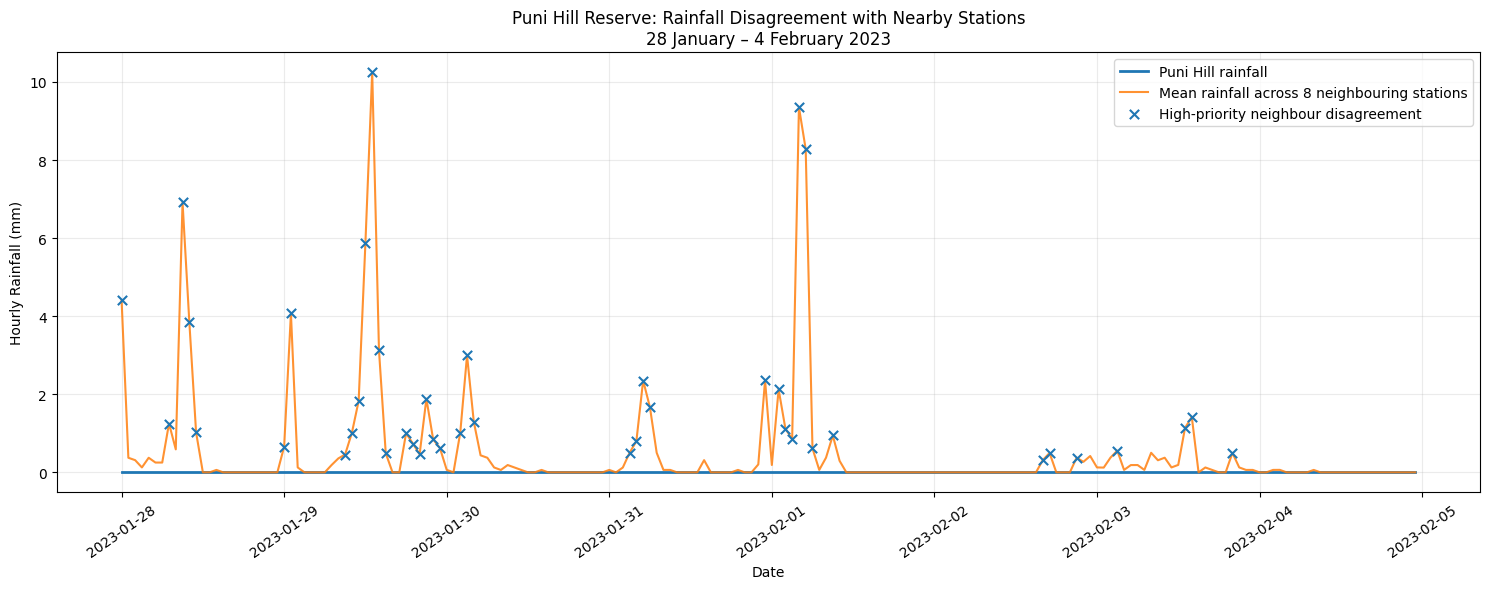

Historical rainfall comparison figure saved.


In [100]:
# STEP 46A: Historical Puni Hill rainfall disagreement plot

import matplotlib.pyplot as plt
import pandas as pd

plot_data = hourly_validation.copy()
plot_data["timestamp"] = pd.to_datetime(
    plot_data["timestamp"]
)

fig, ax = plt.subplots(figsize=(15, 6))

# Puni Hill observations
ax.plot(
    plot_data["timestamp"],
    plot_data["puni_rainfall_mm"],
    label="Puni Hill rainfall",
    linewidth=2
)

# Mean rainfall across 8 neighbours
ax.plot(
    plot_data["timestamp"],
    plot_data["neighbour_mean_mm"],
    label="Mean rainfall across 8 neighbouring stations",
    linewidth=1.5,
    alpha=0.85
)

# Mark high-priority disagreement hours
high_priority = plot_data[
    plot_data["strong_conflict_2_at_1mm"]
]

ax.scatter(
    high_priority["timestamp"],
    high_priority["neighbour_mean_mm"],
    marker="x",
    s=45,
    label="High-priority neighbour disagreement",
    zorder=4
)

ax.set_title(
    "Puni Hill Reserve: Rainfall Disagreement with Nearby Stations\n"
    "28 January – 4 February 2023"
)

ax.set_xlabel("Date")
ax.set_ylabel("Hourly Rainfall (mm)")
ax.legend()
ax.grid(alpha=0.25)

plt.xticks(rotation=35)
plt.tight_layout()

plt.savefig(
    OUTPUT_PATH / "puni_historical_rainfall_disagreement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Historical rainfall comparison figure saved.")

In [101]:
# STEP 46B: Review saved capstone output files

from pathlib import Path
import pandas as pd

files = sorted(OUTPUT_PATH.glob("*"))

file_summary = pd.DataFrame([
    {
        "filename": f.name,
        "file_type": f.suffix.lower(),
        "size_kb": round(f.stat().st_size / 1024, 2)
    }
    for f in files if f.is_file()
])

print("CAPSTONE OUTPUT INVENTORY")
print("=" * 50)
print("Total files:", len(file_summary))

display(file_summary)

print("\nCSV files:", sum(file_summary["file_type"] == ".csv"))
print("Image files:", sum(
    file_summary["file_type"].isin([".png", ".jpg", ".jpeg"])
))

CAPSTONE OUTPUT INVENTORY
Total files: 88


,filename,file_type,size_kb
0,common_test_five_models.csv,.csv,778.88
1,common_test_with_isolation_forest.csv,.csv,746.50
2,duplicate_timestamp_groups.csv,.csv,30.79
3,duplicate_timestamp_rows.csv,.csv,97.36
4,enhanced_zero_validation.csv,.csv,0.20
...,...,...,...
83,xgboost_predictions.csv,.csv,3515.22
84,zero_investigation_results.csv,.csv,34717.48
85,zero_nearby_validation_742826.csv,.csv,0.59
86,zero_same_hour_validation_742826.csv,.csv,8.65



CSV files: 85
Image files: 2


In [102]:
# STEP 46C: Audit and categorise saved capstone outputs
# Read-only: does not move, rename or delete any files

import pandas as pd
from pathlib import Path

output_files = sorted(
    f for f in OUTPUT_PATH.iterdir() if f.is_file()
)

def classify_output(filename):

    name = filename.lower()

    if any(word in name for word in [
        "six_model", "common_test", "comparison"
    ]):
        return "Model Comparison"

    elif any(word in name for word in [
        "lstm", "autoencoder"
    ]):
        return "LSTM Autoencoder"

    elif any(word in name for word in [
        "isolation", "lof", "one_class", "ocsvm",
        "random_forest", "xgboost", "svm"
    ]):
        return "Individual Model Results"

    elif any(word in name for word in [
        "synthetic", "injection", "fault"
    ]):
        return "Synthetic Fault Experiments"

    elif any(word in name for word in [
        "puni", "neighbour", "nearby",
        "historical", "zero_validation"
    ]):
        return "Historical Validation"

    elif any(word in name for word in [
        "missing", "duplicate", "eda",
        "summary", "inventory", "gap",
        "distribution", "zero", "spike"
    ]):
        return "Data Quality and EDA"

    else:
        return "Other / Review"

audit = pd.DataFrame([
    {
        "filename": f.name,
        "category": classify_output(f.name),
        "file_type": f.suffix.lower(),
        "size_kb": round(f.stat().st_size / 1024, 2)
    }
    for f in output_files
])

print("CAPSTONE OUTPUT AUDIT")
print("=" * 50)

print("Total files:", len(audit))

print("\nFILES BY CATEGORY")
display(
    audit.groupby("category")
    .size()
    .reset_index(name="file_count")
    .sort_values("file_count", ascending=False)
)

print("\nFILES REQUIRING REVIEW")
display(
    audit[audit["category"] == "Other / Review"]
)

print("\nMODEL COMPARISON FILES")
display(
    audit[audit["category"] == "Model Comparison"]
)

print("\nHISTORICAL VALIDATION FILES")
display(
    audit[audit["category"] == "Historical Validation"]
)

# Save a new inventory without changing existing results
audit.to_csv(
    OUTPUT_PATH / "capstone_output_audit.csv",
    index=False
)

print("\nOutput audit saved.")

CAPSTONE OUTPUT AUDIT
Total files: 88

FILES BY CATEGORY


,category,file_count
2,Individual Model Results,25
4,Model Comparison,18
0,Data Quality and EDA,11
5,Other / Review,11
1,Historical Validation,10
3,LSTM Autoencoder,9
6,Synthetic Fault Experiments,4



FILES REQUIRING REVIEW


,filename,category,file_type,size_kb
7,failed_files.csv,Other / Review,.csv,0.01
11,flatline_episodes.csv,Other / Review,.csv,599.71
12,flatline_review_priority.csv,Other / Review,.csv,788.96
15,full_event_model_predictions.csv,Other / Review,.csv,57.75
16,high_value_anomaly_details.csv,Other / Review,.csv,767.59
43,nearest_rainfall_stations.csv,Other / Review,.csv,2.15
56,rainfall_ml_features_initial.csv,Other / Review,.csv,13499.39
57,rainfall_ml_test.csv,Other / Review,.csv,3848.87
58,rainfall_ml_train.csv,Other / Review,.csv,9426.19
72,station_648850_event_investigation.csv,Other / Review,.csv,4.88



MODEL COMPARISON FILES


,filename,category,file_type,size_kb
0,common_test_five_models.csv,Model Comparison,.csv,778.88
1,common_test_with_isolation_forest.csv,Model Comparison,.csv,746.50
6,exact_hour_rainfall_comparison.csv,Model Comparison,.csv,1.18
8,fair_three_model_comparison.csv,Model Comparison,.csv,0.33
9,fair_three_model_fault_comparison.csv,Model Comparison,.csv,0.36
10,five_model_comparison.csv,Model Comparison,.csv,0.46
13,flood_event_model_comparison.csv,Model Comparison,.csv,0.29
14,full_event_model_comparison.csv,Model Comparison,.csv,0.24
28,lof_v1_v2_comparison.csv,Model Comparison,.csv,0.26
39,model_comparison_summary.csv,Model Comparison,.csv,0.19



HISTORICAL VALIDATION FILES


,filename,category,file_type,size_kb
4,enhanced_zero_validation.csv,Historical Validation,.csv,0.20
40,multi_station_zero_validation.csv,Historical Validation,.csv,0.99
48,puni_historical_anomaly_investigation.csv,Historical Validation,.csv,20.28
49,puni_historical_rainfall_disagreement.png,Historical Validation,.png,294.39
50,puni_hourly_neighbour_validation_2023.csv,Historical Validation,.csv,11.25
51,puni_investigation_category_summary.csv,Historical Validation,.csv,0.28
52,puni_nearest_rainfall_stations.csv,Historical Validation,.csv,0.61
53,puni_neighbour_coverage_jan2023.csv,Historical Validation,.csv,0.83
85,zero_nearby_validation_742826.csv,Historical Validation,.csv,0.59
87,zero_validation_summary_742826.csv,Historical Validation,.csv,0.15



Output audit saved.


In [103]:
# STEP 47A: Audit chronological separation
# Read-only — does not modify datasets or models

import pandas as pd

train_audit = rf_train.copy()
test_audit = rf_test.copy()

for df in [train_audit, test_audit]:
    df["station_id"] = df["station_id"].astype(str)
    df["timestamp"] = pd.to_datetime(df["timestamp"])

results = []

for station in sorted(
    set(train_audit["station_id"]) |
    set(test_audit["station_id"])
):
    train = train_audit[
        train_audit["station_id"] == station
    ]
    test = test_audit[
        test_audit["station_id"] == station
    ]

    train_times = set(train["timestamp"])
    test_times = set(test["timestamp"])

    train_end = train["timestamp"].max()
    test_start = test["timestamp"].min()

    results.append({
        "station_id": station,
        "train_rows": len(train),
        "test_rows": len(test),
        "train_start": train["timestamp"].min(),
        "train_end": train_end,
        "test_start": test_start,
        "test_end": test["timestamp"].max(),
        "train_fault_rows": int(
            train["synthetic_label"].sum()
        ),
        "test_fault_rows": int(
            test["synthetic_label"].sum()
        ),
        "overlapping_timestamps": len(
            train_times.intersection(test_times)
        ),
        "strict_chronological_split": (
            train_end < test_start
            if len(train) and len(test)
            else False
        )
    })

split_audit = pd.DataFrame(results)

print("CHRONOLOGICAL TRAIN/TEST AUDIT")
print("=" * 55)

display(split_audit)

print("\nTOTALS")

print("Training rows:", len(train_audit))
print("Testing rows:", len(test_audit))

print(
    "Training synthetic faults:",
    int(train_audit["synthetic_label"].sum())
)

print(
    "Testing synthetic faults:",
    int(test_audit["synthetic_label"].sum())
)

print(
    "Total overlapping timestamps:",
    int(split_audit["overlapping_timestamps"].sum())
)

print(
    "All stations strictly chronological:",
    bool(split_audit["strict_chronological_split"].all())
)

print("\nAudit completed.")

CHRONOLOGICAL TRAIN/TEST AUDIT


,station_id,train_rows,test_rows,train_start,train_end,test_start,test_end,train_fault_rows,test_fault_rows,overlapping_timestamps,strict_chronological_split
0,642615,13260,5684,2015-01-01 01:00:00,2016-07-06 12:00:00,2016-07-06 13:00:00,2017-02-28 08:00:00,135,65,0,True
1,648709,3670,1574,2015-01-01 01:00:00,2015-06-02 22:00:00,2015-06-02 23:00:00,2015-08-07 12:00:00,85,84,0,True
2,740601,65672,28146,2015-01-01 01:00:00,2022-10-16 06:00:00,2022-10-16 07:00:00,2026-01-01 00:00:00,395,237,0,True
3,742826,64185,27508,2015-07-17 12:00:00,2022-11-11 20:00:00,2022-11-11 21:00:00,2026-01-01 00:00:00,395,219,0,True



TOTALS
Training rows: 146787
Testing rows: 62912
Training synthetic faults: 1010
Testing synthetic faults: 605
Total overlapping timestamps: 0
All stations strictly chronological: True

Audit completed.


In [104]:
# STEP 47B: Audit time-series feature calculations
# Read-only: checks features without modifying data

import pandas as pd
import numpy as np

features_to_check = [
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours"
]

audit_data = pd.concat(
    [
        rf_train.assign(dataset="train"),
        rf_test.assign(dataset="test")
    ],
    ignore_index=True
)

audit_data["station_id"] = audit_data["station_id"].astype(str)
audit_data["timestamp"] = pd.to_datetime(
    audit_data["timestamp"]
)

audit_data = audit_data.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

results = []

for station, group in audit_data.groupby("station_id"):

    group = group.sort_values("timestamp").copy()

    # A previous observation is valid only if exactly 1 hour earlier
    time_gap = group["timestamp"].diff()

    expected_previous = (
        group["simulated_value"].shift(1)
        .where(time_gap == pd.Timedelta(hours=1))
    )

    previous_match = np.isclose(
        group["previous_value"],
        expected_previous,
        equal_nan=True,
        atol=1e-6
    )

    expected_change = (
        group["simulated_value"] - expected_previous
    )

    change_match = np.isclose(
        group["hourly_change"],
        expected_change,
        equal_nan=True,
        atol=1e-6
    )

    results.append({
        "station_id": station,
        "observations": len(group),
        "previous_value_mismatches": int(
            (~previous_match).sum()
        ),
        "hourly_change_mismatches": int(
            (~change_match).sum()
        ),
        "time_gaps_over_1_hour": int(
            (time_gap > pd.Timedelta(hours=1)).sum()
        )
    })

feature_audit = pd.DataFrame(results)

print("TIME-SERIES FEATURE AUDIT")
print("=" * 50)

display(feature_audit)

print("\nFEATURE NULL COUNTS")
display(
    audit_data[features_to_check]
    .isna()
    .sum()
    .reset_index(name="null_count")
    .rename(columns={"index": "feature"})
)

print("\nAudit completed.")

TIME-SERIES FEATURE AUDIT


,station_id,observations,previous_value_mismatches,hourly_change_mismatches,time_gaps_over_1_hour
0,642615,18944,1,1,0
1,648709,5244,1,1,0
2,740601,93818,1,1,11
3,742826,91693,1,1,0



FEATURE NULL COUNTS


,feature,null_count
0,previous_value,19
1,hourly_change,19
2,rolling_mean_24h,228
3,rolling_std_24h,228
4,consecutive_zero_hours,0



Audit completed.


In [105]:
# STEP 47C: Inspect feature mismatches and dataset boundaries

import pandas as pd
import numpy as np

data = pd.concat(
    [
        rf_train.assign(dataset="train"),
        rf_test.assign(dataset="test")
    ],
    ignore_index=True
)

data["station_id"] = data["station_id"].astype(str)
data["timestamp"] = pd.to_datetime(data["timestamp"])

data = data.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

data["time_gap"] = (
    data.groupby("station_id")["timestamp"].diff()
)

# Expected previous value from actual preceding hour
data["expected_previous"] = (
    data.groupby("station_id")["simulated_value"].shift(1)
)

data.loc[
    data["time_gap"] != pd.Timedelta(hours=1),
    "expected_previous"
] = np.nan

data["expected_change"] = (
    data["simulated_value"] - data["expected_previous"]
)

previous_mismatch = ~np.isclose(
    data["previous_value"],
    data["expected_previous"],
    equal_nan=True,
    atol=1e-6
)

change_mismatch = ~np.isclose(
    data["hourly_change"],
    data["expected_change"],
    equal_nan=True,
    atol=1e-6
)

mismatch_rows = data[
    previous_mismatch | change_mismatch
].copy()

print("FEATURE MISMATCH DETAILS")
print("=" * 50)

display(
    mismatch_rows[
        [
            "station_id",
            "dataset",
            "timestamp",
            "time_gap",
            "simulated_value",
            "previous_value",
            "expected_previous",
            "hourly_change",
            "expected_change"
        ]
    ]
)

print("\nTRAIN/TEST BOUNDARY INSPECTION")

boundary_rows = []

for station, group in data.groupby("station_id"):

    group = group.reset_index(drop=True)

    test_positions = group.index[
        group["dataset"] == "test"
    ]

    if len(test_positions) == 0:
        continue

    boundary = test_positions[0]

    start = max(0, boundary - 2)
    end = min(len(group), boundary + 3)

    boundary_rows.append(
        group.iloc[start:end][
            [
                "station_id",
                "dataset",
                "timestamp",
                "simulated_value",
                "previous_value",
                "hourly_change",
                "rolling_mean_24h",
                "rolling_std_24h",
                "consecutive_zero_hours"
            ]
        ]
    )

if boundary_rows:
    display(
        pd.concat(boundary_rows, ignore_index=True)
    )

print("\nMISMATCH SUMMARY")

print("Previous-value mismatches:", int(previous_mismatch.sum()))
print("Hourly-change mismatches:", int(change_mismatch.sum()))

print("\nInspection completed.")

FEATURE MISMATCH DETAILS


,station_id,dataset,timestamp,time_gap,simulated_value,previous_value,expected_previous,hourly_change,expected_change
13260,642615,test,2016-07-06 13:00:00,0 days 01:00:00,0.0,NaN,0.0,NaN,0.0
22614,648709,test,2015-06-02 23:00:00,0 days 01:00:00,0.0,NaN,0.0,NaN,0.0
89860,740601,test,2022-10-16 07:00:00,0 days 01:00:00,0.0,NaN,0.0,NaN,0.0
182191,742826,test,2022-11-11 21:00:00,0 days 01:00:00,0.0,NaN,0.0,NaN,0.0



TRAIN/TEST BOUNDARY INSPECTION


,station_id,dataset,timestamp,simulated_value,previous_value,hourly_change,rolling_mean_24h,rolling_std_24h,consecutive_zero_hours
0,642615,train,2016-07-06 11:00:00,0.0,0.0,0.0,0.000000,0.000000,50
1,642615,train,2016-07-06 12:00:00,0.0,0.0,0.0,0.000000,0.000000,51
2,642615,test,2016-07-06 13:00:00,0.0,NaN,NaN,NaN,NaN,1
3,642615,test,2016-07-06 14:00:00,0.0,0.0,0.0,NaN,NaN,2
4,642615,test,2016-07-06 15:00:00,0.0,0.0,0.0,NaN,NaN,3
5,648709,train,2015-06-02 21:00:00,0.0,0.0,0.0,0.354167,1.057881,9
6,648709,train,2015-06-02 22:00:00,0.0,0.0,0.0,0.354167,1.057881,10
7,648709,test,2015-06-02 23:00:00,0.0,NaN,NaN,NaN,NaN,1
8,648709,test,2015-06-03 00:00:00,0.0,0.0,0.0,NaN,NaN,2
9,648709,test,2015-06-03 01:00:00,0.0,0.0,0.0,NaN,NaN,3



MISMATCH SUMMARY
Previous-value mismatches: 4
Hourly-change mismatches: 4

Inspection completed.


In [106]:
# STEP 47D — Recalculate chronological features
# Preserves original rf_train and rf_test

import pandas as pd
import numpy as np

combined = pd.concat(
    [
        rf_train.assign(dataset="train"),
        rf_test.assign(dataset="test")
    ],
    ignore_index=True
)

combined["station_id"] = combined["station_id"].astype(str)
combined["timestamp"] = pd.to_datetime(
    combined["timestamp"]
)

combined = combined.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

assert not combined.duplicated(
    ["station_id", "timestamp"]
).any(), "Duplicate station/timestamp detected"

# Determine whether observations are exactly one hour apart
combined["time_gap"] = (
    combined.groupby("station_id")["timestamp"].diff()
)

combined["new_segment"] = (
    combined["time_gap"] != pd.Timedelta(hours=1)
)

# Create independent segments at genuine time gaps
combined["segment_id"] = (
    combined.groupby("station_id")["new_segment"]
    .cumsum()
)

group_cols = ["station_id", "segment_id"]

# Previous hour's value
combined["previous_value_corrected"] = (
    combined.groupby(group_cols)["simulated_value"].shift(1)
)

# Hourly change
combined["hourly_change_corrected"] = (
    combined["simulated_value"]
    - combined["previous_value_corrected"]
)

# Rolling statistics use current and preceding 23 hours
combined["rolling_mean_24h_corrected"] = (
    combined.groupby(group_cols)["simulated_value"]
    .transform(
        lambda s: s.rolling(
            window=24,
            min_periods=24
        ).mean()
    )
)

combined["rolling_std_24h_corrected"] = (
    combined.groupby(group_cols)["simulated_value"]
    .transform(
        lambda s: s.rolling(
            window=24,
            min_periods=24
        ).std()
    )
)

# Count consecutive observed zero readings
is_zero = combined["simulated_value"].eq(0)

# Reset the run when reading is nonzero OR missing,
# and naturally at each new time-gap segment.
run_group = (
    (~is_zero)
    .groupby([combined["station_id"], combined["segment_id"]])
    .cumsum()
)

combined["consecutive_zero_hours_corrected"] = (
    is_zero.astype(int)
    .groupby([
        combined["station_id"],
        combined["segment_id"],
        run_group
    ])
    .cumsum()
)

# Split again without changing original rows
rf_train_corrected = (
    combined[combined["dataset"] == "train"]
    .copy()
)

rf_test_corrected = (
    combined[combined["dataset"] == "test"]
    .copy()
)

# Inspect first test observation for each station
boundary_check = (
    rf_test_corrected
    .sort_values(["station_id", "timestamp"])
    .groupby("station_id")
    .head(1)
)

print("CORRECTED TRAIN/TEST BOUNDARIES")
print("=" * 55)

display(
    boundary_check[
        [
            "station_id",
            "timestamp",
            "simulated_value",
            "previous_value",
            "previous_value_corrected",
            "consecutive_zero_hours",
            "consecutive_zero_hours_corrected",
            "rolling_mean_24h_corrected",
            "rolling_std_24h_corrected"
        ]
    ]
)

print("\nDATASET ROW COUNTS")

print(
    "Original training:", len(rf_train),
    "| Corrected training:", len(rf_train_corrected)
)

print(
    "Original testing:", len(rf_test),
    "| Corrected testing:", len(rf_test_corrected)
)

print("\nFeature recalculation completed.")

CORRECTED TRAIN/TEST BOUNDARIES


,station_id,timestamp,simulated_value,previous_value,previous_value_corrected,consecutive_zero_hours,consecutive_zero_hours_corrected,rolling_mean_24h_corrected,rolling_std_24h_corrected
13260,642615,2016-07-06 13:00:00,0.0,NaN,0.0,1,52,0.000000,0.000000
22614,648709,2015-06-02 23:00:00,0.0,NaN,0.0,1,11,0.291667,1.031216
89860,740601,2022-10-16 07:00:00,0.0,NaN,0.0,1,48,0.000000,0.000000
182191,742826,2022-11-11 21:00:00,0.0,NaN,0.0,1,11,0.583333,0.994102



DATASET ROW COUNTS
Original training: 146787 | Corrected training: 146787
Original testing: 62912 | Corrected testing: 62912

Feature recalculation completed.


In [107]:
# STEP 47E: Compare original and corrected features
# Read-only audit; does not retrain or overwrite models

import pandas as pd
import numpy as np

feature_pairs = {
    "previous_value": "previous_value_corrected",
    "hourly_change": "hourly_change_corrected",
    "rolling_mean_24h": "rolling_mean_24h_corrected",
    "rolling_std_24h": "rolling_std_24h_corrected",
    "consecutive_zero_hours": "consecutive_zero_hours_corrected"
}

comparison_rows = []

for station, group in combined.groupby("station_id"):

    for original, corrected in feature_pairs.items():

        old = pd.to_numeric(group[original], errors="coerce")
        new = pd.to_numeric(group[corrected], errors="coerce")

        matches = np.isclose(
            old.to_numpy(),
            new.to_numpy(),
            atol=1e-6,
            rtol=1e-6,
            equal_nan=True
        )

        comparison_rows.append({
            "station_id": station,
            "feature": original,
            "total_rows": len(group),
            "matching_rows": int(matches.sum()),
            "changed_rows": int((~matches).sum()),
            "original_nulls": int(old.isna().sum()),
            "corrected_nulls": int(new.isna().sum())
        })

feature_comparison = pd.DataFrame(comparison_rows)

print("ORIGINAL VS CORRECTED FEATURES")
print("=" * 55)

display(feature_comparison)

print("\nTOTAL CHANGES BY FEATURE")

feature_change_summary = (
    feature_comparison.groupby("feature")
    .agg(
        changed_rows=("changed_rows", "sum"),
        original_nulls=("original_nulls", "sum"),
        corrected_nulls=("corrected_nulls", "sum")
    )
    .reset_index()
)

display(feature_change_summary)

print("\nAUDIT COMPLETED")

ORIGINAL VS CORRECTED FEATURES


,station_id,feature,total_rows,matching_rows,changed_rows,original_nulls,corrected_nulls
0,642615,previous_value,18944,18943,1,2,1
1,642615,hourly_change,18944,18943,1,2,1
2,642615,rolling_mean_24h,18944,9526,9418,24,23
3,642615,rolling_std_24h,18944,9542,9402,24,23
4,642615,consecutive_zero_hours,18944,18924,20,0,0
5,648709,previous_value,5244,5243,1,2,1
6,648709,hourly_change,5244,5243,1,2,1
7,648709,rolling_mean_24h,5244,4519,725,24,23
8,648709,rolling_std_24h,5244,4519,725,24,23
9,648709,consecutive_zero_hours,5244,5002,242,0,0



TOTAL CHANGES BY FEATURE


,feature,changed_rows,original_nulls,corrected_nulls
0,consecutive_zero_hours,305,0,0
1,hourly_change,4,19,15
2,previous_value,4,19,15
3,rolling_mean_24h,38775,228,342
4,rolling_std_24h,38721,228,342



AUDIT COMPLETED


In [108]:
# STEP 47F: Diagnose rolling feature differences
# Read-only — no model retraining

import pandas as pd
import numpy as np

data = combined.copy()

data["station_id"] = data["station_id"].astype(str)
data["timestamp"] = pd.to_datetime(data["timestamp"])

# Compare original and corrected rolling mean
mean_match = np.isclose(
    data["rolling_mean_24h"],
    data["rolling_mean_24h_corrected"],
    rtol=1e-6,
    atol=1e-6,
    equal_nan=True
)

# Compare original and corrected rolling standard deviation
std_match = np.isclose(
    data["rolling_std_24h"],
    data["rolling_std_24h_corrected"],
    rtol=1e-6,
    atol=1e-6,
    equal_nan=True
)

data["mean_difference"] = (
    data["rolling_mean_24h"]
    - data["rolling_mean_24h_corrected"]
)

data["std_difference"] = (
    data["rolling_std_24h"]
    - data["rolling_std_24h_corrected"]
)

print("ROLLING FEATURE DIFFERENCE INVESTIGATION")
print("=" * 55)

# Focus on differences where both values are numeric
both_mean_valid = (
    data["rolling_mean_24h"].notna()
    & data["rolling_mean_24h_corrected"].notna()
)

both_std_valid = (
    data["rolling_std_24h"].notna()
    & data["rolling_std_24h_corrected"].notna()
)

print("\nROLLING MEAN")
print(
    "Different numeric values:",
    int((~mean_match & both_mean_valid).sum())
)

print(
    "Maximum absolute difference:",
    data["mean_difference"].abs().max()
)

print(
    "Median absolute difference among mismatches:",
    data.loc[
        ~mean_match & both_mean_valid,
        "mean_difference"
    ].abs().median()
)

print("\nROLLING STANDARD DEVIATION")
print(
    "Different numeric values:",
    int((~std_match & both_std_valid).sum())
)

print(
    "Maximum absolute difference:",
    data["std_difference"].abs().max()
)

print(
    "Median absolute difference among mismatches:",
    data.loc[
        ~std_match & both_std_valid,
        "std_difference"
    ].abs().median()
)

print("\nFIRST 15 ROLLING-MEAN MISMATCHES")

display(
    data.loc[
        ~mean_match & both_mean_valid,
        [
            "station_id",
            "dataset",
            "timestamp",
            "simulated_value",
            "rolling_mean_24h",
            "rolling_mean_24h_corrected",
            "mean_difference"
        ]
    ].head(15)
)

print("\nLARGEST 10 ROLLING-MEAN DIFFERENCES")

display(
    data.loc[
        ~mean_match & both_mean_valid,
        [
            "station_id",
            "dataset",
            "timestamp",
            "simulated_value",
            "rolling_mean_24h",
            "rolling_mean_24h_corrected",
            "mean_difference"
        ]
    ].assign(
        absolute_difference=lambda x:
            x["mean_difference"].abs()
    ).sort_values(
        "absolute_difference",
        ascending=False
    ).head(10)
)

print("\nDiagnostic completed.")

ROLLING FEATURE DIFFERENCE INVESTIGATION

ROLLING MEAN
Different numeric values: 38565
Maximum absolute difference: 6.3080148949069725
Median absolute difference among mismatches: 0.021666666666666612

ROLLING STANDARD DEVIATION
Different numeric values: 38511
Maximum absolute difference: 30.592970933690285
Median absolute difference among mismatches: 0.01385020539441939

FIRST 15 ROLLING-MEAN MISMATCHES


,station_id,dataset,timestamp,simulated_value,rolling_mean_24h,rolling_mean_24h_corrected,mean_difference
23,642615,train,2015-01-02 00:00:00,0.00,0.014638,0.014028,0.000610
24,642615,train,2015-01-02 01:00:00,0.00,0.014028,0.012274,0.001753
25,642615,train,2015-01-02 02:00:00,0.00,0.012274,0.010521,0.001753
26,642615,train,2015-01-02 03:00:00,0.00,0.010521,0.008767,0.001753
27,642615,train,2015-01-02 04:00:00,0.00,0.008767,0.007014,0.001753
28,642615,train,2015-01-02 05:00:00,0.00,0.007014,0.005260,0.001753
29,642615,train,2015-01-02 06:00:00,0.00,0.005260,0.003507,0.001753
30,642615,train,2015-01-02 07:00:00,0.00,0.003507,0.001753,0.001753
31,642615,train,2015-01-02 08:00:00,0.00,0.001753,0.000000,0.001753
392,642615,train,2015-01-17 09:00:00,0.35,0.000000,0.014583,-0.014583



LARGEST 10 ROLLING-MEAN DIFFERENCES


,station_id,dataset,timestamp,simulated_value,rolling_mean_24h,rolling_mean_24h_corrected,mean_difference,absolute_difference
179092,742826,train,2022-07-05 18:00:00,151.392357,0.702858,7.010873,-6.308015,6.308015
179116,742826,train,2022-07-06 18:00:00,0.000000,7.407068,1.099053,6.308015,6.308015
43718,740601,train,2017-03-24 19:00:00,149.874337,0.000000,6.244764,-6.244764,6.244764
43742,740601,train,2017-03-25 19:00:00,0.000000,6.286431,0.041667,6.244764,6.244764
60534,740601,train,2019-03-24 08:00:00,149.758004,0.000000,6.239917,-6.239917,6.239917
60558,740601,train,2019-03-25 08:00:00,0.000000,6.239917,0.000000,6.239917,6.239917
131484,742826,train,2017-01-29 02:00:00,0.000000,6.236155,0.000000,6.236155,6.236155
131460,742826,train,2017-01-28 02:00:00,149.667721,0.000000,6.236155,-6.236155,6.236155
68839,740601,train,2020-05-13 18:00:00,0.000000,6.251519,0.020417,6.231102,6.231102
68815,740601,train,2020-05-12 18:00:00,149.546447,0.000000,6.231102,-6.231102,6.231102



Diagnostic completed.


In [109]:
# STEP 47G: Verify historical rolling feature definition
# Read-only; preserves all original datasets

import pandas as pd
import numpy as np

check = combined.copy()

group_cols = ["station_id", "segment_id"]

# Previous 24 observations, excluding current hour
check["historical_mean_24h"] = (
    check.groupby(group_cols)["simulated_value"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=24,
            min_periods=24
        ).mean()
    )
)

check["historical_std_24h"] = (
    check.groupby(group_cols)["simulated_value"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=24,
            min_periods=24
        ).std()
    )
)

# Compare with original features
mean_match = np.isclose(
    check["rolling_mean_24h"],
    check["historical_mean_24h"],
    atol=1e-6,
    rtol=1e-6,
    equal_nan=True
)

std_match = np.isclose(
    check["rolling_std_24h"],
    check["historical_std_24h"],
    atol=1e-6,
    rtol=1e-6,
    equal_nan=True
)

comparison = pd.DataFrame({
    "feature": ["Rolling mean", "Rolling standard deviation"],
    "matching_rows": [
        int(mean_match.sum()),
        int(std_match.sum())
    ],
    "mismatching_rows": [
        int((~mean_match).sum()),
        int((~std_match).sum())
    ],
    "match_percentage": [
        round(100 * mean_match.mean(), 2),
        round(100 * std_match.mean(), 2)
    ]
})

print("HISTORICAL ROLLING-WINDOW VERIFICATION")
print("=" * 55)

display(comparison)

print("\nMISMATCHES BY DATASET")

for dataset_name, subset in check.groupby("dataset"):

    idx = subset.index

    print(
        dataset_name,
        "| Mean mismatches:",
        int((~mean_match[idx]).sum()),
        "| Std mismatches:",
        int((~std_match[idx]).sum())
    )

print("\nEXAMPLE: LARGE SYNTHETIC SPIKE")

example = check[
    (check["station_id"] == "740601") &
    (check["timestamp"] >= "2017-03-24 17:00:00") &
    (check["timestamp"] <= "2017-03-24 21:00:00")
]

display(
    example[
        [
            "timestamp",
            "simulated_value",
            "rolling_mean_24h",
            "historical_mean_24h",
            "rolling_std_24h",
            "historical_std_24h"
        ]
    ]
)

print("\nVerification completed.")

HISTORICAL ROLLING-WINDOW VERIFICATION


,feature,matching_rows,mismatching_rows,match_percentage
0,Rolling mean,209458,241,99.89
1,Rolling standard deviation,209458,241,99.89



MISMATCHES BY DATASET
test | Mean mismatches: 65 | Std mismatches: 65
train | Mean mismatches: 176 | Std mismatches: 176

EXAMPLE: LARGE SYNTHETIC SPIKE


,timestamp,simulated_value,rolling_mean_24h,historical_mean_24h,rolling_std_24h,historical_std_24h
43716,2017-03-24 17:00:00,0.000000,0.000000,0.000000,0.000000,0.000000
43717,2017-03-24 18:00:00,0.000000,0.000000,0.000000,0.000000,0.000000
43718,2017-03-24 19:00:00,149.874337,0.000000,0.000000,0.000000,0.000000
43719,2017-03-24 20:00:00,0.000000,6.244764,6.244764,30.592971,30.592971
43720,2017-03-24 21:00:00,0.000000,6.244764,6.244764,30.592971,30.592971



Verification completed.


In [110]:
# STEP 47H: Diagnose remaining historical rolling mismatches
# Read-only: does not change model datasets

import numpy as np
import pandas as pd

check = check.copy()

mean_mismatch = ~np.isclose(
    check["rolling_mean_24h"],
    check["historical_mean_24h"],
    atol=1e-6,
    rtol=1e-6,
    equal_nan=True
)

std_mismatch = ~np.isclose(
    check["rolling_std_24h"],
    check["historical_std_24h"],
    atol=1e-6,
    rtol=1e-6,
    equal_nan=True
)

check["rolling_mismatch"] = (
    mean_mismatch | std_mismatch
)

# First hour in each train/test partition
check["partition_position"] = (
    check.groupby(["station_id", "dataset"])
    .cumcount()
)

# Position within each uninterrupted hourly segment
check["segment_position"] = (
    check.groupby(["station_id", "segment_id"])
    .cumcount()
)

mismatches = check[
    check["rolling_mismatch"]
].copy()

print("ROLLING MISMATCH DIAGNOSIS")
print("=" * 55)

print("Total mismatching rows:", len(mismatches))

print("\nBY STATION AND DATASET")

display(
    mismatches.groupby(
        ["station_id", "dataset"]
    ).size().reset_index(name="mismatches")
)

print("\nMISMATCHES NEAR TRAIN/TEST BOUNDARIES")

print(
    "Within first 24 test observations:",
    int((
        (mismatches["dataset"] == "test") &
        (mismatches["partition_position"] < 24)
    ).sum())
)

print("\nMISMATCHES NEAR TIME GAPS")

print(
    "Within first 25 hours of a continuous segment:",
    int((
        mismatches["segment_position"] < 25
    ).sum())
)

print("\nFIRST 20 MISMATCHES")

display(
    mismatches[
        [
            "station_id",
            "dataset",
            "timestamp",
            "segment_position",
            "partition_position",
            "simulated_value",
            "rolling_mean_24h",
            "historical_mean_24h",
            "rolling_std_24h",
            "historical_std_24h"
        ]
    ].head(20)
)

print("\nLAST 20 MISMATCHES")

display(
    mismatches[
        [
            "station_id",
            "dataset",
            "timestamp",
            "segment_position",
            "partition_position",
            "simulated_value",
            "rolling_mean_24h",
            "historical_mean_24h"
        ]
    ].tail(20)
)

print("\nDiagnostic completed.")

ROLLING MISMATCH DIAGNOSIS
Total mismatching rows: 241

BY STATION AND DATASET


,station_id,dataset,mismatches
0,642615,test,15
1,642615,train,12
2,648709,test,14
3,648709,train,12
4,740601,test,12
5,740601,train,140
6,742826,test,24
7,742826,train,12



MISMATCHES NEAR TRAIN/TEST BOUNDARIES
Within first 24 test observations: 65

MISMATCHES NEAR TIME GAPS
Within first 25 hours of a continuous segment: 176

FIRST 20 MISMATCHES


,station_id,dataset,timestamp,segment_position,partition_position,simulated_value,rolling_mean_24h,historical_mean_24h,rolling_std_24h,historical_std_24h
12,642615,train,2015-01-01 13:00:00,12,12,0.0,0.028056,NaN,0.020720,NaN
13,642615,train,2015-01-01 14:00:00,13,13,0.0,0.025897,NaN,0.021310,NaN
14,642615,train,2015-01-01 15:00:00,14,14,0.0,0.024048,NaN,0.021612,NaN
15,642615,train,2015-01-01 16:00:00,15,15,0.0,0.022444,NaN,0.021732,NaN
16,642615,train,2015-01-01 17:00:00,16,16,0.0,0.021042,NaN,0.021732,NaN
17,642615,train,2015-01-01 18:00:00,17,17,0.0,0.019804,NaN,0.021652,NaN
18,642615,train,2015-01-01 19:00:00,18,18,0.0,0.018704,NaN,0.021518,NaN
19,642615,train,2015-01-01 20:00:00,19,19,0.0,0.017719,NaN,0.021347,NaN
20,642615,train,2015-01-01 21:00:00,20,20,0.0,0.016833,NaN,0.021152,NaN
21,642615,train,2015-01-01 22:00:00,21,21,0.0,0.016032,NaN,0.020941,NaN



LAST 20 MISMATCHES


,station_id,dataset,timestamp,segment_position,partition_position,simulated_value,rolling_mean_24h,historical_mean_24h
182195,742826,test,2022-11-12 01:00:00,64189,4,0.000000,NaN,0.583333
182196,742826,test,2022-11-12 02:00:00,64190,5,0.510000,NaN,0.475892
182197,742826,test,2022-11-12 03:00:00,64191,6,0.000000,NaN,0.432083
182198,742826,test,2022-11-12 04:00:00,64192,7,0.000000,NaN,0.367083
182199,742826,test,2022-11-12 05:00:00,64193,8,0.000000,NaN,0.367083
182200,742826,test,2022-11-12 06:00:00,64194,9,0.000000,NaN,0.302083
182201,742826,test,2022-11-12 07:00:00,64195,10,0.000000,NaN,0.259167
182202,742826,test,2022-11-12 08:00:00,64196,11,0.000000,NaN,0.259167
182203,742826,test,2022-11-12 09:00:00,64197,12,0.000000,0.042500,0.237500
182204,742826,test,2022-11-12 10:00:00,64198,13,0.000000,0.039231,0.172500



Diagnostic completed.


In [111]:
# STEP 47I: Prepare corrected ML feature datasets
# Preserve original datasets and model results

import pandas as pd
import numpy as np

final_features = check.copy()

# Replace model features with corrected definitions
corrections = {
    "previous_value": "previous_value_corrected",
    "hourly_change": "hourly_change_corrected",
    "rolling_mean_24h": "historical_mean_24h",
    "rolling_std_24h": "historical_std_24h",
    "consecutive_zero_hours": "consecutive_zero_hours_corrected"
}

for original, corrected in corrections.items():
    final_features[original] = final_features[corrected]

# Keep the same original feature names expected by the models
rf_train_final = final_features[
    final_features["dataset"] == "train"
].copy()

rf_test_final = final_features[
    final_features["dataset"] == "test"
].copy()

# Verify sizes and synthetic labels are unchanged
assert len(rf_train_final) == len(rf_train)
assert len(rf_test_final) == len(rf_test)

assert (
    rf_train_final["synthetic_label"].sum()
    == rf_train["synthetic_label"].sum()
)

assert (
    rf_test_final["synthetic_label"].sum()
    == rf_test["synthetic_label"].sum()
)

# Check for accidental duplicate timestamps
assert not rf_train_final.duplicated(
    ["station_id", "timestamp"]
).any()

assert not rf_test_final.duplicated(
    ["station_id", "timestamp"]
).any()

print("FINAL FEATURE DATASETS")
print("=" * 50)

print("Training observations:", len(rf_train_final))
print("Testing observations:", len(rf_test_final))

print("\nSYNTHETIC FAULT LABELS")

print(
    "Training faults:",
    int(rf_train_final["synthetic_label"].sum())
)

print(
    "Testing faults:",
    int(rf_test_final["synthetic_label"].sum())
)

print("\nFINAL FEATURE NULL COUNTS")

display(
    pd.DataFrame({
        "feature": list(corrections),
        "train_nulls": [
            int(rf_train_final[c].isna().sum())
            for c in corrections
        ],
        "test_nulls": [
            int(rf_test_final[c].isna().sum())
            for c in corrections
        ]
    })
)

print("\nFINAL TRAIN/TEST BOUNDARY VALUES")

display(
    rf_test_final.sort_values(
        ["station_id", "timestamp"]
    ).groupby("station_id").head(1)[
        [
            "station_id",
            "timestamp",
            "previous_value",
            "hourly_change",
            "rolling_mean_24h",
            "rolling_std_24h",
            "consecutive_zero_hours"
        ]
    ]
)

print("\nFinal feature preparation completed.")

FINAL FEATURE DATASETS
Training observations: 146787
Testing observations: 62912

SYNTHETIC FAULT LABELS
Training faults: 1010
Testing faults: 605

FINAL FEATURE NULL COUNTS


,feature,train_nulls,test_nulls
0,previous_value,15,0
1,hourly_change,15,0
2,rolling_mean_24h,356,0
3,rolling_std_24h,356,0
4,consecutive_zero_hours,0,0



FINAL TRAIN/TEST BOUNDARY VALUES


,station_id,timestamp,previous_value,hourly_change,rolling_mean_24h,rolling_std_24h,consecutive_zero_hours
13260,642615,2016-07-06 13:00:00,0.0,0.0,0.000000,0.000000,52
22614,648709,2015-06-02 23:00:00,0.0,0.0,0.354167,1.057881,11
89860,740601,2022-10-16 07:00:00,0.0,0.0,0.000000,0.000000,48
182191,742826,2022-11-11 21:00:00,0.0,0.0,0.583333,0.994102,11



Final feature preparation completed.


In [112]:
# STEP 48A: Chronological training / validation / testing split
# Uses corrected feature data and preserves existing experiments

import pandas as pd
import numpy as np

ml_data = pd.concat(
    [rf_train_final, rf_test_final],
    ignore_index=True
)

ml_data["station_id"] = ml_data["station_id"].astype(str)
ml_data["timestamp"] = pd.to_datetime(ml_data["timestamp"])

ml_data = ml_data.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

assert not ml_data.duplicated(
    ["station_id", "timestamp"]
).any()

split_parts = []
split_summary = []

for station, group in ml_data.groupby("station_id", sort=True):

    group = group.sort_values("timestamp").copy()

    n = len(group)

    train_end = int(n * 0.70)
    validation_end = int(n * 0.85)

    group["final_split"] = "test"

    group.iloc[
        :train_end,
        group.columns.get_loc("final_split")
    ] = "train"

    group.iloc[
        train_end:validation_end,
        group.columns.get_loc("final_split")
    ] = "validation"

    for split_name in ["train", "validation", "test"]:

        section = group[
            group["final_split"] == split_name
        ]

        split_summary.append({
            "station_id": station,
            "split": split_name,
            "observations": len(section),
            "start": section["timestamp"].min(),
            "end": section["timestamp"].max(),
            "synthetic_fault_readings": int(
                section["synthetic_label"].sum()
            )
        })

    split_parts.append(group)

final_ml_data = pd.concat(
    split_parts,
    ignore_index=True
)

final_train = final_ml_data[
    final_ml_data["final_split"] == "train"
].copy()

final_validation = final_ml_data[
    final_ml_data["final_split"] == "validation"
].copy()

final_test = final_ml_data[
    final_ml_data["final_split"] == "test"
].copy()

final_split_summary = pd.DataFrame(split_summary)

print("CHRONOLOGICAL 70/15/15 SPLIT")
print("=" * 55)

display(final_split_summary)

print("\nDATASET TOTALS")

print("Training:", len(final_train))
print("Validation:", len(final_validation))
print("Testing:", len(final_test))

print(
    "Total:",
    len(final_train) + len(final_validation) + len(final_test)
)

assert (
    len(final_train) + len(final_validation) + len(final_test)
    == len(ml_data)
)

# Verify chronological ordering
for station, group in final_ml_data.groupby("station_id"):

    train = group[group["final_split"] == "train"]
    validation = group[group["final_split"] == "validation"]
    test = group[group["final_split"] == "test"]

    assert train["timestamp"].max() < validation["timestamp"].min()
    assert validation["timestamp"].max() < test["timestamp"].min()

print("\nChronological split verified successfully.")

CHRONOLOGICAL 70/15/15 SPLIT


,station_id,split,observations,start,end,synthetic_fault_readings
0,642615,train,13260,2015-01-01 01:00:00,2016-07-06 12:00:00,135
1,642615,validation,2842,2016-07-06 13:00:00,2016-11-01 22:00:00,27
2,642615,test,2842,2016-11-01 23:00:00,2017-02-28 08:00:00,38
3,648709,train,3670,2015-01-01 01:00:00,2015-06-02 22:00:00,85
4,648709,validation,787,2015-06-02 23:00:00,2015-07-05 17:00:00,6
5,648709,test,787,2015-07-05 18:00:00,2015-08-07 12:00:00,78
6,740601,train,65672,2015-01-01 01:00:00,2022-10-16 06:00:00,395
7,740601,validation,14073,2022-10-16 07:00:00,2024-05-24 15:00:00,114
8,740601,test,14073,2024-05-24 16:00:00,2026-01-01 00:00:00,123
9,742826,train,64185,2015-07-17 12:00:00,2022-11-11 20:00:00,395



DATASET TOTALS
Training: 146787
Validation: 31456
Testing: 31456
Total: 209699

Chronological split verified successfully.


In [113]:
# STEP 48B: Audit synthetic fault types and episode boundaries
# Read-only — no model training or modification

import pandas as pd
import numpy as np

audit_df = final_ml_data.copy()

audit_df["timestamp"] = pd.to_datetime(audit_df["timestamp"])
audit_df["station_id"] = audit_df["station_id"].astype(str)

print("SYNTHETIC FAULT TYPES BY STATION AND SPLIT")
print("=" * 55)

fault_distribution = (
    audit_df[audit_df["synthetic_label"] == 1]
    .groupby(["station_id", "final_split", "fault_type"])
    .size()
    .reset_index(name="fault_readings")
)

display(fault_distribution)

print("\nFAULT EPISODE AUDIT")

# Identify consecutive modified readings of the same fault type
audit_df = audit_df.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

is_fault = audit_df["synthetic_label"].eq(1)

new_episode = (
    audit_df["station_id"].ne(audit_df["station_id"].shift())
    | audit_df["timestamp"].diff().ne(pd.Timedelta(hours=1))
    | audit_df["fault_type"].ne(audit_df["fault_type"].shift())
    | ~is_fault
    | ~is_fault.shift(fill_value=False)
)

audit_df["episode_id"] = new_episode.cumsum()

episodes = (
    audit_df[is_fault]
    .groupby("episode_id")
    .agg(
        station_id=("station_id", "first"),
        fault_type=("fault_type", "first"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        duration_hours=("timestamp", "size"),
        first_split=("final_split", "first"),
        last_split=("final_split", "last"),
        partitions=("final_split", "nunique")
    )
    .reset_index()
)

print("Total synthetic fault episodes:", len(episodes))

cross_boundary = episodes[
    episodes["partitions"] > 1
]

print(
    "Episodes crossing partition boundaries:",
    len(cross_boundary)
)

display(cross_boundary)

print("\nEPISODES BY FAULT TYPE")

display(
    episodes.groupby("fault_type")
    .agg(
        episodes=("episode_id", "size"),
        total_fault_hours=("duration_hours", "sum"),
        median_duration_hours=("duration_hours", "median"),
        max_duration_hours=("duration_hours", "max")
    )
    .reset_index()
)

print("\nAudit completed.")

SYNTHETIC FAULT TYPES BY STATION AND SPLIT


,station_id,final_split,fault_type,fault_readings
0,642615,test,Stuck at Zero,23
1,642615,test,Synthetic Spike,15
2,642615,train,Flatline,23
3,642615,train,Stuck at Zero,46
4,642615,train,Synthetic Spike,66
5,642615,validation,Stuck at Zero,14
6,642615,validation,Synthetic Spike,13
7,648709,test,Flatline,55
8,648709,test,Stuck at Zero,22
9,648709,test,Synthetic Spike,1



FAULT EPISODE AUDIT
Total synthetic fault episodes: 1130
Episodes crossing partition boundaries: 0


,episode_id,station_id,fault_type,start,end,duration_hours,first_split,last_split,partitions



EPISODES BY FAULT TYPE


,fault_type,episodes,total_fault_hours,median_duration_hours,max_duration_hours
0,Flatline,37,333,9.0,23
1,Stuck at Zero,54,242,2.5,19
2,Synthetic Spike,1039,1040,1.0,2



Audit completed.


In [116]:
# STEP 48D: Verify original vs simulated rainfall values
# No merge required; read-only diagnostic

import pandas as pd
import numpy as np

data_check = final_ml_data.copy()

print("ORIGINAL RAINFALL DATA VERIFICATION")
print("=" * 55)

print("Total observations:", len(data_check))

print(
    "Original values available:",
    int(data_check["original_value"].notna().sum())
)

print(
    "Original values missing:",
    int(data_check["original_value"].isna().sum())
)

# Identify rows with injected synthetic faults
fault_rows = data_check[
    data_check["synthetic_label"] == 1
].copy()

print("\nSYNTHETIC FAULT VERIFICATION")

print("Injected fault readings:", len(fault_rows))

print(
    "Injected readings with original value:",
    int(fault_rows["original_value"].notna().sum())
)

print(
    "Injected readings missing original value:",
    int(fault_rows["original_value"].isna().sum())
)

# Confirm synthetic injections actually changed values
values_changed = ~np.isclose(
    fault_rows["original_value"],
    fault_rows["simulated_value"],
    atol=1e-9,
    rtol=1e-9,
    equal_nan=True
)

print(
    "Injected readings with changed values:",
    int(values_changed.sum())
)

print(
    "Injected readings without numerical change:",
    int((~values_changed).sum())
)

# Check whether unmodified rows preserved original values
unmodified = data_check[
    data_check["synthetic_label"] == 0
]

unchanged_matches = np.isclose(
    unmodified["original_value"],
    unmodified["simulated_value"],
    atol=1e-9,
    rtol=1e-9,
    equal_nan=True
)

print("\nUNMODIFIED READING VERIFICATION")

print("Unmodified readings:", len(unmodified))

print(
    "Unmodified readings matching original:",
    int(unchanged_matches.sum())
)

print(
    "Unmodified readings unexpectedly changed:",
    int((~unchanged_matches).sum())
)

print("\nPUNI HILL — SAMPLE OF INJECTED FAULTS")

display(
    fault_rows[
        fault_rows["station_id"].astype(str) == "742826"
    ][
        [
            "timestamp",
            "original_value",
            "simulated_value",
            "fault_type",
            "synthetic_label"
        ]
    ].head(15)
)

print("\nVerification completed.")

ORIGINAL RAINFALL DATA VERIFICATION
Total observations: 209699
Original values available: 209699
Original values missing: 0

SYNTHETIC FAULT VERIFICATION
Injected fault readings: 1615
Injected readings with original value: 1615
Injected readings missing original value: 0
Injected readings with changed values: 1615
Injected readings without numerical change: 0

UNMODIFIED READING VERIFICATION
Unmodified readings: 208084
Unmodified readings matching original: 208084
Unmodified readings unexpectedly changed: 0

PUNI HILL — SAMPLE OF INJECTED FAULTS


,timestamp,original_value,simulated_value,fault_type,synthetic_label
118112,2015-07-21 22:00:00,0.0,67.196035,Synthetic Spike,1.0
118203,2015-07-25 17:00:00,0.0,136.080097,Synthetic Spike,1.0
118213,2015-07-26 03:00:00,0.0,139.303102,Synthetic Spike,1.0
118555,2015-08-09 09:00:00,0.0,66.058831,Synthetic Spike,1.0
118658,2015-08-13 16:00:00,0.0,118.041881,Synthetic Spike,1.0
118802,2015-08-19 16:00:00,0.0,98.293839,Synthetic Spike,1.0
119165,2015-09-03 19:00:00,0.0,70.837934,Synthetic Spike,1.0
119486,2015-09-17 04:00:00,0.0,75.742236,Synthetic Spike,1.0
119522,2015-09-18 16:00:00,0.0,99.641748,Synthetic Spike,1.0
119934,2015-10-05 20:00:00,0.0,61.750438,Synthetic Spike,1.0



Verification completed.


In [117]:
# STEP 48E: Prepare clean data for revised synthetic experiment
# Does not overwrite earlier datasets

import pandas as pd
import numpy as np

clean_ml_data = final_ml_data[
    [
        "station_id",
        "timestamp",
        "original_value",
        "final_split"
    ]
].copy()

clean_ml_data["station_id"] = (
    clean_ml_data["station_id"].astype(str)
)

clean_ml_data["timestamp"] = pd.to_datetime(
    clean_ml_data["timestamp"]
)

clean_ml_data = clean_ml_data.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

# Start from original measurements
clean_ml_data["simulated_value"] = (
    clean_ml_data["original_value"].copy()
)

# Fault state vs numerical modification
clean_ml_data["fault_active"] = 0
clean_ml_data["synthetic_label"] = 0

clean_ml_data["fault_type"] = pd.NA
clean_ml_data["fault_episode_id"] = pd.NA

# Keep historical Puni Hill case free from new injections
protected_period = (
    (clean_ml_data["station_id"] == "742826") &
    (clean_ml_data["timestamp"] >= "2023-01-27") &
    (clean_ml_data["timestamp"] < "2023-02-16")
)

clean_ml_data["protected_historical_period"] = (
    protected_period
)

print("CLEAN DATASET PREPARATION")
print("=" * 55)

print("Total observations:", len(clean_ml_data))

print(
    "Original values available:",
    int(clean_ml_data["original_value"].notna().sum())
)

print(
    "Initial active faults:",
    int(clean_ml_data["fault_active"].sum())
)

print(
    "Initial modified readings:",
    int(clean_ml_data["synthetic_label"].sum())
)

print(
    "Protected Puni Hill observations:",
    int(clean_ml_data["protected_historical_period"].sum())
)

print("\nCLEAN PARTITIONS")

clean_split_summary = (
    clean_ml_data.groupby(["station_id", "final_split"])
    .agg(
        observations=("timestamp", "size"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        protected_hours=("protected_historical_period", "sum")
    )
    .reset_index()
)

display(clean_split_summary)

assert len(clean_ml_data) == 209699

assert (
    clean_ml_data["original_value"].notna().all()
)

assert np.allclose(
    clean_ml_data["original_value"],
    clean_ml_data["simulated_value"]
)

assert clean_ml_data["fault_active"].sum() == 0
assert clean_ml_data["synthetic_label"].sum() == 0

assert not clean_ml_data.duplicated(
    ["station_id", "timestamp"]
).any()

print("\nClean experiment preparation verified!")

CLEAN DATASET PREPARATION
Total observations: 209699
Original values available: 209699
Initial active faults: 0
Initial modified readings: 0
Protected Puni Hill observations: 480

CLEAN PARTITIONS


,station_id,final_split,observations,start,end,protected_hours
0,642615,test,2842,2016-11-01 23:00:00,2017-02-28 08:00:00,0
1,642615,train,13260,2015-01-01 01:00:00,2016-07-06 12:00:00,0
2,642615,validation,2842,2016-07-06 13:00:00,2016-11-01 22:00:00,0
3,648709,test,787,2015-07-05 18:00:00,2015-08-07 12:00:00,0
4,648709,train,3670,2015-01-01 01:00:00,2015-06-02 22:00:00,0
5,648709,validation,787,2015-06-02 23:00:00,2015-07-05 17:00:00,0
6,740601,test,14073,2024-05-24 16:00:00,2026-01-01 00:00:00,0
7,740601,train,65672,2015-01-01 01:00:00,2022-10-16 06:00:00,0
8,740601,validation,14073,2022-10-16 07:00:00,2024-05-24 15:00:00,0
9,742826,test,13754,2024-06-06 23:00:00,2026-01-01 00:00:00,0



Clean experiment preparation verified!


In [118]:
# STEP 48F: Plan synthetic fault injections
# No data modifications or injections yet

import pandas as pd
import numpy as np

SPIKE_RATE = 0.005
FLATLINE_EPISODES = 2
STUCK_ZERO_EPISODES = 2
MIN_DURATION = 12
MAX_DURATION = 24

plan_rows = []

for (station, split), group in clean_ml_data.groupby(
    ["station_id", "final_split"]
):

    n = len(group)

    protected = int(
        group["protected_historical_period"].sum()
    )

    eligible = n - protected

    planned_spikes = max(
        1, int(round(eligible * SPIKE_RATE))
    )

    planned_flatline_hours = (
        FLATLINE_EPISODES * MAX_DURATION
    )

    planned_zero_hours = (
        STUCK_ZERO_EPISODES * MAX_DURATION
    )

    planned_max_hours = (
        planned_spikes
        + planned_flatline_hours
        + planned_zero_hours
    )

    plan_rows.append({
        "station_id": station,
        "split": split,
        "total_hours": n,
        "protected_hours": protected,
        "eligible_hours": eligible,
        "planned_spikes": planned_spikes,
        "flatline_episodes": FLATLINE_EPISODES,
        "stuck_zero_episodes": STUCK_ZERO_EPISODES,
        "maximum_planned_fault_hours": planned_max_hours,
        "eligible_capacity_pct": round(
            100 * planned_max_hours / eligible, 2
        ) if eligible else np.nan,
        "basic_capacity_check": (
            planned_max_hours <= eligible
        )
    })

injection_plan = pd.DataFrame(plan_rows)

print("REVISED SYNTHETIC FAULT INJECTION PLAN")
print("=" * 55)

display(injection_plan)

print("\nPLANNED TOTALS")

print(
    "Synthetic spike hours:",
    int(injection_plan["planned_spikes"].sum())
)

print(
    "Flatline episodes:",
    int(injection_plan["flatline_episodes"].sum())
)

print(
    "Stuck-at-zero episodes:",
    int(injection_plan["stuck_zero_episodes"].sum())
)

print(
    "All basic capacity checks passed:",
    bool(injection_plan["basic_capacity_check"].all())
)

print("\nPlanning completed — no faults injected.")

REVISED SYNTHETIC FAULT INJECTION PLAN


,station_id,split,total_hours,protected_hours,eligible_hours,planned_spikes,flatline_episodes,stuck_zero_episodes,maximum_planned_fault_hours,eligible_capacity_pct,basic_capacity_check
0,642615,test,2842,0,2842,14,2,2,110,3.87,True
1,642615,train,13260,0,13260,66,2,2,162,1.22,True
2,642615,validation,2842,0,2842,14,2,2,110,3.87,True
3,648709,test,787,0,787,4,2,2,100,12.71,True
4,648709,train,3670,0,3670,18,2,2,114,3.11,True
5,648709,validation,787,0,787,4,2,2,100,12.71,True
6,740601,test,14073,0,14073,70,2,2,166,1.18,True
7,740601,train,65672,0,65672,328,2,2,424,0.65,True
8,740601,validation,14073,0,14073,70,2,2,166,1.18,True
9,742826,test,13754,0,13754,69,2,2,165,1.20,True



PLANNED TOTALS
Synthetic spike hours: 1044
Flatline episodes: 24
Stuck-at-zero episodes: 24
All basic capacity checks passed: True

Planning completed — no faults injected.


In [119]:
# STEP 48G — Define reproducible fault injection function
# No injection is performed until the function is called

import numpy as np
import pandas as pd

def inject_synthetic_faults(
    partition,
    station_id,
    split_name,
    n_spikes,
    n_flatlines=2,
    n_stuck_zero=2,
    min_duration=12,
    max_duration=24,
    seed=42
):
    rng = np.random.default_rng(seed)

    data = partition.copy()
    data = data.sort_values("timestamp").reset_index(drop=True)

    # Always start from original observations
    data["simulated_value"] = data["original_value"].copy()
    data["fault_active"] = 0
    data["synthetic_label"] = 0
    data["fault_type"] = pd.NA
    data["fault_episode_id"] = pd.NA

    # Require eligible, non-missing, unprotected readings
    eligible = (
        data["original_value"].notna() &
        ~data["protected_historical_period"]
    ).to_numpy()

    occupied = np.zeros(len(data), dtype=bool)

    # Track original contiguous hourly segments
    timestamps = pd.to_datetime(data["timestamp"])

    hourly_contiguous = (
        timestamps.diff().eq(pd.Timedelta(hours=1))
    ).to_numpy()

    episode_number = 0

    def register_fault(indices, fault_type, replacement_values):
        nonlocal episode_number

        episode_number += 1

        episode_id = (
            f"{station_id}_{split_name}_{episode_number:04d}"
        )

        original_values = data.loc[
            indices, "original_value"
        ].to_numpy(dtype=float)

        replacement_values = np.asarray(
            replacement_values, dtype=float
        )

        data.loc[indices, "simulated_value"] = replacement_values
        data.loc[indices, "fault_active"] = 1
        data.loc[indices, "fault_type"] = fault_type
        data.loc[indices, "fault_episode_id"] = episode_id

        changed = ~np.isclose(
            original_values,
            replacement_values,
            rtol=1e-9,
            atol=1e-9
        )

        data.loc[indices, "synthetic_label"] = changed.astype(int)

        occupied[indices] = True

    # 1. Inject continuous episodes before spikes
    for fault_type, number_of_episodes in [
        ("Flatline", n_flatlines),
        ("Stuck at Zero", n_stuck_zero)
    ]:
        for _ in range(number_of_episodes):

            duration = int(rng.integers(
                min_duration, max_duration + 1
            ))

            # Find eligible contiguous windows
            possible_starts = []

            for start in range(len(data) - duration + 1):

                end = start + duration
                indices = np.arange(start, end)

                if not eligible[indices].all():
                    continue

                if occupied[indices].any():
                    continue

                if not hourly_contiguous[
                    start + 1:end
                ].all():
                    continue

                # Flatline should have a meaningful
                # constant nonzero reading
                if fault_type == "Flatline":
                    if not (data.loc[
                        indices, "original_value"
                    ].to_numpy() != 0).any():
                        continue

                possible_starts.append(start)

            if not possible_starts:
                raise ValueError(
                    f"No suitable {fault_type} window for "
                    f"{station_id} / {split_name}"
                )

            start = int(rng.choice(possible_starts))
            indices = np.arange(start, start + duration)

            if fault_type == "Stuck at Zero":
                replacements = np.zeros(duration)

            else:
                # Keep the first original reading as a constant
                # only if nonzero, otherwise use 1 mm
                initial = float(
                    data.loc[indices[0], "original_value"]
                )

                constant = initial if initial > 0 else 1.0

                replacements = np.full(duration, constant)

            register_fault(
                indices, fault_type, replacements
            )

    # 2. Inject independent synthetic spikes
    spike_candidates = np.flatnonzero(
        eligible & ~occupied
    )

    if len(spike_candidates) < n_spikes:
        raise ValueError("Insufficient observations for spikes")

    selected_spikes = rng.choice(
        spike_candidates,
        size=n_spikes,
        replace=False
    )

    for idx in selected_spikes:

        original_value = float(
            data.loc[idx, "original_value"]
        )

        added_amount = float(
            rng.uniform(50, 150)
        )

        register_fault(
            np.array([idx]),
            "Synthetic Spike",
            [original_value + added_amount]
        )

    return data


print("Synthetic fault injection function created.")
print("No observations modified yet.")

Synthetic fault injection function created.
No observations modified yet.


In [120]:
# STEP 48H — Test revised injection on one partition

sample_partition = clean_ml_data[
    (clean_ml_data["station_id"] == "642615") &
    (clean_ml_data["final_split"] == "validation")
].copy()

test_injection = inject_synthetic_faults(
    partition=sample_partition,
    station_id="642615",
    split_name="validation",
    n_spikes=14,
    n_flatlines=2,
    n_stuck_zero=2,
    seed=42
)

print("INJECTION TEST — STATION 642615 VALIDATION")
print("=" * 55)

print("Observations:", len(test_injection))
print("Active fault hours:", int(test_injection["fault_active"].sum()))
print("Numerically modified hours:",
      int(test_injection["synthetic_label"].sum()))

print("\nFAULT TYPE SUMMARY")

display(
    test_injection[
        test_injection["fault_active"] == 1
    ].groupby("fault_type")
    .agg(
        active_hours=("fault_active", "sum"),
        modified_hours=("synthetic_label", "sum"),
        episodes=("fault_episode_id", "nunique")
    )
    .reset_index()
)

print("\nEXAMPLE INJECTED OBSERVATIONS")

display(
    test_injection[
        test_injection["fault_active"] == 1
    ][
        [
            "timestamp",
            "original_value",
            "simulated_value",
            "fault_type",
            "fault_active",
            "synthetic_label",
            "fault_episode_id"
        ]
    ].head(15)
)

print("\nInjection test completed.")

INJECTION TEST — STATION 642615 VALIDATION
Observations: 2842
Active fault hours: 77
Numerically modified hours: 31

FAULT TYPE SUMMARY


,fault_type,active_hours,modified_hours,episodes
0,Flatline,33,17,2
1,Stuck at Zero,30,0,2
2,Synthetic Spike,14,14,14



EXAMPLE INJECTED OBSERVATIONS


,timestamp,original_value,simulated_value,fault_type,fault_active,synthetic_label,fault_episode_id
260,2016-07-17 09:00:00,0.183673,147.253476,Synthetic Spike,1,1,642615_validation_0009
355,2016-07-21 08:00:00,0.041197,118.346093,Synthetic Spike,1,1,642615_validation_0016
413,2016-07-23 18:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
414,2016-07-23 19:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
415,2016-07-23 20:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
416,2016-07-23 21:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
417,2016-07-23 22:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
418,2016-07-23 23:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
419,2016-07-24 00:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002
420,2016-07-24 01:00:00,0.520152,0.520152,Flatline,1,0,642615_validation_0002



Injection test completed.


In [121]:
# STEP 48I: Check suitability of candidate fault windows
# Diagnostic only — no new faults injected

import numpy as np
import pandas as pd

sample = clean_ml_data[
    (clean_ml_data["station_id"] == "642615") &
    (clean_ml_data["final_split"] == "validation")
].sort_values("timestamp").reset_index(drop=True)

times = pd.to_datetime(sample["timestamp"])
values = sample["original_value"].to_numpy(dtype=float)

eligible = (
    sample["original_value"].notna() &
    ~sample["protected_historical_period"]
).to_numpy()

results = []

for duration in [12, 18, 24]:

    total_contiguous = 0
    suitable_stuck_zero = 0
    suitable_flatline = 0

    for start in range(len(sample) - duration + 1):

        end = start + duration

        if not eligible[start:end].all():
            continue

        window_times = times.iloc[start:end]

        if not window_times.diff().iloc[1:].eq(
            pd.Timedelta(hours=1)
        ).all():
            continue

        total_contiguous += 1

        window_values = values[start:end]

        # Zero fault must suppress some real rainfall
        if np.any(window_values > 0):
            suitable_stuck_zero += 1

        # Flatline must replace a varying sequence
        if len(np.unique(window_values)) >= 2:
            suitable_flatline += 1

    results.append({
        "duration_hours": duration,
        "contiguous_eligible_windows": total_contiguous,
        "suitable_stuck_zero_windows": suitable_stuck_zero,
        "suitable_flatline_windows": suitable_flatline
    })

window_suitability = pd.DataFrame(results)

print("FAULT WINDOW SUITABILITY — STATION 642615")
print("=" * 55)

display(window_suitability)

print("\nDiagnostic completed. No faults injected.")

FAULT WINDOW SUITABILITY — STATION 642615


,duration_hours,contiguous_eligible_windows,suitable_stuck_zero_windows,suitable_flatline_windows
0,12,2831,811,454
1,18,2825,871,688
2,24,2819,928,911



Diagnostic completed. No faults injected.


In [122]:
# STEP 48J: Improved synthetic fault injection function
# Defines a new function; preserves the previous version

import numpy as np
import pandas as pd

def inject_synthetic_faults_v2(
    partition,
    station_id,
    split_name,
    n_spikes,
    n_flatlines=2,
    n_stuck_zero=2,
    min_duration=12,
    max_duration=24,
    seed=42,
    buffer_hours=1
):

    rng = np.random.default_rng(seed)

    data = (
        partition.sort_values("timestamp")
        .copy()
        .reset_index(drop=True)
    )

    data["simulated_value"] = data["original_value"].copy()
    data["fault_active"] = 0
    data["synthetic_label"] = 0
    data["fault_type"] = pd.NA
    data["fault_episode_id"] = pd.NA

    values = data["original_value"].to_numpy(dtype=float)
    times = pd.to_datetime(data["timestamp"])

    eligible = (
        data["original_value"].notna()
        & ~data["protected_historical_period"].astype(bool)
    ).to_numpy()

    occupied = np.zeros(len(data), dtype=bool)

    contiguous = times.diff().eq(
        pd.Timedelta(hours=1)
    ).to_numpy()

    episode_counter = 0

    def register(indices, fault_type, replacements):
        nonlocal episode_counter

        episode_counter += 1

        episode_id = (
            f"{station_id}_{split_name}_{episode_counter:04d}"
        )

        replacements = np.asarray(
            replacements, dtype=float
        )

        originals = values[indices]

        changed = ~np.isclose(
            originals,
            replacements,
            rtol=1e-9,
            atol=1e-9
        )

        data.loc[indices, "simulated_value"] = replacements
        data.loc[indices, "fault_active"] = 1
        data.loc[indices, "synthetic_label"] = changed.astype(int)
        data.loc[indices, "fault_type"] = fault_type
        data.loc[indices, "fault_episode_id"] = episode_id

        # Reserve a buffer to prevent neighbouring injections
        left = max(0, indices[0] - buffer_hours)
        right = min(len(data), indices[-1] + buffer_hours + 1)

        occupied[left:right] = True

    # Inject longer episodes first
    for fault_type, episode_count in [
        ("Flatline", n_flatlines),
        ("Stuck at Zero", n_stuck_zero)
    ]:

        for _ in range(episode_count):

            duration = int(
                rng.integers(min_duration, max_duration + 1)
            )

            possible_starts = []

            for start in range(1, len(data) - duration + 1):

                end = start + duration
                idx = np.arange(start, end)

                if not eligible[idx].all():
                    continue

                if occupied[idx].any():
                    continue

                # Entire episode must be contiguous
                if not contiguous[start + 1:end].all():
                    continue

                original_window = values[idx]

                if fault_type == "Stuck at Zero":

                    # Must suppress at least one positive reading
                    if not np.any(original_window > 0):
                        continue

                else:
                    # Flatline must replace varying observations
                    if len(np.unique(original_window)) < 2:
                        continue

                    # Previous observation must be available,
                    # contiguous and outside protected hours
                    if not contiguous[start]:
                        continue

                    if not eligible[start - 1]:
                        continue

                possible_starts.append(start)

            if not possible_starts:
                raise ValueError(
                    f"No suitable {fault_type} episode: "
                    f"{station_id} / {split_name}"
                )

            start = int(rng.choice(possible_starts))
            idx = np.arange(start, start + duration)

            if fault_type == "Stuck at Zero":
                replacements = np.zeros(duration)

            else:
                # Simulate a sensor freezing at its previous value
                frozen_value = float(values[start - 1])
                replacements = np.full(
                    duration, frozen_value
                )

            register(idx, fault_type, replacements)

    # Inject independent spikes into remaining observations
    spike_candidates = np.flatnonzero(
        eligible & ~occupied
    )

    if len(spike_candidates) < n_spikes:
        raise ValueError(
            f"Insufficient spike positions: "
            f"{station_id} / {split_name}"
        )

    selected = rng.choice(
        spike_candidates,
        size=n_spikes,
        replace=False
    )

    for idx in selected:

        added_amount = float(rng.uniform(50, 150))

        register(
            np.array([idx]),
            "Synthetic Spike",
            [values[idx] + added_amount]
        )

    return data


print("Improved injection function created successfully.")
print("Original data remains unchanged.")

Improved injection function created successfully.
Original data remains unchanged.


In [123]:
# STEP 48K: Test improved injection function

improved_test = inject_synthetic_faults_v2(
    partition=sample_partition,
    station_id="642615",
    split_name="validation",
    n_spikes=14,
    n_flatlines=2,
    n_stuck_zero=2,
    seed=42
)

print("IMPROVED INJECTION TEST")
print("=" * 50)

summary = (
    improved_test[improved_test["fault_active"] == 1]
    .groupby("fault_type")
    .agg(
        active_hours=("fault_active", "sum"),
        modified_hours=("synthetic_label", "sum"),
        episodes=("fault_episode_id", "nunique")
    )
    .reset_index()
)

display(summary)

print("\nTOTALS")
print("Active hours:", int(improved_test["fault_active"].sum()))
print("Modified hours:", int(improved_test["synthetic_label"].sum()))

print("\nPROTECTION CHECK")

print(
    "Faults in protected hours:",
    int(improved_test.loc[
        improved_test["protected_historical_period"],
        "fault_active"
    ].sum())
)

print("\nInjection test completed.")

IMPROVED INJECTION TEST


,fault_type,active_hours,modified_hours,episodes
0,Flatline,33,19,2
1,Stuck at Zero,30,21,2
2,Synthetic Spike,14,14,14



TOTALS
Active hours: 77
Modified hours: 54

PROTECTION CHECK
Faults in protected hours: 0

Injection test completed.


In [125]:
# STEP 48M: Diagnose flatline placement failure
# Station 648709, validation partition
# Read-only diagnostic

import numpy as np
import pandas as pd

station = "648709"
split_name = "validation"

diagnostic = (
    clean_ml_data[
        (clean_ml_data["station_id"] == station) &
        (clean_ml_data["final_split"] == split_name)
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
    .copy()
)

values = diagnostic["original_value"].to_numpy(dtype=float)
times = pd.to_datetime(diagnostic["timestamp"])

eligible = (
    diagnostic["original_value"].notna() &
    ~diagnostic["protected_historical_period"]
).to_numpy()

contiguous = (
    times.diff().eq(pd.Timedelta(hours=1))
).to_numpy()

results = []

for duration in range(12, 25):

    candidate_count = 0
    varying_count = 0
    nonzero_previous_count = 0

    for start in range(1, len(diagnostic) - duration + 1):

        end = start + duration
        idx = np.arange(start, end)

        if not eligible[idx].all():
            continue

        if not contiguous[start:end].all():
            continue

        if not eligible[start - 1]:
            continue

        candidate_count += 1

        window_values = values[idx]

        if len(np.unique(window_values)) >= 2:
            varying_count += 1

            if values[start - 1] > 0:
                nonzero_previous_count += 1

    results.append({
        "duration_hours": duration,
        "contiguous_windows": candidate_count,
        "varying_flatline_windows": varying_count,
        "positive_previous_value_windows": nonzero_previous_count
    })

diagnostic_summary = pd.DataFrame(results)

print("FLATLINE WINDOW DIAGNOSIS")
print("=" * 55)

print("Station:", station)
print("Partition:", split_name)
print("Observations:", len(diagnostic))

display(diagnostic_summary)

print("\nTOTAL CANDIDATES ACROSS DURATIONS")
print(
    "Varying flatline windows:",
    int(diagnostic_summary["varying_flatline_windows"].sum())
)

print("\nRAINFALL CHARACTERISTICS")

print(
    "Positive rainfall readings:",
    int((values > 0).sum())
)

print(
    "Zero rainfall readings:",
    int((values == 0).sum())
)

print(
    "Percentage of zero rainfall:",
    round(100 * np.mean(values == 0), 2)
)

print("\nDiagnostic completed. No faults injected.")

FLATLINE WINDOW DIAGNOSIS
Station: 648709
Partition: validation
Observations: 787


,duration_hours,contiguous_windows,varying_flatline_windows,positive_previous_value_windows
0,12,775,0,0
1,13,774,0,0
2,14,773,0,0
3,15,772,0,0
4,16,771,0,0
5,17,770,0,0
6,18,769,0,0
7,19,768,0,0
8,20,767,0,0
9,21,766,0,0



TOTAL CANDIDATES ACROSS DURATIONS
Varying flatline windows: 0

RAINFALL CHARACTERISTICS
Positive rainfall readings: 0
Zero rainfall readings: 787
Percentage of zero rainfall: 100.0

Diagnostic completed. No faults injected.


In [126]:
# STEP 48N: Audit fault eligibility across all station partitions
# Read-only — no synthetic faults injected

import numpy as np
import pandas as pd

eligibility_rows = []

for (station, split), group in clean_ml_data.groupby(
    ["station_id", "final_split"]
):

    group = group.sort_values("timestamp").reset_index(drop=True)

    values = group["original_value"].to_numpy(dtype=float)
    times = pd.to_datetime(group["timestamp"])

    eligible = (
        group["original_value"].notna()
        & ~group["protected_historical_period"]
    ).to_numpy()

    contiguous = times.diff().eq(
        pd.Timedelta(hours=1)
    ).to_numpy()

    flatline_windows = 0
    zero_fault_windows = 0

    # Use a 12-hour window as our minimum episode duration
    duration = 12

    for start in range(1, len(group) - duration + 1):

        end = start + duration
        idx = np.arange(start, end)

        if not eligible[idx].all():
            continue

        if not contiguous[start:end].all():
            continue

        if not eligible[start - 1]:
            continue

        window_values = values[idx]

        if len(np.unique(window_values)) >= 2:
            flatline_windows += 1

        if np.any(window_values > 0):
            zero_fault_windows += 1

    eligible_values = values[eligible]

    eligibility_rows.append({
        "station_id": station,
        "split": split,
        "observations": len(group),
        "positive_rainfall_hours": int(
            np.sum(eligible_values > 0)
        ),
        "zero_rainfall_pct": round(
            100 * np.mean(eligible_values == 0), 2
        ) if len(eligible_values) else np.nan,
        "flatline_candidate_windows": flatline_windows,
        "stuck_zero_candidate_windows": zero_fault_windows,
        "flatline_eligible": flatline_windows > 0,
        "stuck_zero_eligible": zero_fault_windows > 0
    })

fault_eligibility = pd.DataFrame(eligibility_rows)

print("FAULT ELIGIBILITY ACROSS ALL PARTITIONS")
print("=" * 60)

display(
    fault_eligibility.sort_values(
        ["station_id", "split"]
    )
)

print("\nELIGIBILITY SUMMARY")

print(
    "Partitions eligible for flatlines:",
    int(fault_eligibility["flatline_eligible"].sum()),
    "of", len(fault_eligibility)
)

print(
    "Partitions eligible for stuck-at-zero faults:",
    int(fault_eligibility["stuck_zero_eligible"].sum()),
    "of", len(fault_eligibility)
)

print("\nAudit completed. No faults injected.")

FAULT ELIGIBILITY ACROSS ALL PARTITIONS


,station_id,split,observations,positive_rainfall_hours,zero_rainfall_pct,flatline_candidate_windows,stuck_zero_candidate_windows,flatline_eligible,stuck_zero_eligible
0,642615,test,2842,481,83.08,296,558,True,True
1,642615,train,13260,5851,55.87,3761,6752,True,True
2,642615,validation,2842,701,75.33,454,811,True,True
3,648709,test,787,63,91.99,210,210,True,True
4,648709,train,3670,290,92.10,1034,1034,True,True
5,648709,validation,787,0,100.00,0,0,False,False
6,740601,test,14073,1514,89.24,5473,5473,True,True
7,740601,train,65672,7087,89.21,24533,24533,True,True
8,740601,validation,14073,1699,87.93,5475,5540,True,True
9,742826,test,13754,728,94.71,2623,2623,True,True



ELIGIBILITY SUMMARY
Partitions eligible for flatlines: 11 of 12
Partitions eligible for stuck-at-zero faults: 11 of 12

Audit completed. No faults injected.


In [127]:
# STEP 48O: Data-aware injection plan and placement test
# Does not overwrite the clean dataset or earlier experiments

import numpy as np
import pandas as pd
import hashlib

# Create a revised copy of the injection plan
injection_plan_v2 = injection_plan.copy()

# Disable persistent faults only where no eligible windows exist
for idx, plan in injection_plan_v2.iterrows():

    station = str(plan["station_id"])
    split = str(plan["split"])

    eligibility = fault_eligibility[
        (fault_eligibility["station_id"].astype(str) == station) &
        (fault_eligibility["split"] == split)
    ].iloc[0]

    if not bool(eligibility["flatline_eligible"]):
        injection_plan_v2.loc[idx, "flatline_episodes"] = 0

    if not bool(eligibility["stuck_zero_eligible"]):
        injection_plan_v2.loc[idx, "stuck_zero_episodes"] = 0

print("REVISED INJECTION PLAN")
print("=" * 60)

display(
    injection_plan_v2[
        [
            "station_id",
            "split",
            "planned_spikes",
            "flatline_episodes",
            "stuck_zero_episodes"
        ]
    ]
)

# Test each partition separately
placement_results = []
placement_failures = []

for _, plan in injection_plan_v2.iterrows():

    station = str(plan["station_id"])
    split = str(plan["split"])

    partition = clean_ml_data[
        (clean_ml_data["station_id"] == station) &
        (clean_ml_data["final_split"] == split)
    ].copy()

    seed_text = f"42_{station}_{split}"

    seed = int.from_bytes(
        hashlib.sha256(seed_text.encode()).digest()[:4],
        "big"
    )

    try:
        injected = inject_synthetic_faults_v2(
            partition=partition,
            station_id=station,
            split_name=split,
            n_spikes=int(plan["planned_spikes"]),
            n_flatlines=int(plan["flatline_episodes"]),
            n_stuck_zero=int(plan["stuck_zero_episodes"]),
            min_duration=12,
            max_duration=24,
            seed=seed
        )

        active = injected[injected["fault_active"] == 1]

        counts = (
            active.groupby("fault_type")["fault_episode_id"]
            .nunique()
            .to_dict()
        )

        placement_results.append({
            "station_id": station,
            "split": split,
            "status": "PASS",
            "spike_episodes": counts.get("Synthetic Spike", 0),
            "flatline_episodes": counts.get("Flatline", 0),
            "stuck_zero_episodes": counts.get("Stuck at Zero", 0),
            "active_fault_hours": int(injected["fault_active"].sum()),
            "modified_hours": int(injected["synthetic_label"].sum())
        })

    except ValueError as error:

        placement_failures.append({
            "station_id": station,
            "split": split,
            "error": str(error)
        })

        placement_results.append({
            "station_id": station,
            "split": split,
            "status": "FAILED",
            "spike_episodes": np.nan,
            "flatline_episodes": np.nan,
            "stuck_zero_episodes": np.nan,
            "active_fault_hours": np.nan,
            "modified_hours": np.nan
        })

placement_audit = pd.DataFrame(placement_results)

print("\nPLACEMENT TEST RESULTS")
display(placement_audit)

print("\nSUMMARY")
print("Partitions tested:", len(placement_audit))
print("Passed:", int((placement_audit["status"] == "PASS").sum()))
print("Failed:", int((placement_audit["status"] == "FAILED").sum()))

if placement_failures:
    print("\nPLACEMENT FAILURES")
    display(pd.DataFrame(placement_failures))
else:
    print("\nAll injection placements completed successfully.")

print("\nNo complete synthetic dataset saved yet.")

REVISED INJECTION PLAN


,station_id,split,planned_spikes,flatline_episodes,stuck_zero_episodes
0,642615,test,14,2,2
1,642615,train,66,2,2
2,642615,validation,14,2,2
3,648709,test,4,2,2
4,648709,train,18,2,2
5,648709,validation,4,0,0
6,740601,test,70,2,2
7,740601,train,328,2,2
8,740601,validation,70,2,2
9,742826,test,69,2,2



PLACEMENT TEST RESULTS


,station_id,split,status,spike_episodes,flatline_episodes,stuck_zero_episodes,active_fault_hours,modified_hours
0,642615,test,PASS,14,2,2,95,74
1,642615,train,PASS,66,2,2,142,115
2,642615,validation,PASS,14,2,2,83,61
3,648709,test,PASS,4,2,2,75,30
4,648709,train,PASS,18,2,2,92,36
5,648709,validation,PASS,4,0,0,4,4
6,740601,test,PASS,70,2,2,153,76
7,740601,train,PASS,328,2,2,399,341
8,740601,validation,PASS,70,2,2,147,94
9,742826,test,PASS,69,2,2,136,97



SUMMARY
Partitions tested: 12
Passed: 12
Failed: 0

All injection placements completed successfully.

No complete synthetic dataset saved yet.


In [128]:

# STEP 48P — Generate and audit final synthetic dataset

import pandas as pd
import numpy as np
import hashlib

injected_partitions = []

for _, plan in injection_plan_v2.iterrows():

    station = str(plan["station_id"])
    split = str(plan["split"])

    partition = clean_ml_data[
        (clean_ml_data["station_id"] == station) &
        (clean_ml_data["final_split"] == split)
    ].copy()

    seed_text = f"42_{station}_{split}"
    seed = int.from_bytes(
        hashlib.sha256(seed_text.encode()).digest()[:4],
        "big"
    )

    injected = inject_synthetic_faults_v2(
        partition=partition,
        station_id=station,
        split_name=split,
        n_spikes=int(plan["planned_spikes"]),
        n_flatlines=int(plan["flatline_episodes"]),
        n_stuck_zero=int(plan["stuck_zero_episodes"]),
        min_duration=12,
        max_duration=24,
        seed=seed
    )

    injected_partitions.append(injected)

# Combine all partitions
synthetic_final_v2 = (
    pd.concat(injected_partitions, ignore_index=True)
    .sort_values(["station_id", "timestamp"])
    .reset_index(drop=True)
)

# Basic checks
assert len(synthetic_final_v2) == len(clean_ml_data)
assert len(synthetic_final_v2) == 209699

assert not synthetic_final_v2.duplicated(
    ["station_id", "timestamp"]
).any()

# Numerical modification labels must agree with actual values
actual_changes = ~np.isclose(
    synthetic_final_v2["original_value"].to_numpy(float),
    synthetic_final_v2["simulated_value"].to_numpy(float),
    rtol=1e-9,
    atol=1e-9,
    equal_nan=True
)

assert np.array_equal(
    actual_changes.astype(int),
    synthetic_final_v2["synthetic_label"].to_numpy(int)
)

# Protected historical observations cannot be modified
protected = synthetic_final_v2["protected_historical_period"]

assert (
    synthetic_final_v2.loc[protected, "fault_active"].sum() == 0
)
assert (
    synthetic_final_v2.loc[protected, "synthetic_label"].sum() == 0
)

# Check that all modifications occur during an active fault
assert (
    synthetic_final_v2.loc[
        synthetic_final_v2["synthetic_label"] == 1,
        "fault_active"
    ] == 1
).all()

# Episode-level audit
active_rows = synthetic_final_v2[
    synthetic_final_v2["fault_active"] == 1
].copy()

episode_audit_v2 = (
    active_rows.groupby("fault_episode_id")
    .agg(
        station_id=("station_id", "first"),
        split=("final_split", "first"),
        fault_type=("fault_type", "first"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        active_hours=("fault_active", "sum"),
        modified_hours=("synthetic_label", "sum"),
        station_count=("station_id", "nunique"),
        split_count=("final_split", "nunique"),
        type_count=("fault_type", "nunique")
    )
    .reset_index()
)

episode_audit_v2["expected_hours"] = (
    (
        episode_audit_v2["end"]
        - episode_audit_v2["start"]
    ) / pd.Timedelta(hours=1)
).astype(int) + 1

episode_audit_v2["continuous"] = (
    episode_audit_v2["active_hours"]
    == episode_audit_v2["expected_hours"]
)

# Every episode must remain inside one station and split
assert episode_audit_v2["station_count"].eq(1).all()
assert episode_audit_v2["split_count"].eq(1).all()
assert episode_audit_v2["type_count"].eq(1).all()

# Every episode must be continuous
assert episode_audit_v2["continuous"].all()

# Every injected episode must change at least one reading
assert episode_audit_v2["modified_hours"].gt(0).all()

expected_episode_count = (
    injection_plan_v2["planned_spikes"].sum()
    + injection_plan_v2["flatline_episodes"].sum()
    + injection_plan_v2["stuck_zero_episodes"].sum()
)

assert len(episode_audit_v2) == expected_episode_count

print("STEP 48P — COMPLETE DATASET AUDIT")
print("=" * 60)

print("Total observations:", len(synthetic_final_v2))
print(
    "Active fault hours:",
    int(synthetic_final_v2["fault_active"].sum())
)
print(
    "Modified readings:",
    int(synthetic_final_v2["synthetic_label"].sum())
)
print("Fault episodes:", len(episode_audit_v2))
print("Protected hours:", int(protected.sum()))

print("\nFAULT SUMMARY")

display(
    episode_audit_v2.groupby("fault_type")
    .agg(
        episodes=("fault_episode_id", "size"),
        active_hours=("active_hours", "sum"),
        modified_hours=("modified_hours", "sum"),
        minimum_duration=("active_hours", "min"),
        maximum_duration=("active_hours", "max")
    )
    .reset_index()
)

print("\nPARTITION SUMMARY")

display(
    synthetic_final_v2.groupby("final_split")
    .agg(
        observations=("timestamp", "size"),
        active_hours=("fault_active", "sum"),
        modified_readings=("synthetic_label", "sum")
    )
    .reindex(["train", "validation", "test"])
    .reset_index()
)

print("\nAll final synthetic dataset checks passed.")


STEP 48P — COMPLETE DATASET AUDIT
Total observations: 209699
Active fault hours: 1851
Modified readings: 1383
Fault episodes: 1088
Protected hours: 480

FAULT SUMMARY


,fault_type,episodes,active_hours,modified_hours,minimum_duration,maximum_duration
0,Flatline,22,393,175,12,24
1,Stuck at Zero,22,414,164,12,24
2,Synthetic Spike,1044,1044,1044,1,1



PARTITION SUMMARY


,final_split,observations,active_hours,modified_readings
0,train,146787,1029,858
1,validation,31456,363,248
2,test,31456,459,277



All final synthetic dataset checks passed.


In [129]:

# STEP 49A — Rebuild ML features from revised synthetic rainfall
# Creates a new dataframe; does not overwrite previous results

import numpy as np
import pandas as pd

ml_features_v2 = (
    synthetic_final_v2
    .sort_values(["station_id", "timestamp"])
    .reset_index(drop=True)
    .copy()
)

ml_features_v2["station_id"] = (
    ml_features_v2["station_id"].astype(str)
)

ml_features_v2["timestamp"] = pd.to_datetime(
    ml_features_v2["timestamp"]
)

# 1. Identify uninterrupted hourly segments within each station
ml_features_v2["time_gap"] = (
    ml_features_v2.groupby("station_id")["timestamp"]
    .diff()
)

ml_features_v2["new_segment"] = (
    ml_features_v2["time_gap"] != pd.Timedelta(hours=1)
)

ml_features_v2["segment_id"] = (
    ml_features_v2.groupby("station_id")["new_segment"]
    .cumsum()
)

groups = ["station_id", "segment_id"]

# 2. Previous rainfall reading
ml_features_v2["previous_value"] = (
    ml_features_v2.groupby(groups)["simulated_value"]
    .shift(1)
)

# 3. Hourly change
ml_features_v2["hourly_change"] = (
    ml_features_v2["simulated_value"]
    - ml_features_v2["previous_value"]
)

# 4. Historical rolling mean — previous 24 hours only
ml_features_v2["rolling_mean_24h"] = (
    ml_features_v2.groupby(groups)["simulated_value"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=24,
            min_periods=24
        ).mean()
    )
)

# 5. Historical rolling standard deviation
ml_features_v2["rolling_std_24h"] = (
    ml_features_v2.groupby(groups)["simulated_value"]
    .transform(
        lambda s: s.shift(1).rolling(
            window=24,
            min_periods=24
        ).std()
    )
)

# 6. Consecutive zero-hour counter
is_zero = ml_features_v2["simulated_value"].eq(0)

zero_run_start = (
    ~is_zero |
    ml_features_v2["new_segment"]
)

zero_run_id = (
    zero_run_start.groupby(ml_features_v2["station_id"])
    .cumsum()
)

ml_features_v2["consecutive_zero_hours"] = (
    is_zero.groupby([
        ml_features_v2["station_id"],
        zero_run_id
    ]).cumsum().astype(int)
)

# 7. Time-based features
ml_features_v2["hour"] = (
    ml_features_v2["timestamp"].dt.hour
)

ml_features_v2["month"] = (
    ml_features_v2["timestamp"].dt.month
)

# 8. Restore chronological partitions
ml_train_v2 = ml_features_v2[
    ml_features_v2["final_split"] == "train"
].copy()

ml_validation_v2 = ml_features_v2[
    ml_features_v2["final_split"] == "validation"
].copy()

ml_test_v2 = ml_features_v2[
    ml_features_v2["final_split"] == "test"
].copy()

# Validation checks
assert len(ml_features_v2) == 209699
assert len(ml_train_v2) == 146787
assert len(ml_validation_v2) == 31456
assert len(ml_test_v2) == 31456

assert not ml_features_v2.duplicated(
    ["station_id", "timestamp"]
).any()

assert (
    ml_features_v2["fault_active"].sum()
    == synthetic_final_v2["fault_active"].sum()
)

assert (
    ml_features_v2["synthetic_label"].sum()
    == synthetic_final_v2["synthetic_label"].sum()
)

print("STEP 49A — FEATURE ENGINEERING VERIFICATION")
print("=" * 60)

print("Total observations:", len(ml_features_v2))
print("Training:", len(ml_train_v2))
print("Validation:", len(ml_validation_v2))
print("Testing:", len(ml_test_v2))

feature_cols = [
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours",
    "hour",
    "month"
]

print("\nMISSING FEATURE VALUES BY PARTITION")

display(
    pd.DataFrame({
        "feature": feature_cols,
        "train_nulls": [
            ml_train_v2[c].isna().sum()
            for c in feature_cols
        ],
        "validation_nulls": [
            ml_validation_v2[c].isna().sum()
            for c in feature_cols
        ],
        "test_nulls": [
            ml_test_v2[c].isna().sum()
            for c in feature_cols
        ]
    })
)

print("\nFIRST OBSERVATION OF EACH VALIDATION PARTITION")

display(
    ml_validation_v2.groupby("station_id")
    .head(1)[
        [
            "station_id",
            "timestamp",
            "simulated_value",
            "previous_value",
            "rolling_mean_24h",
            "rolling_std_24h",
            "consecutive_zero_hours"
        ]
    ]
)

print("\nFAULT LABELS PRESERVED")

display(
    ml_features_v2.groupby("final_split")
    .agg(
        observations=("timestamp", "size"),
        active_fault_hours=("fault_active", "sum"),
        modified_readings=("synthetic_label", "sum")
    )
    .reindex(["train", "validation", "test"])
)

print("\nFeature engineering completed successfully.")


STEP 49A — FEATURE ENGINEERING VERIFICATION
Total observations: 209699
Training: 146787
Validation: 31456
Testing: 31456

MISSING FEATURE VALUES BY PARTITION


,feature,train_nulls,validation_nulls,test_nulls
0,previous_value,15,0,0
1,hourly_change,15,0,0
2,rolling_mean_24h,356,0,0
3,rolling_std_24h,356,0,0
4,consecutive_zero_hours,0,0,0
5,hour,0,0,0
6,month,0,0,0



FIRST OBSERVATION OF EACH VALIDATION PARTITION


,station_id,timestamp,simulated_value,previous_value,rolling_mean_24h,rolling_std_24h,consecutive_zero_hours
13260,642615,2016-07-06 13:00:00,0.0,0.0,0.000000,0.000000,52
22614,648709,2015-06-02 23:00:00,0.0,0.0,0.354167,1.057881,11
89860,740601,2022-10-16 07:00:00,0.0,0.0,0.000000,0.000000,48
182191,742826,2022-11-11 21:00:00,0.0,0.0,0.583333,0.994102,11



FAULT LABELS PRESERVED


,observations,active_fault_hours,modified_readings
final_split,,,
train,146787,1029,858
validation,31456,363,248
test,31456,459,277



Feature engineering completed successfully.


In [130]:

# STEP 49B — Training-only feature preprocessing
# No models trained; original datasets preserved

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

feature_columns_v2 = [
    "simulated_value",
    "previous_value",
    "hourly_change",
    "rolling_mean_24h",
    "rolling_std_24h",
    "consecutive_zero_hours",
    "hour",
    "month"
]

# All inputs are measurements/features available at prediction time
X_train_raw_v2 = ml_train_v2[feature_columns_v2].copy()
X_val_raw_v2 = ml_validation_v2[feature_columns_v2].copy()
X_test_raw_v2 = ml_test_v2[feature_columns_v2].copy()

# Primary supervised evaluation labels
y_train_v2 = ml_train_v2["synthetic_label"].astype(int).to_numpy()
y_val_v2 = ml_validation_v2["synthetic_label"].astype(int).to_numpy()
y_test_v2 = ml_test_v2["synthetic_label"].astype(int).to_numpy()

# Secondary episode-state labels
y_train_active_v2 = ml_train_v2["fault_active"].astype(int).to_numpy()
y_val_active_v2 = ml_validation_v2["fault_active"].astype(int).to_numpy()
y_test_active_v2 = ml_test_v2["fault_active"].astype(int).to_numpy()

# 1. Fit imputer ONLY on training data
imputer_v2 = SimpleImputer(strategy="median")

X_train_imputed_v2 = imputer_v2.fit_transform(X_train_raw_v2)
X_val_imputed_v2 = imputer_v2.transform(X_val_raw_v2)
X_test_imputed_v2 = imputer_v2.transform(X_test_raw_v2)

# 2. Fit scaler ONLY on imputed training data
scaler_v2 = StandardScaler()

X_train_scaled_v2 = scaler_v2.fit_transform(X_train_imputed_v2)
X_val_scaled_v2 = scaler_v2.transform(X_val_imputed_v2)
X_test_scaled_v2 = scaler_v2.transform(X_test_imputed_v2)

# Verify all feature arrays
for name, array in [
    ("train imputed", X_train_imputed_v2),
    ("validation imputed", X_val_imputed_v2),
    ("test imputed", X_test_imputed_v2),
    ("train scaled", X_train_scaled_v2),
    ("validation scaled", X_val_scaled_v2),
    ("test scaled", X_test_scaled_v2)
]:
    assert np.isfinite(array).all(), (
        f"Non-finite values found in {name}"
    )

print("STEP 49B — PREPROCESSING VERIFICATION")
print("=" * 60)

print("Features:", feature_columns_v2)

print("\nFEATURE MATRIX SHAPES")

display(pd.DataFrame([
    {
        "partition": "Training",
        "observations": X_train_imputed_v2.shape[0],
        "features": X_train_imputed_v2.shape[1],
        "modified_labels": int(y_train_v2.sum()),
        "active_fault_labels": int(y_train_active_v2.sum())
    },
    {
        "partition": "Validation",
        "observations": X_val_imputed_v2.shape[0],
        "features": X_val_imputed_v2.shape[1],
        "modified_labels": int(y_val_v2.sum()),
        "active_fault_labels": int(y_val_active_v2.sum())
    },
    {
        "partition": "Testing",
        "observations": X_test_imputed_v2.shape[0],
        "features": X_test_imputed_v2.shape[1],
        "modified_labels": int(y_test_v2.sum()),
        "active_fault_labels": int(y_test_active_v2.sum())
    }
]))

print("\nTRAINING-DERIVED IMPUTATION VALUES")

display(pd.DataFrame({
    "feature": feature_columns_v2,
    "training_median": imputer_v2.statistics_
}))

print("\nSCALING CHECK")

print(
    "Mean absolute scaled training feature mean:",
    round(float(
        np.abs(X_train_scaled_v2.mean(axis=0)).mean()
    ), 8)
)

print(
    "All arrays contain finite values:",
    True
)

print("\nPreprocessing completed successfully.")


STEP 49B — PREPROCESSING VERIFICATION
Features: ['simulated_value', 'previous_value', 'hourly_change', 'rolling_mean_24h', 'rolling_std_24h', 'consecutive_zero_hours', 'hour', 'month']

FEATURE MATRIX SHAPES


,partition,observations,features,modified_labels,active_fault_labels
0,Training,146787,8,858,1029
1,Validation,31456,8,248,363
2,Testing,31456,8,277,459



TRAINING-DERIVED IMPUTATION VALUES


,feature,training_median
0,simulated_value,0.0
1,previous_value,0.0
2,hourly_change,0.0
3,rolling_mean_24h,0.0
4,rolling_std_24h,0.0
5,consecutive_zero_hours,25.0
6,hour,12.0
7,month,6.0



SCALING CHECK
Mean absolute scaled training feature mean: 0.0
All arrays contain finite values: True

Preprocessing completed successfully.


In [131]:

# STEP 50A — Train revised Random Forest
# Training + validation only; test data remains unused

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

rf_model_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_leaf=3,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("TRAINING RANDOM FOREST V2")
print("=" * 55)

rf_model_v2.fit(
    X_train_imputed_v2,
    y_train_v2
)

# Validation probabilities
rf_val_prob_v2 = rf_model_v2.predict_proba(
    X_val_imputed_v2
)[:, 1]

# Fixed initial threshold; not yet tuned
rf_val_pred_v2 = (
    rf_val_prob_v2 >= 0.50
).astype(int)

rf_validation_metrics_v2 = {
    "Model": "Random Forest V2",
    "Precision": precision_score(
        y_val_v2, rf_val_pred_v2, zero_division=0
    ),
    "Recall": recall_score(
        y_val_v2, rf_val_pred_v2, zero_division=0
    ),
    "F1": f1_score(
        y_val_v2, rf_val_pred_v2, zero_division=0
    ),
    "PR_AUC": average_precision_score(
        y_val_v2, rf_val_prob_v2
    )
}

print("\nVALIDATION METRICS — THRESHOLD 0.50")

display(
    pd.DataFrame([rf_validation_metrics_v2]).round(4)
)

print("\nCONFUSION MATRIX")
print("Rows: Actual [Normal, Modified]")
print("Columns: Predicted [Normal, Modified]")

display(
    pd.DataFrame(
        confusion_matrix(
            y_val_v2,
            rf_val_pred_v2,
            labels=[0, 1]
        ),
        index=["Actual Normal", "Actual Modified"],
        columns=["Predicted Normal", "Predicted Modified"]
    )
)

# Detection of numerically modified readings by fault type
fault_type_results = []

for fault_type in [
    "Synthetic Spike",
    "Flatline",
    "Stuck at Zero"
]:

    mask = (
        ml_validation_v2["fault_type"]
        .eq(fault_type)
        .to_numpy()
        &
        (y_val_v2 == 1)
    )

    count = int(mask.sum())

    detected = int(
        rf_val_pred_v2[mask].sum()
    )

    fault_type_results.append({
        "fault_type": fault_type,
        "modified_readings": count,
        "detected": detected,
        "detection_rate": (
            detected / count if count else np.nan
        )
    })

print("\nDETECTION BY SYNTHETIC FAULT TYPE")

display(
    pd.DataFrame(fault_type_results).round(4)
)

print("\nFEATURE IMPORTANCE")

display(
    pd.DataFrame({
        "feature": feature_columns_v2,
        "importance": rf_model_v2.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

print("\nRandom Forest V2 training completed.")


TRAINING RANDOM FOREST V2

VALIDATION METRICS — THRESHOLD 0.50


,Model,Precision,Recall,F1,PR_AUC
0,Random Forest V2,0.8105,0.621,0.7032,0.6379



CONFUSION MATRIX
Rows: Actual [Normal, Modified]
Columns: Predicted [Normal, Modified]


,Predicted Normal,Predicted Modified
Actual Normal,31172,36
Actual Modified,94,154



DETECTION BY SYNTHETIC FAULT TYPE


,fault_type,modified_readings,detected,detection_rate
0,Synthetic Spike,154,154,1.0
1,Flatline,67,0,0.0
2,Stuck at Zero,27,0,0.0



FEATURE IMPORTANCE


,feature,importance
0,hourly_change,0.3181
1,simulated_value,0.3156
2,consecutive_zero_hours,0.1998
3,rolling_std_24h,0.0504
4,rolling_mean_24h,0.0418
5,month,0.0402
6,hour,0.0174
7,previous_value,0.0166



Random Forest V2 training completed.


In [133]:

# STEP 50B — Random Forest validation threshold diagnostic
# Validation only; does not retrain the model or use test data

import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

rows = []

for threshold in thresholds:
    predictions = (rf_val_prob_v2 >= threshold).astype(int)

    row = {
        "threshold": threshold,
        "precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "false_positives": int(
            ((predictions == 1) & (y_val_v2 == 0)).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spike"),
        ("Flatline", "flatline"),
        ("Stuck at Zero", "stuck_zero")
    ]:
        mask = (
            ml_validation_v2["fault_type"].eq(fault_type).to_numpy()
            & (y_val_v2 == 1)
        )

        row[f"{key}_detected"] = int(predictions[mask].sum())
        row[f"{key}_total"] = int(mask.sum())

    rows.append(row)

threshold_audit_v2 = pd.DataFrame(rows)

print("RANDOM FOREST — VALIDATION THRESHOLD COMPARISON")
print("=" * 60)

display(threshold_audit_v2.round(4))

print("\nPREDICTED PROBABILITIES BY ACTUAL FAULT TYPE")

validation_scores = ml_validation_v2[
    ["fault_type", "synthetic_label"]
].copy()

validation_scores["rf_probability"] = rf_val_prob_v2

validation_scores["evaluation_group"] = np.where(
    validation_scores["synthetic_label"].eq(0),
    "Numerically unchanged",
    validation_scores["fault_type"].fillna("Other modified")
)

display(
    validation_scores.groupby("evaluation_group")["rf_probability"]
    .agg(
        count="count",
        median="median",
        maximum="max",
        minimum="min"
    )
    .reset_index()
    .round(4)
)

print("\nDiagnostic completed. Test data remains unused.")


RANDOM FOREST — VALIDATION THRESHOLD COMPARISON


,threshold,precision,recall,f1,false_positives,spike_detected,spike_total,flatline_detected,flatline_total,stuck_zero_detected,stuck_zero_total
0,0.05,0.0832,0.6694,0.1480,1830,154,154,1,67,11,27
1,0.10,0.2000,0.6250,0.3030,620,154,154,0,67,1,27
2,0.20,0.4597,0.6210,0.5283,181,154,154,0,67,0,27
3,0.30,0.6185,0.6210,0.6197,95,154,154,0,67,0,27
4,0.40,0.7368,0.6210,0.6740,55,154,154,0,67,0,27
5,0.50,0.8105,0.6210,0.7032,36,154,154,0,67,0,27
6,0.60,0.9162,0.6169,0.7373,14,153,154,0,67,0,27
7,0.70,0.9871,0.6169,0.7593,2,153,154,0,67,0,27



PREDICTED PROBABILITIES BY ACTUAL FAULT TYPE


,evaluation_group,count,median,maximum,minimum
0,Flatline,67,0.0148,0.0717,0.0000
1,Numerically unchanged,31208,0.0052,0.7431,0.0000
2,Stuck at Zero,27,0.0380,0.1245,0.0006
3,Synthetic Spike,154,0.9999,1.0000,0.5874



Diagnostic completed. Test data remains unused.


In [134]:

# STEP 51A — Train and validate XGBoost V2
# Uses training and validation only; test data remains unused

import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Calculate class weight from TRAINING labels only
positive_count = int(y_train_v2.sum())
negative_count = int(len(y_train_v2) - positive_count)

xgb_pos_weight_v2 = negative_count / positive_count

print("TRAINING XGBOOST V2")
print("=" * 60)
print("Training normal readings:", negative_count)
print("Training modified readings:", positive_count)
print("Scale positive weight:", round(xgb_pos_weight_v2, 4))

# Fixed baseline configuration
xgb_model_v2 = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=xgb_pos_weight_v2,
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model_v2.fit(
    X_train_imputed_v2,
    y_train_v2
)

# Validation probabilities and baseline predictions
xgb_val_prob_v2 = xgb_model_v2.predict_proba(
    X_val_imputed_v2
)[:, 1]

xgb_val_pred_v2 = (
    xgb_val_prob_v2 >= 0.50
).astype(int)

xgb_validation_metrics_v2 = {
    "Model": "XGBoost V2",
    "Precision": precision_score(
        y_val_v2, xgb_val_pred_v2, zero_division=0
    ),
    "Recall": recall_score(
        y_val_v2, xgb_val_pred_v2, zero_division=0
    ),
    "F1": f1_score(
        y_val_v2, xgb_val_pred_v2, zero_division=0
    ),
    "PR_AUC": average_precision_score(
        y_val_v2, xgb_val_prob_v2
    )
}

print("\nVALIDATION METRICS — THRESHOLD 0.50")
display(
    pd.DataFrame([xgb_validation_metrics_v2]).round(4)
)

print("\nCONFUSION MATRIX")

display(
    pd.DataFrame(
        confusion_matrix(
            y_val_v2,
            xgb_val_pred_v2,
            labels=[0, 1]
        ),
        index=["Actual Normal", "Actual Modified"],
        columns=["Predicted Normal", "Predicted Modified"]
    )
)

print("\nDETECTION BY SYNTHETIC FAULT TYPE")

fault_type_results_xgb = []

for fault_type in [
    "Synthetic Spike",
    "Flatline",
    "Stuck at Zero"
]:
    mask = (
        ml_validation_v2["fault_type"].eq(fault_type).to_numpy()
        & (y_val_v2 == 1)
    )

    total = int(mask.sum())
    detected = int(xgb_val_pred_v2[mask].sum())

    fault_type_results_xgb.append({
        "fault_type": fault_type,
        "modified_readings": total,
        "detected": detected,
        "detection_rate": (
            detected / total if total else np.nan
        )
    })

display(
    pd.DataFrame(fault_type_results_xgb).round(4)
)

print("\nFEATURE IMPORTANCE")

display(
    pd.DataFrame({
        "feature": feature_columns_v2,
        "importance": xgb_model_v2.feature_importances_
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

print("\nXGBoost V2 training completed.")


TRAINING XGBOOST V2
Training normal readings: 145929
Training modified readings: 858
Scale positive weight: 170.0804

VALIDATION METRICS — THRESHOLD 0.50


,Model,Precision,Recall,F1,PR_AUC
0,XGBoost V2,0.4747,0.6048,0.5319,0.6379



CONFUSION MATRIX


,Predicted Normal,Predicted Modified
Actual Normal,31042,166
Actual Modified,98,150



DETECTION BY SYNTHETIC FAULT TYPE


,fault_type,modified_readings,detected,detection_rate
0,Synthetic Spike,154,150,0.974
1,Flatline,67,0,0.000
2,Stuck at Zero,27,0,0.000



FEATURE IMPORTANCE


,feature,importance
0,simulated_value,0.4850
1,hourly_change,0.2827
2,consecutive_zero_hours,0.0567
3,rolling_std_24h,0.0554
4,rolling_mean_24h,0.0391
5,month,0.0386
6,hour,0.0216
7,previous_value,0.0209



XGBoost V2 training completed.


In [135]:

# STEP 51B — XGBoost validation threshold analysis
# Uses validation only; no retraining or test evaluation

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = [
    0.05, 0.10, 0.20, 0.30, 0.40,
    0.50, 0.60, 0.70, 0.80, 0.90,
    0.95, 0.99
]

rows = []

for threshold in thresholds:

    predictions = (
        xgb_val_prob_v2 >= threshold
    ).astype(int)

    result = {
        "threshold": threshold,
        "precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "false_positives": int(
            ((predictions == 1) & (y_val_v2 == 0)).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spike"),
        ("Flatline", "flatline"),
        ("Stuck at Zero", "stuck_zero")
    ]:

        mask = (
            ml_validation_v2["fault_type"]
            .eq(fault_type).to_numpy()
            &
            (y_val_v2 == 1)
        )

        result[f"{key}_detected"] = int(
            predictions[mask].sum()
        )

    rows.append(result)

xgb_threshold_audit_v2 = pd.DataFrame(rows)

print("XGBOOST — VALIDATION THRESHOLD COMPARISON")
print("=" * 60)

display(xgb_threshold_audit_v2.round(4))

# Find best F1 among the predefined thresholds
best_row = xgb_threshold_audit_v2.loc[
    xgb_threshold_audit_v2["f1"].idxmax()
]

xgb_selected_threshold_v2 = float(
    best_row["threshold"]
)

print("\nBEST VALIDATION F1 — TESTED THRESHOLDS ONLY")
print("Threshold:", xgb_selected_threshold_v2)
print("Precision:", round(best_row["precision"], 4))
print("Recall:", round(best_row["recall"], 4))
print("F1:", round(best_row["f1"], 4))
print("False positives:", int(best_row["false_positives"]))

print("\nPREDICTED PROBABILITIES BY FAULT TYPE")

probability_audit = ml_validation_v2[
    ["fault_type", "synthetic_label"]
].copy()

probability_audit["probability"] = xgb_val_prob_v2

probability_audit["evaluation_group"] = np.where(
    probability_audit["synthetic_label"].eq(0),
    "Numerically unchanged",
    probability_audit["fault_type"].fillna("Other modified")
)

display(
    probability_audit.groupby("evaluation_group")[
        "probability"
    ]
    .agg(
        count="count",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reset_index()
    .round(4)
)

print("\nThreshold analysis completed. Test data unused.")


XGBOOST — VALIDATION THRESHOLD COMPARISON


,threshold,precision,recall,f1,false_positives,spike_detected,flatline_detected,stuck_zero_detected
0,0.05,0.0673,0.7782,0.1238,2676,153,24,16
1,0.10,0.1315,0.6895,0.2209,1129,153,14,4
2,0.20,0.2752,0.6492,0.3866,424,153,8,0
3,0.30,0.3678,0.6169,0.4608,263,153,0,0
4,0.40,0.4565,0.6129,0.5232,181,152,0,0
5,0.50,0.4747,0.6048,0.5319,166,150,0,0
6,0.60,0.5085,0.6048,0.5525,145,150,0,0
7,0.70,0.6122,0.6048,0.6085,95,150,0,0
8,0.80,0.7095,0.6008,0.6507,61,149,0,0
9,0.90,0.8862,0.5968,0.7133,19,148,0,0



BEST VALIDATION F1 — TESTED THRESHOLDS ONLY
Threshold: 0.95
Precision: 0.9801
Recall: 0.5968
F1: 0.7419
False positives: 3

PREDICTED PROBABILITIES BY FAULT TYPE


,evaluation_group,count,median,minimum,maximum
0,Flatline,67,0.0154,0.0006,0.2267
1,Numerically unchanged,31208,0.0053,0.0002,0.9961
2,Stuck at Zero,27,0.0610,0.0014,0.1090
3,Synthetic Spike,154,0.9996,0.0197,0.9998



Threshold analysis completed. Test data unused.


In [136]:

# STEP 52A — Isolation Forest V2
# Train on provisional normal training observations
# Evaluate and select threshold on validation only

import numpy as np
import pandas as pd

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Exclude all known synthetically active fault periods
# from the unsupervised training reference set.
normal_train_mask_v2 = (y_train_active_v2 == 0)

X_if_train_v2 = X_train_scaled_v2[normal_train_mask_v2]

print("ISOLATION FOREST V2")
print("=" * 60)

print("Full training observations:", len(X_train_scaled_v2))
print("Reference training observations:", len(X_if_train_v2))
print("Validation observations:", len(X_val_scaled_v2))

if_model_v2 = IsolationForest(
    n_estimators=200,
    max_samples=256,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

if_model_v2.fit(X_if_train_v2)

# sklearn decision_function: lower = more anomalous
# Reverse sign so higher = more anomalous
if_val_scores_v2 = -if_model_v2.decision_function(
    X_val_scaled_v2
)

# Average precision assesses ranking, independent of threshold
if_val_ap_v2 = average_precision_score(
    y_val_v2,
    if_val_scores_v2
)

# Select threshold from validation score percentiles.
# These are percentages flagged, not probability thresholds.
flag_rates = [
    0.1, 0.25, 0.5, 0.75, 1,
    1.5, 2, 3, 5, 7.5, 10
]

rows = []

for rate in flag_rates:

    threshold = float(
        np.percentile(if_val_scores_v2, 100 - rate)
    )

    predictions = (
        if_val_scores_v2 >= threshold
    ).astype(int)

    row = {
        "flag_rate_pct": rate,
        "score_threshold": threshold,
        "precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "false_positives": int(
            ((predictions == 1) & (y_val_v2 == 0)).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spikes"),
        ("Flatline", "flatlines"),
        ("Stuck at Zero", "stuck_zero")
    ]:

        mask = (
            ml_validation_v2["fault_type"]
            .eq(fault_type).to_numpy()
            & (y_val_v2 == 1)
        )

        row[f"{key}_detected"] = int(
            predictions[mask].sum()
        )

    rows.append(row)

if_threshold_audit_v2 = pd.DataFrame(rows)

best_row = if_threshold_audit_v2.loc[
    if_threshold_audit_v2["f1"].idxmax()
]

if_selected_threshold_v2 = float(
    best_row["score_threshold"]
)

if_val_pred_v2 = (
    if_val_scores_v2 >= if_selected_threshold_v2
).astype(int)

if_validation_metrics_v2 = {
    "Model": "Isolation Forest V2",
    "Precision": float(best_row["precision"]),
    "Recall": float(best_row["recall"]),
    "F1": float(best_row["f1"]),
    "PR_AUC": float(if_val_ap_v2)
}

print("\nVALIDATION THRESHOLD COMPARISON")

display(
    if_threshold_audit_v2.round(4)
)

print("\nSELECTED VALIDATION RESULT")

display(
    pd.DataFrame([{
        **if_validation_metrics_v2,
        "selected_flag_rate_pct": best_row["flag_rate_pct"],
        "score_threshold": if_selected_threshold_v2
    }]).round(4)
)

print("\nIsolation Forest V2 validation completed.")


ISOLATION FOREST V2
Full training observations: 146787
Reference training observations: 145758
Validation observations: 31456

VALIDATION THRESHOLD COMPARISON


,flag_rate_pct,score_threshold,precision,recall,f1,false_positives,spikes_detected,flatlines_detected,stuck_zero_detected
0,0.10,0.2623,0.0312,0.0040,0.0071,31,1,0,0
1,0.25,0.2385,0.0127,0.0040,0.0061,78,1,0,0
2,0.50,0.2044,0.0190,0.0121,0.0148,155,3,0,0
3,0.75,0.1816,0.0763,0.0726,0.0744,218,18,0,0
4,1.00,0.1534,0.0794,0.1008,0.0888,290,25,0,0
5,1.50,0.1284,0.1547,0.2944,0.2028,399,69,4,0
6,2.00,0.1153,0.2270,0.5766,0.3257,487,135,8,0
7,3.00,0.0834,0.1780,0.6774,0.2819,776,154,14,0
8,5.00,0.0472,0.1100,0.6976,0.1900,1400,154,19,0
9,7.50,0.0280,0.0746,0.7097,0.1350,2184,154,22,0



SELECTED VALIDATION RESULT


,Model,Precision,Recall,F1,PR_AUC,selected_flag_rate_pct,score_threshold
0,Isolation Forest V2,0.227,0.5766,0.3257,0.1173,2.0,0.1153



Isolation Forest V2 validation completed.


In [137]:

# STEP 53A — Train Local Outlier Factor V2
# Training + validation only; test data remains unused

import numpy as np
import pandas as pd

from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("LOCAL OUTLIER FACTOR V2")
print("=" * 60)

# 1. Use observations without active synthetic faults
normal_train_mask = (y_train_active_v2 == 0)

X_lof_reference = X_train_scaled_v2[
    normal_train_mask
]

print("Normal training observations:", len(X_lof_reference))

# 2. Remove exact duplicate feature vectors from training
# Rainfall data contains repeated dry-weather patterns
X_lof_unique = np.unique(
    X_lof_reference,
    axis=0
)

print("Unique training feature vectors:", len(X_lof_unique))
print(
    "Duplicate vectors removed:",
    len(X_lof_reference) - len(X_lof_unique)
)

# 3. Train novelty-detection LOF
lof_model_v2 = LocalOutlierFactor(
    n_neighbors=35,
    metric="euclidean",
    novelty=True,
    n_jobs=-1
)

lof_model_v2.fit(X_lof_unique)

# 4. Calculate validation anomaly scores
# Higher score = more anomalous
lof_val_scores_v2 = -lof_model_v2.decision_function(
    X_val_scaled_v2
)

assert np.isfinite(lof_val_scores_v2).all()

lof_val_ap_v2 = average_precision_score(
    y_val_v2,
    lof_val_scores_v2
)

# 5. Threshold comparison
flag_rates = [
    0.1, 0.25, 0.5, 0.75, 1,
    1.5, 2, 3, 5, 7.5, 10
]

rows = []

for rate in flag_rates:

    threshold = float(
        np.percentile(
            lof_val_scores_v2,
            100 - rate
        )
    )

    predictions = (
        lof_val_scores_v2 >= threshold
    ).astype(int)

    row = {
        "flag_rate_pct": rate,
        "score_threshold": threshold,
        "precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "false_positives": int(
            ((predictions == 1) & (y_val_v2 == 0)).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spikes"),
        ("Flatline", "flatlines"),
        ("Stuck at Zero", "stuck_zero")
    ]:

        mask = (
            ml_validation_v2["fault_type"]
            .eq(fault_type).to_numpy()
            &
            (y_val_v2 == 1)
        )

        row[f"{key}_detected"] = int(
            predictions[mask].sum()
        )

    rows.append(row)

lof_threshold_audit_v2 = pd.DataFrame(rows)

best_row = lof_threshold_audit_v2.loc[
    lof_threshold_audit_v2["f1"].idxmax()
]

lof_selected_threshold_v2 = float(
    best_row["score_threshold"]
)

lof_val_pred_v2 = (
    lof_val_scores_v2 >= lof_selected_threshold_v2
).astype(int)

lof_validation_metrics_v2 = {
    "Model": "LOF V2",
    "Precision": float(best_row["precision"]),
    "Recall": float(best_row["recall"]),
    "F1": float(best_row["f1"]),
    "PR_AUC": float(lof_val_ap_v2)
}

print("\nLOF VALIDATION THRESHOLD COMPARISON")

display(
    lof_threshold_audit_v2.round(4)
)

print("\nSELECTED LOF VALIDATION RESULT")

display(
    pd.DataFrame([{
        **lof_validation_metrics_v2,
        "selected_flag_rate_pct": best_row["flag_rate_pct"],
        "score_threshold": lof_selected_threshold_v2
    }]).round(4)
)

print("\nLOF V2 completed. Test data remains unused.")


LOCAL OUTLIER FACTOR V2
Normal training observations: 145758
Unique training feature vectors: 110854
Duplicate vectors removed: 34904

LOF VALIDATION THRESHOLD COMPARISON


,flag_rate_pct,score_threshold,precision,recall,f1,false_positives,spikes_detected,flatlines_detected,stuck_zero_detected
0,0.10,8.1893,1.0000,0.1290,0.2286,0,32,0,0
1,0.25,5.3226,1.0000,0.3185,0.4832,0,79,0,0
2,0.50,1.1750,0.9747,0.6210,0.7586,4,154,0,0
3,0.75,0.5136,0.6525,0.6210,0.6364,82,154,0,0
4,1.00,0.3681,0.4889,0.6210,0.5471,161,154,0,0
5,1.50,0.2322,0.3263,0.6210,0.4278,318,154,0,0
6,2.00,0.1344,0.2444,0.6210,0.3508,476,154,0,0
7,3.00,-0.0035,0.1663,0.6331,0.2634,787,154,3,0
8,5.00,-0.1328,0.1093,0.6935,0.1889,1401,154,18,0
9,7.50,-0.2314,0.0775,0.7379,0.1403,2177,154,29,0



SELECTED LOF VALIDATION RESULT


,Model,Precision,Recall,F1,PR_AUC,selected_flag_rate_pct,score_threshold
0,LOF V2,0.9747,0.621,0.7586,0.6417,0.5,1.175



LOF V2 completed. Test data remains unused.


In [138]:
lof_model_v2.fit(X_lof_unique)

LocalOutlierFactor(metric='euclidean', n_jobs=-1, n_neighbors=35, novelty=True)

In [139]:

# STEP 53B — Score LOF model on validation data
# Uses the already-fitted model; no retraining

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("LOF V2 — VALIDATION SCORING")
print("=" * 55)

# Check model is fitted
from sklearn.utils.validation import check_is_fitted

check_is_fitted(lof_model_v2)

print("Model is fitted.")
print("Validation observations:", len(X_val_scaled_v2))

# Higher score = more anomalous
lof_val_scores_v2 = -lof_model_v2.decision_function(
    X_val_scaled_v2
)

assert np.isfinite(lof_val_scores_v2).all()

print("Validation anomaly scores calculated.")

lof_val_ap_v2 = average_precision_score(
    y_val_v2,
    lof_val_scores_v2
)

flag_rates = [
    0.1, 0.25, 0.5, 0.75, 1,
    1.5, 2, 3, 5, 7.5, 10
]

rows = []

for rate in flag_rates:

    threshold = float(
        np.percentile(lof_val_scores_v2, 100 - rate)
    )

    predictions = (
        lof_val_scores_v2 >= threshold
    ).astype(int)

    row = {
        "flag_rate_pct": rate,
        "score_threshold": threshold,
        "precision": precision_score(
            y_val_v2, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_val_v2, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_val_v2, predictions, zero_division=0
        ),
        "false_positives": int(
            ((predictions == 1) & (y_val_v2 == 0)).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spikes"),
        ("Flatline", "flatlines"),
        ("Stuck at Zero", "stuck_zero")
    ]:

        mask = (
            ml_validation_v2["fault_type"]
            .eq(fault_type).to_numpy()
            & (y_val_v2 == 1)
        )

        row[f"{key}_detected"] = int(
            predictions[mask].sum()
        )

    rows.append(row)

lof_threshold_audit_v2 = pd.DataFrame(rows)

best_row = lof_threshold_audit_v2.loc[
    lof_threshold_audit_v2["f1"].idxmax()
]

lof_selected_threshold_v2 = float(
    best_row["score_threshold"]
)

lof_val_pred_v2 = (
    lof_val_scores_v2 >= lof_selected_threshold_v2
).astype(int)

lof_validation_metrics_v2 = {
    "Model": "LOF V2",
    "Precision": float(best_row["precision"]),
    "Recall": float(best_row["recall"]),
    "F1": float(best_row["f1"]),
    "PR_AUC": float(lof_val_ap_v2)
}

print("\nLOF VALIDATION THRESHOLD COMPARISON")

display(lof_threshold_audit_v2.round(4))

print("\nSELECTED VALIDATION RESULT")

display(pd.DataFrame([{
    **lof_validation_metrics_v2,
    "selected_flag_rate_pct": best_row["flag_rate_pct"],
    "score_threshold": lof_selected_threshold_v2
}]).round(4))

print("\nLOF validation scoring completed.")


LOF V2 — VALIDATION SCORING
Model is fitted.
Validation observations: 31456
Validation anomaly scores calculated.

LOF VALIDATION THRESHOLD COMPARISON


,flag_rate_pct,score_threshold,precision,recall,f1,false_positives,spikes_detected,flatlines_detected,stuck_zero_detected
0,0.10,8.1893,1.0000,0.1290,0.2286,0,32,0,0
1,0.25,5.3226,1.0000,0.3185,0.4832,0,79,0,0
2,0.50,1.1750,0.9747,0.6210,0.7586,4,154,0,0
3,0.75,0.5136,0.6525,0.6210,0.6364,82,154,0,0
4,1.00,0.3681,0.4889,0.6210,0.5471,161,154,0,0
5,1.50,0.2322,0.3263,0.6210,0.4278,318,154,0,0
6,2.00,0.1344,0.2444,0.6210,0.3508,476,154,0,0
7,3.00,-0.0035,0.1663,0.6331,0.2634,787,154,3,0
8,5.00,-0.1328,0.1093,0.6935,0.1889,1401,154,18,0
9,7.50,-0.2314,0.0775,0.7379,0.1403,2177,154,29,0



SELECTED VALIDATION RESULT


,Model,Precision,Recall,F1,PR_AUC,selected_flag_rate_pct,score_threshold
0,LOF V2,0.9747,0.621,0.7586,0.6417,0.5,1.175



LOF validation scoring completed.


In [140]:

# STEP 54A — Train and validate One-Class SVM V2
# Training and validation only; test data remains unused

import numpy as np
import pandas as pd

from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("ONE-CLASS SVM V2")
print("=" * 60)

# 1. Select training rows without active synthetic faults
normal_mask_v2 = (y_train_active_v2 == 0)

X_ocsvm_reference_v2 = X_train_scaled_v2[
    normal_mask_v2
]

# 2. Remove exact duplicate feature vectors
X_ocsvm_unique_v2 = np.unique(
    X_ocsvm_reference_v2,
    axis=0
)

# 3. Reproducible subset for manageable training time
rng = np.random.default_rng(42)

sample_size = min(12000, len(X_ocsvm_unique_v2))

selected_indices = rng.choice(
    len(X_ocsvm_unique_v2),
    size=sample_size,
    replace=False
)

X_ocsvm_train_v2 = X_ocsvm_unique_v2[selected_indices]

print("Reference training rows:", len(X_ocsvm_reference_v2))
print("Unique training rows:", len(X_ocsvm_unique_v2))
print("Selected training rows:", len(X_ocsvm_train_v2))
print("Validation rows:", len(X_val_scaled_v2))

# 4. Train One-Class SVM
ocsvm_model_v2 = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.01,
    cache_size=500
)

ocsvm_model_v2.fit(X_ocsvm_train_v2)

print("\nOne-Class SVM training completed.")

# 5. Calculate validation anomaly scores
# Higher scores indicate more anomalous observations
ocsvm_val_scores_v2 = -ocsvm_model_v2.decision_function(
    X_val_scaled_v2
).ravel()

assert np.isfinite(ocsvm_val_scores_v2).all()

ocsvm_val_ap_v2 = average_precision_score(
    y_val_v2,
    ocsvm_val_scores_v2
)

# 6. Compare candidate score thresholds
flag_rates = [
    0.1, 0.25, 0.5, 0.75, 1,
    1.5, 2, 3, 5, 7.5, 10
]

results = []

for rate in flag_rates:

    threshold = float(
        np.percentile(
            ocsvm_val_scores_v2,
            100 - rate
        )
    )

    predictions = (
        ocsvm_val_scores_v2 >= threshold
    ).astype(int)

    result = {
        "flag_rate_pct": rate,
        "score_threshold": threshold,
        "precision": precision_score(
            y_val_v2,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_val_v2,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_val_v2,
            predictions,
            zero_division=0
        ),
        "false_positives": int(
            ((predictions == 1) & (y_val_v2 == 0)).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spikes"),
        ("Flatline", "flatlines"),
        ("Stuck at Zero", "stuck_zero")
    ]:

        mask = (
            ml_validation_v2["fault_type"]
            .eq(fault_type)
            .to_numpy()
            &
            (y_val_v2 == 1)
        )

        result[f"{key}_detected"] = int(
            predictions[mask].sum()
        )

    results.append(result)

ocsvm_threshold_audit_v2 = pd.DataFrame(results)

# 7. Select highest validation F1 among tested thresholds
best_row = ocsvm_threshold_audit_v2.loc[
    ocsvm_threshold_audit_v2["f1"].idxmax()
]

ocsvm_selected_threshold_v2 = float(
    best_row["score_threshold"]
)

ocsvm_val_pred_v2 = (
    ocsvm_val_scores_v2 >= ocsvm_selected_threshold_v2
).astype(int)

ocsvm_validation_metrics_v2 = {
    "Model": "One-Class SVM V2",
    "Precision": float(best_row["precision"]),
    "Recall": float(best_row["recall"]),
    "F1": float(best_row["f1"]),
    "PR_AUC": float(ocsvm_val_ap_v2)
}

print("\nONE-CLASS SVM VALIDATION THRESHOLD COMPARISON")

display(
    ocsvm_threshold_audit_v2.round(4)
)

print("\nSELECTED VALIDATION RESULT")

display(
    pd.DataFrame([{
        **ocsvm_validation_metrics_v2,
        "selected_flag_rate_pct": best_row["flag_rate_pct"],
        "score_threshold": ocsvm_selected_threshold_v2
    }]).round(4)
)

print("\nOne-Class SVM V2 completed.")
print("Test data remains unused.")


ONE-CLASS SVM V2
Reference training rows: 145758
Unique training rows: 110854
Selected training rows: 12000
Validation rows: 31456

One-Class SVM training completed.

ONE-CLASS SVM VALIDATION THRESHOLD COMPARISON


,flag_rate_pct,score_threshold,precision,recall,f1,false_positives,spikes_detected,flatlines_detected,stuck_zero_detected
0,0.10,6.5533,1.0000,0.1653,0.2837,0,41,0,0
1,0.25,6.5533,1.0000,0.3185,0.4832,0,79,0,0
2,0.50,5.9488,0.9747,0.6210,0.7586,4,154,0,0
3,0.75,1.4510,0.6525,0.6210,0.6364,82,154,0,0
4,1.00,0.8901,0.4889,0.6210,0.5471,161,154,0,0
5,1.50,0.4810,0.3263,0.6210,0.4278,318,154,0,0
6,2.00,0.2740,0.2444,0.6210,0.3508,476,154,0,0
7,3.00,0.0413,0.1631,0.6210,0.2584,790,154,0,0
8,5.00,-0.2262,0.0979,0.6210,0.1691,1419,154,0,0
9,7.50,-0.4046,0.0657,0.6250,0.1189,2205,154,0,1



SELECTED VALIDATION RESULT


,Model,Precision,Recall,F1,PR_AUC,selected_flag_rate_pct,score_threshold
0,One-Class SVM V2,0.9747,0.621,0.7586,0.6257,0.5,5.9488



One-Class SVM V2 completed.
Test data remains unused.


In [141]:

# STEP 55A — Prepare 24-hour LSTM sequences
# No model training; no test data used

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

WINDOW_SIZE = 24
MAX_TRAIN_WINDOWS = 20000

# Training and validation only
lstm_source_v2 = pd.concat(
    [ml_train_v2, ml_validation_v2],
    ignore_index=True
).sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

# Apply previously fitted training-only preprocessing
X_lstm_all_v2 = scaler_v2.transform(
    imputer_v2.transform(
        lstm_source_v2[feature_columns_v2]
    )
).astype(np.float32)

# Identify continuous hourly segments
same_station = (
    lstm_source_v2["station_id"].astype(str)
    .eq(lstm_source_v2["station_id"].astype(str).shift())
).to_numpy()

one_hour = (
    lstm_source_v2["timestamp"]
    .diff()
    .eq(pd.Timedelta(hours=1))
).to_numpy()

segment_start = ~(same_station & one_hour)
segment_ids = np.cumsum(segment_start)

# Each candidate window ends at its prediction hour
end_positions = np.arange(
    WINDOW_SIZE - 1, len(lstm_source_v2)
)

start_positions = end_positions - WINDOW_SIZE + 1

continuous = (
    segment_ids[start_positions]
    == segment_ids[end_positions]
)

# Require completely normal windows for model fitting
active = lstm_source_v2[
    "fault_active"
].to_numpy(dtype=int)

active_prefix = np.concatenate([
    [0], np.cumsum(active)
])

active_in_window = (
    active_prefix[end_positions + 1]
    - active_prefix[start_positions]
)

splits = lstm_source_v2["final_split"].to_numpy()

train_candidates = end_positions[
    continuous
    & (splits[end_positions] == "train")
    & (active_in_window == 0)
]

validation_positions = end_positions[
    continuous
    & (splits[end_positions] == "validation")
]

# Reproducibly sample clean training sequences
rng = np.random.default_rng(42)

n_sample = min(
    MAX_TRAIN_WINDOWS,
    len(train_candidates)
)

train_positions = np.sort(
    rng.choice(
        train_candidates,
        size=n_sample,
        replace=False
    )
)

# Sliding view: observations x hours x features
windows = sliding_window_view(
    X_lstm_all_v2,
    window_shape=WINDOW_SIZE,
    axis=0
).transpose(0, 2, 1)

# Materialise only the selected sequences
X_lstm_train_v2 = np.ascontiguousarray(
    windows[train_positions - WINDOW_SIZE + 1]
)

X_lstm_val_v2 = np.ascontiguousarray(
    windows[validation_positions - WINDOW_SIZE + 1]
)

y_lstm_val_v2 = (
    lstm_source_v2.iloc[validation_positions][
        "synthetic_label"
    ].to_numpy(dtype=int)
)

lstm_val_metadata_v2 = (
    lstm_source_v2.iloc[validation_positions]
    .copy()
    .reset_index(drop=True)
)

assert X_lstm_train_v2.shape[1:] == (
    WINDOW_SIZE, len(feature_columns_v2)
)

assert X_lstm_val_v2.shape[1:] == (
    WINDOW_SIZE, len(feature_columns_v2)
)

assert np.isfinite(X_lstm_train_v2).all()
assert np.isfinite(X_lstm_val_v2).all()

print("STEP 55A — LSTM SEQUENCE PREPARATION")
print("=" * 60)

print("Window size:", WINDOW_SIZE, "hours")
print("Features per hour:", len(feature_columns_v2))

print("Eligible clean training windows:", len(train_candidates))
print("Selected training windows:", len(X_lstm_train_v2))
print("Validation windows:", len(X_lstm_val_v2))

print("\nSEQUENCE SHAPES")
print("Training:", X_lstm_train_v2.shape)
print("Validation:", X_lstm_val_v2.shape)

print("\nVALIDATION LABEL COVERAGE")
print("Modified readings:", int(y_lstm_val_v2.sum()))

print("\nVALIDATION COVERAGE BY STATION")

display(
    lstm_val_metadata_v2.groupby("station_id")
    .agg(
        observations=("timestamp", "size"),
        modified_readings=("synthetic_label", "sum"),
        active_fault_hours=("fault_active", "sum")
    )
    .reset_index()
)

print("\nLSTM sequence preparation completed.")


STEP 55A — LSTM SEQUENCE PREPARATION
Window size: 24 hours
Features per hour: 8
Eligible clean training windows: 129500
Selected training windows: 20000
Validation windows: 31456

SEQUENCE SHAPES
Training: (20000, 24, 8)
Validation: (31456, 24, 8)

VALIDATION LABEL COVERAGE
Modified readings: 248

VALIDATION COVERAGE BY STATION


,station_id,observations,modified_readings,active_fault_hours
0,642615,2842,61,83
1,648709,787,4,4
2,740601,14073,94,147
3,742826,13754,89,129



LSTM sequence preparation completed.


In [142]:

# STEP 55B — Train and validate LSTM Autoencoder V2
# Sixth model: training and validation only
# Test data remains unused

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    RepeatVector,
    TimeDistributed,
    Dense
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

print("LSTM AUTOENCODER V2")
print("=" * 60)

# 1. Reproducibility
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# 2. Input dimensions
n_timesteps = X_lstm_train_v2.shape[1]
n_features = X_lstm_train_v2.shape[2]

print("Training sequences:", X_lstm_train_v2.shape)
print("Validation sequences:", X_lstm_val_v2.shape)

# 3. Define LSTM Autoencoder
lstm_model_v2 = Sequential([
    Input(shape=(n_timesteps, n_features)),

    # Encoder
    LSTM(32, activation="tanh"),

    # Repeat latent representation
    RepeatVector(n_timesteps),

    # Decoder
    LSTM(
        32,
        activation="tanh",
        return_sequences=True
    ),

    # Reconstruct the original feature sequence
    TimeDistributed(Dense(n_features))
])

lstm_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse"
)

print("\nMODEL ARCHITECTURE")
lstm_model_v2.summary()

# 4. Fit only on selected clean training sequences
# No validation labels are used for training
early_stop = EarlyStopping(
    monitor="loss",
    patience=3,
    restore_best_weights=True
)

print("\nTRAINING LSTM AUTOENCODER")

lstm_history_v2 = lstm_model_v2.fit(
    X_lstm_train_v2,
    X_lstm_train_v2,
    epochs=15,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1
)

print("\nLSTM training completed.")

# 5. Reconstruct validation sequences
print("\nCALCULATING VALIDATION RECONSTRUCTION ERRORS")

lstm_val_reconstruction_v2 = lstm_model_v2.predict(
    X_lstm_val_v2,
    batch_size=512,
    verbose=1
)

# IMPORTANT:
# Each validation sequence is labelled by its final hour.
# Calculate reconstruction error ONLY at the final hour,
# rather than assigning a whole-window error to that hour.

lstm_val_scores_v2 = np.mean(
    (
        X_lstm_val_v2[:, -1, :]
        - lstm_val_reconstruction_v2[:, -1, :]
    ) ** 2,
    axis=1
)

assert len(lstm_val_scores_v2) == len(y_lstm_val_v2)
assert np.isfinite(lstm_val_scores_v2).all()

lstm_val_ap_v2 = average_precision_score(
    y_lstm_val_v2,
    lstm_val_scores_v2
)

# 6. Select threshold using validation only
flag_rates = [
    0.1, 0.25, 0.5, 0.75, 1,
    1.5, 2, 3, 5, 7.5, 10
]

rows = []

for rate in flag_rates:

    threshold = float(
        np.percentile(
            lstm_val_scores_v2,
            100 - rate
        )
    )

    predictions = (
        lstm_val_scores_v2 >= threshold
    ).astype(int)

    row = {
        "flag_rate_pct": rate,
        "score_threshold": threshold,
        "precision": precision_score(
            y_lstm_val_v2,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            y_lstm_val_v2,
            predictions,
            zero_division=0
        ),
        "f1": f1_score(
            y_lstm_val_v2,
            predictions,
            zero_division=0
        ),
        "false_positives": int(
            (
                (predictions == 1)
                & (y_lstm_val_v2 == 0)
            ).sum()
        )
    }

    for fault_type, key in [
        ("Synthetic Spike", "spikes"),
        ("Flatline", "flatlines"),
        ("Stuck at Zero", "stuck_zero")
    ]:

        mask = (
            lstm_val_metadata_v2["fault_type"]
            .eq(fault_type)
            .to_numpy()
            &
            (y_lstm_val_v2 == 1)
        )

        row[f"{key}_detected"] = int(
            predictions[mask].sum()
        )

    rows.append(row)

lstm_threshold_audit_v2 = pd.DataFrame(rows)

# 7. Select best F1 among tested validation thresholds
best_row = lstm_threshold_audit_v2.loc[
    lstm_threshold_audit_v2["f1"].idxmax()
]

lstm_selected_threshold_v2 = float(
    best_row["score_threshold"]
)

lstm_val_pred_v2 = (
    lstm_val_scores_v2 >= lstm_selected_threshold_v2
).astype(int)

lstm_validation_metrics_v2 = {
    "Model": "LSTM Autoencoder V2",
    "Precision": float(best_row["precision"]),
    "Recall": float(best_row["recall"]),
    "F1": float(best_row["f1"]),
    "PR_AUC": float(lstm_val_ap_v2)
}

print("\nLSTM VALIDATION THRESHOLD COMPARISON")

display(
    lstm_threshold_audit_v2.round(4)
)

print("\nSELECTED LSTM VALIDATION RESULT")

display(
    pd.DataFrame([{
        **lstm_validation_metrics_v2,
        "selected_flag_rate_pct": best_row["flag_rate_pct"],
        "score_threshold": lstm_selected_threshold_v2
    }]).round(4)
)

print("\nFINAL TRAINING LOSS")

print(
    "Epochs completed:",
    len(lstm_history_v2.history["loss"])
)

print(
    "Final training loss:",
    round(
        float(lstm_history_v2.history["loss"][-1]),
        6
    )
)

print("\nLSTM Autoencoder V2 completed.")
print("Test data remains unused.")


LSTM AUTOENCODER V2
Training sequences: (20000, 24, 8)
Validation sequences: (31456, 24, 8)

MODEL ARCHITECTURE


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 32)             │         5,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 24, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 24, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 24, 8)          │           264 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,832 (54.03 KB)

 Trainable params: 13,832 (54.03 KB)

...


TRAINING LSTM AUTOENCODER
Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 16s 91ms/step - loss: 0.2994
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 11s 106ms/step - loss: 0.1915
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 82ms/step - loss: 0.1612
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - loss: 0.1342
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - loss: 0.1001
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - loss: 0.0674
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step - loss: 0.0535
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 8s 48ms/step - loss: 0.0465
Epoch 9/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 72ms/step - loss: 0.0417
Epoch 10/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - loss: 0.0381
Epoch 11/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 49ms/step - loss: 0.0351
Epoch 12/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - loss: 0.0327
Epoch 13/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - loss: 0.0306
Epoch 14/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - loss: 0.0292
Epoch 15/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 5

,flag_rate_pct,score_threshold,precision,recall,f1,false_positives,spikes_detected,flatlines_detected,stuck_zero_detected
0,0.10,61.0248,0.4375,0.0565,0.1000,18,14,0,0
1,0.25,50.2769,0.4937,0.1573,0.2385,40,39,0,0
2,0.50,29.9814,0.5000,0.3185,0.3892,79,79,0,0
3,0.75,18.3101,0.5000,0.4758,0.4876,118,118,0,0
4,1.00,5.4425,0.4889,0.6210,0.5471,161,154,0,0
5,1.50,2.4378,0.3263,0.6210,0.4278,318,154,0,0
6,2.00,1.8289,0.2444,0.6210,0.3508,476,154,0,0
7,3.00,1.0859,0.1631,0.6210,0.2584,790,154,0,0
8,5.00,0.4974,0.0979,0.6210,0.1691,1419,154,0,0
9,7.50,0.2289,0.0653,0.6210,0.1181,2206,154,0,0



SELECTED LSTM VALIDATION RESULT


,Model,Precision,Recall,F1,PR_AUC,selected_flag_rate_pct,score_threshold
0,LSTM Autoencoder V2,0.4889,0.621,0.5471,0.3138,1.0,5.4425



FINAL TRAINING LOSS
Epochs completed: 15
Final training loss: 0.027899

LSTM Autoencoder V2 completed.
Test data remains unused.


In [143]:

# STEP 56A — Verify and lock six-model validation settings
# No retraining and NO test-data evaluation

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score, recall_score,
    f1_score, average_precision_score
)

print("STEP 56A — SIX-MODEL VALIDATION AUDIT")
print("=" * 60)

# Confirm LSTM validation observations align with other models
ordinary_keys = (
    ml_validation_v2[["station_id", "timestamp"]]
    .reset_index(drop=True)
    .copy()
)

lstm_keys = (
    lstm_val_metadata_v2[["station_id", "timestamp"]]
    .reset_index(drop=True)
    .copy()
)

ordinary_keys["station_id"] = ordinary_keys["station_id"].astype(str)
lstm_keys["station_id"] = lstm_keys["station_id"].astype(str)

ordinary_keys["timestamp"] = pd.to_datetime(
    ordinary_keys["timestamp"]
)
lstm_keys["timestamp"] = pd.to_datetime(
    lstm_keys["timestamp"]
)

assert ordinary_keys.equals(lstm_keys), (
    "LSTM and other model validation rows are not aligned."
)

assert np.array_equal(
    y_lstm_val_v2, y_val_v2
), "LSTM validation labels are not aligned."

print("All models use the same validation observations.")
print("Validation rows:", len(y_val_v2))

# Record validation-selected thresholds
locked_thresholds_v2 = {
    "Random Forest": 0.70,
    "XGBoost": xgb_selected_threshold_v2,
    "Isolation Forest": if_selected_threshold_v2,
    "LOF": lof_selected_threshold_v2,
    "One-Class SVM": ocsvm_selected_threshold_v2,
    "LSTM Autoencoder": lstm_selected_threshold_v2
}

validation_scores_v2 = {
    "Random Forest": rf_val_prob_v2,
    "XGBoost": xgb_val_prob_v2,
    "Isolation Forest": if_val_scores_v2,
    "LOF": lof_val_scores_v2,
    "One-Class SVM": ocsvm_val_scores_v2,
    "LSTM Autoencoder": lstm_val_scores_v2
}

results = []
fault_results = []

for model_name, scores in validation_scores_v2.items():

    scores = np.asarray(scores).ravel()

    assert len(scores) == len(y_val_v2)
    assert np.isfinite(scores).all()

    threshold = locked_thresholds_v2[model_name]
    pred = (scores >= threshold).astype(int)

    results.append({
        "model": model_name,
        "threshold": threshold,
        "precision": precision_score(
            y_val_v2, pred, zero_division=0
        ),
        "recall": recall_score(
            y_val_v2, pred, zero_division=0
        ),
        "f1": f1_score(
            y_val_v2, pred, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_val_v2, scores
        ),
        "false_positives": int(
            ((pred == 1) & (y_val_v2 == 0)).sum()
        )
    })

    for fault_type in [
        "Synthetic Spike",
        "Flatline",
        "Stuck at Zero"
    ]:
        mask = (
            ml_validation_v2["fault_type"]
            .eq(fault_type).to_numpy()
            & (y_val_v2 == 1)
        )

        fault_results.append({
            "model": model_name,
            "fault_type": fault_type,
            "modified_readings": int(mask.sum()),
            "detected": int(pred[mask].sum())
        })

validation_comparison_v2 = pd.DataFrame(
    results
).sort_values("f1", ascending=False)

fault_comparison_v2 = pd.DataFrame(fault_results)

print("\nLOCKED VALIDATION MODEL COMPARISON")

display(validation_comparison_v2.round(4))

print("\nFAULT-TYPE DETECTION")

display(
    fault_comparison_v2.pivot(
        index="model",
        columns="fault_type",
        values="detected"
    )
)

print("\nAll validation comparisons verified.")
print("Model thresholds recorded.")
print("Test data has not been evaluated.")


STEP 56A — SIX-MODEL VALIDATION AUDIT
All models use the same validation observations.
Validation rows: 31456

LOCKED VALIDATION MODEL COMPARISON


,model,threshold,precision,recall,f1,average_precision,false_positives
0,Random Forest,0.7000,0.9871,0.6169,0.7593,0.6379,2
3,LOF,1.1750,0.9747,0.6210,0.7586,0.6417,4
4,One-Class SVM,5.9488,0.9747,0.6210,0.7586,0.6257,4
1,XGBoost,0.9500,0.9801,0.5968,0.7419,0.6379,3
5,LSTM Autoencoder,5.4425,0.4889,0.6210,0.5471,0.3138,161
2,Isolation Forest,0.1153,0.2270,0.5766,0.3257,0.1173,487



FAULT-TYPE DETECTION


fault_type,Flatline,Stuck at Zero,Synthetic Spike
model,,,
Isolation Forest,8,0,135
LOF,0,0,154
LSTM Autoencoder,0,0,154
One-Class SVM,0,0,154
Random Forest,0,0,153
XGBoost,0,0,148



All validation comparisons verified.
Model thresholds recorded.
Test data has not been evaluated.


In [144]:

# STEP 56B — Prepare aligned six-model test inputs
# No model retraining or test evaluation

import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

print("STEP 56B — TEST DATA ALIGNMENT")
print("=" * 60)

# 1. Confirm ordinary model test arrays
assert X_test_imputed_v2.shape == (31456, 8)
assert X_test_scaled_v2.shape == (31456, 8)

# 2. Use complete chronological history for LSTM context
test_sequence_source_v2 = (
    ml_features_v2
    .sort_values(["station_id", "timestamp"])
    .reset_index(drop=True)
    .copy()
)

# Use the SAME training-fitted imputer and scaler
X_all_scaled_for_test_v2 = scaler_v2.transform(
    imputer_v2.transform(
        test_sequence_source_v2[feature_columns_v2]
    )
).astype(np.float32)

# 3. Identify uninterrupted hourly segments
station_ids = (
    test_sequence_source_v2["station_id"]
    .astype(str)
)

timestamps = pd.to_datetime(
    test_sequence_source_v2["timestamp"]
)

same_station = station_ids.eq(
    station_ids.shift()
).to_numpy()

one_hour_apart = timestamps.diff().eq(
    pd.Timedelta(hours=1)
).to_numpy()

new_segment = ~(same_station & one_hour_apart)
segment_ids = np.cumsum(new_segment)

# 4. Select 24-hour windows ending in TEST
window_size = 24

end_positions = np.arange(
    window_size - 1,
    len(test_sequence_source_v2)
)

start_positions = (
    end_positions - window_size + 1
)

continuous = (
    segment_ids[start_positions]
    == segment_ids[end_positions]
)

is_test_end = (
    test_sequence_source_v2["final_split"]
    .to_numpy()[end_positions] == "test"
)

test_end_positions = end_positions[
    continuous & is_test_end
]

# 5. Construct only the required test windows
all_windows = sliding_window_view(
    X_all_scaled_for_test_v2,
    window_shape=window_size,
    axis=0
).transpose(0, 2, 1)

X_lstm_test_v2 = np.ascontiguousarray(
    all_windows[
        test_end_positions - window_size + 1
    ]
)

# Metadata and labels for subsequent evaluation
lstm_test_metadata_v2 = (
    test_sequence_source_v2
    .iloc[test_end_positions]
    .copy()
    .reset_index(drop=True)
)

y_lstm_test_v2 = (
    lstm_test_metadata_v2["synthetic_label"]
    .astype(int)
    .to_numpy()
)

# 6. Verify exact station/timestamp alignment
regular_test_keys = (
    ml_test_v2[["station_id", "timestamp"]]
    .reset_index(drop=True)
    .copy()
)

lstm_test_keys = (
    lstm_test_metadata_v2[["station_id", "timestamp"]]
    .reset_index(drop=True)
    .copy()
)

regular_test_keys["station_id"] = (
    regular_test_keys["station_id"].astype(str)
)

lstm_test_keys["station_id"] = (
    lstm_test_keys["station_id"].astype(str)
)

regular_test_keys["timestamp"] = pd.to_datetime(
    regular_test_keys["timestamp"]
)

lstm_test_keys["timestamp"] = pd.to_datetime(
    lstm_test_keys["timestamp"]
)

assert regular_test_keys.equals(lstm_test_keys), (
    "Test rows are not aligned across all models."
)

assert np.array_equal(
    y_lstm_test_v2,
    y_test_v2
), "LSTM test labels are not aligned."

assert X_lstm_test_v2.shape == (31456, 24, 8)
assert np.isfinite(X_lstm_test_v2).all()

print("\nTEST INPUT SHAPES")

print("Standard models:", X_test_imputed_v2.shape)
print("Scaled models:", X_test_scaled_v2.shape)
print("LSTM Autoencoder:", X_lstm_test_v2.shape)

print("\nALIGNMENT VERIFICATION")

print("Matching station/timestamp rows: 31,456")
print("Matching target labels:", True)

print("\nTEST COVERAGE BY STATION")

display(
    lstm_test_metadata_v2.groupby("station_id")
    .agg(
        observations=("timestamp", "size"),
        modified_readings=("synthetic_label", "sum"),
        active_fault_hours=("fault_active", "sum")
    )
    .reset_index()
)

print("\nAll six-model test inputs aligned successfully.")
print("No models retrained and no predictions generated.")


STEP 56B — TEST DATA ALIGNMENT

TEST INPUT SHAPES
Standard models: (31456, 8)
Scaled models: (31456, 8)
LSTM Autoencoder: (31456, 24, 8)

ALIGNMENT VERIFICATION
Matching station/timestamp rows: 31,456
Matching target labels: True

TEST COVERAGE BY STATION


,station_id,observations,modified_readings,active_fault_hours
0,642615,2842,74,95
1,648709,787,30,75
2,740601,14073,76,153
3,742826,13754,97,136



All six-model test inputs aligned successfully.
No models retrained and no predictions generated.


In [145]:

# STEP 56C — Six-model revised test evaluation
# Apply existing trained models and locked validation thresholds
# Do NOT retrain or tune on test data

import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

print("STEP 56C — SIX-MODEL TEST EVALUATION")
print("=" * 60)

# 1. Score all test observations
print("Scoring Random Forest...")
rf_test_scores_v2 = rf_model_v2.predict_proba(
    X_test_imputed_v2
)[:, 1]

print("Scoring XGBoost...")
xgb_test_scores_v2 = xgb_model_v2.predict_proba(
    X_test_imputed_v2
)[:, 1]

print("Scoring Isolation Forest...")
if_test_scores_v2 = -if_model_v2.decision_function(
    X_test_scaled_v2
)

print("Scoring LOF...")
lof_test_scores_v2 = -lof_model_v2.decision_function(
    X_test_scaled_v2
)

print("Scoring One-Class SVM...")
ocsvm_test_scores_v2 = -ocsvm_model_v2.decision_function(
    X_test_scaled_v2
).ravel()

print("Scoring LSTM Autoencoder...")
lstm_test_reconstruction_v2 = lstm_model_v2.predict(
    X_lstm_test_v2,
    batch_size=512,
    verbose=0
)

# Hourly evaluation: reconstruction error at final hour only
lstm_test_scores_v2 = np.mean(
    (
        X_lstm_test_v2[:, -1, :]
        - lstm_test_reconstruction_v2[:, -1, :]
    ) ** 2,
    axis=1
)

# 2. Collect test scores
test_scores_v2 = {
    "Random Forest": rf_test_scores_v2,
    "XGBoost": xgb_test_scores_v2,
    "Isolation Forest": if_test_scores_v2,
    "LOF": lof_test_scores_v2,
    "One-Class SVM": ocsvm_test_scores_v2,
    "LSTM Autoencoder": lstm_test_scores_v2
}

# 3. Use validation-selected thresholds from Step 56A
assert len(locked_thresholds_v2) == 6
assert len(test_scores_v2) == 6

test_results = []
test_fault_results = []

# Preserve hourly predictions for later episode analysis
test_predictions_v2 = ml_test_v2[
    [
        "station_id",
        "timestamp",
        "synthetic_label",
        "fault_active",
        "fault_type",
        "fault_episode_id"
    ]
].reset_index(drop=True).copy()

for model_name, scores in test_scores_v2.items():

    scores = np.asarray(scores).ravel()

    assert len(scores) == len(y_test_v2), (
        f"Wrong test score length: {model_name}"
    )
    assert np.isfinite(scores).all(), (
        f"Non-finite test scores: {model_name}"
    )

    threshold = float(
        locked_thresholds_v2[model_name]
    )

    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_v2,
        pred,
        labels=[0, 1]
    ).ravel()

    test_results.append({
        "model": model_name,
        "threshold": threshold,
        "precision": precision_score(
            y_test_v2, pred, zero_division=0
        ),
        "recall": recall_score(
            y_test_v2, pred, zero_division=0
        ),
        "f1": f1_score(
            y_test_v2, pred, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_test_v2, scores
        ),
        "true_positives": int(tp),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_negatives": int(tn)
    })

    test_predictions_v2[f"{model_name}_score"] = scores
    test_predictions_v2[f"{model_name}_prediction"] = pred

    for fault_type in [
        "Synthetic Spike",
        "Flatline",
        "Stuck at Zero"
    ]:

        mask = (
            ml_test_v2["fault_type"]
            .eq(fault_type).to_numpy()
            & (y_test_v2 == 1)
        )

        modified_count = int(mask.sum())
        detected = int(pred[mask].sum())

        test_fault_results.append({
            "model": model_name,
            "fault_type": fault_type,
            "modified_readings": modified_count,
            "detected": detected,
            "detection_rate": (
                detected / modified_count
                if modified_count else np.nan
            )
        })

test_comparison_v2 = (
    pd.DataFrame(test_results)
    .sort_values("f1", ascending=False)
    .reset_index(drop=True)
)

test_fault_comparison_v2 = pd.DataFrame(
    test_fault_results
)

# 4. Verify all prediction rows and label totals
assert len(test_predictions_v2) == 31456
assert int(test_predictions_v2["synthetic_label"].sum()) == 277
assert int(test_predictions_v2["fault_active"].sum()) == 459

print("\nREVISED TEST PERFORMANCE — ALL SIX MODELS")

display(
    test_comparison_v2.round(4)
)

print("\nTEST DETECTION BY FAULT TYPE")

display(
    test_fault_comparison_v2.pivot(
        index="model",
        columns="fault_type",
        values="detected"
    )
)

print("\nTEST FAULT-TYPE TOTALS")

display(
    test_fault_comparison_v2[
        ["fault_type", "modified_readings"]
    ].drop_duplicates().reset_index(drop=True)
)

print("\nAll six models evaluated using locked thresholds.")
print("No thresholds modified. No models retrained.")


STEP 56C — SIX-MODEL TEST EVALUATION
Scoring Random Forest...
Scoring XGBoost...
Scoring Isolation Forest...
Scoring LOF...
Scoring One-Class SVM...
Scoring LSTM Autoencoder...

REVISED TEST PERFORMANCE — ALL SIX MODELS


,model,threshold,precision,recall,f1,average_precision,true_positives,false_positives,false_negatives,true_negatives
0,Random Forest,0.7000,0.9937,0.5668,0.7218,0.5749,157,1,120,31178
1,One-Class SVM,5.9488,0.9874,0.5668,0.7202,0.5715,157,2,120,31177
2,LOF,1.1750,0.9632,0.5668,0.7136,0.5918,157,6,120,31173
3,XGBoost,0.9500,0.8837,0.5487,0.6771,0.5690,152,20,125,31159
4,LSTM Autoencoder,5.4425,0.4729,0.5668,0.5156,0.2815,157,175,120,31004
5,Isolation Forest,0.1153,0.2068,0.5018,0.2929,0.1066,139,533,138,30646



TEST DETECTION BY FAULT TYPE


fault_type,Flatline,Stuck at Zero,Synthetic Spike
model,,,
Isolation Forest,0,0,139
LOF,0,0,157
LSTM Autoencoder,0,0,157
One-Class SVM,0,0,157
Random Forest,0,0,157
XGBoost,0,0,152



TEST FAULT-TYPE TOTALS


,fault_type,modified_readings
0,Synthetic Spike,157
1,Flatline,51
2,Stuck at Zero,69



All six models evaluated using locked thresholds.
No thresholds modified. No models retrained.


In [146]:

# STEP 56D — Complete synthetic fault-episode evaluation
# Uses locked test predictions; no retraining or threshold tuning

import numpy as np
import pandas as pd

print("STEP 56D — FAULT EPISODE DETECTION")
print("=" * 60)

episode_data = test_predictions_v2.copy()
episode_data["timestamp"] = pd.to_datetime(
    episode_data["timestamp"]
)

model_names = list(test_scores_v2.keys())

# All active synthetic fault episodes
active_test = episode_data[
    episode_data["fault_active"] == 1
].copy()

episode_summary = (
    active_test.groupby("fault_episode_id")
    .agg(
        station_id=("station_id", "first"),
        fault_type=("fault_type", "first"),
        start=("timestamp", "min"),
        end=("timestamp", "max"),
        active_hours=("timestamp", "size"),
        modified_hours=("synthetic_label", "sum")
    )
    .reset_index()
)

print("Total active test fault episodes:", len(episode_summary))

print("\nEPISODES BY FAULT TYPE")
display(
    episode_summary.groupby("fault_type")
    .agg(
        episodes=("fault_episode_id", "size"),
        active_hours=("active_hours", "sum"),
        modified_hours=("modified_hours", "sum")
    )
    .reset_index()
)

episode_results = []
episode_details = []

for model_name in model_names:

    pred_col = f"{model_name}_prediction"

    for episode_id, group in active_test.groupby(
        "fault_episode_id"
    ):

        group = group.sort_values("timestamp")

        alerts = group[group[pred_col] == 1]
        detected = len(alerts) > 0

        start = group["timestamp"].min()

        first_alert_delay = (
            (
                alerts["timestamp"].iloc[0] - start
            ) / pd.Timedelta(hours=1)
            if detected else np.nan
        )

        episode_details.append({
            "model": model_name,
            "fault_episode_id": episode_id,
            "station_id": group["station_id"].iloc[0],
            "fault_type": group["fault_type"].iloc[0],
            "active_hours": len(group),
            "modified_hours": int(
                group["synthetic_label"].sum()
            ),
            "detected": int(detected),
            "alert_hours": int(group[pred_col].sum()),
            "first_alert_delay_hours": first_alert_delay
        })

    # Alerts outside active synthetic fault episodes
    outside_fault = episode_data[
        episode_data["fault_active"] == 0
    ]

    episode_results.append({
        "model": model_name,
        "alerts_outside_active_faults": int(
            outside_fault[pred_col].sum()
        )
    })

episode_details_v2 = pd.DataFrame(episode_details)
outside_alerts_v2 = pd.DataFrame(episode_results)

# Aggregate episode-level detection for each model and fault type
episode_detection_v2 = (
    episode_details_v2.groupby(["model", "fault_type"])
    .agg(
        total_episodes=("fault_episode_id", "size"),
        detected_episodes=("detected", "sum"),
        total_alert_hours=("alert_hours", "sum"),
        median_first_alert_delay_hours=(
            "first_alert_delay_hours", "median"
        )
    )
    .reset_index()
)

episode_detection_v2["episode_detection_rate"] = (
    episode_detection_v2["detected_episodes"]
    / episode_detection_v2["total_episodes"]
)

print("\nEPISODE DETECTION BY MODEL AND FAULT TYPE")

display(
    episode_detection_v2.round(4)
)

print("\nDETECTED EPISODES — SUMMARY")

overall_episode_detection_v2 = (
    episode_details_v2.groupby("model")
    .agg(
        total_episodes=("fault_episode_id", "size"),
        detected_episodes=("detected", "sum")
    )
    .reset_index()
)

overall_episode_detection_v2["detection_rate"] = (
    overall_episode_detection_v2["detected_episodes"]
    / overall_episode_detection_v2["total_episodes"]
)

overall_episode_detection_v2 = (
    overall_episode_detection_v2.merge(
        outside_alerts_v2,
        on="model",
        how="left"
    )
)

display(
    overall_episode_detection_v2
    .sort_values("detection_rate", ascending=False)
    .round(4)
)

print("\nEpisode-level evaluation completed.")
print("No models retrained or thresholds changed.")


STEP 56D — FAULT EPISODE DETECTION
Total active test fault episodes: 173

EPISODES BY FAULT TYPE


,fault_type,episodes,active_hours,modified_hours
0,Flatline,8,140,51
1,Stuck at Zero,8,162,69
2,Synthetic Spike,157,157,157



EPISODE DETECTION BY MODEL AND FAULT TYPE


,model,fault_type,total_episodes,detected_episodes,total_alert_hours,median_first_alert_delay_hours,episode_detection_rate
0,Isolation Forest,Flatline,8,0,0,NaN,0.0000
1,Isolation Forest,Stuck at Zero,8,0,0,NaN,0.0000
2,Isolation Forest,Synthetic Spike,157,139,139,0.0,0.8854
3,LOF,Flatline,8,0,0,NaN,0.0000
4,LOF,Stuck at Zero,8,0,0,NaN,0.0000
5,LOF,Synthetic Spike,157,157,157,0.0,1.0000
6,LSTM Autoencoder,Flatline,8,0,0,NaN,0.0000
7,LSTM Autoencoder,Stuck at Zero,8,0,0,NaN,0.0000
8,LSTM Autoencoder,Synthetic Spike,157,157,157,0.0,1.0000
9,One-Class SVM,Flatline,8,0,0,NaN,0.0000



DETECTED EPISODES — SUMMARY


,model,total_episodes,detected_episodes,detection_rate,alerts_outside_active_faults
1,LOF,173,157,0.9075,6
2,LSTM Autoencoder,173,157,0.9075,175
4,Random Forest,173,157,0.9075,1
3,One-Class SVM,173,157,0.9075,2
5,XGBoost,173,152,0.8786,20
0,Isolation Forest,173,139,0.8035,533



Episode-level evaluation completed.
No models retrained or thresholds changed.


In [147]:

# STEP 57A — Station-level test performance and error analysis
# Descriptive analysis only: no retraining or threshold tuning

import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("STEP 57A — STATION-LEVEL ERROR ANALYSIS")
print("=" * 60)

df = test_predictions_v2.copy()
df["station_id"] = df["station_id"].astype(str)

models = list(test_scores_v2.keys())

station_results = []

# 1. Test performance for each model and station
for station, group in df.groupby("station_id"):

    actual = group["synthetic_label"].to_numpy(dtype=int)

    for model in models:

        predicted = group[
            f"{model}_prediction"
        ].to_numpy(dtype=int)

        tn, fp, fn, tp = confusion_matrix(
            actual,
            predicted,
            labels=[0, 1]
        ).ravel()

        station_results.append({
            "station_id": station,
            "model": model,
            "observations": len(group),
            "modified_readings": int(actual.sum()),
            "precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "f1": f1_score(
                actual, predicted, zero_division=0
            ),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn)
        })

station_performance_v2 = pd.DataFrame(station_results)

print("\nSTATION-LEVEL MODEL PERFORMANCE")

display(
    station_performance_v2.sort_values(
        ["station_id", "f1"],
        ascending=[True, False]
    ).round(4)
)

# 2. Compact F1 comparison across the four stations
print("\nF1-SCORE COMPARISON BY STATION")

display(
    station_performance_v2.pivot(
        index="model",
        columns="station_id",
        values="f1"
    ).round(4)
)

# 3. Inspect where models missed modified readings
missed_rows = []

for model in models:

    predicted = df[f"{model}_prediction"].to_numpy()

    missed = df[
        (df["synthetic_label"] == 1)
        & (predicted == 0)
    ]

    for (station, fault), group in missed.groupby(
        ["station_id", "fault_type"]
    ):
        missed_rows.append({
            "model": model,
            "station_id": station,
            "fault_type": fault,
            "missed_modified_readings": len(group)
        })

missed_by_type_v2 = pd.DataFrame(missed_rows)

print("\nMISSED MODIFIED READINGS BY STATION AND FAULT TYPE")

display(
    missed_by_type_v2.sort_values(
        ["model", "station_id", "fault_type"]
    )
)

# 4. Alerts outside synthetic fault-active periods
outside_results = []

for model in models:

    predicted = df[f"{model}_prediction"].to_numpy()

    outside_results.append({
        "model": model,
        "alerts_outside_active_faults": int(
            (
                (df["fault_active"].to_numpy() == 0)
                & (predicted == 1)
            ).sum()
        ),
        "alerts_within_active_faults": int(
            (
                (df["fault_active"].to_numpy() == 1)
                & (predicted == 1)
            ).sum()
        )
    })

alert_breakdown_v2 = pd.DataFrame(outside_results)

print("\nALERT BREAKDOWN")

display(alert_breakdown_v2)

# 5. Sanity checks
assert station_performance_v2["station_id"].nunique() == 4
assert station_performance_v2["model"].nunique() == 6

print("\nStep 57A completed.")
print("Models and thresholds remain unchanged.")


STEP 57A — STATION-LEVEL ERROR ANALYSIS

STATION-LEVEL MODEL PERFORMANCE


,station_id,model,observations,modified_readings,precision,recall,f1,TP,FP,FN,TN
0,642615,Random Forest,2842,74,1.0000,0.1892,0.3182,14,0,60,2768
3,642615,LOF,2842,74,1.0000,0.1892,0.3182,14,0,60,2768
4,642615,One-Class SVM,2842,74,1.0000,0.1892,0.3182,14,0,60,2768
1,642615,XGBoost,2842,74,1.0000,0.1757,0.2989,13,0,61,2768
5,642615,LSTM Autoencoder,2842,74,0.5000,0.1892,0.2745,14,14,60,2754
2,642615,Isolation Forest,2842,74,0.3590,0.1892,0.2478,14,25,60,2743
6,648709,Random Forest,787,30,1.0000,0.1333,0.2353,4,0,26,757
7,648709,XGBoost,787,30,1.0000,0.1333,0.2353,4,0,26,757
9,648709,LOF,787,30,1.0000,0.1333,0.2353,4,0,26,757
10,648709,One-Class SVM,787,30,1.0000,0.1333,0.2353,4,0,26,757



F1-SCORE COMPARISON BY STATION


station_id,642615,648709,740601,742826
model,,,,
Isolation Forest,0.2478,0.1622,0.2870,0.3304
LOF,0.3182,0.2353,0.9459,0.8118
LSTM Autoencoder,0.2745,0.2105,0.6306,0.5587
One-Class SVM,0.3182,0.2353,0.9524,0.8263
Random Forest,0.3182,0.2353,0.9524,0.8313
XGBoost,0.2989,0.2353,0.8608,0.7882



MISSED MODIFIED READINGS BY STATION AND FAULT TYPE


,model,station_id,fault_type,missed_modified_readings
19,Isolation Forest,642615,Flatline,13
20,Isolation Forest,642615,Stuck at Zero,47
21,Isolation Forest,648709,Flatline,17
22,Isolation Forest,648709,Stuck at Zero,9
23,Isolation Forest,648709,Synthetic Spike,1
24,Isolation Forest,740601,Flatline,2
25,Isolation Forest,740601,Stuck at Zero,4
26,Isolation Forest,740601,Synthetic Spike,4
27,Isolation Forest,742826,Flatline,19
28,Isolation Forest,742826,Stuck at Zero,9



ALERT BREAKDOWN


,model,alerts_outside_active_faults,alerts_within_active_faults
0,Random Forest,1,157
1,XGBoost,20,152
2,Isolation Forest,533,139
3,LOF,6,157
4,One-Class SVM,2,157
5,LSTM Autoencoder,175,157



Step 57A completed.
Models and thresholds remain unchanged.


STEP 57B — FINAL REPORTING OUTPUTS
Saved: v2_final_model_comparison.csv
Saved: v2_station_performance.csv
Saved: v2_fault_type_detection.csv
Saved: v2_episode_detection.csv


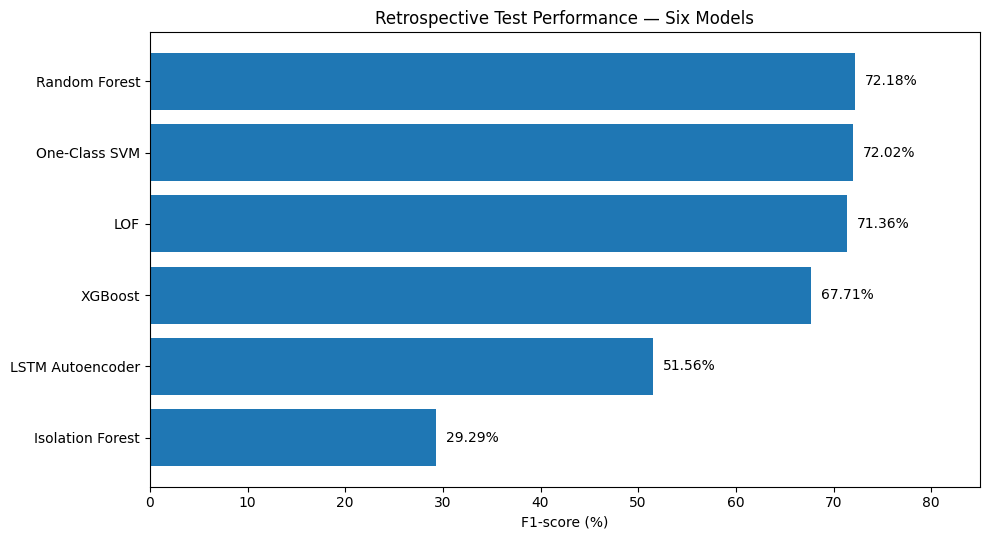

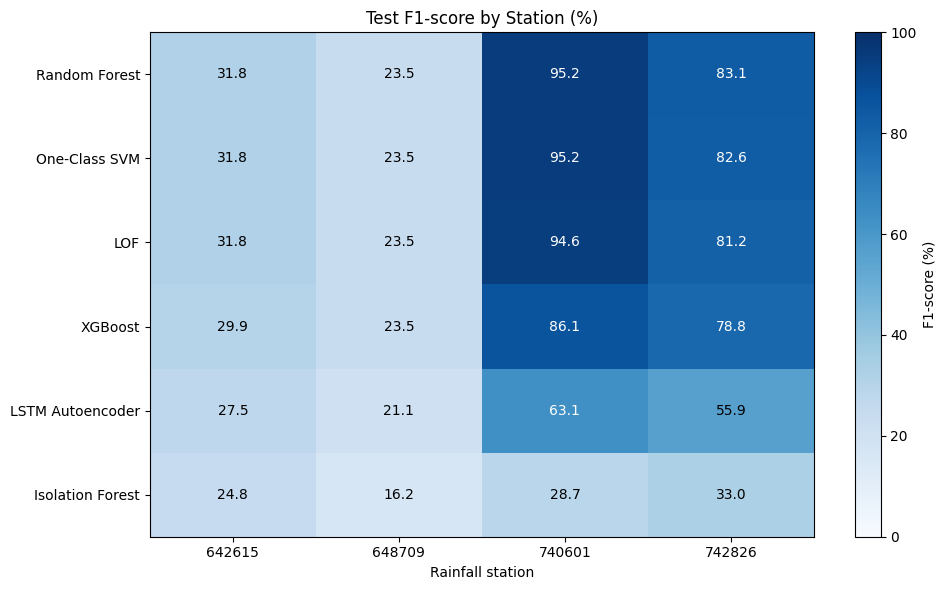

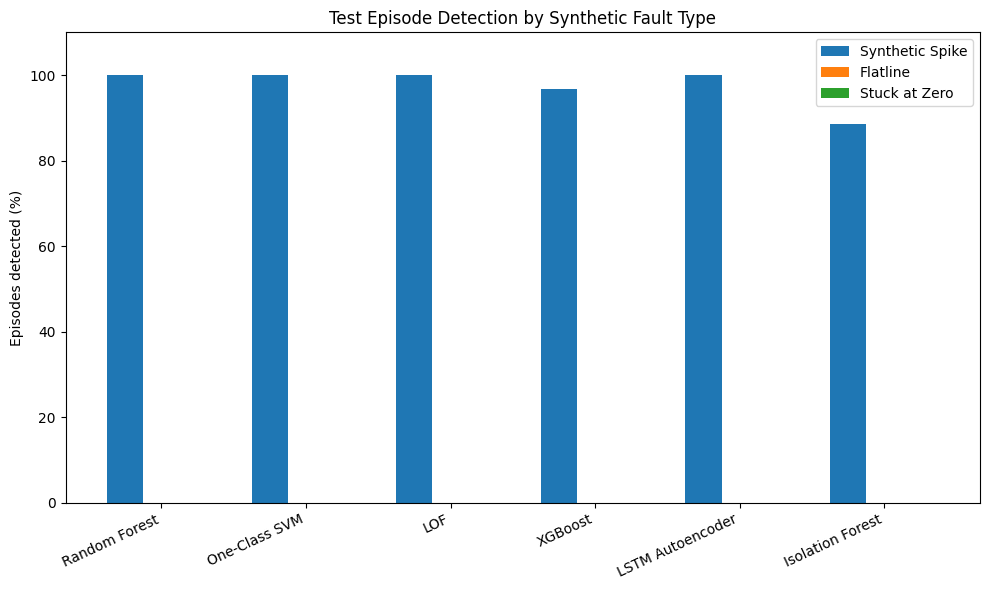


EXPORT COMPLETE
Output folder: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/capstone_outputs
CSV tables: 4
PNG figures: 3


In [148]:

# STEP 57B — Export final capstone results and figures
# Descriptive reporting only; no model retraining

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("STEP 57B — FINAL REPORTING OUTPUTS")
print("=" * 60)

output_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "capstone_outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

# 1. Save the evaluated numerical results
exports = {
    "v2_final_model_comparison.csv": test_comparison_v2,
    "v2_station_performance.csv": station_performance_v2,
    "v2_fault_type_detection.csv": test_fault_comparison_v2,
    "v2_episode_detection.csv": episode_detection_v2,
}

for filename, dataframe in exports.items():
    path = output_dir / filename
    dataframe.to_csv(path, index=False)
    print("Saved:", filename)

# 2. Overall six-model test F1 chart
fig, ax = plt.subplots(figsize=(10, 5.5))

chart_df = test_comparison_v2.sort_values(
    "f1", ascending=True
)

bars = ax.barh(
    chart_df["model"],
    chart_df["f1"] * 100
)

ax.set_xlabel("F1-score (%)")
ax.set_title(
    "Retrospective Test Performance — Six Models"
)
ax.set_xlim(0, 85)

for bar in bars:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.tight_layout()

fig.savefig(
    output_dir / "v2_model_test_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 3. Station-level F1 comparison
station_pivot = station_performance_v2.pivot(
    index="model",
    columns="station_id",
    values="f1"
) * 100

station_pivot = station_pivot.reindex(
    test_comparison_v2["model"]
)

fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(
    station_pivot.values,
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap="Blues"
)

ax.set_xticks(range(len(station_pivot.columns)))
ax.set_xticklabels(station_pivot.columns)

ax.set_yticks(range(len(station_pivot.index)))
ax.set_yticklabels(station_pivot.index)

ax.set_xlabel("Rainfall station")
ax.set_title("Test F1-score by Station (%)")

for i in range(station_pivot.shape[0]):
    for j in range(station_pivot.shape[1]):
        value = station_pivot.iloc[i, j]
        ax.text(
            j, i,
            f"{value:.1f}",
            ha="center",
            va="center",
            color="white" if value >= 60 else "black"
        )

fig.colorbar(im, ax=ax, label="F1-score (%)")

plt.tight_layout()

fig.savefig(
    output_dir / "v2_station_f1_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 4. Persistent-fault vs spike episode detection
episode_pivot = episode_detection_v2.pivot(
    index="model",
    columns="fault_type",
    values="episode_detection_rate"
) * 100

episode_pivot = episode_pivot.reindex(
    test_comparison_v2["model"]
)

fault_order = [
    "Synthetic Spike",
    "Flatline",
    "Stuck at Zero"
]
episode_pivot = episode_pivot[fault_order]

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(episode_pivot.index))
width = 0.25

for i, fault in enumerate(fault_order):
    ax.bar(
        x + (i - 1) * width,
        episode_pivot[fault].values,
        width=width,
        label=fault
    )

ax.set_xticks(x)
ax.set_xticklabels(
    episode_pivot.index,
    rotation=25,
    ha="right"
)

ax.set_ylim(0, 110)
ax.set_ylabel("Episodes detected (%)")
ax.set_title("Test Episode Detection by Synthetic Fault Type")
ax.legend()

plt.tight_layout()

fig.savefig(
    output_dir / "v2_episode_detection_by_fault.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("\nEXPORT COMPLETE")
print("Output folder:", output_dir)
print("CSV tables:", len(exports))
print("PNG figures:", 3)


In [149]:

# STEP 58A — Prepare Streamlit dashboard data
# Reuses existing model results. No training or threshold changes.

from pathlib import Path
import pandas as pd
import numpy as np

print("STEP 58A — STREAMLIT DASHBOARD DATA PREPARATION")
print("=" * 65)

# 1. Dashboard folders in Google Drive
project_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master"
)

dashboard_dir = project_dir / "streamlit_dashboard"
data_dir = dashboard_dir / "data"

dashboard_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)

print("\nDashboard folder:", dashboard_dir)
print("Data folder:", data_dir)

# 2. Verify required results from previous steps
required_tables = {
    "test_predictions_v2": test_predictions_v2,
    "test_comparison_v2": test_comparison_v2,
    "validation_comparison_v2": validation_comparison_v2,
    "station_performance_v2": station_performance_v2,
    "test_fault_comparison_v2": test_fault_comparison_v2,
    "episode_detection_v2": episode_detection_v2,
    "episode_details_v2": episode_details_v2,
}

print("\nCHECKING EXISTING DATA TABLES")

for name, table in required_tables.items():
    assert isinstance(table, pd.DataFrame), (
        f"{name} is not a pandas DataFrame."
    )

    print(
        f"{name}: {len(table):,} rows, "
        f"{len(table.columns)} columns"
    )

# 3. Start with the complete test predictions
dashboard_readings_v2 = test_predictions_v2.copy()

# Match original rainfall readings to test predictions
source_columns = [
    "station_id",
    "timestamp",
    "original_value",
    "simulated_value"
]

source_readings = ml_test_v2[
    source_columns
].copy()

dashboard_readings_v2["station_id"] = (
    dashboard_readings_v2["station_id"].astype(str)
)
source_readings["station_id"] = (
    source_readings["station_id"].astype(str)
)

dashboard_readings_v2["timestamp"] = pd.to_datetime(
    dashboard_readings_v2["timestamp"]
)
source_readings["timestamp"] = pd.to_datetime(
    source_readings["timestamp"]
)

# Require a unique station/timestamp key
assert not source_readings.duplicated(
    ["station_id", "timestamp"]
).any(), "Duplicate test station/timestamps found."

dashboard_readings_v2 = dashboard_readings_v2.merge(
    source_readings,
    on=["station_id", "timestamp"],
    how="left",
    validate="one_to_one"
)

# 4. Verify dashboard record integrity
assert len(dashboard_readings_v2) == 31456
assert dashboard_readings_v2["original_value"].notna().all()
assert dashboard_readings_v2["simulated_value"].notna().all()

assert int(
    dashboard_readings_v2["synthetic_label"].sum()
) == 277

assert int(
    dashboard_readings_v2["fault_active"].sum()
) == 459

# 5. Save dashboard data files
dashboard_exports_v2 = {
    "test_sensor_readings.csv": dashboard_readings_v2,
    "test_model_comparison.csv": test_comparison_v2,
    "validation_model_comparison.csv": validation_comparison_v2,
    "station_performance.csv": station_performance_v2,
    "fault_type_detection.csv": test_fault_comparison_v2,
    "episode_detection.csv": episode_detection_v2,
    "episode_details.csv": episode_details_v2,
}

print("\nSAVING DASHBOARD FILES")

for filename, table in dashboard_exports_v2.items():

    filepath = data_dir / filename

    table.to_csv(filepath, index=False)

    print(
        f"{filename}: "
        f"{len(table):,} rows saved"
    )

# 6. Final summary
print("\nDASHBOARD DATA SUMMARY")
print("=" * 65)

print("Test observations:", len(dashboard_readings_v2))
print(
    "Stations:",
    dashboard_readings_v2["station_id"].nunique()
)
print(
    "Modified readings:",
    int(dashboard_readings_v2["synthetic_label"].sum())
)
print(
    "Active synthetic fault hours:",
    int(dashboard_readings_v2["fault_active"].sum())
)
print("Models:", len(test_comparison_v2))

print("\nOUTPUT FILES")
for filepath in sorted(data_dir.glob("*.csv")):
    print(
        filepath.name,
        "|",
        round(filepath.stat().st_size / 1024, 1),
        "KB"
    )

print("\nSTEP 58A COMPLETED SUCCESSFULLY")
print("No models were retrained.")
print("No thresholds were changed.")


STEP 58A — STREAMLIT DASHBOARD DATA PREPARATION

Dashboard folder: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard
Data folder: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard/data

CHECKING EXISTING DATA TABLES
test_predictions_v2: 31,456 rows, 18 columns
test_comparison_v2: 6 rows, 10 columns
validation_comparison_v2: 6 rows, 7 columns
station_performance_v2: 24 rows, 11 columns
test_fault_comparison_v2: 18 rows, 5 columns
episode_detection_v2: 18 rows, 7 columns
episode_details_v2: 1,038 rows, 9 columns

SAVING DASHBOARD FILES
test_sensor_readings.csv: 31,456 rows saved
test_model_comparison.csv: 6 rows saved
validation_model_comparison.csv: 6 rows saved
station_performance.csv: 24 rows saved
fault_type_detection.csv: 18 rows saved
episode_detection.csv: 18 rows saved
episode_details.csv: 1,038 rows saved

DASHBOARD DATA SUMMARY
Test observations: 31456
Stations: 4
Modified readings: 277
Active synthetic fault h

In [150]:

# STEP 58B — Create Streamlit interactive dashboard
# Uses existing CSVs only; no ML retraining

from pathlib import Path
import ast

dashboard_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "streamlit_dashboard"
)

data_dir = dashboard_dir / "data"
assert (data_dir / "test_sensor_readings.csv").exists(), (
    "Dashboard CSV files missing. Run Step 58A first."
)

app_code = r'''
from pathlib import Path
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

st.set_page_config(
    page_title="Rainfall Sensor Anomaly Detection",
    page_icon="🌧️",
    layout="wide",
    initial_sidebar_state="expanded"
)

DATA_DIR = Path(__file__).resolve().parent / "data"

@st.cache_data
def load_data():
    files = {
        "readings": "test_sensor_readings.csv",
        "models": "test_model_comparison.csv",
        "validation": "validation_model_comparison.csv",
        "stations": "station_performance.csv",
        "faults": "fault_type_detection.csv",
        "episodes": "episode_detection.csv",
        "details": "episode_details.csv"
    }
    data = {
        key: pd.read_csv(DATA_DIR / filename)
        for key, filename in files.items()
    }
    data["readings"]["station_id"] = (
        data["readings"]["station_id"].astype(str)
    )
    data["readings"]["timestamp"] = pd.to_datetime(
        data["readings"]["timestamp"]
    )
    data["stations"]["station_id"] = (
        data["stations"]["station_id"].astype(str)
    )
    return data

try:
    d = load_data()
except Exception as error:
    st.error(f"Unable to load dashboard data: {error}")
    st.stop()

readings = d["readings"]
models = d["models"].sort_values("f1", ascending=False)
model_names = models["model"].tolist()

st.sidebar.title("🌧️ Rainfall Analytics")
st.sidebar.caption("Capstone | Six-model evaluation")

page = st.sidebar.radio(
    "Navigation",
    [
        "Overview",
        "Sensor Explorer",
        "Model Comparison",
        "Fault Episodes"
    ]
)

st.sidebar.divider()
st.sidebar.info(
    "Retrospective evaluation using synthetically "
    "injected faults. Historical anomalies are not "
    "independently verified."
)

st.title("Rainfall Sensor Anomaly Detection")
st.caption(
    "Interactive exploration of machine-learning "
    "results from four rainfall monitoring stations"
)

if page == "Overview":

    st.header("Project Overview")

    best = models.iloc[0]

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Test observations", f"{len(readings):,}")
    c2.metric("Rainfall stations", readings["station_id"].nunique())
    c3.metric("ML models", len(models))
    c4.metric("Best test F1", f"{best['f1']:.2%}")

    st.subheader("Six-Model Test Performance")

    fig = px.bar(
        models,
        x="f1",
        y="model",
        orientation="h",
        color="f1",
        color_continuous_scale="Blues",
        text=models["f1"].map(lambda x: f"{x:.2%}"),
        labels={"f1": "F1-score", "model": "Model"}
    )
    fig.update_layout(
        yaxis={"categoryorder": "total ascending"},
        coloraxis_showscale=False,
        height=440
    )
    fig.update_xaxes(tickformat=".0%", range=[0, 0.85])
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Key Research Findings")
    st.write(
        "Random Forest achieved the highest retrospective "
        "test F1-score. Across all six evaluated models, "
        "large synthetic spikes were much easier to detect "
        "than persistent flatline and stuck-at-zero faults."
    )

    st.warning(
        "The test evaluation is retrospective, and these "
        "results should not be interpreted as accuracy "
        "against independently verified real sensor faults."
    )

elif page == "Sensor Explorer":

    st.header("Interactive Rainfall Sensor Explorer")

    c1, c2 = st.columns(2)

    selected_station = c1.selectbox(
        "Select rainfall station",
        sorted(readings["station_id"].unique())
    )

    selected_model = c2.selectbox(
        "Select anomaly-detection model",
        model_names
    )

    station_data = (
        readings[
            readings["station_id"] == selected_station
        ]
        .sort_values("timestamp")
        .copy()
    )

    min_date = station_data["timestamp"].min().date()
    max_date = station_data["timestamp"].max().date()

    dates = st.date_input(
        "Select date range",
        value=(min_date, max_date),
        min_value=min_date,
        max_value=max_date
    )

    if len(dates) == 2:
        start_date, end_date = dates
        station_data = station_data[
            station_data["timestamp"].dt.date.between(
                start_date, end_date
            )
        ]

    prediction_col = f"{selected_model}_prediction"
    score_col = f"{selected_model}_score"

    anomaly_rows = station_data[
        station_data[prediction_col] == 1
    ]

    c1, c2, c3 = st.columns(3)
    c1.metric("Readings shown", f"{len(station_data):,}")
    c2.metric("Model alerts", f"{len(anomaly_rows):,}")
    c3.metric(
        "Modified synthetic readings",
        f"{int(station_data['synthetic_label'].sum()):,}"
    )

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=station_data["timestamp"],
        y=station_data["original_value"],
        name="Original rainfall",
        mode="lines",
        line=dict(color="#64748b", width=1.5)
    ))

    fig.add_trace(go.Scatter(
        x=station_data["timestamp"],
        y=station_data["simulated_value"],
        name="Simulated rainfall",
        mode="lines",
        line=dict(color="#2563eb", width=1.6)
    ))

    fig.add_trace(go.Scatter(
        x=anomaly_rows["timestamp"],
        y=anomaly_rows["simulated_value"],
        mode="markers",
        name="Model alerts",
        marker=dict(
            color="#dc2626", size=8,
            symbol="circle-open", line=dict(width=2)
        )
    ))

    fig.update_layout(
        title=f"Rainfall Timeline — Station {selected_station}",
        xaxis_title="Timestamp",
        yaxis_title="Rainfall reading (mm)",
        height=520,
        hovermode="x unified"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.caption(
        "Red markers indicate model predictions, not "
        "independently confirmed sensor faults."
    )

    st.subheader("Explore Individual Readings")

    display_cols = [
        "timestamp",
        "original_value",
        "simulated_value",
        "fault_type",
        "synthetic_label",
        "fault_active",
        score_col,
        prediction_col
    ]

    st.dataframe(
        station_data[display_cols],
        use_container_width=True,
        hide_index=True
    )

elif page == "Model Comparison":

    st.header("Compare Machine-Learning Models")

    metric = st.selectbox(
        "Select comparison metric",
        [
            "f1",
            "precision",
            "recall",
            "average_precision"
        ],
        format_func=lambda x: {
            "f1": "F1-score",
            "precision": "Precision",
            "recall": "Recall",
            "average_precision": "Average precision"
        }[x]
    )

    fig = px.bar(
        models.sort_values(metric, ascending=False),
        x="model",
        y=metric,
        color="model",
        labels={
            "model": "Machine-learning model",
            metric: metric.replace("_", " ").title()
        }
    )

    fig.update_yaxes(tickformat=".0%", range=[0, 1])
    fig.update_layout(
        showlegend=False,
        height=450
    )
    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Detailed Test Metrics")
    st.dataframe(
        models,
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Station-Level Model Performance")

    station_pivot = d["stations"].pivot(
        index="model",
        columns="station_id",
        values="f1"
    )

    fig_station = px.imshow(
        station_pivot,
        text_auto=".2f",
        color_continuous_scale="Blues",
        zmin=0, zmax=1,
        labels={"color": "F1-score"}
    )
    st.plotly_chart(
        fig_station,
        use_container_width=True
    )

elif page == "Fault Episodes":

    st.header("Synthetic Fault Episode Analysis")

    episodes = d["episodes"].copy()

    selected_fault = st.selectbox(
        "Select fault type",
        [
            "All",
            "Synthetic Spike",
            "Flatline",
            "Stuck at Zero"
        ]
    )

    if selected_fault != "All":
        episodes = episodes[
            episodes["fault_type"] == selected_fault
        ]

    fig = px.bar(
        episodes,
        x="model",
        y="episode_detection_rate",
        color="fault_type",
        barmode="group",
        labels={
            "episode_detection_rate": "Episode detection",
            "fault_type": "Fault type",
            "model": "Model"
        }
    )

    fig.update_yaxes(tickformat=".0%", range=[0, 1.05])
    fig.update_layout(height=490)

    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Episode Detection Details")
    st.dataframe(
        episodes,
        use_container_width=True,
        hide_index=True
    )

    st.info(
        "An episode is counted as detected if the model "
        "raises at least one alert during its active period. "
        "This is distinct from hourly modification detection."
    )

st.divider()
st.caption(
    "Rainfall Sensor Anomaly Detection Capstone | "
    "Revised retrospective synthetic-fault evaluation"
)
'''

# Write application file
app_path = dashboard_dir / "app.py"
app_path.write_text(app_code, encoding="utf-8")

# Write package requirements
requirements_path = dashboard_dir / "requirements.txt"

requirements_path.write_text(
    "streamlit>=1.35\n"
    "pandas>=2.0\n"
    "numpy>=1.24\n"
    "plotly>=5.20\n",
    encoding="utf-8"
)

# Verify valid Python syntax
ast.parse(
    app_path.read_text(encoding="utf-8")
)

print("STEP 58B — STREAMLIT APP CREATED")
print("=" * 65)

print("\nApplication:", app_path)
print("Requirements:", requirements_path)

print("\nAPP VERIFICATION")
print("Python syntax: VALID")
print("Dashboard pages: 4")
print("Expected input CSV files: 7")

print("\nPAGE FEATURES")
print("1. Overview — KPIs and model performance")
print("2. Sensor Explorer — filters and rainfall timeline")
print("3. Model Comparison — interactive charts")
print("4. Fault Episodes — detection analysis")

print("\nSTEP 58B COMPLETED SUCCESSFULLY")
print("Application created, but not launched yet.")


STEP 58B — STREAMLIT APP CREATED

Application: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard/app.py
Requirements: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard/requirements.txt

APP VERIFICATION
Python syntax: VALID
Dashboard pages: 4
Expected input CSV files: 7

PAGE FEATURES
1. Overview — KPIs and model performance
2. Sensor Explorer — filters and rainfall timeline
3. Model Comparison — interactive charts
4. Fault Episodes — detection analysis

STEP 58B COMPLETED SUCCESSFULLY
Application created, but not launched yet.


In [152]:

# STEP 58C — Launch Streamlit dashboard in Google Colab
# No model training or data modifications

import subprocess
import sys
import time
from pathlib import Path
from IPython.display import display, HTML
from google.colab import output

print("STEP 58C — LAUNCH STREAMLIT DASHBOARD")
print("=" * 65)

dashboard_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "streamlit_dashboard"
)

app_path = dashboard_dir / "app.py"
requirements_path = dashboard_dir / "requirements.txt"

assert app_path.exists(), "app.py is missing."
assert requirements_path.exists(), "requirements.txt is missing."

# 1. Install required packages
print("\nInstalling dashboard requirements...")

subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "-q", "-r", str(requirements_path)
    ],
    check=True
)

print("Packages installed.")

# 2. Start Streamlit server
port = 8501

log_path = dashboard_dir / "streamlit_server.log"

log_file = open(log_path, "w", encoding="utf-8")

streamlit_process_v2 = subprocess.Popen(
    [
        sys.executable,
        "-m", "streamlit", "run",
        str(app_path),
        "--server.port", str(port),
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false",
        "--browser.gatherUsageStats", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    cwd=str(dashboard_dir)
)

log_file.close()

print("\nStarting Streamlit server...")

# 3. Wait for the server to become available
import requests

ready = False

for attempt in range(25):
    time.sleep(1)

    if streamlit_process_v2.poll() is not None:
        break

    try:
        response = requests.get(
            f"http://localhost:{port}/_stcore/health",
            timeout=2
        )

        if response.status_code == 200:
            ready = True
            break

    except requests.RequestException:
        pass

if not ready:
    print("\nStreamlit did not start successfully.")
    print("\nSERVER LOG:")
    print(log_path.read_text(encoding="utf-8")[-4000:])
else:
    print("\nSTREAMLIT SERVER IS RUNNING")

    # 4. Create Colab-accessible dashboard URL
    try:
        dashboard_url_v2 = output.eval_js(
            f"google.colab.kernel.proxyPort({port})"
        )

        print("\nDASHBOARD URL:")
        print(dashboard_url_v2)

        display(HTML(
            '<a href="' + dashboard_url_v2 + '" '
            'target="_blank" '
            'style="font-size:18px;font-weight:bold;">'
            ' OPEN INTERACTIVE DASHBOARD ↗'
            '</a>'
        ))

    except Exception as error:
        print("Automatic link unavailable:", error)
        print("Try opening the Colab port preview for port 8501.")

    print("\nApplication:", app_path.name)
    print("Running port:", port)
    print("Server log:", log_path)

print("\nSTEP 58C LAUNCH CHECK COMPLETED")


STEP 58C — LAUNCH STREAMLIT DASHBOARD

Installing dashboard requirements...
Packages installed.

Starting Streamlit server...

STREAMLIT SERVER IS RUNNING

DASHBOARD URL:
https://8501-m-s-kkb-usc1c2-39q4nxo1un9qp-c.us-central1-2.prod.colab.dev



Application: app.py
Running port: 8501
Server log: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard/streamlit_server.log

STEP 58C LAUNCH CHECK COMPLETED


In [153]:

# STEP 58D — Improve Streamlit dashboard usability
# Updates existing app.py without modifying data or models

from pathlib import Path
import ast
import shutil

dashboard_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "streamlit_dashboard"
)

app_path = dashboard_dir / "app.py"
assert app_path.exists(), "app.py not found."

original = app_path.read_text(encoding="utf-8")
updated = original

# 1. Fix station IDs displayed as numeric axes
old_heatmap = '''    fig_station = px.imshow(
        station_pivot,
        text_auto=".2f",
        color_continuous_scale="Blues",
        zmin=0, zmax=1,
        labels={"color": "F1-score"}
    )'''

new_heatmap = '''    # Station IDs are identifiers, not numerical quantities.
    station_pivot.columns = [
        "Station " + str(s)
        for s in station_pivot.columns
    ]

    fig_station = px.imshow(
        station_pivot,
        text_auto=".2f",
        color_continuous_scale="Blues",
        zmin=0, zmax=1,
        labels={"color": "F1-score"}
    )'''

assert old_heatmap in updated, (
    "Heatmap code not found. No changes were saved."
)
updated = updated.replace(old_heatmap, new_heatmap, 1)

# 2. Show modified synthetic readings separately from alerts
old_marker = '''    fig.add_trace(go.Scatter(
        x=anomaly_rows["timestamp"],
        y=anomaly_rows["simulated_value"],
        mode="markers",
        name="Model alerts",'''

new_marker = '''    modified_rows = station_data[
        station_data["synthetic_label"] == 1
    ]

    fig.add_trace(go.Scatter(
        x=modified_rows["timestamp"],
        y=modified_rows["simulated_value"],
        mode="markers",
        name="Synthetic modifications",
        marker=dict(
            color="#f59e0b",
            size=9,
            symbol="x"
        )
    ))

    fig.add_trace(go.Scatter(
        x=anomaly_rows["timestamp"],
        y=anomaly_rows["simulated_value"],
        mode="markers",
        name="Model alerts",'''

assert old_marker in updated, (
    "Sensor marker code not found. No changes were saved."
)
updated = updated.replace(old_marker, new_marker, 1)

# 3. Add a filter to the readings table
old_table = '''    st.dataframe(
        station_data[display_cols],
        use_container_width=True,
        hide_index=True
    )'''

new_table = '''    reading_filter = st.selectbox(
        "Filter reading details",
        [
            "All readings",
            "Modified synthetic readings",
            "Active synthetic fault hours",
            "Model alerts"
        ]
    )

    filtered_table = station_data.copy()

    if reading_filter == "Modified synthetic readings":
        filtered_table = filtered_table[
            filtered_table["synthetic_label"] == 1
        ]
    elif reading_filter == "Active synthetic fault hours":
        filtered_table = filtered_table[
            filtered_table["fault_active"] == 1
        ]
    elif reading_filter == "Model alerts":
        filtered_table = filtered_table[
            filtered_table[prediction_col] == 1
        ]

    st.caption(
        f"Displaying {len(filtered_table):,} readings "
        f"out of {len(station_data):,} in the selected period."
    )

    st.dataframe(
        filtered_table[display_cols],
        use_container_width=True,
        hide_index=True
    )'''

assert old_table in updated, (
    "Readings table code not found. No changes were saved."
)
updated = updated.replace(old_table, new_table, 1)

# 4. Validate changes before saving
ast.parse(updated)

backup_path = dashboard_dir / "app_step58c_backup.py"
shutil.copy2(app_path, backup_path)

app_path.write_text(updated, encoding="utf-8")

print("STEP 58D — DASHBOARD IMPROVEMENTS")
print("=" * 60)
print("Python syntax: VALID")
print("Station heatmap labels: FIXED")
print("Synthetic modification markers: ADDED")
print("Reading details filter: ADDED")
print("Previous version backed up:", backup_path.name)
print("Updated application:", app_path)
print("\nSTEP 58D COMPLETED")
print("Refresh the Streamlit dashboard browser tab.")


STEP 58D — DASHBOARD IMPROVEMENTS
Python syntax: VALID
Station heatmap labels: FIXED
Synthetic modification markers: ADDED
Reading details filter: ADDED
Previous version backed up: app_step58c_backup.py
Updated application: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard/app.py

STEP 58D COMPLETED
Refresh the Streamlit dashboard browser tab.


In [154]:

# STEP 58E — Add interactive fault-episode investigation
# Also enlarge the station comparison heatmap

from pathlib import Path
import ast
import shutil

dashboard_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "streamlit_dashboard"
)

app_path = dashboard_dir / "app.py"

assert app_path.exists(), "Dashboard app.py is missing."

original = app_path.read_text(encoding="utf-8")
updated = original

# 1. Enlarge the model comparison heatmap
old_heatmap_end = '''    st.plotly_chart(
        fig_station,
        use_container_width=True
    )'''

new_heatmap_end = '''    # Allow the heatmap to fill the available width
    fig_station.update_yaxes(scaleanchor=None)
    fig_station.update_layout(
        height=470,
        margin=dict(l=90, r=30, t=35, b=55)
    )

    st.plotly_chart(
        fig_station,
        use_container_width=True
    )'''

assert old_heatmap_end in updated, (
    "Could not locate the station heatmap section."
)

updated = updated.replace(
    old_heatmap_end,
    new_heatmap_end,
    1
)

# 2. Add a drill-down beneath the episode summary table
old_episode_section = '''    st.info(
        "An episode is counted as detected if the model "
        "raises at least one alert during its active period. "
        "This is distinct from hourly modification detection."
    )'''

new_episode_section = '''    st.info(
        "An episode is counted as detected if the model "
        "raises at least one alert during its active period. "
        "This is distinct from hourly modification detection."
    )

    st.divider()
    st.subheader("Investigate an Individual Fault Episode")

    st.write(
        "Select a model, fault type and station to inspect "
        "an injected fault in its rainfall timeline."
    )

    details = d["details"].copy()
    details["station_id"] = details["station_id"].astype(str)

    c1, c2, c3 = st.columns(3)

    investigation_model = c1.selectbox(
        "Investigation model",
        model_names,
        key="episode_model"
    )

    investigation_fault = c2.selectbox(
        "Investigation fault type",
        ["Flatline", "Stuck at Zero", "Synthetic Spike"],
        key="episode_fault"
    )

    available = details[
        (details["model"] == investigation_model)
        & (details["fault_type"] == investigation_fault)
    ].copy()

    investigation_station = c3.selectbox(
        "Investigation station",
        sorted(available["station_id"].unique()),
        key="episode_station"
    )

    available = available[
        available["station_id"] == investigation_station
    ].copy()

    if available.empty:
        st.warning("No episodes match the selected filters.")
    else:
        available["fault_episode_id"] = (
            available["fault_episode_id"].astype(str)
        )

        selected_episode = st.selectbox(
            "Select synthetic fault episode",
            available["fault_episode_id"].tolist(),
            key="selected_fault_episode"
        )

        episode_row = available[
            available["fault_episode_id"] == selected_episode
        ].iloc[0]

        station_rows = readings[
            readings["station_id"] == investigation_station
        ].sort_values("timestamp").copy()

        selected_rows = station_rows[
            station_rows["fault_episode_id"].astype(str)
            == selected_episode
        ]

        selected_rows = selected_rows[
            selected_rows["fault_active"] == 1
        ]

        if selected_rows.empty:
            st.error(
                "Could not match this episode to sensor readings."
            )
        else:
            episode_start = selected_rows["timestamp"].min()
            episode_end = selected_rows["timestamp"].max()

            view_start = episode_start - pd.Timedelta(hours=12)
            view_end = episode_end + pd.Timedelta(hours=12)

            timeline = station_rows[
                station_rows["timestamp"].between(
                    view_start, view_end
                )
            ].copy()

            prediction_col = (
                f"{investigation_model}_prediction"
            )

            alert_rows = timeline[
                timeline[prediction_col] == 1
            ]

            c1, c2, c3, c4 = st.columns(4)

            c1.metric(
                "Episode duration",
                f"{len(selected_rows)} hours"
            )
            c2.metric(
                "Modified readings",
                int(selected_rows["synthetic_label"].sum())
            )
            c3.metric(
                "Model alert hours",
                int(selected_rows[prediction_col].sum())
            )
            c4.metric(
                "Episode detected",
                "Yes" if int(episode_row["detected"]) else "No"
            )

            fig_episode = go.Figure()

            fig_episode.add_trace(go.Scatter(
                x=timeline["timestamp"],
                y=timeline["original_value"],
                mode="lines+markers",
                name="Original reading",
                line=dict(color="#64748b", width=2),
                marker=dict(size=4)
            ))

            fig_episode.add_trace(go.Scatter(
                x=timeline["timestamp"],
                y=timeline["simulated_value"],
                mode="lines+markers",
                name="Simulated reading",
                line=dict(color="#2563eb", width=2),
                marker=dict(size=4)
            ))

            modified = selected_rows[
                selected_rows["synthetic_label"] == 1
            ]

            fig_episode.add_trace(go.Scatter(
                x=modified["timestamp"],
                y=modified["simulated_value"],
                mode="markers",
                name="Modified readings",
                marker=dict(
                    color="#f59e0b",
                    symbol="x",
                    size=11
                )
            ))

            fig_episode.add_trace(go.Scatter(
                x=alert_rows["timestamp"],
                y=alert_rows["simulated_value"],
                mode="markers",
                name="Model alerts",
                marker=dict(
                    color="#dc2626",
                    symbol="circle-open",
                    size=12,
                    line=dict(width=2)
                )
            ))

            fig_episode.add_vrect(
                x0=episode_start,
                x1=episode_end + pd.Timedelta(hours=1),
                fillcolor="#f59e0b",
                opacity=0.13,
                layer="below",
                line_width=0,
                annotation_text="Injected fault period",
                annotation_position="top left"
            )

            fig_episode.update_layout(
                title=(
                    f"{investigation_fault} — "
                    f"Station {investigation_station}"
                ),
                xaxis_title="Timestamp",
                yaxis_title="Rainfall reading (mm)",
                hovermode="x unified",
                height=480,
                legend=dict(orientation="h", y=-0.25)
            )

            st.plotly_chart(
                fig_episode,
                use_container_width=True
            )

            st.caption(
                "Shaded area marks the active synthetic fault. "
                "Orange crosses mark numerically modified readings; "
                "red circles mark model alerts. "
                "All model thresholds remain unchanged."
            )

            st.subheader("Episode Reading Details")

            episode_display = timeline[[
                "timestamp",
                "original_value",
                "simulated_value",
                "fault_active",
                "synthetic_label",
                prediction_col
            ]].copy()

            st.dataframe(
                episode_display,
                use_container_width=True,
                hide_index=True
            )
'''

assert old_episode_section in updated, (
    "Could not locate the Fault Episodes section."
)

updated = updated.replace(
    old_episode_section,
    new_episode_section,
    1
)

# 3. Check Python syntax before changing the application
ast.parse(updated)

# 4. Save previous application as backup
backup_path = dashboard_dir / "app_step58d_backup.py"
shutil.copy2(app_path, backup_path)

app_path.write_text(updated, encoding="utf-8")

print("STEP 58E — DASHBOARD FAULT INVESTIGATION")
print("=" * 65)
print("Python syntax: VALID")
print("Station heatmap: ENLARGED")
print("Individual episode selection: ADDED")
print("Fault-period highlighting: ADDED")
print("Original vs simulated rainfall: ADDED")
print("Model alert markers: ADDED")
print("Episode-level reading table: ADDED")
print("Backup:", backup_path.name)

print("\nSTEP 58E COMPLETED")
print("Refresh your existing Streamlit dashboard.")


STEP 58E — DASHBOARD FAULT INVESTIGATION
Python syntax: VALID
Station heatmap: ENLARGED
Individual episode selection: ADDED
Fault-period highlighting: ADDED
Original vs simulated rainfall: ADDED
Model alert markers: ADDED
Episode-level reading table: ADDED
Backup: app_step58d_backup.py

STEP 58E COMPLETED
Refresh your existing Streamlit dashboard.


In [155]:

# STEP 58F — Check historical Puni Hill data availability
# Read-only inventory for the historical investigation page

from pathlib import Path
import pandas as pd

print("STEP 58F — HISTORICAL PUNI HILL DATA CHECK")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master"
)

output_dir = project_dir / "capstone_outputs"

# 1. Check historical investigation figure
historical_figure = (
    output_dir / "puni_historical_rainfall_disagreement.png"
)

print("\nHISTORICAL FIGURE")
print("Exists:", historical_figure.exists())

if historical_figure.exists():
    print("File:", historical_figure.name)
    print(
        "Size (KB):",
        round(historical_figure.stat().st_size / 1024, 1)
    )

# 2. Look for existing historical DataFrames
print("\nPOSSIBLE HISTORICAL DATAFRAMES")

matches = []

for name, value in list(globals().items()):

    if not isinstance(value, pd.DataFrame):
        continue

    columns = set(value.columns.astype(str))

    has_station = "station_id" in columns
    has_time = "timestamp" in columns

    if has_station and has_time:
        matches.append((name, value))

for name, frame in matches[:30]:

    print(
        f"{name}: {len(frame):,} rows | "
        f"columns: {list(frame.columns[:12])}"
    )

if not matches:
    print("No matching DataFrames found in memory.")

# 3. Find previously saved investigation files
print("\nPOSSIBLE HISTORICAL INVESTIGATION FILES")

candidate_files = []

if output_dir.exists():

    for path in output_dir.iterdir():

        if not path.is_file():
            continue

        if path.suffix.lower() not in [
            ".csv", ".parquet", ".xlsx", ".png"
        ]:
            continue

        filename = path.name.lower()

        if any(term in filename for term in [
            "puni", "historical", "neighbour",
            "neighbor", "rainfall"
        ]):
            candidate_files.append(path)

for path in sorted(candidate_files)[:30]:
    print(path.name)

if not candidate_files:
    print("No matching saved investigation files found.")

# 4. Check whether the historical period is available
print("\nHISTORICAL PERIOD")
print("Station: 742826 — Puni Hill Reserve")
print("Investigation: 2023-01-27 to 2023-02-16")
print("Status: Possible anomaly, NOT confirmed fault")

print("\nSTEP 58F COMPLETED")
print("No data or models were modified.")


STEP 58F — HISTORICAL PUNI HILL DATA CHECK

HISTORICAL FIGURE
Exists: True
File: puni_historical_rainfall_disagreement.png
Size (KB): 294.4

POSSIBLE HISTORICAL DATAFRAMES
df: 31,456 rows | columns: ['station_id', 'timestamp', 'synthetic_label', 'fault_active', 'fault_type', 'fault_episode_id', 'Random Forest_score', 'Random Forest_prediction', 'XGBoost_score', 'XGBoost_prediction', 'Isolation Forest_score', 'Isolation Forest_prediction']
rainfall_test: 96,442 rows | columns: ['station_id', 'timestamp', 'sensor_type', 'value', 'unit']
discharge_test: 101,040 rows | columns: ['station_id', 'timestamp', 'sensor_type', 'value', 'unit']
water_test: 101,040 rows | columns: ['station_id', 'timestamp', 'sensor_type', 'value', 'unit']
master_df: 18,915,131 rows | columns: ['station_id', 'timestamp', 'sensor_type', 'value', 'unit', 'is_missing', 'is_zero', 'is_negative', 'duplicate_timestamp', 'exact_duplicate', 'threshold_999', 'high_value_flag']
duplicate_groups: 824 rows | columns: ['station

In [156]:

# STEP 58G — Inspect historical Puni Hill CSV data
# Read-only inspection; no dashboard modifications

from pathlib import Path
import pandas as pd

print("STEP 58G — HISTORICAL DATA STRUCTURE")
print("=" * 65)

output_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "capstone_outputs"
)

historical_files = [
    "puni_historical_anomaly_investigation.csv",
    "puni_hourly_neighbour_validation_2023.csv",
    "puni_nearest_rainfall_stations.csv",
    "puni_investigation_category_summary.csv",
    "puni_neighbour_coverage_jan2023.csv"
]

historical_file_inventory_v2 = {}

for filename in historical_files:

    filepath = output_dir / filename

    print("\n" + "=" * 65)
    print("FILE:", filename)

    if not filepath.exists():
        print("STATUS: NOT FOUND")
        continue

    table = pd.read_csv(
        filepath,
        low_memory=False
    )

    historical_file_inventory_v2[filename] = table

    print("Rows:", len(table))
    print("Columns:", len(table.columns))

    print("\nCOLUMN NAMES:")
    for column in table.columns:
        print(" -", column)

    print("\nFIRST 3 ROWS:")
    display(table.head(3))

    # Check time coverage when recognizable
    time_columns = [
        col for col in table.columns
        if any(word in col.lower() for word in [
            "timestamp", "datetime", "date"
        ])
    ]

    for column in time_columns[:3]:

        parsed = pd.to_datetime(
            table[column],
            errors="coerce"
        )

        if parsed.notna().any():
            print(
                f"\n{column} coverage:",
                parsed.min(),
                "to",
                parsed.max()
            )

    # Identify possible station columns
    station_columns = [
        col for col in table.columns
        if "station" in col.lower()
    ]

    for column in station_columns[:2]:

        print(
            f"\n{column} examples:",
            table[column]
            .dropna()
            .astype(str)
            .unique()[:12]
            .tolist()
        )

print("\n" + "=" * 65)

print("STEP 58G COMPLETED")
print("Files inspected:", len(historical_file_inventory_v2))
print("No models, datasets or dashboard files changed.")


STEP 58G — HISTORICAL DATA STRUCTURE

FILE: puni_historical_anomaly_investigation.csv
Rows: 192
Columns: 12

COLUMN NAMES:
 - timestamp
 - puni_rainfall_mm
 - neighbours_reporting_rain
 - neighbours_reporting_1mm
 - neighbour_mean_mm
 - neighbour_max_mm
 - conflict_2_positive
 - conflict_3_positive
 - strong_conflict_2_at_1mm
 - lstm_hourly_flag
 - lstm_hourly_error
 - investigation_category

FIRST 3 ROWS:


,timestamp,puni_rainfall_mm,neighbours_reporting_rain,neighbours_reporting_1mm,neighbour_mean_mm,neighbour_max_mm,conflict_2_positive,conflict_3_positive,strong_conflict_2_at_1mm,lstm_hourly_flag,lstm_hourly_error,investigation_category
0,2023-01-28 00:00:00,0.0,8,8,4.408827,14.622093,True,True,True,1,12.813977,High-priority disagreement
1,2023-01-28 01:00:00,0.0,5,1,0.373750,1.000000,True,True,False,0,4.994546,Moderate disagreement
2,2023-01-28 02:00:00,0.0,5,0,0.312500,0.510000,True,True,False,0,2.354330,Moderate disagreement



timestamp coverage: 2023-01-28 00:00:00 to 2023-02-04 23:00:00

FILE: puni_hourly_neighbour_validation_2023.csv
Rows: 192
Columns: 9

COLUMN NAMES:
 - timestamp
 - puni_rainfall_mm
 - neighbours_reporting_rain
 - neighbours_reporting_1mm
 - neighbour_mean_mm
 - neighbour_max_mm
 - conflict_2_positive
 - conflict_3_positive
 - strong_conflict_2_at_1mm

FIRST 3 ROWS:


,timestamp,puni_rainfall_mm,neighbours_reporting_rain,neighbours_reporting_1mm,neighbour_mean_mm,neighbour_max_mm,conflict_2_positive,conflict_3_positive,strong_conflict_2_at_1mm
0,2023-01-28 00:00:00,0.0,8,8,4.408827,14.622093,True,True,True
1,2023-01-28 01:00:00,0.0,5,1,0.373750,1.000000,True,True,False
2,2023-01-28 02:00:00,0.0,5,0,0.312500,0.510000,True,True,False



timestamp coverage: 2023-01-28 00:00:00 to 2023-02-04 23:00:00

FILE: puni_nearest_rainfall_stations.csv
Rows: 10
Columns: 5

COLUMN NAMES:
 - station_id
 - station_name
 - latitude
 - longitude
 - distance_km

FIRST 3 ROWS:


...


station_id examples: ['741813', '742824', '742914', '742736', '742736C', '741814', '742740', '742739', '741815', '751021']

station_name examples: ['Whangamaire @ Culvert', 'Mauku RAWS @ Mauku', 'Ngakoroa @ Donovans', 'Waitangi @ Diver Road', 'Waitangi @ Divers Road Composite Record', 'Karaka rainfall', 'Waiuku @ Cosmopolitan Club', 'Waiuku Rain @ Waiuku-Otaua Rd', 'Karaka @ Walters road', 'Drury @ Turner Road']

FILE: puni_investigation_category_summary.csv
Rows: 4
Columns: 5

COLUMN NAMES:
 - investigation_category
 - hours
 - puni_mean_mm
 - neighbour_mean_mm
 - lstm_flags

FIRST 3 ROWS:


,investigation_category,hours,puni_mean_mm,neighbour_mean_mm,lstm_flags
0,High-priority disagreement,42,0.0,2.186939,1
1,Limited disagreement,8,0.0,0.125469,0
2,Moderate disagreement,25,0.0,0.323060,0



FILE: puni_neighbour_coverage_jan2023.csv
Rows: 11
Columns: 11

COLUMN NAMES:
 - station_id
 - expected_hours
 - recorded_hours
 - valid_hours
 - missing_value_rows
 - absent_hours
 - zero_hours
 - positive_rain_hours
 - total_rainfall_mm
 - coverage_pct
 - station_name

FIRST 3 ROWS:


,station_id,expected_hours,recorded_hours,valid_hours,missing_value_rows,absent_hours,zero_hours,positive_rain_hours,total_rainfall_mm,coverage_pct,station_name
0,742826,192,192,192,0,0,192,0,0.0,100.0,Puni Hill Reserve
1,741813,192,192,192,0,0,138,54,106.0,100.0,Whangamaire @ Culvert
2,742824,192,192,192,0,0,145,47,112.5,100.0,Mauku RAWS @ Mauku



station_id examples: ['742826', '741813', '742824', '742914', '742736', '742736C', '741814', '742740', '742739', '741815', '751021']

station_name examples: ['Puni Hill Reserve', 'Whangamaire @ Culvert', 'Mauku RAWS @ Mauku', 'Ngakoroa @ Donovans', 'Waitangi @ Diver Road', 'Waitangi @ Divers Road Composite Record', 'Karaka rainfall', 'Waiuku @ Cosmopolitan Club', 'Waiuku Rain @ Waiuku-Otaua Rd', 'Karaka @ Walters road', 'Drury @ Turner Road']

STEP 58G COMPLETED
Files inspected: 5
No models, datasets or dashboard files changed.


In [158]:

# STEP 58H — Prepare Puni Hill historical dashboard data
# Uses verified historical CSV files; no ML training

from pathlib import Path
import pandas as pd
import shutil

print("STEP 58H — PUNI HILL DASHBOARD DATA")
print("=" * 65)

project_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master"
)

source_dir = project_dir / "capstone_outputs"
dashboard_dir = project_dir / "streamlit_dashboard"
data_dir = dashboard_dir / "data"

data_dir.mkdir(parents=True, exist_ok=True)

# 1. Read historical hourly investigation
hourly = pd.read_csv(
    source_dir / "puni_historical_anomaly_investigation.csv"
)

required_cols = [
    "timestamp",
    "puni_rainfall_mm",
    "neighbours_reporting_rain",
    "neighbours_reporting_1mm",
    "neighbour_mean_mm",
    "neighbour_max_mm",
    "investigation_category",
    "lstm_hourly_flag",
    "lstm_hourly_error"
]

missing = set(required_cols) - set(hourly.columns)
assert not missing, f"Missing historical columns: {missing}"

hourly["timestamp"] = pd.to_datetime(
    hourly["timestamp"], errors="raise"
)

hourly = hourly.sort_values("timestamp").reset_index(drop=True)

assert len(hourly) == 192
assert hourly["timestamp"].is_unique
assert hourly["timestamp"].notna().all()

assert hourly["timestamp"].min() == pd.Timestamp(
    "2023-01-28 00:00:00"
)
assert hourly["timestamp"].max() == pd.Timestamp(
    "2023-02-04 23:00:00"
)

assert hourly["timestamp"].diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

assert hourly["puni_rainfall_mm"].notna().all()
assert (hourly["puni_rainfall_mm"] == 0).all()

# Use existing category labels; don't recalculate them
high_priority = int(
    hourly["investigation_category"]
    .eq("High-priority disagreement")
    .sum()
)

assert high_priority == 42

# 2. Read nearby station information
stations = pd.read_csv(
    source_dir / "puni_nearest_rainfall_stations.csv",
    dtype={"station_id": str}
)

coverage = pd.read_csv(
    source_dir / "puni_neighbour_coverage_jan2023.csv",
    dtype={"station_id": str}
)

categories = pd.read_csv(
    source_dir / "puni_investigation_category_summary.csv"
)

assert len(stations) == 10
assert len(coverage) == 11
assert categories["hours"].sum() == 192

# 3. Export to Streamlit's data directory
exports = {
    "puni_historical_hourly.csv": hourly,
    "puni_nearby_stations.csv": stations,
    "puni_neighbour_coverage.csv": coverage,
    "puni_investigation_categories.csv": categories
}

for filename, table in exports.items():

    target = data_dir / filename
    table.to_csv(target, index=False)

    # Confirm successful round-trip
    check = pd.read_csv(target, low_memory=False)
    assert len(check) == len(table)

    print(f"Saved: {filename} — {len(table):,} rows")

# 4. Copy the previously generated investigation figure
source_figure = (
    source_dir / "puni_historical_rainfall_disagreement.png"
)

if source_figure.exists():
    target_figure = (
        dashboard_dir / "puni_historical_rainfall_disagreement.png"
    )
    shutil.copy2(source_figure, target_figure)
    print("Saved historical figure:", target_figure.name)
else:
    print("Historical figure unavailable; CSV data is sufficient.")

# 5. Summary
print("\nHISTORICAL INVESTIGATION SUMMARY")
print("=" * 65)

print("Station: 742826 — Puni Hill Reserve")
print("Hourly observations:", len(hourly))
print("Period start:", hourly["timestamp"].min())
print("Period end:", hourly["timestamp"].max())
print("Puni Hill rainfall total (mm):",
      hourly["puni_rainfall_mm"].sum())
print("High-priority disagreement hours:", high_priority)
print("Nearby station records:", len(stations))
print("Coverage records:", len(coverage))
print("Investigation categories:", len(categories))

print("\nIMPORTANT INTERPRETATION")
print("Historical observation: UNVERIFIED possible anomaly")
print("Neighbour mean is a comparison summary,")
print("not a predicted rainfall value at Puni Hill.")
print("Earlier LSTM flags are exploratory, not")
print("part of the revised six-model test evaluation.")

print("\nSTEP 58H COMPLETED SUCCESSFULLY")
print("Existing models and Streamlit application unchanged.")


STEP 58H — PUNI HILL DASHBOARD DATA
Saved: puni_historical_hourly.csv — 192 rows
Saved: puni_nearby_stations.csv — 10 rows
Saved: puni_neighbour_coverage.csv — 11 rows
Saved: puni_investigation_categories.csv — 4 rows
Saved historical figure: puni_historical_rainfall_disagreement.png

HISTORICAL INVESTIGATION SUMMARY
Station: 742826 — Puni Hill Reserve
Hourly observations: 192
Period start: 2023-01-28 00:00:00
Period end: 2023-02-04 23:00:00
Puni Hill rainfall total (mm): 0.0
High-priority disagreement hours: 42
Nearby station records: 10
Coverage records: 11
Investigation categories: 4

IMPORTANT INTERPRETATION
Historical observation: UNVERIFIED possible anomaly
Neighbour mean is a comparison summary,
not a predicted rainfall value at Puni Hill.
Earlier LSTM flags are exploratory, not
part of the revised six-model test evaluation.

STEP 58H COMPLETED SUCCESSFULLY
Existing models and Streamlit application unchanged.


In [159]:

# STEP 58I — Add Puni Hill historical investigation page
# No model retraining or changes to experiment results

from pathlib import Path
import ast
import shutil

print("STEP 58I — PUNI HILL HISTORICAL DASHBOARD")
print("=" * 65)

dashboard_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "streamlit_dashboard"
)

app_path = dashboard_dir / "app.py"
data_dir = dashboard_dir / "data"

required_files = [
    "puni_historical_hourly.csv",
    "puni_nearby_stations.csv",
    "puni_neighbour_coverage.csv",
    "puni_investigation_categories.csv"
]

for name in required_files:
    assert (data_dir / name).exists(), (
        f"Missing historical file: {name}"
    )

original = app_path.read_text(encoding="utf-8")

assert 'elif page == "Historical Investigation":' not in original, (
    "Historical Investigation page already exists."
)

# 1. Add new page to the sidebar navigation
old_navigation = '''        "Model Comparison",
        "Fault Episodes"
    ]'''

new_navigation = '''        "Model Comparison",
        "Fault Episodes",
        "Historical Investigation"
    ]'''

assert old_navigation in original, (
    "Could not find dashboard navigation."
)

updated = original.replace(
    old_navigation, new_navigation, 1
)

# 2. Build the fifth page
historical_page = '''
elif page == "Historical Investigation":

    st.header("Historical Investigation — Puni Hill Reserve")

    st.warning(
        "UNVERIFIED HISTORICAL DISAGREEMENT: "
        "These observations do not establish that the "
        "Puni Hill rainfall sensor was faulty."
    )

    @st.cache_data
    def load_puni_data():
        hourly = pd.read_csv(
            DATA_DIR / "puni_historical_hourly.csv"
        )
        hourly["timestamp"] = pd.to_datetime(
            hourly["timestamp"]
        )

        stations = pd.read_csv(
            DATA_DIR / "puni_nearby_stations.csv",
            dtype={"station_id": str}
        )

        coverage = pd.read_csv(
            DATA_DIR / "puni_neighbour_coverage.csv",
            dtype={"station_id": str}
        )

        categories = pd.read_csv(
            DATA_DIR / "puni_investigation_categories.csv"
        )

        return hourly, stations, coverage, categories

    hourly, nearby, coverage, categories = load_puni_data()

    hourly = hourly.sort_values("timestamp").copy()

    high_priority = int(
        hourly["investigation_category"].eq(
            "High-priority disagreement"
        ).sum()
    )

    c1, c2, c3, c4 = st.columns(4)

    c1.metric("Station", "742826")
    c2.metric("Hours investigated", f"{len(hourly):,}")
    c3.metric(
        "Puni recorded rainfall",
        f"{hourly['puni_rainfall_mm'].sum():.1f} mm"
    )
    c4.metric(
        "High-priority hours",
        f"{high_priority:,}"
    )

    st.caption(
        "Investigation period: 28 January – 4 February 2023. "
        "Puni Hill reported zero rainfall throughout the "
        "192-hour period."
    )

    st.divider()
    st.subheader("Interactive Historical Rainfall Timeline")

    all_categories = sorted(
        hourly["investigation_category"]
        .dropna().unique().tolist()
    )

    selected_categories = st.multiselect(
        "Highlight investigation categories",
        options=all_categories,
        default=["High-priority disagreement"]
    )

    show_lstm = st.checkbox(
        "Show earlier exploratory LSTM flags",
        value=False
    )

    plot_data = hourly.copy()

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=plot_data["timestamp"],
        y=plot_data["puni_rainfall_mm"],
        name="Puni Hill rainfall",
        mode="lines",
        line=dict(color="#dc2626", width=2.5)
    ))

    fig.add_trace(go.Scatter(
        x=plot_data["timestamp"],
        y=plot_data["neighbour_mean_mm"],
        name="Neighbour mean rainfall",
        mode="lines",
        line=dict(color="#2563eb", width=2)
    ))

    fig.add_trace(go.Scatter(
        x=plot_data["timestamp"],
        y=plot_data["neighbour_max_mm"],
        name="Neighbour maximum rainfall",
        mode="lines",
        line=dict(
            color="#64748b",
            width=1.5,
            dash="dot"
        )
    ))

    highlighted = plot_data[
        plot_data["investigation_category"].isin(
            selected_categories
        )
    ]

    fig.add_trace(go.Scatter(
        x=highlighted["timestamp"],
        y=highlighted["neighbour_mean_mm"],
        name="Selected disagreement hours",
        mode="markers",
        marker=dict(
            color="#f59e0b",
            size=9,
            symbol="diamond"
        ),
        customdata=highlighted[
            ["investigation_category"]
        ].to_numpy(),
        hovertemplate=(
            "%{x}<br>"
            "Neighbour mean: %{y:.3f} mm<br>"
            "Category: %{customdata[0]}"
            "<extra></extra>"
        )
    ))

    if show_lstm:
        flagged = plot_data[
            plot_data["lstm_hourly_flag"] == 1
        ]

        fig.add_trace(go.Scatter(
            x=flagged["timestamp"],
            y=flagged["neighbour_mean_mm"],
            name="Exploratory LSTM flags",
            mode="markers",
            marker=dict(
                color="#9333ea",
                size=13,
                symbol="x"
            )
        ))

    fig.update_layout(
        title="Puni Hill vs Neighbouring Rainfall Measurements",
        xaxis_title="Date and time",
        yaxis_title="Hourly rainfall (mm)",
        hovermode="x unified",
        height=520,
        legend=dict(orientation="h", y=-0.25)
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    st.caption(
        "Neighbour mean and maximum are summaries of "
        "available neighbouring station readings, not "
        "estimates of the true rainfall at Puni Hill. "
        "LSTM flags, when shown, come from an earlier "
        "exploratory analysis."
    )

    st.divider()
    st.subheader("Investigation Category Breakdown")

    category_fig = px.bar(
        categories,
        x="investigation_category",
        y="hours",
        text="hours",
        color="investigation_category",
        labels={
            "investigation_category": "Investigation category",
            "hours": "Number of hours"
        }
    )

    category_fig.update_layout(
        showlegend=False,
        height=370,
        xaxis_tickangle=-15
    )

    st.plotly_chart(
        category_fig,
        use_container_width=True
    )

    st.divider()
    st.subheader("Nearby Monitoring Stations")

    st.write(
        "These stations provide surrounding rainfall context. "
        "Differences can also arise from genuine spatial "
        "variation in rainfall."
    )

    if {"latitude", "longitude"}.issubset(nearby.columns):
        map_data = nearby.dropna(
            subset=["latitude", "longitude"]
        ).copy()

        if not map_data.empty:
            st.map(
                map_data,
                latitude="latitude",
                longitude="longitude"
            )

    st.dataframe(
        nearby,
        hide_index=True,
        use_container_width=True
    )

    st.subheader("Station Data Coverage")

    st.dataframe(
        coverage,
        hide_index=True,
        use_container_width=True
    )

    st.divider()
    st.subheader("Hourly Investigation Records")

    category_filter = st.selectbox(
        "Filter historical observations",
        ["All categories"] + all_categories,
        key="puni_category_filter"
    )

    filtered = hourly.copy()

    if category_filter != "All categories":
        filtered = filtered[
            filtered["investigation_category"]
            == category_filter
        ]

    st.write(f"Displaying {len(filtered)} hourly records.")

    st.dataframe(
        filtered,
        hide_index=True,
        use_container_width=True
    )

    st.download_button(
        "Download filtered historical records",
        data=filtered.to_csv(index=False).encode("utf-8"),
        file_name="puni_historical_investigation_filtered.csv",
        mime="text/csv"
    )

    st.info(
        "Research interpretation: the repeated zero readings "
        "at Puni Hill despite rainfall recorded by surrounding "
        "stations justify further investigation. Verification "
        "would require independent sensor maintenance records, "
        "quality-control evidence or other reliable ground truth. "
        "The historical investigation is separate from the "
        "synthetic-fault six-model evaluation."
    )

'''

# Insert before final global dashboard footer
footer_marker = '''
st.divider()
st.caption(
    "Rainfall Sensor Anomaly Detection Capstone | "
'''

assert updated.count(footer_marker) == 1, (
    "Could not locate unique dashboard footer."
)

updated = updated.replace(
    footer_marker,
    "\n" + historical_page + footer_marker,
    1
)

# 3. Syntax check before writing
ast.parse(updated)

# 4. Backup and save
backup = dashboard_dir / "app_step58h_backup.py"
shutil.copy2(app_path, backup)

app_path.write_text(updated, encoding="utf-8")

# 5. Final checks
assert 'elif page == "Historical Investigation":' in updated
assert updated.count("Historical Investigation") >= 2

print("\nDASHBOARD UPDATE")
print("Python syntax: VALID")
print("Previous dashboard: BACKED UP")
print("Historical Investigation page: ADDED")

print("\nNEW FEATURES")
print("Hourly rainfall comparison: ADDED")
print("Disagreement category filters: ADDED")
print("Exploratory LSTM flag toggle: ADDED")
print("Nearby station map: ADDED")
print("Station coverage table: ADDED")
print("Hourly record download: ADDED")

print("\nDashboard pages: 5")
print("Backup:", backup.name)
print("Application:", app_path)

print("\nSTEP 58I COMPLETED SUCCESSFULLY")
print("Refresh the Streamlit browser tab.")


STEP 58I — PUNI HILL HISTORICAL DASHBOARD

DASHBOARD UPDATE
Python syntax: VALID
Previous dashboard: BACKED UP
Historical Investigation page: ADDED

NEW FEATURES
Hourly rainfall comparison: ADDED
Disagreement category filters: ADDED
Exploratory LSTM flag toggle: ADDED
Nearby station map: ADDED
Station coverage table: ADDED
Hourly record download: ADDED

Dashboard pages: 5
Backup: app_step58h_backup.py
Application: /content/drive/MyDrive/capstone-sensor-anomaly-detection-master/streamlit_dashboard/app.py

STEP 58I COMPLETED SUCCESSFULLY
Refresh the Streamlit browser tab.


In [160]:

# STEP 58K — Final Streamlit dashboard quality audit
# Read-only validation; no models or data modified

from pathlib import Path
import pandas as pd
import numpy as np
import ast

print("STEP 58K — DASHBOARD QUALITY AUDIT")
print("=" * 65)

dashboard_dir = Path(
    "/content/drive/MyDrive/"
    "capstone-sensor-anomaly-detection-master/"
    "streamlit_dashboard"
)

data_dir = dashboard_dir / "data"
app_path = dashboard_dir / "app.py"

required_files = [
    "test_sensor_readings.csv",
    "test_model_comparison.csv",
    "validation_model_comparison.csv",
    "station_performance.csv",
    "fault_type_detection.csv",
    "episode_detection.csv",
    "episode_details.csv",
    "puni_historical_hourly.csv",
    "puni_nearby_stations.csv",
    "puni_neighbour_coverage.csv",
    "puni_investigation_categories.csv"
]

# 1. Verify dashboard files
missing_files = [
    name for name in required_files
    if not (data_dir / name).exists()
]

assert not missing_files, f"Missing datasets: {missing_files}"

print("Dashboard CSV files:", len(required_files))
print("Dataset availability: PASSED")

# 2. Load core evaluation data
readings = pd.read_csv(
    data_dir / "test_sensor_readings.csv",
    dtype={"station_id": str}
)

models = pd.read_csv(
    data_dir / "test_model_comparison.csv"
)

stations = pd.read_csv(
    data_dir / "station_performance.csv",
    dtype={"station_id": str}
)

episodes = pd.read_csv(
    data_dir / "episode_detection.csv"
)

assert len(readings) == 31456
assert readings["station_id"].nunique() == 4
assert len(models) == 6
assert len(stations) == 24

assert int(readings["synthetic_label"].sum()) == 277
assert int(readings["fault_active"].sum()) == 459

print("\nSIX-MODEL EXPERIMENT")
print("Test readings:", len(readings))
print("Rainfall stations:", readings["station_id"].nunique())
print("Models:", len(models))
print("Modified readings:", int(readings["synthetic_label"].sum()))
print("Active synthetic fault hours:", int(readings["fault_active"].sum()))

# 3. Verify prediction columns and confusion-matrix results
from sklearn.metrics import confusion_matrix, f1_score

for _, model_row in models.iterrows():

    model = model_row["model"]
    pred_col = f"{model}_prediction"

    assert pred_col in readings.columns, (
        f"Missing predictions for {model}"
    )

    actual = readings["synthetic_label"].to_numpy()
    predicted = readings[pred_col].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    assert tp == int(model_row["true_positives"])
    assert fp == int(model_row["false_positives"])
    assert fn == int(model_row["false_negatives"])
    assert tn == int(model_row["true_negatives"])

    calculated_f1 = f1_score(actual, predicted)

    assert np.isclose(
        calculated_f1,
        model_row["f1"],
        atol=1e-6
    )

    print(f"{model}: PASSED")

# 4. Verify historical Puni Hill evidence
historical = pd.read_csv(
    data_dir / "puni_historical_hourly.csv"
)

coverage = pd.read_csv(
    data_dir / "puni_neighbour_coverage.csv",
    dtype={"station_id": str}
)

assert len(historical) == 192
assert historical["puni_rainfall_mm"].eq(0).all()

assert int(
    historical["investigation_category"]
    .eq("High-priority disagreement")
    .sum()
) == 42

puni_coverage = coverage[
    coverage["station_id"] == "742826"
]

assert len(puni_coverage) == 1
assert int(puni_coverage.iloc[0]["valid_hours"]) == 192

print("\nHISTORICAL INVESTIGATION")
print("Puni Hill observations:", len(historical))
print("High-priority disagreement hours: 42")
print("Historical coverage: PASSED")

# 5. Verify synthetic episode totals
assert len(episodes) == 18

episode_counts = (
    episodes.groupby("fault_type")["total_episodes"]
    .first()
)

assert int(episode_counts["Synthetic Spike"]) == 157
assert int(episode_counts["Flatline"]) == 8
assert int(episode_counts["Stuck at Zero"]) == 8

print("\nFAULT EPISODES")
print("Synthetic spike episodes: 157")
print("Flatline episodes: 8")
print("Stuck-at-zero episodes: 8")
print("Episode validation: PASSED")

# 6. Verify Streamlit code
assert app_path.exists()

app_code = app_path.read_text(encoding="utf-8")
ast.parse(app_code)

assert 'elif page == "Historical Investigation":' in app_code

print("\nSTREAMLIT APPLICATION")
print("Python syntax: VALID")
print("Historical Investigation page: FOUND")
print("Dashboard CSV sources: VERIFIED")

print("\n" + "=" * 65)
print("STEP 58K COMPLETED SUCCESSFULLY")
print("All dashboard quality checks passed.")
print("No models or datasets were changed.")


STEP 58K — DASHBOARD QUALITY AUDIT
Dashboard CSV files: 11
Dataset availability: PASSED

SIX-MODEL EXPERIMENT
Test readings: 31456
Rainfall stations: 4
Models: 6
Modified readings: 277
Active synthetic fault hours: 459
Random Forest: PASSED
One-Class SVM: PASSED
LOF: PASSED
XGBoost: PASSED
LSTM Autoencoder: PASSED
Isolation Forest: PASSED

HISTORICAL INVESTIGATION
Puni Hill observations: 192
High-priority disagreement hours: 42
Historical coverage: PASSED

FAULT EPISODES
Synthetic spike episodes: 157
Flatline episodes: 8
Stuck-at-zero episodes: 8
Episode validation: PASSED

STREAMLIT APPLICATION
Python syntax: VALID
Historical Investigation page: FOUND
Dashboard CSV sources: VERIFIED

STEP 58K COMPLETED SUCCESSFULLY
All dashboard quality checks passed.
No models or datasets were changed.
